In [1]:
# ============================================================
# REGGIE FINE-MAPPING — MASS RESET / RESTORE CELL
# Run this after ANY Colab runtime reset
# ============================================================

from google.colab import drive
drive.mount("/content/drive", force_remount=False)

import os
import tarfile
import numpy as np
import pandas as pd

# ============================================================
# PATHS
# ============================================================

BASE = "/content/drive/MyDrive/fine_mapping"

FINE_TAR = f"{BASE}/fine_mapping_upload.tar"
CRED_TAR = f"{BASE}/credible_set_upload.tar"

FINE_ROOT = "/content/fine_mapping_files"
CRED_ROOT = "/content/credible_set_files"

FINE_SUBDIR = f"{FINE_ROOT}/fine_mapping_upload"
CRED_SUBDIR = f"{CRED_ROOT}/credible_set_upload"

REGGIE_PATH = (
    "/content/drive/MyDrive/prs_project_outputs/results/"
    "FINAL_master_snp_analysis.csv"
)

# ============================================================
# 1. RE-EXTRACT MAHAJAN FILES
# ============================================================

os.makedirs(FINE_ROOT, exist_ok=True)
os.makedirs(CRED_ROOT, exist_ok=True)

if not os.path.exists(FINE_SUBDIR):
    print("Extracting fine-mapping archive...")
    with tarfile.open(FINE_TAR, "r") as tar:
        tar.extractall(FINE_ROOT)

if not os.path.exists(CRED_SUBDIR):
    print("Extracting credible-set archive...")
    with tarfile.open(CRED_TAR, "r") as tar:
        tar.extractall(CRED_ROOT)

fine_files = sorted(os.listdir(FINE_SUBDIR))
cred_files = sorted(os.listdir(CRED_SUBDIR))

print("Fine-mapping files:", len(fine_files))
print("Credible-set files:", len(cred_files))

# ============================================================
# 2. REBUILD FINE-MAPPING MASTER
# ============================================================

fine_rows = []

for fname in fine_files:

    path = os.path.join(FINE_SUBDIR, fname)

    try:
        df = pd.read_csv(
            path,
            sep=r"\s+",
            compression="infer"
        )
    except Exception:
        df = pd.read_csv(
            path,
            sep=r"\s+"
        )

    df["locus"] = (
        fname
        .replace("finemap.", "")
        .replace(".txt.gz", "")
        .replace(".txt", "")
    )

    fine_rows.append(df)

fine_master = pd.concat(
    fine_rows,
    ignore_index=True
)

print("Fine-mapping rows:", len(fine_master))

# ============================================================
# 3. REBUILD 99% CREDIBLE-SET MASTER
# ============================================================

cred_rows = []

for fname in cred_files:

    path = os.path.join(CRED_SUBDIR, fname)

    rows = []

    with open(path, "r") as f:
        for line in f:
            parts = line.strip().split()

            if len(parts) < 4:
                continue

            rows.append(parts[:4])

    df = pd.DataFrame(
        rows,
        columns=["ID", "P", "LOGBF", "POST"]
    )

    for col in ["P", "LOGBF", "POST"]:
        df[col] = pd.to_numeric(
            df[col],
            errors="coerce"
        )

    df["locus"] = (
        fname
        .replace("credset99.", "")
        .replace(".txt", "")
    )

    cred_rows.append(df)

cred_master = pd.concat(
    cred_rows,
    ignore_index=True
)

print("Credible-set rows:", len(cred_master))

# ============================================================
# 4. LOAD REGGIE — SAME 5,622 SNP DATASET
# ============================================================

reggie = pd.read_csv(REGGIE_PATH)

print("Reggie variants:", len(reggie))

reggie["mahajan_ID"] = (
    "chr"
    + reggie["hm_chr"].astype(int).astype(str)
    + ":"
    + reggie["hm_pos"].astype(int).astype(str)
)

# ============================================================
# 5. RECREATE VALIDATED 148 FOUR-WAY RECURRENT DRIVERS
# ============================================================

disp_cols = [
    "abs_delta_SAS_minus_EUR",
    "abs_delta_AFR_minus_EUR",
    "abs_delta_EAS_minus_EUR",
    "abs_delta_AMR_minus_EUR"
]

top_flags = []

for col in disp_cols:

    threshold = reggie[col].quantile(0.90)

    flag = "top10_" + col

    reggie[flag] = reggie[col] >= threshold
    top_flags.append(flag)

reggie["n_top10_ancestries"] = (
    reggie[top_flags].sum(axis=1)
)

reggie["recurrent_4way"] = (
    reggie["n_top10_ancestries"] == 4
)

# ============================================================
# 6. COLLAPSE MAHAJAN TO ONE RECORD PER VARIANT
# ============================================================

fm_variant = (
    fine_master
    .sort_values("POST", ascending=False)
    .drop_duplicates("ID")
    [["ID", "POST", "P", "LOGBF", "locus"]]
    .copy()
)

credible_ids = set(
    cred_master["ID"].astype(str)
)

fm_variant["in_99pct_credible_set"] = (
    fm_variant["ID"].isin(credible_ids)
)

# ============================================================
# 7. MERGE INTO REGGIE
# ============================================================

merged = reggie.merge(
    fm_variant,
    left_on="mahajan_ID",
    right_on="ID",
    how="left"
)

merged["in_finemapping_resource"] = (
    merged["ID"].notna()
)

merged["in_99pct_credible_set"] = (
    merged["in_99pct_credible_set"].eq(True)
)

recurrent = merged[
    merged["recurrent_4way"]
].copy()

# ============================================================
# 8. CHECKPOINT
# ============================================================

print("\n====================================")
print("RESTORE COMPLETE")
print("====================================")

print("Reggie SNPs:", len(merged))
print("Four-way recurrent:", len(recurrent))
print("All fine-mapping matches:",
      int(merged["in_finemapping_resource"].sum()))
print("All credible-set members:",
      int(merged["in_99pct_credible_set"].sum()))
print("Recurrent fine-mapping matches:",
      int(recurrent["in_finemapping_resource"].sum()))
print("Recurrent credible-set members:",
      int(recurrent["in_99pct_credible_set"].sum()))

Mounted at /content/drive
Extracting fine-mapping archive...


/tmp/ipykernel_968/4053174133.py:44: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(FINE_ROOT)


Extracting credible-set archive...


/tmp/ipykernel_968/4053174133.py:49: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(CRED_ROOT)


Fine-mapping files: 339
Credible-set files: 339
Fine-mapping rows: 1481952
Credible-set rows: 7906
Reggie variants: 5622

RESTORE COMPLETE
Reggie SNPs: 5622
Four-way recurrent: 148
All fine-mapping matches: 720
All credible-set members: 55
Recurrent fine-mapping matches: 65
Recurrent credible-set members: 19


In [12]:
import os

FINE_SUBDIR = "/content/finee mapping_files/fine_mapping_upload"
CRED_SUBDIR = "/content/credible_set_files/credible_set_upload"

fine_files = os.listdir(FINE_SUBDIR)
cred_files = os.listdir(CRED_SUBDIR)

print("Fine-mapping files:", len(fine_files))
print("Credible-set files:", len(cred_files))

print("\nFine examples:")
print(fine_files[:10])

print("\nCredible-set examples:")
print(cred_files[:10])

FileNotFoundError: [Errno 2] No such file or directory: '/content/finee mapping_files/fine_mapping_upload'

In [ ]:
import os
import gzip
import pandas as pd

# --------------------------------------------
# Inspect a few fine-mapping files
# --------------------------------------------

print("=== FINE-MAPPING FILE CHECK ===")

for fname in fine_files[:3]:
    path = os.path.join(FINE_SUBDIR, fname)

    df = pd.read_csv(
        path,
        sep=r"\s+",
        compression="gzip"
    )

    print("\nFILE:", fname)
    print("Columns:", df.columns.tolist())
    print(df.head())


# --------------------------------------------
# Inspect a few credible-set files
# --------------------------------------------

print("\n\n=== CREDIBLE-SET FILE CHECK ===")

for fname in cred_files[:3]:
    path = os.path.join(CRED_SUBDIR, fname)

    df = pd.read_csv(
        path,
        sep=r"\s+",
        header=None
    )

    print("\nFILE:", fname)
    print("Shape:", df.shape)
    print(df.head())

=== FINE-MAPPING FILE CHECK ===

FILE: finemap.GRP-MC4R.rs6567160.txt.gz
Columns: ['ID', 'P', 'LOGBF', 'POST', 'PLOTPOST']
               ID             P     LOGBF      POST  PLOTPOST
0  chr18:57829135  1.255900e-37  34.75142  0.747236   0.17896
1  chr18:57838401  6.473900e-37  33.99355  0.130493   0.74047
2  chr18:57839769  2.024400e-36  33.53035  0.044915   0.90175
3  chr18:57854694  2.597400e-36  33.40563  0.033703   0.92533
4  chr18:57852587  6.530600e-36  33.02351  0.013981   0.96832

FILE: finemap.GCKR.rs1260326.txt.gz
Columns: ['ID', 'P', 'LOGBF', 'POST', 'PLOTPOST']
              ID             P     LOGBF          POST  PLOTPOST
0  chr2:27730940  4.625300e-38  35.16729  9.989755e-01   0.10024
1  chr2:27742603  7.150600e-36  32.95318  8.860637e-04   0.99796
2  chr2:27741237  4.627500e-35  32.14010  1.362652e-04   0.99969
3  chr2:27598097  2.495700e-33  30.33566  2.137691e-06   1.00000
4  chr2:27734972  6.529400e-30  26.87981  7.483331e-10   1.00000

FILE: finemap.QSER1.rs14567

In [9]:
import os
import pandas as pd

fine_rows = []
cred_rows = []

# -----------------------------
# combine fine-mapping files
# -----------------------------
for fname in fine_files:
    path = os.path.join(FINE_SUBDIR, fname)

    try:
        df = pd.read_csv(
            path,
            sep=r"\s+",
            compression="infer"
        )
    except:
        df = pd.read_csv(
            path,
            sep=r"\s+"
        )

    df["locus"] = (
        fname
        .replace("finemap.", "")
        .replace(".txt.gz", "")
        .replace(".txt", "")
    )

    fine_rows.append(df)

fine_master = pd.concat(
    fine_rows,
    ignore_index=True
)

# -----------------------------
# combine credible-set files
# read first 4 fields only
# -----------------------------
for fname in cred_files:
    path = os.path.join(CRED_SUBDIR, fname)

    rows = []

    with open(path, "r") as f:
        for line in f:
            parts = line.strip().split()

            if len(parts) < 4:
                continue

            rows.append(parts[:4])

    df = pd.DataFrame(
        rows,
        columns=["ID", "P", "LOGBF", "POST"]
    )

    # convert numeric columns
    for col in ["P", "LOGBF", "POST"]:
        df[col] = pd.to_numeric(
            df[col],
            errors="coerce"
        )

    df["locus"] = (
        fname
        .replace("credset99.", "")
        .replace(".txt", "")
    )

    cred_rows.append(df)

cred_master = pd.concat(
    cred_rows,
    ignore_index=True
)

print("Fine-mapping variants:", len(fine_master))
print("Credible-set variants:", len(cred_master))
print("Fine-mapped loci:", fine_master["locus"].nunique())
print("Credible-set loci:", cred_master["locus"].nunique())

print("\nFine-mapping preview:")
print(fine_master.head())

print("\nCredible-set preview:")
print(cred_master.head())

NameError: name 'fine_files' is not defined

In [6]:
import pandas as pd

REGGIE_PATH = (
    "/content/drive/MyDrive/prs_project_outputs/results/"
    "FINAL_master_snp_analysis.csv"
)

reggie = pd.read_csv(REGGIE_PATH)

print("Reggie variants:", len(reggie))

print("\nAll columns:")
print(reggie.columns.tolist())

possible_cols = [
    c for c in reggie.columns
    if any(
        key in c.lower()
        for key in ["rs", "chr", "chrom", "pos", "position", "hm_"]
    )
]

print("\nPossible ID/coordinate columns:")
print(possible_cols)

print("\nPreview:")
print(reggie[possible_cols].head())

Reggie variants: 5622

All columns:
['rsID', 'chr_name', 'chr_position', 'effect_allele', 'other_allele', 'effect_weight', 'allelefrequency_effect', 'hm_source', 'hm_rsID', 'hm_chr', 'hm_pos', 'hm_inferOtherAllele', 'match_type', 'VCF_REF', 'VCF_ALT', 'chr_audited', 'EUR_effect_AF', 'EUR_contribution', 'SAS_effect_AF', 'SAS_contribution', 'AFR_effect_AF', 'AFR_contribution', 'EAS_effect_AF', 'EAS_contribution', 'AMR_effect_AF', 'AMR_contribution', 'delta_SAS_minus_EUR', 'abs_delta_SAS_minus_EUR', 'delta_AFR_minus_EUR', 'abs_delta_AFR_minus_EUR', 'delta_EAS_minus_EUR', 'abs_delta_EAS_minus_EUR', 'delta_AMR_minus_EUR', 'abs_delta_AMR_minus_EUR', 'abs_effect', 'max_AF_diff', 'max_abs_delta_contribution', 'CADD_RawScore', 'CADD_PHRED', 'SAS_AF_diff', 'SAS_predicted', 'SAS_residual', 'SAS_abs_residual', 'AFR_AF_diff', 'AFR_predicted', 'AFR_residual', 'AFR_abs_residual', 'EAS_AF_diff', 'EAS_predicted', 'EAS_residual', 'EAS_abs_residual', 'AMR_AF_diff', 'AMR_predicted', 'AMR_residual', 'AMR_a

In [ ]:
# ============================================================
# COORDINATE SANITY CHECK — REGGIE vs MAHAJAN
# ============================================================

# Look for GCKR-related Reggie SNPs
gckr_reggie = reggie[
    reggie["top_gene"].astype(str).str.contains(
        "GCKR",
        case=False,
        na=False
    )
][[
    "rsID",
    "chr_name",
    "chr_position",
    "hm_chr",
    "hm_pos",
    "top_gene"
]]

print("REGGIE GCKR variants:")
print(gckr_reggie.head(20))

# Show Mahajan GCKR fine-mapping variants
gckr_fm = fine_master[
    fine_master["locus"].str.contains(
        "GCKR",
        case=False,
        na=False
    )
][[
    "ID",
    "locus",
    "POST"
]].head(20)

print("\nMAHAJAN GCKR variants:")
print(gckr_fm)

REGGIE GCKR variants:
         rsID  chr_name  chr_position  hm_chr    hm_pos top_gene
534  rs780094         2      27594741       2  27741237     GCKR

MAHAJAN GCKR variants:
                 ID           locus          POST
7853  chr2:27730940  GCKR.rs1260326  9.989755e-01
7854  chr2:27742603  GCKR.rs1260326  8.860637e-04
7855  chr2:27741237  GCKR.rs1260326  1.362652e-04
7856  chr2:27598097  GCKR.rs1260326  2.137691e-06
7857  chr2:27734972  GCKR.rs1260326  7.483331e-10
7858  chr2:27741105  GCKR.rs1260326  2.035190e-10
7859  chr2:27752871  GCKR.rs1260326  1.683662e-10
7860  chr2:27741072  GCKR.rs1260326  2.478930e-11
7861  chr2:27748904  GCKR.rs1260326  1.363210e-11
7862  chr2:27748624  GCKR.rs1260326  1.364690e-11
7863  chr2:27748597  GCKR.rs1260326  3.054600e-12
7864  chr2:27750546  GCKR.rs1260326  3.660000e-13
7865  chr2:27750545  GCKR.rs1260326  3.482000e-13
7866  chr2:27635463  GCKR.rs1260326  0.000000e+00
7867  chr2:27761436  GCKR.rs1260326  0.000000e+00
7868  chr2:27766284  GCK

In [8]:
# ============================================================
# REGGIE × MAHAJAN FINE-MAPPING — FIRST REAL OVERLAP
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Build Mahajan-compatible ID for all 5,622 Reggie variants
# ------------------------------------------------------------

reggie["mahajan_ID"] = (
    "chr"
    + reggie["hm_chr"].astype(int).astype(str)
    + ":"
    + reggie["hm_pos"].astype(int).astype(str)
)

# ------------------------------------------------------------
# 2. Recreate the four-way recurrent-driver definition
#    Top 10% displacement separately in SAS, AFR, EAS, AMR
# ------------------------------------------------------------

disp_cols = [
    "abs_delta_SAS_minus_EUR",
    "abs_delta_AFR_minus_EUR",
    "abs_delta_EAS_minus_EUR",
    "abs_delta_AMR_minus_EUR"
]

top_flags = []

for col in disp_cols:
    threshold = reggie[col].quantile(0.90)

    flag_col = "top10_" + col
    reggie[flag_col] = reggie[col] >= threshold

    top_flags.append(flag_col)

reggie["n_top10_ancestries"] = (
    reggie[top_flags]
    .sum(axis=1)
)

reggie["recurrent_4way"] = (
    reggie["n_top10_ancestries"] == 4
)

print("Four-way recurrent variants:",
      reggie["recurrent_4way"].sum())


# ------------------------------------------------------------
# 3. Collapse Mahajan fine-mapping to one record per variant
#    If a variant appears at >1 locus, keep highest POST
# ------------------------------------------------------------

fm_variant = (
    fine_master
    .sort_values("POST", ascending=False)
    .drop_duplicates("ID")
    [["ID", "POST", "P", "LOGBF", "locus"]]
    .copy()
)

# Credible-set membership
credible_ids = set(
    cred_master["ID"].astype(str)
)

fm_variant["in_99pct_credible_set"] = (
    fm_variant["ID"].isin(credible_ids)
)

# ------------------------------------------------------------
# 4. Merge Mahajan evidence onto Reggie
# ------------------------------------------------------------

merged = reggie.merge(
    fm_variant,
    left_on="mahajan_ID",
    right_on="ID",
    how="left"
)

merged["in_finemapping_resource"] = (
    merged["ID"].notna()
)

merged["in_99pct_credible_set"] = (
    merged["in_99pct_credible_set"]
    .fillna(False)
)

# ------------------------------------------------------------
# 5. First overlap summary
# ------------------------------------------------------------

all_n = len(merged)
recurrent = merged[merged["recurrent_4way"]].copy()

print("\n====================================")
print("REGGIE × MAHAJAN OVERLAP")
print("====================================")

print("Total Reggie variants:", all_n)
print("Four-way recurrent:", len(recurrent))

print("\nALL REGGIE VARIANTS")
print(
    "Exact fine-mapping matches:",
    merged["in_finemapping_resource"].sum()
)
print(
    "99% credible-set members:",
    merged["in_99pct_credible_set"].sum()
)

print("\nFOUR-WAY RECURRENT VARIANTS")
print(
    "Exact fine-mapping matches:",
    recurrent["in_finemapping_resource"].sum()
)
print(
    "99% credible-set members:",
    recurrent["in_99pct_credible_set"].sum()
)

print("\nRecurrent matched variants:")
print(
    recurrent.loc[
        recurrent["in_finemapping_resource"],
        [
            "rsID",
            "mahajan_ID",
            "effect_weight",
            "max_AF_diff",
            "POST",
            "in_99pct_credible_set",
            "locus"
        ]
    ]
    .sort_values("POST", ascending=False)
    .to_string(index=False)
)

Four-way recurrent variants: 148


NameError: name 'fine_master' is not defined

In [ ]:
from scipy.stats import fisher_exact

# recurrent vs non-recurrent
a = ((merged["recurrent_4way"]) & (merged["in_99pct_credible_set"])).sum()
b = ((merged["recurrent_4way"]) & (~merged["in_99pct_credible_set"])).sum()
c = ((~merged["recurrent_4way"]) & (merged["in_99pct_credible_set"])).sum()
d = ((~merged["recurrent_4way"]) & (~merged["in_99pct_credible_set"])).sum()

table = [[a, b], [c, d]]

OR, p = fisher_exact(table, alternative="two-sided")

print("2x2 table:")
print(table)

print("\nRecurrent credible-set fraction:",
      a / (a + b))

print("Non-recurrent credible-set fraction:",
      c / (c + d))

print("\nFisher OR:", OR)
print("Fisher p:", p)

2x2 table:
[[np.int64(19), np.int64(129)], [np.int64(36), np.int64(5438)]]

Recurrent credible-set fraction: 0.12837837837837837
Non-recurrent credible-set fraction: 0.006576543660942638

Fisher OR: 22.24849267872524
Fisher p: 3.782406603964526e-17


In [ ]:
# ============================================================
# MATCHED / STRATIFIED ENRICHMENT TEST
# Controls for abs_effect + max_AF_diff
# ============================================================

import numpy as np
import pandas as pd

df = merged.copy()

# keep only rows with needed values
df = df[
    df["abs_effect"].notna()
    & df["max_AF_diff"].notna()
].copy()

# ------------------------------------------------------------
# 1. Build 25 joint strata:
#    5 bins of effect size × 5 bins of AF divergence
# ------------------------------------------------------------

df["effect_bin"] = pd.qcut(
    df["abs_effect"],
    q=5,
    labels=False,
    duplicates="drop"
)

df["af_bin"] = pd.qcut(
    df["max_AF_diff"],
    q=5,
    labels=False,
    duplicates="drop"
)

df["joint_stratum"] = (
    df["effect_bin"].astype(str)
    + "_"
    + df["af_bin"].astype(str)
)

# ------------------------------------------------------------
# 2. Observed credible-set count among recurrent variants
# ------------------------------------------------------------

obs_n_recurrent = int(df["recurrent_4way"].sum())

obs_credible = int(
    (
        df["recurrent_4way"]
        & df["in_99pct_credible_set"]
    ).sum()
)

print("Observed recurrent variants:", obs_n_recurrent)
print("Observed credible-set members:", obs_credible)

# ------------------------------------------------------------
# 3. Permute recurrent labels WITHIN each stratum
#    preserving the number of recurrent variants per stratum
# ------------------------------------------------------------

rng = np.random.default_rng(20260930)

N_PERM = 10000
null_counts = []

for _ in range(N_PERM):

    selected_idx = []

    for stratum, g in df.groupby("joint_stratum"):

        n_rec = int(g["recurrent_4way"].sum())

        if n_rec == 0:
            continue

        chosen = rng.choice(
            g.index.to_numpy(),
            size=n_rec,
            replace=False
        )

        selected_idx.extend(chosen)

    count = int(
        df.loc[selected_idx, "in_99pct_credible_set"].sum()
    )

    null_counts.append(count)

null_counts = np.array(null_counts)

# ------------------------------------------------------------
# 4. Empirical significance + enrichment
# ------------------------------------------------------------

null_mean = null_counts.mean()
null_median = np.median(null_counts)

ci_low, ci_high = np.percentile(
    null_counts,
    [2.5, 97.5]
)

empirical_p = (
    np.sum(null_counts >= obs_credible) + 1
) / (
    len(null_counts) + 1
)

enrichment = (
    obs_credible / null_mean
    if null_mean > 0
    else np.nan
)

print("\n====================================")
print("MATCHED ENRICHMENT RESULT")
print("====================================")

print("Observed credible-set count:", obs_credible)
print("Matched-null mean:", null_mean)
print("Matched-null median:", null_median)
print("95% null interval:", (ci_low, ci_high))
print("Observed / null enrichment:", enrichment)
print("Empirical p:", empirical_p)

print("\nNull count summary:")
print(pd.Series(null_counts).describe())

Observed recurrent variants: 148
Observed credible-set members: 19


In [2]:
# ============================================================
# FAST MATCHED ENRICHMENT TEST
# Controls for abs_effect + max_AF_diff
# ============================================================

import numpy as np
import pandas as pd

df = merged[
    merged["abs_effect"].notna()
    & merged["max_AF_diff"].notna()
].copy()

# 5 x 5 strata
df["effect_bin"] = pd.qcut(
    df["abs_effect"],
    5,
    labels=False,
    duplicates="drop"
)

df["af_bin"] = pd.qcut(
    df["max_AF_diff"],
    5,
    labels=False,
    duplicates="drop"
)

df["stratum"] = (
    df["effect_bin"].astype(str)
    + "_"
    + df["af_bin"].astype(str)
)

obs = int(
    (
        df["recurrent_4way"]
        & df["in_99pct_credible_set"]
    ).sum()
)

print("Observed recurrent variants:",
      int(df["recurrent_4way"].sum()))

print("Observed credible-set members:",
      obs)

# --------------------------------------------
# summarize each stratum
# --------------------------------------------

strata = []

for name, g in df.groupby("stratum"):

    N = len(g)
    K = int(g["in_99pct_credible_set"].sum())
    n = int(g["recurrent_4way"].sum())

    if n > 0:
        strata.append((N, K, n))

print("Matched strata:", len(strata))

# --------------------------------------------
# FAST MONTE CARLO NULL
# hypergeometric sampling within strata
# --------------------------------------------

rng = np.random.default_rng(20261001)

N_PERM = 100000

null_counts = np.zeros(
    N_PERM,
    dtype=int
)

for N, K, n in strata:

    null_counts += rng.hypergeometric(
        ngood=K,
        nbad=N-K,
        nsample=n,
        size=N_PERM
    )

null_mean = null_counts.mean()
null_median = np.median(null_counts)

ci_low, ci_high = np.percentile(
    null_counts,
    [2.5, 97.5]
)

empirical_p = (
    np.sum(null_counts >= obs) + 1
) / (
    N_PERM + 1
)

enrichment = obs / null_mean

print("\n====================================")
print("MATCHED ENRICHMENT RESULT")
print("====================================")

print("Observed credible-set count:", obs)
print("Matched-null mean:", null_mean)
print("Matched-null median:", null_median)
print("95% null interval:", (ci_low, ci_high))
print("Observed / null enrichment:", enrichment)
print("Empirical p:", empirical_p)

Observed recurrent variants: 148
Observed credible-set members: 19
Matched strata: 6

MATCHED ENRICHMENT RESULT
Observed credible-set count: 19
Matched-null mean: 7.93223
Matched-null median: 8.0
95% null interval: (np.float64(4.0), np.float64(13.0))
Observed / null enrichment: 2.395291109814012
Empirical p: 1.999980000199998e-05


In [3]:
# ============================================================
# VALIDATION 2 — NEAREST-NEIGHBOR MATCHING
# No bins
# Match on abs_effect + max_AF_diff
# ============================================================

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from scipy.stats import fisher_exact

df = merged[
    merged["abs_effect"].notna()
    & merged["max_AF_diff"].notna()
].copy()

rec = df[df["recurrent_4way"]].copy()
nonrec = df[~df["recurrent_4way"]].copy()

features = ["abs_effect", "max_AF_diff"]

# ------------------------------------------------------------
# 1. Standardize matching variables
# ------------------------------------------------------------

scaler = StandardScaler()

X_all = scaler.fit_transform(
    df[features]
)

rec_X = scaler.transform(
    rec[features]
)

nonrec_X = scaler.transform(
    nonrec[features]
)

# ------------------------------------------------------------
# 2. Find nearest non-recurrent matches
#    5 controls per recurrent SNP
# ------------------------------------------------------------

K = 5

nn = NearestNeighbors(
    n_neighbors=K,
    metric="euclidean"
)

nn.fit(nonrec_X)

distances, indices = nn.kneighbors(rec_X)

matched_indices = indices.flatten()

matched_controls = nonrec.iloc[
    matched_indices
].copy()

# ------------------------------------------------------------
# 3. Compare credible-set membership
# ------------------------------------------------------------

rec_hits = int(
    rec["in_99pct_credible_set"].sum()
)

rec_total = len(rec)

ctrl_hits = int(
    matched_controls[
        "in_99pct_credible_set"
    ].sum()
)

ctrl_total = len(matched_controls)

table = [
    [rec_hits, rec_total - rec_hits],
    [ctrl_hits, ctrl_total - ctrl_hits]
]

OR, p = fisher_exact(
    table,
    alternative="two-sided"
)

print("====================================")
print("NEAREST-NEIGHBOR MATCHED RESULT")
print("====================================")

print("Recurrent variants:", rec_total)
print("Matched controls:", ctrl_total)

print("\nRecurrent credible-set hits:",
      rec_hits)

print("Matched-control credible-set hits:",
      ctrl_hits)

print("\nRecurrent fraction:",
      rec_hits / rec_total)

print("Matched-control fraction:",
      ctrl_hits / ctrl_total)

print("\nFisher OR:", OR)
print("Fisher p:", p)

# ------------------------------------------------------------
# 4. Check how close the matching actually was
# ------------------------------------------------------------

print("\n====================================")
print("MATCH QUALITY")
print("====================================")

print("Mean nearest-neighbor distance:",
      distances.mean())

print("\nRecurrent feature means:")
print(rec[features].mean())

print("\nMatched-control feature means:")
print(
    matched_controls[features].mean()
)

NEAREST-NEIGHBOR MATCHED RESULT
Recurrent variants: 148
Matched controls: 740

Recurrent credible-set hits: 19
Matched-control credible-set hits: 60

Recurrent fraction: 0.12837837837837837
Matched-control fraction: 0.08108108108108109

Fisher OR: 1.669250645994832
Fisher p: 0.0804423806754187

MATCH QUALITY
Mean nearest-neighbor distance: 0.5889910698045263

Recurrent feature means:
abs_effect     0.034880
max_AF_diff    0.350017
dtype: float64

Matched-control feature means:
abs_effect     0.031265
max_AF_diff    0.338699
dtype: float64


In [4]:
# ============================================================
# ADJUDICATION TEST — MULTIVARIABLE LOGISTIC REGRESSION
# Outcome: T2D 99% credible-set membership
# Predictors: recurrent status + abs_effect + max_AF_diff
# ============================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm

df = merged[
    merged["abs_effect"].notna()
    & merged["max_AF_diff"].notna()
].copy()

# binary outcome
df["credible"] = (
    df["in_99pct_credible_set"]
    .astype(int)
)

# standardize continuous covariates
for col in ["abs_effect", "max_AF_diff"]:
    df[col + "_z"] = (
        df[col] - df[col].mean()
    ) / df[col].std(ddof=1)

X = df[
    [
        "recurrent_4way",
        "abs_effect_z",
        "max_AF_diff_z"
    ]
].copy()

X["recurrent_4way"] = (
    X["recurrent_4way"].astype(int)
)

X = sm.add_constant(X)

model = sm.Logit(
    df["credible"],
    X
).fit(disp=False)

print(model.summary())

# recurrent-driver adjusted effect
beta = model.params["recurrent_4way"]
se = model.bse["recurrent_4way"]
p = model.pvalues["recurrent_4way"]

OR = np.exp(beta)
CI_low = np.exp(beta - 1.96 * se)
CI_high = np.exp(beta + 1.96 * se)

print("\n====================================")
print("ADJUSTED RECURRENT-DRIVER RESULT")
print("====================================")
print("Adjusted OR:", OR)
print("95% CI:", (CI_low, CI_high))
print("p:", p)

print("\nCredible-set events:", df["credible"].sum())
print("Total SNPs:", len(df))

                           Logit Regression Results                           
Dep. Variable:               credible   No. Observations:                 5621
Model:                          Logit   Df Residuals:                     5617
Method:                           MLE   Df Model:                            3
Date:                Fri, 02 Oct 2026   Pseudo R-squ.:                  0.2109
Time:                        04:10:55   Log-Likelihood:                -243.99
converged:                       True   LL-Null:                       -309.21
Covariance Type:            nonrobust   LLR p-value:                 4.346e-28
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
const             -5.1065      0.175    -29.204      0.000      -5.449      -4.764
recurrent_4way     1.3144      0.437      3.007      0.003       0.458       2.171
abs_effect_z       0.4602      0.061

In [5]:
# ============================================================
# CHECK LOCUS CLUSTERING OF RECURRENT CREDIBLE-SET HITS
# ============================================================

hits = merged[
    merged["recurrent_4way"]
    & merged["in_99pct_credible_set"]
].copy()

print("Recurrent credible-set SNPs:", len(hits))
print("Unique T2D loci:", hits["locus"].nunique())

print("\nHits per locus:")
print(
    hits.groupby("locus")
    .size()
    .sort_values(ascending=False)
)

print("\nDetailed hits:")
print(
    hits[
        ["rsID", "locus", "POST", "abs_effect", "max_AF_diff"]
    ]
    .sort_values(["locus", "POST"], ascending=[True, False])
    .to_string(index=False)
)

Recurrent credible-set SNPs: 19
Unique T2D loci: 19

Hits per locus:
locus
BCL6-LPP.rs4686471          1
CENTD2.rs77464186           1
CYTIP.rs7594480             1
FTO.rs55872725              1
GRB14.rs10184004            1
HHEX-IDE.rs10882099         1
HHEX-IDE.rs139027698        1
HMGA2.rs7970350             1
ITFG3.rs6600191             1
NSD1.rs244708               1
PKP2-SYT10.rs6488140        1
PLEKHA1.rs2421016           1
PSMD6-ADAMTS9.rs66815886    1
SLC12A8.rs9873519           1
TCF7L2.rs7903146            1
TLE1.rs2796441              1
VEGFA.rs6458354             1
ZNF169.rs12345069           1
ZZEF1.rs8071043             1
dtype: int64

Detailed hits:
      rsID                    locus     POST  abs_effect  max_AF_diff
 rs6808574       BCL6-LPP.rs4686471 0.015004    0.042240     0.388680
 rs1552224        CENTD2.rs77464186 0.007785    0.105915     0.142535
 rs7594480          CYTIP.rs7594480 0.952429    0.028475     0.367115
 rs1558902           FTO.rs55872725 0.122761  

In [6]:
# ============================================================
# KEY TEST — WITHIN FINE-MAPPED T2D REGIONS ONLY
# Does recurrent status predict credible-set membership?
# ============================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm

fm = merged[
    merged["in_finemapping_resource"]
    & merged["abs_effect"].notna()
    & merged["max_AF_diff"].notna()
].copy()

fm["credible"] = (
    fm["in_99pct_credible_set"]
    .astype(int)
)

# Standardize within the fine-mapped subset
for col in ["abs_effect", "max_AF_diff"]:
    fm[col + "_z"] = (
        fm[col] - fm[col].mean()
    ) / fm[col].std(ddof=1)

fm["recurrent_int"] = (
    fm["recurrent_4way"].astype(int)
)

X = fm[
    [
        "recurrent_int",
        "abs_effect_z",
        "max_AF_diff_z"
    ]
]

X = sm.add_constant(X)

model = sm.Logit(
    fm["credible"],
    X
).fit(disp=False)

beta = model.params["recurrent_int"]
se = model.bse["recurrent_int"]
p = model.pvalues["recurrent_int"]

OR = np.exp(beta)
CI_low = np.exp(beta - 1.96 * se)
CI_high = np.exp(beta + 1.96 * se)

print("====================================")
print("WITHIN-FINE-MAPPING RESULT")
print("====================================")

print("Fine-mapped Reggie SNPs:", len(fm))
print("Recurrent:", int(fm["recurrent_int"].sum()))

print(
    "Recurrent credible:",
    int(
        (
            (fm["recurrent_int"] == 1)
            & (fm["credible"] == 1)
        ).sum()
    )
)

print(
    "Non-recurrent credible:",
    int(
        (
            (fm["recurrent_int"] == 0)
            & (fm["credible"] == 1)
        ).sum()
    )
)

print("\nAdjusted OR:", OR)
print("95% CI:", (CI_low, CI_high))
print("p:", p)

print("\nFull model:")
print(model.summary())

WITHIN-FINE-MAPPING RESULT
Fine-mapped Reggie SNPs: 719
Recurrent: 65
Recurrent credible: 19
Non-recurrent credible: 36

Adjusted OR: 2.387572289208519
95% CI: (np.float64(1.0372540390671365), np.float64(5.495762100211442))
p: 0.040757260898044

Full model:
                           Logit Regression Results                           
Dep. Variable:               credible   No. Observations:                  719
Model:                          Logit   Df Residuals:                      715
Method:                           MLE   Df Model:                            3
Date:                Fri, 02 Oct 2026   Pseudo R-squ.:                  0.1299
Time:                        04:15:12   Log-Likelihood:                -168.99
converged:                       True   LL-Null:                       -194.22
Covariance Type:            nonrobust   LLR p-value:                 6.347e-11
                    coef    std err          z      P>|z|      [0.025      0.975]
----------------------------

In [2]:
# ============================================================
# VALIDATION — CLUSTER-ROBUST MODEL BY T2D LOCUS
# Same within-fine-mapping analysis, but accounts for SNPs
# from the same locus not being fully independent
# ============================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm

fm = merged[
    merged["in_finemapping_resource"]
    & merged["abs_effect"].notna()
    & merged["max_AF_diff"].notna()
    & merged["locus"].notna()
].copy()

fm["credible"] = (
    fm["in_99pct_credible_set"].astype(int)
)

fm["recurrent_int"] = (
    fm["recurrent_4way"].astype(int)
)

# standardize covariates within fine-mapped subset
for col in ["abs_effect", "max_AF_diff"]:
    fm[col + "_z"] = (
        fm[col] - fm[col].mean()
    ) / fm[col].std(ddof=1)

X = fm[
    [
        "recurrent_int",
        "abs_effect_z",
        "max_AF_diff_z"
    ]
].copy()

X = sm.add_constant(X)

# GLM logistic model
model_cluster = sm.GLM(
    fm["credible"],
    X,
    family=sm.families.Binomial()
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": fm["locus"]
    }
)

print(model_cluster.summary())

# recurrent-driver result
beta = model_cluster.params["recurrent_int"]
se = model_cluster.bse["recurrent_int"]
p = model_cluster.pvalues["recurrent_int"]

OR = np.exp(beta)
CI_low = np.exp(beta - 1.96 * se)
CI_high = np.exp(beta + 1.96 * se)

print("\n====================================")
print("LOCUS-CLUSTERED RESULT")
print("====================================")

print("Fine-mapped SNPs:", len(fm))
print("Unique loci:", fm["locus"].nunique())

print("Adjusted OR:", OR)
print("95% CI:", (CI_low, CI_high))
print("p:", p)

                 Generalized Linear Model Regression Results                  
Dep. Variable:               credible   No. Observations:                  719
Model:                            GLM   Df Residuals:                      715
Model Family:                Binomial   Df Model:                            3
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -168.99
Date:                Sat, 03 Oct 2026   Deviance:                       337.97
Time:                        20:57:51   Pearson chi2:                     595.
No. Iterations:                     6   Pseudo R-squ. (CS):            0.06779
Covariance Type:              cluster                                         
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
const            -2.8161      0.162    -17.351

In [3]:
# ============================================================
# WITHIN-LOCUS FINE-MAPPING RANK TEST
# Do recurrent Reggie variants have stronger causal support
# than other Reggie variants in the SAME T2D locus?
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu

fm = merged[
    merged["in_finemapping_resource"]
    & merged["POST"].notna()
    & merged["locus"].notna()
].copy()

# rank POST within each locus
# percentile 1.0 = highest POST among Reggie SNPs in that locus
fm["POST_rank_pct"] = (
    fm.groupby("locus")["POST"]
      .rank(
          method="average",
          pct=True
      )
)

rec = fm[
    fm["recurrent_4way"]
].copy()

nonrec = fm[
    ~fm["recurrent_4way"]
].copy()

print("Fine-mapped Reggie SNPs:", len(fm))
print("Unique loci:", fm["locus"].nunique())
print("Recurrent SNPs:", len(rec))

print("\nMedian POST")
print("Recurrent:", rec["POST"].median())
print("Non-recurrent:", nonrec["POST"].median())

print("\nMean within-locus POST percentile")
print("Recurrent:", rec["POST_rank_pct"].mean())
print("Non-recurrent:", nonrec["POST_rank_pct"].mean())

mw = mannwhitneyu(
    rec["POST_rank_pct"],
    nonrec["POST_rank_pct"],
    alternative="greater"
)

print("\nMann-Whitney test")
print("U:", mw.statistic)
print("p:", mw.pvalue)

print("\nRecurrent variants with highest within-locus ranks:")
print(
    rec[
        ["rsID", "locus", "POST", "POST_rank_pct"]
    ]
    .sort_values(
        ["POST_rank_pct", "POST"],
        ascending=False
    )
    .head(25)
    .to_string(index=False)
)

Fine-mapped Reggie SNPs: 720
Unique loci: 247
Recurrent SNPs: 65

Median POST
Recurrent: 1.00615076775e-05
Non-recurrent: 6.858e-13

Mean within-locus POST percentile
Recurrent: 0.8861538461538462
Non-recurrent: 0.6502290076335877

Mann-Whitney test
U: 31910.0
p: 4.9166033619234165e-12

Recurrent variants with highest within-locus ranks:
      rsID                         locus     POST  POST_rank_pct
 rs7903146              TCF7L2.rs7903146 0.999985            1.0
 rs7594480               CYTIP.rs7594480 0.952429            1.0
 rs2796441                TLE1.rs2796441 0.813174            1.0
  rs649961             SLC12A8.rs9873519 0.709479            1.0
 rs2421016             PLEKHA1.rs2421016 0.222865            1.0
 rs1042725               HMGA2.rs7970350 0.203711            1.0
 rs1128249              GRB14.rs10184004 0.153224            1.0
 rs1558902                FTO.rs55872725 0.122761            1.0
 rs1111875           HHEX-IDE.rs10882099 0.045187            1.0
 rs9472138

In [4]:
# ============================================================
# CLEAN WITHIN-LOCUS TEST
# Exclude loci with only 1 Reggie SNP
# ============================================================

import pandas as pd
from scipy.stats import mannwhitneyu

fm = merged[
    merged["in_finemapping_resource"]
    & merged["POST"].notna()
    & merged["locus"].notna()
].copy()

# Count Reggie SNPs per T2D locus
fm["n_reggie_in_locus"] = (
    fm.groupby("locus")["rsID"]
      .transform("count")
)

# Keep only loci where ranking is actually meaningful
multi = fm[
    fm["n_reggie_in_locus"] >= 2
].copy()

# Rank POST within each locus
multi["POST_rank_pct"] = (
    multi.groupby("locus")["POST"]
         .rank(
             method="average",
             pct=True
         )
)

rec = multi[
    multi["recurrent_4way"]
].copy()

nonrec = multi[
    ~multi["recurrent_4way"]
].copy()

print("====================================")
print("MULTI-SNP LOCUS CHECK")
print("====================================")

print("SNPs retained:", len(multi))
print("Loci retained:", multi["locus"].nunique())
print("Recurrent SNPs retained:", len(rec))

print("\nMedian POST:")
print("Recurrent:", rec["POST"].median())
print("Non-recurrent:", nonrec["POST"].median())

print("\nMean within-locus POST percentile:")
print("Recurrent:", rec["POST_rank_pct"].mean())
print("Non-recurrent:", nonrec["POST_rank_pct"].mean())

mw = mannwhitneyu(
    rec["POST_rank_pct"],
    nonrec["POST_rank_pct"],
    alternative="greater"
)

print("\nMann-Whitney:")
print("U:", mw.statistic)
print("p:", mw.pvalue)

print("\nRank distribution — recurrent:")
print(rec["POST_rank_pct"].describe())

print("\nRank distribution — non-recurrent:")
print(nonrec["POST_rank_pct"].describe())

MULTI-SNP LOCUS CHECK
SNPs retained: 658
Loci retained: 185
Recurrent SNPs retained: 52

Median POST:
Recurrent: 1.319150953e-07
Non-recurrent: 3.8469999999999997e-13

Mean within-locus POST percentile:
Recurrent: 0.8576923076923075
Non-recurrent: 0.6219471947194719

Mann-Whitney:
U: 23663.5
p: 4.382970614747164e-10

Rank distribution — recurrent:
count    52.000000
mean      0.857692
std       0.237233
min       0.200000
25%       0.729167
50%       1.000000
75%       1.000000
max       1.000000
Name: POST_rank_pct, dtype: float64

Rank distribution — non-recurrent:
count    606.000000
mean       0.621947
std        0.240205
min        0.142857
25%        0.500000
50%        0.562500
75%        0.750000
max        1.000000
Name: POST_rank_pct, dtype: float64


In [6]:
# ============================================================
# LOCUS-BLOCK PERMUTATION TEST
# Preserves each locus and the number of recurrent SNPs in it
# ============================================================

import numpy as np

# observed statistic
obs_diff = (
    rec["POST_rank_pct"].mean()
    - nonrec["POST_rank_pct"].mean()
)

rng = np.random.default_rng(20261003)

N_PERM = 100000
null_diffs = np.empty(N_PERM)

# prep loci once
locus_groups = []

for locus, g in multi.groupby("locus"):

    ranks = g["POST_rank_pct"].to_numpy()
    n_rec = int(g["recurrent_4way"].sum())

    locus_groups.append(
        (ranks, n_rec)
    )

# permutation
for i in range(N_PERM):

    rec_vals = []
    nonrec_vals = []

    for ranks, n_rec in locus_groups:

        n = len(ranks)

        if n_rec == 0:
            nonrec_vals.extend(ranks)
            continue

        if n_rec == n:
            rec_vals.extend(ranks)
            continue

        chosen = rng.choice(
            n,
            size=n_rec,
            replace=False
        )

        mask = np.zeros(n, dtype=bool)
        mask[chosen] = True

        rec_vals.extend(ranks[mask])
        nonrec_vals.extend(ranks[~mask])

    null_diffs[i] = (
        np.mean(rec_vals)
        - np.mean(nonrec_vals)
    )

empirical_p = (
    np.sum(null_diffs >= obs_diff) + 1
) / (
    N_PERM + 1
)

print("====================================")
print("LOCUS-BLOCK PERMUTATION")
print("====================================")

print("Observed rank difference:", obs_diff)
print("Null mean:", null_diffs.mean())
print(
    "95% null interval:",
    np.percentile(null_diffs, [2.5, 97.5])
)
print("Empirical p:", empirical_p)

LOCUS-BLOCK PERMUTATION
Observed rank difference: 0.23574511297283562
Null mean: 0.020852925160785313
95% null interval: [-0.04863332  0.09097064]
Empirical p: 9.99990000099999e-06


In [7]:
# ============================================================
# BUILD LD PILOT TABLE
# Recurrent Reggie SNP vs highest-PIP variant in same T2D locus
# ============================================================

import numpy as np
import pandas as pd

# recurrent Reggie SNPs that occur in Mahajan fine-mapped regions
rec_fm = merged[
    merged["recurrent_4way"]
    & merged["in_finemapping_resource"]
    & merged["locus"].notna()
].copy()

# ------------------------------------------------------------
# Get highest-PIP fine-mapped variant for every locus
# ------------------------------------------------------------

top_causal = (
    fine_master
    .sort_values("POST", ascending=False)
    .groupby("locus", as_index=False)
    .first()
    [["locus", "ID", "POST"]]
    .rename(
        columns={
            "ID": "top_finemap_ID",
            "POST": "top_finemap_POST"
        }
    )
)

# ------------------------------------------------------------
# Merge onto recurrent Reggie variants
# ------------------------------------------------------------

pilot = rec_fm.merge(
    top_causal,
    on="locus",
    how="left"
)

pilot = pilot.rename(
    columns={
        "ID": "reggie_finemap_ID",
        "POST": "reggie_POST"
    }
)

# Is the Reggie SNP itself the top fine-mapped variant?
pilot["same_as_top_variant"] = (
    pilot["mahajan_ID"] == pilot["top_finemap_ID"]
)

# Extract top-variant position
pilot["top_chr"] = (
    pilot["top_finemap_ID"]
    .str.split(":")
    .str[0]
)

pilot["top_pos"] = (
    pilot["top_finemap_ID"]
    .str.split(":")
    .str[1]
    .astype(int)
)

# Distance between Reggie SNP and top fine-mapped SNP
pilot["distance_bp"] = (
    pilot["hm_pos"] - pilot["top_pos"]
).abs()

# Useful quantity: how much less supported is the Reggie SNP?
pilot["POST_gap"] = (
    pilot["top_finemap_POST"]
    - pilot["reggie_POST"]
)

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

print("====================================")
print("LD PILOT TABLE")
print("====================================")

print("Recurrent SNPs in fine-mapped loci:", len(pilot))
print(
    "Reggie SNP itself = top fine-mapped variant:",
    int(pilot["same_as_top_variant"].sum())
)

print(
    "Different from top fine-mapped variant:",
    int((~pilot["same_as_top_variant"]).sum())
)

print("\nMedian distance to top variant:",
      pilot.loc[
          ~pilot["same_as_top_variant"],
          "distance_bp"
      ].median())

# ------------------------------------------------------------
# Show best TAGGING candidates
# We care especially about recurrent SNP != top causal candidate
# ------------------------------------------------------------

tag_candidates = (
    pilot[
        ~pilot["same_as_top_variant"]
    ]
    .sort_values(
        ["reggie_POST", "top_finemap_POST"],
        ascending=[False, False]
    )
)

print("\n====================================")
print("TOP LD / TAGGING CANDIDATES")
print("====================================")

print(
    tag_candidates[
        [
            "rsID",
            "locus",
            "mahajan_ID",
            "reggie_POST",
            "top_finemap_ID",
            "top_finemap_POST",
            "distance_bp",
            "abs_effect",
            "max_AF_diff"
        ]
    ]
    .head(25)
    .to_string(index=False)
)

# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

OUT = (
    "/content/drive/MyDrive/fine_mapping/"
    "Reggie_LD_pilot_candidates.csv"
)

pilot.to_csv(
    OUT,
    index=False
)

print("\nSaved:")
print(OUT)

LD PILOT TABLE
Recurrent SNPs in fine-mapped loci: 65
Reggie SNP itself = top fine-mapped variant: 5
Different from top fine-mapped variant: 60

Median distance to top variant: 50635.0

TOP LD / TAGGING CANDIDATES
      rsID                         locus      mahajan_ID  reggie_POST  top_finemap_ID  top_finemap_POST  distance_bp  abs_effect  max_AF_diff
 rs1042725               HMGA2.rs7970350  chr12:66358347     0.203711  chr12:66360164          0.248162         1817    0.015609     0.286633
 rs1128249              GRB14.rs10184004  chr2:165528624     0.153224  chr2:165508389          0.756044        20235    0.073206     0.364396
 rs1558902                FTO.rs55872725  chr16:53803574     0.122761  chr16:53809123          0.709157         5549    0.126873     0.376430
 rs1111875           HHEX-IDE.rs10882099  chr10:94462882     0.045187  chr10:94460650          0.375471         2232    0.112322     0.291817
 rs9472138               VEGFA.rs6458354   chr6:43811762     0.035688   chr6

In [8]:
# ============================================================
# SELECT LD PILOT PAIRS
# Recurrent Reggie SNP != top fine-mapped SNP
# Prioritize strong fine-mapping + reasonable distance
# ============================================================

pilot2 = pilot[
    (~pilot["same_as_top_variant"])
    & pilot["top_finemap_POST"].notna()
].copy()

# keep reasonably local pairs first
pilot2 = pilot2[
    pilot2["distance_bp"] <= 100_000
].copy()

# rank by strong top fine-mapping support,
# then stronger Reggie POST
pilot2 = pilot2.sort_values(
    ["top_finemap_POST", "reggie_POST"],
    ascending=False
)

# take top 15
ld_pilot = pilot2.head(15).copy()

print("LD pilot pairs:", len(ld_pilot))

print(
    ld_pilot[
        [
            "rsID",
            "locus",
            "mahajan_ID",
            "reggie_POST",
            "top_finemap_ID",
            "top_finemap_POST",
            "distance_bp",
            "abs_effect",
            "max_AF_diff"
        ]
    ].to_string(index=False)
)

OUT = (
    "/content/drive/MyDrive/fine_mapping/"
    "Reggie_LD_pilot_top15.csv"
)

ld_pilot.to_csv(OUT, index=False)

print("\nSaved:")
print(OUT)

LD pilot pairs: 15
      rsID                         locus     mahajan_ID  reggie_POST top_finemap_ID  top_finemap_POST  distance_bp  abs_effect  max_AF_diff
  rs780094                GCKR.rs1260326  chr2:27741237 1.362652e-04  chr2:27730940          0.998976        10297    0.047771     0.278918
 rs2237896      INS-IGF2-KCNQ1.rs2237897  chr11:2858440 1.367312e-05  chr11:2858546          0.998821          106    0.178000     0.328282
rs11717195              ADCY5.rs11708067 chr3:123082398 3.536243e-07 chr3:123065778          0.998811        16620    0.108706     0.169988
 rs4812829              HNF4A.rs12625671 chr20:42989267 1.024482e-09 chr20:42994812          0.998630         5545    0.034136     0.278001
 rs3802177            SLC30A8.rs13266634 chr8:118185025 1.647658e-03 chr8:118184783          0.998307          242    0.139000     0.207657
 rs8108269    TOMM40-APOE-GIPR.rs2238689 chr19:46158513 1.006151e-05 chr19:46178661          0.976614        20148    0.056550     0.141279
 

In [9]:
# ============================================================
# CHECK WHETHER TOP FINE-MAPPED VARIANTS HAVE rsIDs
# ============================================================

print(
    ld_pilot[
        [
            "rsID",
            "locus",
            "mahajan_ID",
            "top_finemap_ID",
            "top_finemap_POST"
        ]
    ].to_string(index=False)
)

      rsID                         locus     mahajan_ID top_finemap_ID  top_finemap_POST
  rs780094                GCKR.rs1260326  chr2:27741237  chr2:27730940          0.998976
 rs2237896      INS-IGF2-KCNQ1.rs2237897  chr11:2858440  chr11:2858546          0.998821
rs11717195              ADCY5.rs11708067 chr3:123082398 chr3:123065778          0.998811
 rs4812829              HNF4A.rs12625671 chr20:42989267 chr20:42994812          0.998630
 rs3802177            SLC30A8.rs13266634 chr8:118185025 chr8:118184783          0.998307
 rs8108269    TOMM40-APOE-GIPR.rs2238689 chr19:46158513 chr19:46178661          0.976614
 rs3829109              GPSM1.rs74604683 chr9:139256766 chr9:139247229          0.953910
 rs1537230 ZFAND3-KCNK16-GLP1R.rs2281342  chr6:38944196  chr6:39016636          0.941422
 rs6808574            BCL6-LPP.rs4686471 chr3:187740523 chr3:187741842          0.920164
 rs1801214                WFS1.rs9998835   chr4:6303022   chr4:6299914          0.871763
 rs1128249           

In [11]:
# ============================================================
# MAP TOP FINE-MAPPED COORDINATES -> rsIDs
# Uses Ensembl GRCh37 REST
# ============================================================

import requests
import time
import pandas as pd

SERVER = "https://grch37.rest.ensembl.org"

def coord_to_rsid(coord):
    # coord example: chr2:27730940
    chrom, pos = coord.replace("chr", "").split(":")
    pos = int(pos)

    url = f"{SERVER}/overlap/region/human/{chrom}:{pos}-{pos}"

    r = requests.get(
        url,
        headers={"Content-Type": "application/json"},
        params={"feature": "variation"},
        timeout=30
    )

    if not r.ok:
        return None

    hits = r.json()

    # Prefer rsIDs
    rsids = [
        x.get("id")
        for x in hits
        if str(x.get("id", "")).startswith("rs")
    ]

    if len(rsids) == 0:
        return None

    return rsids[0]


top_rsids = []

for coord in ld_pilot["top_finemap_ID"]:
    rsid = coord_to_rsid(coord)
    top_rsids.append(rsid)

    print(coord, "->", rsid)

    time.sleep(0.15)

ld_pilot["top_finemap_rsid"] = top_rsids

print("\n====================================")
print("RSID MAPPING SUMMARY")
print("====================================")

print(
    ld_pilot[
        [
            "rsID",
            "locus",
            "top_finemap_ID",
            "top_finemap_rsid"
        ]
    ].to_string(index=False)
)

print(
    "\nMapped:",
    ld_pilot["top_finemap_rsid"].notna().sum(),
    "/",
    len(ld_pilot)
)

OUT = (
    "/content/drive/MyDrive/fine_mapping/"
    "Reggie_LD_pilot_top15_with_rsids.csv"
)

ld_pilot.to_csv(OUT, index=False)

print("\nSaved:", OUT)

chr2:27730940 -> rs1260326
chr11:2858546 -> rs368962300
chr3:123065778 -> rs11708067
chr20:42994812 -> rs1229113441
chr8:118184783 -> rs13266634
chr19:46178661 -> rs2238689
chr9:139247229 -> rs74604683
chr6:39016636 -> rs10305420
chr3:187741842 -> rs6777684
chr4:6299914 -> rs386671070
chr2:165508389 -> rs10184004
chr18:57829135 -> rs6567160
chr16:53809123 -> rs55872725
chr16:300177 -> rs6600204
chr11:72460398 -> rs978764340

RSID MAPPING SUMMARY
      rsID                         locus top_finemap_ID top_finemap_rsid
  rs780094                GCKR.rs1260326  chr2:27730940        rs1260326
 rs2237896      INS-IGF2-KCNQ1.rs2237897  chr11:2858546      rs368962300
rs11717195              ADCY5.rs11708067 chr3:123065778       rs11708067
 rs4812829              HNF4A.rs12625671 chr20:42994812     rs1229113441
 rs3802177            SLC30A8.rs13266634 chr8:118184783       rs13266634
 rs8108269    TOMM40-APOE-GIPR.rs2238689 chr19:46178661        rs2238689
 rs3829109              GPSM1.rs7460468

In [12]:
# ============================================================
# QUERY PAIRWISE LD ACROSS 5 REPRESENTATIVE 1000G POPULATIONS
# ============================================================

import requests
import pandas as pd
import time

SERVER = "https://rest.ensembl.org"

POPS = {
    "EUR_CEU": "1000GENOMES:phase_3:CEU",
    "AFR_YRI": "1000GENOMES:phase_3:YRI",
    "EAS_CHB": "1000GENOMES:phase_3:CHB",
    "SAS_GIH": "1000GENOMES:phase_3:GIH",
    "AMR_MXL": "1000GENOMES:phase_3:MXL"
}

def get_pairwise_ld(rs1, rs2, population):

    url = (
        f"{SERVER}/ld/human/pairwise/"
        f"{rs1}/{rs2}"
    )

    r = requests.get(
        url,
        headers={"Content-Type": "application/json"},
        params={
            "population_name": population
        },
        timeout=30
    )

    if not r.ok:
        return None, None

    data = r.json()

    if len(data) == 0:
        return None, None

    # usually one result
    row = data[0]

    return row.get("r2"), row.get("d_prime")


results = []

for _, row in ld_pilot.iterrows():

    rec = {
        "rsID": row["rsID"],
        "top_finemap_rsid": row["top_finemap_rsid"],
        "locus": row["locus"]
    }

    print(
        "\n",
        row["rsID"],
        "vs",
        row["top_finemap_rsid"],
        row["locus"]
    )

    for label, pop in POPS.items():

        r2, dprime = get_pairwise_ld(
            row["rsID"],
            row["top_finemap_rsid"],
            pop
        )

        rec[f"{label}_r2"] = r2
        rec[f"{label}_Dprime"] = dprime

        print(label, "r2 =", r2)

        time.sleep(0.15)

    results.append(rec)


ld_results = pd.DataFrame(results)

print("\n====================================")
print("LD RESULTS")
print("====================================")

print(ld_results.to_string(index=False))

OUT = (
    "/content/drive/MyDrive/fine_mapping/"
    "Reggie_LD_pilot_results.csv"
)

ld_results.to_csv(
    OUT,
    index=False
)

print("\nSaved:", OUT)


 rs780094 vs rs1260326 GCKR.rs1260326
EUR_CEU r2 = 0.920362
AFR_YRI r2 = 0.488584
EAS_CHB r2 = 0.920393
SAS_GIH r2 = 0.913420
AMR_MXL r2 = 0.865957

 rs2237896 vs rs368962300 INS-IGF2-KCNQ1.rs2237897
EUR_CEU r2 = None
AFR_YRI r2 = None
EAS_CHB r2 = None
SAS_GIH r2 = None
AMR_MXL r2 = None

 rs11717195 vs rs11708067 ADCY5.rs11708067
EUR_CEU r2 = 0.941142
AFR_YRI r2 = 0.636360
EAS_CHB r2 = 1.000000
SAS_GIH r2 = 0.972606
AMR_MXL r2 = 1.000000

 rs4812829 vs rs1229113441 HNF4A.rs12625671
EUR_CEU r2 = None
AFR_YRI r2 = None
EAS_CHB r2 = None
SAS_GIH r2 = None
AMR_MXL r2 = None

 rs3802177 vs rs13266634 SLC30A8.rs13266634
EUR_CEU r2 = 1.000000
AFR_YRI r2 = 1.000000
EAS_CHB r2 = 1.000000
SAS_GIH r2 = 0.971277
AMR_MXL r2 = 1.000000

 rs8108269 vs rs2238689 TOMM40-APOE-GIPR.rs2238689
EUR_CEU r2 = 0.386129
AFR_YRI r2 = 0.140471
EAS_CHB r2 = 0.465383
SAS_GIH r2 = 0.171775
AMR_MXL r2 = 0.434822

 rs3829109 vs rs74604683 GPSM1.rs74604683
EUR_CEU r2 = 0.068807
AFR_YRI r2 = None
EAS_CHB r2 = None
SA

In [14]:
# ============================================================
# SUMMARIZE ANCESTRY-SPECIFIC LD SHIFTS
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

ld = ld_results.copy()

r2_cols = [
    "EUR_CEU_r2",
    "AFR_YRI_r2",
    "EAS_CHB_r2",
    "SAS_GIH_r2",
    "AMR_MXL_r2"
]

# make sure numeric
for col in r2_cols:
    ld[col] = pd.to_numeric(ld[col], errors="coerce")

non_eur_cols = [
    "AFR_YRI_r2",
    "EAS_CHB_r2",
    "SAS_GIH_r2",
    "AMR_MXL_r2"
]

# average non-EUR LD
ld["mean_nonEUR_r2"] = ld[non_eur_cols].mean(axis=1)

# biggest drop from EUR to any available target ancestry
ld["min_nonEUR_r2"] = ld[non_eur_cols].min(axis=1)

ld["EUR_minus_mean_nonEUR"] = (
    ld["EUR_CEU_r2"] - ld["mean_nonEUR_r2"]
)

ld["max_EUR_drop"] = (
    ld["EUR_CEU_r2"] - ld["min_nonEUR_r2"]
)

ld["n_nonEUR_available"] = (
    ld[non_eur_cols].notna().sum(axis=1)
)

usable = ld[
    ld["EUR_CEU_r2"].notna()
    & (ld["n_nonEUR_available"] >= 2)
].copy()

print("Usable pilot pairs:", len(usable))

print("\n====================================")
print("LD SHIFT SUMMARY")
print("====================================")

print(
    usable[
        [
            "rsID",
            "locus",
            "EUR_CEU_r2",
            "mean_nonEUR_r2",
            "EUR_minus_mean_nonEUR",
            "max_EUR_drop",
            "n_nonEUR_available"
        ]
    ]
    .sort_values("max_EUR_drop", ascending=False)
    .to_string(index=False)
)

print("\nMean EUR r2:", usable["EUR_CEU_r2"].mean())
print("Mean non-EUR r2:", usable["mean_nonEUR_r2"].mean())
print(
    "Mean EUR - nonEUR difference:",
    usable["EUR_minus_mean_nonEUR"].mean()
)

print(
    "Pairs with EUR > mean non-EUR:",
    int((usable["EUR_minus_mean_nonEUR"] > 0).sum()),
    "/",
    len(usable)
)

# exploratory paired test
if len(usable) >= 5:
    stat, p = wilcoxon(
        usable["EUR_CEU_r2"],
        usable["mean_nonEUR_r2"],
        alternative="greater"
    )

    print("\nWilcoxon EUR > non-EUR")
    print("Statistic:", stat)
    print("p:", p)

Usable pilot pairs: 10

LD SHIFT SUMMARY
      rsID                         locus  EUR_CEU_r2  mean_nonEUR_r2  EUR_minus_mean_nonEUR  max_EUR_drop  n_nonEUR_available
 rs9940149               ITFG3.rs6600191    1.000000        0.793906               0.206094      0.824377                   4
rs12970134            GRP-MC4R.rs6567160    0.809575        0.547395               0.262180      0.669276                   4
  rs780094                GCKR.rs1260326    0.920362        0.797088               0.123274      0.431778                   4
 rs6808574            BCL6-LPP.rs4686471    0.957888        0.882528               0.075360      0.379977                   4
rs11717195              ADCY5.rs11708067    0.941142        0.902242               0.038901      0.304782                   4
 rs8108269    TOMM40-APOE-GIPR.rs2238689    0.386129        0.303113               0.083016      0.245658                   4
 rs1537230 ZFAND3-KCNK16-GLP1R.rs2281342    0.665135        0.652992         

In [15]:
# ============================================================
# SCALE LD ANALYSIS TO ALL RECURRENT TAGGING CANDIDATES
# ============================================================

import requests
import pandas as pd
import numpy as np
import time

SERVER = "https://rest.ensembl.org"

POPS = {
    "EUR_CEU": "1000GENOMES:phase_3:CEU",
    "AFR_YRI": "1000GENOMES:phase_3:YRI",
    "EAS_CHB": "1000GENOMES:phase_3:CHB",
    "SAS_GIH": "1000GENOMES:phase_3:GIH",
    "AMR_MXL": "1000GENOMES:phase_3:MXL"
}

# ------------------------------------------------------------
# coordinate -> rsID helper
# ------------------------------------------------------------

def coord_to_rsid(coord):

    chrom, pos = coord.replace("chr", "").split(":")
    pos = int(pos)

    url = (
        f"https://grch37.rest.ensembl.org/"
        f"overlap/region/human/{chrom}:{pos}-{pos}"
    )

    r = requests.get(
        url,
        headers={"Content-Type": "application/json"},
        params={"feature": "variation"},
        timeout=30
    )

    if not r.ok:
        return None

    hits = r.json()

    rsids = [
        x.get("id")
        for x in hits
        if str(x.get("id", "")).startswith("rs")
    ]

    return rsids[0] if rsids else None


# ------------------------------------------------------------
# pairwise LD helper
# ------------------------------------------------------------

def get_pairwise_ld(rs1, rs2, population):

    url = (
        f"{SERVER}/ld/human/pairwise/"
        f"{rs1}/{rs2}"
    )

    r = requests.get(
        url,
        headers={"Content-Type": "application/json"},
        params={"population_name": population},
        timeout=30
    )

    if not r.ok:
        return None

    data = r.json()

    if len(data) == 0:
        return None

    return data[0].get("r2")


# ------------------------------------------------------------
# all recurrent SNPs where Reggie SNP != top fine-mapped SNP
# ------------------------------------------------------------

all_pairs = pilot[
    ~pilot["same_as_top_variant"]
].copy()

print("Total candidate pairs:", len(all_pairs))

# map top variants to rsIDs
top_rsids = []

for i, coord in enumerate(all_pairs["top_finemap_ID"], start=1):

    rsid = coord_to_rsid(coord)
    top_rsids.append(rsid)

    print(i, "/", len(all_pairs), coord, "->", rsid)

    time.sleep(0.1)

all_pairs["top_finemap_rsid"] = top_rsids


# ------------------------------------------------------------
# query LD
# ------------------------------------------------------------

results = []

for i, row in all_pairs.iterrows():

    out = {
        "rsID": row["rsID"],
        "locus": row["locus"],
        "top_finemap_rsid": row["top_finemap_rsid"],
        "top_finemap_POST": row["top_finemap_POST"],
        "distance_bp": row["distance_bp"]
    }

    if pd.isna(row["top_finemap_rsid"]):
        results.append(out)
        continue

    for label, pop in POPS.items():

        r2 = get_pairwise_ld(
            row["rsID"],
            row["top_finemap_rsid"],
            pop
        )

        out[f"{label}_r2"] = r2

        time.sleep(0.1)

    results.append(out)


ld_all = pd.DataFrame(results)

# ------------------------------------------------------------
# summarize ancestry differences
# ------------------------------------------------------------

r2_cols = [
    "EUR_CEU_r2",
    "AFR_YRI_r2",
    "EAS_CHB_r2",
    "SAS_GIH_r2",
    "AMR_MXL_r2"
]

for col in r2_cols:
    ld_all[col] = pd.to_numeric(
        ld_all[col],
        errors="coerce"
    )

non_eur = [
    "AFR_YRI_r2",
    "EAS_CHB_r2",
    "SAS_GIH_r2",
    "AMR_MXL_r2"
]

ld_all["mean_nonEUR_r2"] = (
    ld_all[non_eur].mean(axis=1)
)

ld_all["n_nonEUR_available"] = (
    ld_all[non_eur].notna().sum(axis=1)
)

ld_all["EUR_minus_mean_nonEUR"] = (
    ld_all["EUR_CEU_r2"]
    - ld_all["mean_nonEUR_r2"]
)

usable_all = ld_all[
    ld_all["EUR_CEU_r2"].notna()
    & (ld_all["n_nonEUR_available"] >= 2)
].copy()

print("\n====================================")
print("FULL RECURRENT LD ANALYSIS")
print("====================================")

print("Candidate pairs:", len(ld_all))
print("Usable pairs:", len(usable_all))

print(
    "Mean EUR r2:",
    usable_all["EUR_CEU_r2"].mean()
)

print(
    "Mean non-EUR r2:",
    usable_all["mean_nonEUR_r2"].mean()
)

print(
    "Mean difference:",
    usable_all["EUR_minus_mean_nonEUR"].mean()
)

print(
    "EUR > non-EUR:",
    int(
        (usable_all["EUR_minus_mean_nonEUR"] > 0).sum()
    ),
    "/",
    len(usable_all)
)

OUT = (
    "/content/drive/MyDrive/fine_mapping/"
    "Reggie_LD_all_recurrent_pairs.csv"
)

ld_all.to_csv(OUT, index=False)

print("\nSaved:", OUT)

Total candidate pairs: 60
1 / 60 chr1:219748818 -> rs2820446
2 / 60 chr1:39801815 -> rs41270807
3 / 60 chr1:214150821 -> rs79687284
4 / 60 chr2:227100490 -> rs2943648
5 / 60 chr2:165508389 -> rs10184004
6 / 60 chr2:27730940 -> rs1260326
7 / 60 chr3:185510613 -> rs7633675
8 / 60 chr3:123065778 -> rs11708067
9 / 60 chr3:64703394 -> rs66815886
10 / 60 chr3:187741842 -> rs6777684
11 / 60 chr3:58338809 -> rs12629058
12 / 60 chr4:6299914 -> rs386671070
13 / 60 chr5:103364257 -> rs186327337
14 / 60 chr5:176636882 -> rs1363405
15 / 60 chr5:14789906 -> rs258230
16 / 60 chr5:51787940 -> rs10940253
17 / 60 chr5:55840633 -> rs42251
18 / 60 chr5:122682334 -> rs2303720
19 / 60 chr6:127416930 -> rs1376708705
20 / 60 chr6:43810974 -> rs9369425
21 / 60 chr6:20680678 -> rs9348441
22 / 60 chr6:39016636 -> rs10305420
23 / 60 chr7:44178829 -> rs882019
24 / 60 chr7:15064255 -> rs2191348
25 / 60 chr8:118184783 -> rs13266634
26 / 60 chr8:41510260 -> rs12550613
27 / 60 chr8:145972670 -> rs7014773
28 / 60 chr8:

In [16]:
# ============================================================
# BUILD NON-RECURRENT CONTROL PAIRS FROM SAME T2D LOCI
# ============================================================

import pandas as pd
import numpy as np

# recurrent loci that actually had usable LD
usable_loci = set(
    usable_all["locus"].dropna()
)

# non-recurrent Reggie SNPs in those same loci
controls = merged[
    (~merged["recurrent_4way"])
    & merged["in_finemapping_resource"]
    & merged["locus"].isin(usable_loci)
    & merged["locus"].notna()
].copy()

# top fine-mapped variant per locus
top_causal = (
    fine_master
    .sort_values("POST", ascending=False)
    .groupby("locus", as_index=False)
    .first()
    [["locus", "ID", "POST"]]
    .rename(columns={
        "ID": "top_finemap_ID",
        "POST": "top_finemap_POST"
    })
)

controls = controls.merge(
    top_causal,
    on="locus",
    how="left"
)

# exclude SNP if it IS the top variant
controls = controls[
    controls["mahajan_ID"] != controls["top_finemap_ID"]
].copy()

# distance to top variant
controls["top_pos"] = (
    controls["top_finemap_ID"]
    .str.split(":")
    .str[1]
    .astype(int)
)

controls["distance_bp"] = (
    controls["hm_pos"] - controls["top_pos"]
).abs()

# keep somewhat local controls
controls = controls[
    controls["distance_bp"] <= 100_000
].copy()

print("Candidate non-recurrent controls:", len(controls))
print("Unique loci:", controls["locus"].nunique())

print(
    controls[
        [
            "rsID",
            "locus",
            "mahajan_ID",
            "top_finemap_ID",
            "distance_bp",
            "abs_effect",
            "max_AF_diff"
        ]
    ]
    .head(30)
    .to_string(index=False)
)

Candidate non-recurrent controls: 17
Unique loci: 11
      rsID                         locus     mahajan_ID top_finemap_ID  distance_bp  abs_effect  max_AF_diff
 rs6754749              GRB14.rs10184004 chr2:165474413 chr2:165508389        33976    0.003538     0.392427
rs80006650                IRS1.rs2943648 chr2:227184438 chr2:227100490        83948    0.005194     0.388769
rs10193724              GRB14.rs10184004 chr2:165564117 chr2:165508389        55728    0.005200     0.305413
 rs2037183            BCL6-LPP.rs4686471 chr3:187795786 chr3:187741842        53944    0.007918     0.109899
 rs9850770             IGF2BP2.rs7633675 chr3:185454844 chr3:185510613        55769    0.005406     0.463670
 rs4678003              ADCY5.rs11708067 chr3:123013637 chr3:123065778        52141    0.004046     0.504599
rs79867890      PSMD6-ADAMTS9.rs66815886  chr3:64712784  chr3:64703394         9390    0.011438     0.032657
 rs7629527      PSMD6-ADAMTS9.rs66815886  chr3:64656677  chr3:64703394     

In [17]:
# ============================================================
# LD FOR NON-RECURRENT CONTROL PAIRS
# ============================================================

import time
import pandas as pd

# map top fine-mapped coords -> rsIDs
top_rsids = []

for coord in controls["top_finemap_ID"]:
    rsid = coord_to_rsid(coord)
    top_rsids.append(rsid)
    time.sleep(0.1)

controls["top_finemap_rsid"] = top_rsids

results = []

for _, row in controls.iterrows():

    out = {
        "rsID": row["rsID"],
        "locus": row["locus"],
        "top_finemap_rsid": row["top_finemap_rsid"],
        "distance_bp": row["distance_bp"],
        "abs_effect": row["abs_effect"],
        "max_AF_diff": row["max_AF_diff"]
    }

    if pd.isna(row["top_finemap_rsid"]):
        results.append(out)
        continue

    for label, pop in POPS.items():

        r2 = get_pairwise_ld(
            row["rsID"],
            row["top_finemap_rsid"],
            pop
        )

        out[f"{label}_r2"] = r2
        time.sleep(0.1)

    results.append(out)

ld_controls = pd.DataFrame(results)

# numeric conversion
r2_cols = [
    "EUR_CEU_r2",
    "AFR_YRI_r2",
    "EAS_CHB_r2",
    "SAS_GIH_r2",
    "AMR_MXL_r2"
]

for col in r2_cols:
    ld_controls[col] = pd.to_numeric(
        ld_controls[col],
        errors="coerce"
    )

non_eur = [
    "AFR_YRI_r2",
    "EAS_CHB_r2",
    "SAS_GIH_r2",
    "AMR_MXL_r2"
]

ld_controls["mean_nonEUR_r2"] = (
    ld_controls[non_eur].mean(axis=1)
)

ld_controls["n_nonEUR_available"] = (
    ld_controls[non_eur].notna().sum(axis=1)
)

ld_controls["EUR_minus_mean_nonEUR"] = (
    ld_controls["EUR_CEU_r2"]
    - ld_controls["mean_nonEUR_r2"]
)

usable_controls = ld_controls[
    ld_controls["EUR_CEU_r2"].notna()
    & (ld_controls["n_nonEUR_available"] >= 2)
].copy()

print("====================================")
print("CONTROL LD SUMMARY")
print("====================================")

print("Candidate controls:", len(ld_controls))
print("Usable controls:", len(usable_controls))

print(
    "Mean EUR r2:",
    usable_controls["EUR_CEU_r2"].mean()
)

print(
    "Mean non-EUR r2:",
    usable_controls["mean_nonEUR_r2"].mean()
)

print(
    "Mean EUR - nonEUR difference:",
    usable_controls["EUR_minus_mean_nonEUR"].mean()
)

print(
    "EUR > non-EUR:",
    int(
        (usable_controls["EUR_minus_mean_nonEUR"] > 0).sum()
    ),
    "/",
    len(usable_controls)
)

print("\nDetailed controls:")
print(
    usable_controls[
        [
            "rsID",
            "locus",
            "EUR_CEU_r2",
            "mean_nonEUR_r2",
            "EUR_minus_mean_nonEUR"
        ]
    ].to_string(index=False)
)

CONTROL LD SUMMARY
Candidate controls: 17
Usable controls: 2
Mean EUR r2: 0.078184
Mean non-EUR r2: 0.15967425
Mean EUR - nonEUR difference: -0.08149025
EUR > non-EUR: 0 / 2

Detailed controls:
      rsID                    locus  EUR_CEU_r2  mean_nonEUR_r2  EUR_minus_mean_nonEUR
 rs4678003         ADCY5.rs11708067    0.053472        0.078082              -0.024610
rs79867890 PSMD6-ADAMTS9.rs66815886    0.102896        0.241266              -0.138371


In [19]:
# ============================================================
# BETTER LD ESTIMATE:
# average across multiple 1000G populations per ancestry
# ============================================================

import requests
import pandas as pd
import numpy as np
import time

SERVER = "https://rest.ensembl.org"

SUPERPOPS = {
    "EUR": [
        "1000GENOMES:phase_3:CEU",
        "1000GENOMES:phase_3:GBR",
        "1000GENOMES:phase_3:FIN",
        "1000GENOMES:phase_3:IBS",
        "1000GENOMES:phase_3:TSI"
    ],
    "AFR": [
        "1000GENOMES:phase_3:YRI",
        "1000GENOMES:phase_3:LWK",
        "1000GENOMES:phase_3:GWD",
        "1000GENOMES:phase_3:MSL",
        "1000GENOMES:phase_3:ESN",
        "1000GENOMES:phase_3:ASW",
        "1000GENOMES:phase_3:ACB"
    ],
    "EAS": [
        "1000GENOMES:phase_3:CHB",
        "1000GENOMES:phase_3:CHS",
        "1000GENOMES:phase_3:JPT",
        "1000GENOMES:phase_3:CDX",
        "1000GENOMES:phase_3:KHV"
    ],
    "SAS": [
        "1000GENOMES:phase_3:GIH",
        "1000GENOMES:phase_3:PJL",
        "1000GENOMES:phase_3:BEB",
        "1000GENOMES:phase_3:STU",
        "1000GENOMES:phase_3:ITU"
    ],
    "AMR": [
        "1000GENOMES:phase_3:MXL",
        "1000GENOMES:phase_3:PUR",
        "1000GENOMES:phase_3:CLM",
        "1000GENOMES:phase_3:PEL"
    ]
}

def get_pairwise_ld(rs1, rs2, population):
    url = f"{SERVER}/ld/human/pairwise/{rs1}/{rs2}"

    r = requests.get(
        url,
        headers={"Content-Type": "application/json"},
        params={"population_name": population},
        timeout=30
    )

    if not r.ok:
        return None

    data = r.json()

    if len(data) == 0:
        return None

    return data[0].get("r2")


def get_superpop_ld(rs1, rs2):

    out = {}

    for superpop, pops in SUPERPOPS.items():

        vals = []

        for pop in pops:

            r2 = get_pairwise_ld(
                rs1,
                rs2,
                pop
            )

            if r2 is not None:
                vals.append(float(r2))

            time.sleep(0.05)

        out[f"{superpop}_r2"] = (
            np.mean(vals)
            if len(vals) > 0
            else np.nan
        )

        out[f"{superpop}_n_pops"] = len(vals)

    return out

In [20]:
# ============================================================
# RERUN RECURRENT + CONTROL LD USING SUPERPOP AVERAGES
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# helper to process a table of SNP pairs
# expects:
#   rsID
#   top_finemap_rsid
#   locus
# ------------------------------------------------------------

def run_superpop_ld_table(pair_df, label):

    rows = []

    for i, row in pair_df.iterrows():

        rs1 = row["rsID"]
        rs2 = row["top_finemap_rsid"]

        out = {
            "group": label,
            "rsID": rs1,
            "top_finemap_rsid": rs2,
            "locus": row["locus"]
        }

        if pd.isna(rs2):
            rows.append(out)
            continue

        ldvals = get_superpop_ld(rs1, rs2)

        out.update(ldvals)

        rows.append(out)

        print(
            label,
            len(rows),
            "/",
            len(pair_df),
            rs1,
            "vs",
            rs2
        )

    result = pd.DataFrame(rows)

    # average non-EUR LD
    non_eur_cols = [
        "AFR_r2",
        "EAS_r2",
        "SAS_r2",
        "AMR_r2"
    ]

    result["mean_nonEUR_r2"] = (
        result[non_eur_cols].mean(axis=1)
    )

    result["n_nonEUR_available"] = (
        result[non_eur_cols].notna().sum(axis=1)
    )

    result["EUR_minus_mean_nonEUR"] = (
        result["EUR_r2"]
        - result["mean_nonEUR_r2"]
    )

    return result


# ============================================================
# 1. RECURRENT PAIRS
# ============================================================

recurrent_pairs = all_pairs[
    all_pairs["top_finemap_rsid"].notna()
].copy()

ld_recurrent_super = run_superpop_ld_table(
    recurrent_pairs,
    "recurrent"
)


# ============================================================
# 2. CONTROL PAIRS
# ============================================================

control_pairs = controls[
    controls["top_finemap_rsid"].notna()
].copy()

ld_control_super = run_superpop_ld_table(
    control_pairs,
    "control"
)


# ============================================================
# 3. FILTER TO USABLE PAIRS
# ============================================================

usable_rec = ld_recurrent_super[
    ld_recurrent_super["EUR_r2"].notna()
    & (ld_recurrent_super["n_nonEUR_available"] >= 2)
].copy()

usable_ctrl = ld_control_super[
    ld_control_super["EUR_r2"].notna()
    & (ld_control_super["n_nonEUR_available"] >= 2)
].copy()


# ============================================================
# 4. SUMMARY
# ============================================================

print("\n====================================")
print("SUPERPOP LD COVERAGE")
print("====================================")

print(
    "Recurrent usable:",
    len(usable_rec),
    "/",
    len(ld_recurrent_super)
)

print(
    "Controls usable:",
    len(usable_ctrl),
    "/",
    len(ld_control_super)
)

print("\n====================================")
print("RECURRENT")
print("====================================")

print(
    "Mean EUR r2:",
    usable_rec["EUR_r2"].mean()
)

print(
    "Mean non-EUR r2:",
    usable_rec["mean_nonEUR_r2"].mean()
)

print(
    "Mean EUR - nonEUR:",
    usable_rec["EUR_minus_mean_nonEUR"].mean()
)

print(
    "EUR > non-EUR:",
    int(
        (usable_rec["EUR_minus_mean_nonEUR"] > 0).sum()
    ),
    "/",
    len(usable_rec)
)


print("\n====================================")
print("CONTROLS")
print("====================================")

print(
    "Mean EUR r2:",
    usable_ctrl["EUR_r2"].mean()
)

print(
    "Mean non-EUR r2:",
    usable_ctrl["mean_nonEUR_r2"].mean()
)

print(
    "Mean EUR - nonEUR:",
    usable_ctrl["EUR_minus_mean_nonEUR"].mean()
)

print(
    "EUR > non-EUR:",
    int(
        (usable_ctrl["EUR_minus_mean_nonEUR"] > 0).sum()
    ),
    "/",
    len(usable_ctrl)
)


# ============================================================
# 5. SAVE
# ============================================================

OUT_REC = (
    "/content/drive/MyDrive/fine_mapping/"
    "Reggie_LD_recurrent_superpop.csv"
)

OUT_CTRL = (
    "/content/drive/MyDrive/fine_mapping/"
    "Reggie_LD_controls_superpop.csv"
)

ld_recurrent_super.to_csv(
    OUT_REC,
    index=False
)

ld_control_super.to_csv(
    OUT_CTRL,
    index=False
)

print("\nSaved:")
print(OUT_REC)
print(OUT_CTRL)

recurrent 1 / 60 rs2820426 vs rs2820446
recurrent 2 / 60 rs16826069 vs rs41270807
recurrent 3 / 60 rs6540803 vs rs79687284
recurrent 4 / 60 rs2943640 vs rs2943648
recurrent 5 / 60 rs1128249 vs rs10184004
recurrent 6 / 60 rs780094 vs rs1260326
recurrent 7 / 60 rs4402960 vs rs7633675
recurrent 8 / 60 rs11717195 vs rs11708067
recurrent 9 / 60 rs6795735 vs rs66815886
recurrent 10 / 60 rs6808574 vs rs6777684
recurrent 11 / 60 rs4511910 vs rs12629058
recurrent 12 / 60 rs1801214 vs rs386671070
recurrent 13 / 60 rs9327821 vs rs186327337
recurrent 14 / 60 rs3088050 vs rs1363405
recurrent 15 / 60 rs1061813 vs rs258230
recurrent 16 / 60 rs17208683 vs rs10940253
recurrent 17 / 60 rs832574 vs rs42251
recurrent 18 / 60 rs7708937 vs rs2303720
recurrent 19 / 60 rs4897182 vs rs1376708705
recurrent 20 / 60 rs9472138 vs rs9369425
recurrent 21 / 60 rs77255816 vs rs9348441
recurrent 22 / 60 rs1537230 vs rs10305420
recurrent 23 / 60 rs1303722 vs rs882019
recurrent 24 / 60 rs217609 vs rs2191348
recurrent 25 

In [21]:
# ============================================================
# CLEAN LD TEST — PAIRED WITHIN THE SAME T2D LOCUS
# Compare recurrent vs non-recurrent EUR->nonEUR LD drop
# only where BOTH groups have usable LD
# ============================================================

import pandas as pd
import numpy as np
from scipy.stats import wilcoxon

# usable recurrent + control tables already exist:
# usable_rec
# usable_ctrl

# summarize each group within locus
rec_locus = (
    usable_rec
    .groupby("locus", as_index=False)
    .agg(
        recurrent_drop=("EUR_minus_mean_nonEUR", "mean"),
        recurrent_EUR_r2=("EUR_r2", "mean"),
        recurrent_nonEUR_r2=("mean_nonEUR_r2", "mean"),
        n_recurrent=("rsID", "count")
    )
)

ctrl_locus = (
    usable_ctrl
    .groupby("locus", as_index=False)
    .agg(
        control_drop=("EUR_minus_mean_nonEUR", "mean"),
        control_EUR_r2=("EUR_r2", "mean"),
        control_nonEUR_r2=("mean_nonEUR_r2", "mean"),
        n_controls=("rsID", "count")
    )
)

paired = rec_locus.merge(
    ctrl_locus,
    on="locus",
    how="inner"
)

paired["drop_difference"] = (
    paired["recurrent_drop"]
    - paired["control_drop"]
)

print("====================================")
print("PAIRED LOCUS LD COMPARISON")
print("====================================")

print("Shared usable loci:", len(paired))

print(
    paired[
        [
            "locus",
            "recurrent_drop",
            "control_drop",
            "drop_difference",
            "n_recurrent",
            "n_controls"
        ]
    ]
    .sort_values("drop_difference", ascending=False)
    .to_string(index=False)
)

print("\nMean recurrent drop:",
      paired["recurrent_drop"].mean())

print("Mean control drop:",
      paired["control_drop"].mean())

print("Mean paired difference:",
      paired["drop_difference"].mean())

print(
    "Loci where recurrent drop > control drop:",
    int((paired["drop_difference"] > 0).sum()),
    "/",
    len(paired)
)

if len(paired) >= 5:
    stat, p = wilcoxon(
        paired["recurrent_drop"],
        paired["control_drop"],
        alternative="greater"
    )

    print("\nPaired Wilcoxon")
    print("Statistic:", stat)
    print("p:", p)
else:
    print("\nToo few shared loci for a useful formal test.")

PAIRED LOCUS LD COMPARISON
Shared usable loci: 8
                        locus  recurrent_drop  control_drop  drop_difference  n_recurrent  n_controls
            IGF2BP2.rs7633675        0.220188     -0.115631         0.335818            1           1
               IRS1.rs2943648        0.311479     -0.007677         0.319156            1           1
     PSMD6-ADAMTS9.rs66815886        0.234166     -0.065734         0.299901            1           1
           MAP3K11.rs12789028        0.140813     -0.044490         0.185303            1           1
           BCL6-LPP.rs4686471        0.119658     -0.062776         0.182434            1           1
ZFAND3-KCNK16-GLP1R.rs2281342        0.125869     -0.028371         0.154240            1           1
             GRB14.rs10184004       -0.007331     -0.134529         0.127199            1           1
             ADCY5.rs11708067        0.068942     -0.042888         0.111830            1           1

Mean recurrent drop: 0.151723038

In [22]:
# ============================================================
# EXPANDED SAME-LOCUS CONTROL LD ANALYSIS
# Remove arbitrary 100 kb cutoff
# Use ALL non-recurrent Reggie SNPs in recurrent usable loci
# ============================================================

import pandas as pd
import numpy as np

# loci where recurrent pairs had usable superpopulation LD
usable_recurrent_loci = set(
    usable_rec["locus"].dropna()
)

# ------------------------------------------------------------
# 1. Build a much larger same-locus control pool
# ------------------------------------------------------------

expanded_controls = merged[
    (~merged["recurrent_4way"])
    & merged["in_finemapping_resource"]
    & merged["locus"].isin(usable_recurrent_loci)
    & merged["locus"].notna()
].copy()

# top fine-mapped variant per locus
top_causal = (
    fine_master
    .sort_values("POST", ascending=False)
    .groupby("locus", as_index=False)
    .first()
    [["locus", "ID", "POST"]]
    .rename(columns={
        "ID": "top_finemap_ID",
        "POST": "top_finemap_POST"
    })
)

expanded_controls = expanded_controls.merge(
    top_causal,
    on="locus",
    how="left"
)

# don't use the actual top causal variant as a "tagging control"
expanded_controls = expanded_controls[
    expanded_controls["mahajan_ID"]
    != expanded_controls["top_finemap_ID"]
].copy()

expanded_controls["top_pos"] = (
    expanded_controls["top_finemap_ID"]
    .str.split(":")
    .str[1]
    .astype(int)
)

expanded_controls["distance_bp"] = (
    expanded_controls["hm_pos"]
    - expanded_controls["top_pos"]
).abs()

print("Expanded control candidates:",
      len(expanded_controls))

print("Unique loci represented:",
      expanded_controls["locus"].nunique())

print("\nControls per locus:")
print(
    expanded_controls.groupby("locus")
    .size()
    .sort_values(ascending=False)
)

# ------------------------------------------------------------
# 2. Map top variants to rsIDs
# ------------------------------------------------------------

coord_cache = {}

def cached_coord_to_rsid(coord):
    if coord not in coord_cache:
        coord_cache[coord] = coord_to_rsid(coord)
    return coord_cache[coord]

expanded_controls["top_finemap_rsid"] = [
    cached_coord_to_rsid(x)
    for x in expanded_controls["top_finemap_ID"]
]

print(
    "\nTop variants mapped:",
    expanded_controls["top_finemap_rsid"]
    .notna()
    .sum(),
    "/",
    len(expanded_controls)
)

# ------------------------------------------------------------
# 3. Run superpopulation LD
# ------------------------------------------------------------

ld_expanded_ctrl = run_superpop_ld_table(
    expanded_controls[
        expanded_controls["top_finemap_rsid"].notna()
    ].copy(),
    "expanded_control"
)

usable_expanded_ctrl = ld_expanded_ctrl[
    ld_expanded_ctrl["EUR_r2"].notna()
    & (ld_expanded_ctrl["n_nonEUR_available"] >= 2)
].copy()

print("\n====================================")
print("EXPANDED CONTROL COVERAGE")
print("====================================")

print(
    "Usable controls:",
    len(usable_expanded_ctrl),
    "/",
    len(ld_expanded_ctrl)
)

print(
    "Usable control loci:",
    usable_expanded_ctrl["locus"].nunique()
)

# ------------------------------------------------------------
# 4. Pair recurrent vs controls at LOCUS level
# ------------------------------------------------------------

rec_locus = (
    usable_rec
    .groupby("locus", as_index=False)
    .agg(
        recurrent_drop=("EUR_minus_mean_nonEUR", "mean"),
        n_recurrent=("rsID", "count")
    )
)

ctrl_locus = (
    usable_expanded_ctrl
    .groupby("locus", as_index=False)
    .agg(
        control_drop=("EUR_minus_mean_nonEUR", "mean"),
        n_controls=("rsID", "count")
    )
)

paired_expanded = rec_locus.merge(
    ctrl_locus,
    on="locus",
    how="inner"
)

paired_expanded["drop_difference"] = (
    paired_expanded["recurrent_drop"]
    - paired_expanded["control_drop"]
)

print("\n====================================")
print("EXPANDED SAME-LOCUS COMPARISON")
print("====================================")

print("Shared usable loci:",
      len(paired_expanded))

print(
    "Mean recurrent drop:",
    paired_expanded["recurrent_drop"].mean()
)

print(
    "Mean control drop:",
    paired_expanded["control_drop"].mean()
)

print(
    "Mean difference:",
    paired_expanded["drop_difference"].mean()
)

print(
    "Recurrent > control:",
    int(
        (paired_expanded["drop_difference"] > 0).sum()
    ),
    "/",
    len(paired_expanded)
)

print("\nPer-locus results:")
print(
    paired_expanded
    .sort_values("drop_difference", ascending=False)
    .to_string(index=False)
)

# save
OUT = (
    "/content/drive/MyDrive/fine_mapping/"
    "Reggie_LD_expanded_controls_superpop.csv"
)

ld_expanded_ctrl.to_csv(OUT, index=False)

print("\nSaved:", OUT)

Expanded control candidates: 68
Unique loci represented: 27

Controls per locus:
locus
FTO.rs55872725                   9
PRC1.rs2890156                   5
C11orf30.rs61894507              4
SLC30A8.rs13266634               4
PSMD6-ADAMTS9.rs66815886         4
TSPAN8.rs7313668                 4
ZFAND3-KCNK16-GLP1R.rs2281342    4
GCK.rs882019                     3
BCL6-LPP.rs4686471               3
IGF2BP2.rs7633675                3
GRB14.rs10184004                 2
MACF1.rs3768301                  2
NSD1.rs244708                    2
MAP3K11.rs12789028               2
HMGA2.rs7970350                  2
BCAR1.rs72802358                 2
ADCY5.rs11708067                 2
IRS1.rs2943648                   2
ANKH.rs30614                     1
HMG20A.rs952472                  1
GCKR.rs1260326                   1
ITFG3.rs6600191                  1
ITGA1.rs17261179                 1
LYPLAL1.rs2820446                1
PKP2-SYT10.rs6488140             1
TOMM40-APOE-GIPR.rs2238689       1
ZZE

In [23]:
# ============================================================
# DISTANCE-MATCHED SAME-LOCUS LD VALIDATION
# For each shared T2D locus:
# recurrent SNP vs control SNP with most similar distance
# to the top fine-mapped variant
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon, binomtest

# ------------------------------------------------------------
# 1. Add distance back onto usable recurrent LD results
# ------------------------------------------------------------

rec_info = all_pairs[
    [
        "rsID",
        "locus",
        "distance_bp",
        "abs_effect",
        "max_AF_diff"
    ]
].drop_duplicates(["rsID", "locus"])

rec_full = usable_rec.merge(
    rec_info,
    on=["rsID", "locus"],
    how="left"
)

# ------------------------------------------------------------
# 2. Add distance back onto usable expanded controls
# ------------------------------------------------------------

ctrl_info = expanded_controls[
    [
        "rsID",
        "locus",
        "distance_bp",
        "abs_effect",
        "max_AF_diff"
    ]
].drop_duplicates(["rsID", "locus"])

ctrl_full = usable_expanded_ctrl.merge(
    ctrl_info,
    on=["rsID", "locus"],
    how="left"
)

# ------------------------------------------------------------
# 3. For each recurrent SNP, choose SAME-LOCUS control
#    with the closest physical distance to causal candidate
# ------------------------------------------------------------

rows = []

for _, r in rec_full.iterrows():

    candidate = ctrl_full[
        ctrl_full["locus"] == r["locus"]
    ].copy()

    if len(candidate) == 0:
        continue

    candidate["distance_mismatch"] = (
        candidate["distance_bp"] - r["distance_bp"]
    ).abs()

    best = candidate.sort_values(
        "distance_mismatch"
    ).iloc[0]

    rows.append({
        "locus": r["locus"],

        "recurrent_rsID": r["rsID"],
        "control_rsID": best["rsID"],

        "recurrent_distance": r["distance_bp"],
        "control_distance": best["distance_bp"],
        "distance_mismatch": best["distance_mismatch"],

        "recurrent_EUR_r2": r["EUR_r2"],
        "control_EUR_r2": best["EUR_r2"],

        "recurrent_drop": r["EUR_minus_mean_nonEUR"],
        "control_drop": best["EUR_minus_mean_nonEUR"]
    })

matched = pd.DataFrame(rows)

matched["drop_difference"] = (
    matched["recurrent_drop"]
    - matched["control_drop"]
)

print("====================================")
print("DISTANCE-MATCHED LOCUS TEST")
print("====================================")

print("Matched loci:", len(matched))

print(
    matched[
        [
            "locus",
            "recurrent_rsID",
            "control_rsID",
            "recurrent_distance",
            "control_distance",
            "recurrent_drop",
            "control_drop",
            "drop_difference"
        ]
    ]
    .sort_values("drop_difference", ascending=False)
    .to_string(index=False)
)

print("\nMean recurrent drop:",
      matched["recurrent_drop"].mean())

print("Mean matched-control drop:",
      matched["control_drop"].mean())

print("Mean difference:",
      matched["drop_difference"].mean())

positive = int(
    (matched["drop_difference"] > 0).sum()
)

print(
    "\nRecurrent > control:",
    positive,
    "/",
    len(matched)
)

# ------------------------------------------------------------
# 4. Paired statistical tests
# ------------------------------------------------------------

if len(matched) >= 5:

    w = wilcoxon(
        matched["recurrent_drop"],
        matched["control_drop"],
        alternative="greater"
    )

    print("\nPaired Wilcoxon")
    print("Statistic:", w.statistic)
    print("p:", w.pvalue)

    sign = binomtest(
        positive,
        n=len(matched),
        p=0.5,
        alternative="greater"
    )

    print("\nExact sign test")
    print("p:", sign.pvalue)

# ------------------------------------------------------------
# 5. Distance sanity check
# ------------------------------------------------------------

print("\n====================================")
print("DISTANCE CHECK")
print("====================================")

print(
    "Median recurrent distance:",
    matched["recurrent_distance"].median()
)

print(
    "Median control distance:",
    matched["control_distance"].median()
)

print(
    "Median absolute mismatch:",
    matched["distance_mismatch"].median()
)

DISTANCE-MATCHED LOCUS TEST
Matched loci: 12
                        locus recurrent_rsID control_rsID  recurrent_distance  control_distance  recurrent_drop  control_drop  drop_difference
             TSPAN8.rs7313668      rs7138300   rs11612598               16670            111231        0.527567     -0.040876         0.568443
            IGF2BP2.rs7633675      rs4402960    rs9850770                1074             55769        0.220188     -0.115631         0.335818
               IRS1.rs2943648      rs2943640   rs80006650                6905             83948        0.311479     -0.007677         0.319156
     PSMD6-ADAMTS9.rs66815886      rs6795735   rs79867890                1971              9390        0.234166     -0.065734         0.299901
               PRC1.rs2890156     rs12899811    rs4932370               30919            108452        0.243260      0.004206         0.239054
           MAP3K11.rs12789028     rs11227234     rs686320               39017             81616  

In [24]:
# ============================================================
# RELATIVE LD RETENTION TEST
# avoids absolute-drop dependence on starting EUR r2
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

# use the same matched recurrent/control pairs
m = matched.copy()

# attach mean non-EUR r2 for recurrent/control SNPs
rec_extra = rec_full[
    ["rsID", "locus", "mean_nonEUR_r2"]
].rename(columns={
    "rsID": "recurrent_rsID",
    "mean_nonEUR_r2": "recurrent_nonEUR_r2"
})

ctrl_extra = ctrl_full[
    ["rsID", "locus", "mean_nonEUR_r2"]
].rename(columns={
    "rsID": "control_rsID",
    "mean_nonEUR_r2": "control_nonEUR_r2"
})

m = m.merge(
    rec_extra,
    on=["recurrent_rsID", "locus"],
    how="left"
)

m = m.merge(
    ctrl_extra,
    on=["control_rsID", "locus"],
    how="left"
)

# ------------------------------------------------------------
# fraction of European LD retained outside Europe
# 1.0 = completely retained
# 0.5 = half retained
# ------------------------------------------------------------

m["recurrent_retention"] = (
    m["recurrent_nonEUR_r2"]
    / m["recurrent_EUR_r2"]
)

m["control_retention"] = (
    m["control_nonEUR_r2"]
    / m["control_EUR_r2"]
)

# remove cases with essentially zero EUR LD
clean = m[
    (m["recurrent_EUR_r2"] >= 0.10)
    & (m["control_EUR_r2"] >= 0.10)
].copy()

clean["retention_difference"] = (
    clean["control_retention"]
    - clean["recurrent_retention"]
)

print("====================================")
print("RELATIVE LD RETENTION")
print("====================================")

print("Comparable loci:", len(clean))

print(
    clean[
        [
            "locus",
            "recurrent_EUR_r2",
            "control_EUR_r2",
            "recurrent_retention",
            "control_retention",
            "retention_difference"
        ]
    ].to_string(index=False)
)

print("\nMean recurrent retention:",
      clean["recurrent_retention"].mean())

print("Mean control retention:",
      clean["control_retention"].mean())

print(
    "Recurrent retains LESS LD:",
    int(
        (
            clean["recurrent_retention"]
            < clean["control_retention"]
        ).sum()
    ),
    "/",
    len(clean)
)

if len(clean) >= 5:

    w = wilcoxon(
        clean["control_retention"],
        clean["recurrent_retention"],
        alternative="greater"
    )

    print("\nPaired Wilcoxon:")
    print("Statistic:", w.statistic)
    print("p:", w.pvalue)

RELATIVE LD RETENTION
Comparable loci: 2
                   locus  recurrent_EUR_r2  control_EUR_r2  recurrent_retention  control_retention  retention_difference
       IGF2BP2.rs7633675          1.000000        0.128487             0.779812           1.899941              1.120128
PSMD6-ADAMTS9.rs66815886          0.463316        0.102465             0.494586           1.641530              1.146944

Mean recurrent retention: 0.6371991096765592
Mean control retention: 1.7707354346245983
Recurrent retains LESS LD: 2 / 2


In [25]:
# ============================================================
# ADJUDICATION MODEL — DOES RECURRENT STATUS PREDICT
# BIGGER EUR -> NON-EUR LD DROP?
# Controls for starting EUR LD + physical distance
# ============================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm

# --------------------------------------------
# 1. Build recurrent analysis table
# --------------------------------------------

rec_info = all_pairs[
    [
        "rsID",
        "locus",
        "distance_bp",
        "abs_effect",
        "max_AF_diff"
    ]
].drop_duplicates(["rsID", "locus"])

rec_ld = usable_rec.merge(
    rec_info,
    on=["rsID", "locus"],
    how="left"
).copy()

rec_ld["recurrent"] = 1

# --------------------------------------------
# 2. Build control analysis table
# --------------------------------------------

ctrl_info = expanded_controls[
    [
        "rsID",
        "locus",
        "distance_bp",
        "abs_effect",
        "max_AF_diff"
    ]
].drop_duplicates(["rsID", "locus"])

ctrl_ld = usable_expanded_ctrl.merge(
    ctrl_info,
    on=["rsID", "locus"],
    how="left"
).copy()

ctrl_ld["recurrent"] = 0

# --------------------------------------------
# 3. Combine
# --------------------------------------------

ld_model_df = pd.concat(
    [rec_ld, ctrl_ld],
    ignore_index=True
)

# keep needed rows
ld_model_df = ld_model_df[
    ld_model_df["EUR_minus_mean_nonEUR"].notna()
    & ld_model_df["EUR_r2"].notna()
    & ld_model_df["distance_bp"].notna()
].copy()

# log distance because LD decay is nonlinear
ld_model_df["log_distance"] = np.log10(
    ld_model_df["distance_bp"] + 1
)

# standardize continuous predictors
for col in ["EUR_r2", "log_distance"]:
    ld_model_df[col + "_z"] = (
        ld_model_df[col]
        - ld_model_df[col].mean()
    ) / ld_model_df[col].std(ddof=1)

# --------------------------------------------
# 4. Linear model
# outcome = EUR - mean nonEUR r2
# --------------------------------------------

X = ld_model_df[
    [
        "recurrent",
        "EUR_r2_z",
        "log_distance_z"
    ]
].copy()

X = sm.add_constant(X)

model = sm.OLS(
    ld_model_df["EUR_minus_mean_nonEUR"],
    X
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": ld_model_df["locus"]
    }
)

print(model.summary())

# --------------------------------------------
# 5. Recurrent effect
# --------------------------------------------

beta = model.params["recurrent"]
se = model.bse["recurrent"]
p = model.pvalues["recurrent"]

ci_low = beta - 1.96 * se
ci_high = beta + 1.96 * se

print("\n====================================")
print("LD MECHANISM ADJUDICATION")
print("====================================")

print("Total usable SNP pairs:", len(ld_model_df))
print("Unique loci:", ld_model_df["locus"].nunique())

print("\nRecurrent effect on EUR->nonEUR LD drop:")
print("Beta:", beta)
print("95% CI:", (ci_low, ci_high))
print("p:", p)

print("\nGroup sizes:")
print(ld_model_df["recurrent"].value_counts())

print("\nMean drop by group:")
print(
    ld_model_df.groupby("recurrent")[
        "EUR_minus_mean_nonEUR"
    ].mean()
)

                              OLS Regression Results                             
Dep. Variable:     EUR_minus_mean_nonEUR   R-squared:                       0.405
Model:                               OLS   Adj. R-squared:                  0.365
Method:                    Least Squares   F-statistic:                     17.68
Date:                   Sat, 03 Oct 2026   Prob (F-statistic):           5.08e-07
Time:                           23:23:05   Log-Likelihood:                 34.161
No. Observations:                     49   AIC:                            -60.32
Df Residuals:                         45   BIC:                            -52.75
Df Model:                              3                                         
Covariance Type:                 cluster                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
const         

In [26]:
[c for c in merged.columns if
 "effect" in c.lower()
 or "t2d" in c.lower()
 or "beta" in c.lower()
 or "delta" in c.lower()]

['effect_allele',
 'effect_weight',
 'allelefrequency_effect',
 'EUR_effect_AF',
 'SAS_effect_AF',
 'AFR_effect_AF',
 'EAS_effect_AF',
 'AMR_effect_AF',
 'delta_SAS_minus_EUR',
 'abs_delta_SAS_minus_EUR',
 'delta_AFR_minus_EUR',
 'abs_delta_AFR_minus_EUR',
 'delta_EAS_minus_EUR',
 'abs_delta_EAS_minus_EUR',
 'delta_AMR_minus_EUR',
 'abs_delta_AMR_minus_EUR',
 'abs_effect',
 'max_abs_delta_contribution',
 'known_t2d_gene',
 'top10_abs_delta_SAS_minus_EUR',
 'top10_abs_delta_AFR_minus_EUR',
 'top10_abs_delta_EAS_minus_EUR',
 'top10_abs_delta_AMR_minus_EUR']

In [27]:
# ============================================================
# FIND OUR EXISTING T2DGGI / DISEASE-EFFECT OUTPUT
# Searches headers only — does NOT reload giant files
# ============================================================

import os
import pandas as pd

SEARCH_ROOTS = [
    "/content/drive/MyDrive/prs_project_outputs",
    "/content/drive/MyDrive"
]

keywords = [
    "t2dggi",
    "effect_diff",
    "effect_difference",
    "standardized",
    "beta_eur",
    "beta_sas",
    "beta_eas",
    "eur_sas",
    "eur_eas"
]

hits = []
seen = set()

for root in SEARCH_ROOTS:
    if not os.path.exists(root):
        continue

    for dirpath, _, filenames in os.walk(root):

        for fname in filenames:

            if not fname.lower().endswith(".csv"):
                continue

            path = os.path.join(dirpath, fname)

            if path in seen:
                continue
            seen.add(path)

            try:
                cols = pd.read_csv(path, nrows=0).columns.tolist()
            except:
                continue

            text = (
                fname.lower()
                + " "
                + " ".join(map(str, cols)).lower()
            )

            score = sum(k in text for k in keywords)

            if score > 0:
                hits.append({
                    "score": score,
                    "file": path,
                    "matching_columns": [
                        c for c in cols
                        if any(
                            k in str(c).lower()
                            for k in keywords
                        )
                    ],
                    "all_columns": cols
                })

hits = sorted(
    hits,
    key=lambda x: x["score"],
    reverse=True
)

print("Candidate files:", len(hits))

for h in hits[:20]:
    print("\n====================================")
    print("SCORE:", h["score"])
    print("FILE:", h["file"])
    print("MATCHING COLUMNS:")
    print(h["matching_columns"])
    print("ALL COLUMNS:")
    print(h["all_columns"])

Candidate files: 9

SCORE: 1
FILE: /content/drive/MyDrive/prs_project_outputs/genome_EUR_SAS_architecture_summary.csv
MATCHING COLUMNS:
[]
ALL COLUMNS:
['chr', 'n_snps', 'total_impact', 'gini', 'n50', 'n90', 'frac50', 'frac90']

SCORE: 1
FILE: /content/drive/MyDrive/prs_project_outputs/results/PGS002771_T2D_standardized_adjusted_regression.csv
MATCHING COLUMNS:
[]
ALL COLUMNS:
['term', 'coefficient', 'odds_ratio', 'ci_low', 'ci_high', 'p_value']

SCORE: 1
FILE: /content/drive/MyDrive/prs_project_outputs/replication_PGS000036/results/PGS002771_vs_PGS000036_standardized_replication_summary.csv
MATCHING COLUMNS:
[]
ALL COLUMNS:
['metric', 'PGS002771_primary', 'PGS000036_replication']

SCORE: 1
FILE: /content/drive/MyDrive/prs_project_outputs/replication_PGS000036/results/PGS000036_T2D_caliper_matched_controls.csv
MATCHING COLUMNS:
['standardized_match_distance']
ALL COLUMNS:
['outlier_rsID', 'control_rsID', 'outlier_abs_effect', 'control_abs_effect', 'outlier_mean_AF_gap', 'control_mean_A

In [28]:
# ============================================================
# CONNECT FINE-MAPPING TO T2DGGI DISEASE-EFFECT PORTABILITY
# ============================================================

import pandas as pd
from scipy.stats import spearmanr

T2DGGI_PATH = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "publication_effect_portability/results/"
    "PGS002771_T2DGGI_effect_portability_master.csv"
)

t2dggi = pd.read_csv(T2DGGI_PATH)

print("T2DGGI rows:", len(t2dggi))

# ------------------------------------------------------------
# Merge disease-effect data onto current Reggie/fine-mapping table
# ------------------------------------------------------------

analysis = merged.merge(
    t2dggi[
        [
            "rsID",
            "abs_score_shift_SAS_EUR",
            "abs_score_shift_EAS_EUR",
            "abs_z_diff_SAS_EUR",
            "abs_z_diff_EAS_EUR",
            "abs_beta_diff_SAS_EUR",
            "abs_beta_diff_EAS_EUR"
        ]
    ],
    on="rsID",
    how="left",
    suffixes=("", "_t2dggi")
)

# ------------------------------------------------------------
# Focus on recurrent variants with T2D fine-mapping support
# ------------------------------------------------------------

fm_rec = analysis[
    analysis["recurrent_4way"]
    & analysis["in_99pct_credible_set"]
].copy()

print("\nRecurrent + credible-set variants:", len(fm_rec))

# ------------------------------------------------------------
# SAS
# numerical displacement vs disease-effect difference
# ------------------------------------------------------------

sas = fm_rec[
    fm_rec["abs_score_shift_SAS_EUR"].notna()
    & fm_rec["abs_z_diff_SAS_EUR"].notna()
].copy()

if len(sas) >= 3:
    rho_sas, p_sas = spearmanr(
        sas["abs_score_shift_SAS_EUR"],
        sas["abs_z_diff_SAS_EUR"]
    )

    print("\n====================================")
    print("EUR-SAS")
    print("====================================")
    print("N:", len(sas))
    print("Spearman rho:", rho_sas)
    print("p:", p_sas)

# ------------------------------------------------------------
# EAS
# ------------------------------------------------------------

eas = fm_rec[
    fm_rec["abs_score_shift_EAS_EUR"].notna()
    & fm_rec["abs_z_diff_EAS_EUR"].notna()
].copy()

if len(eas) >= 3:
    rho_eas, p_eas = spearmanr(
        eas["abs_score_shift_EAS_EUR"],
        eas["abs_z_diff_EAS_EUR"]
    )

    print("\n====================================")
    print("EUR-EAS")
    print("====================================")
    print("N:", len(eas))
    print("Spearman rho:", rho_eas)
    print("p:", p_eas)

# ------------------------------------------------------------
# Show actual variants
# ------------------------------------------------------------

print("\n====================================")
print("RECURRENT + FINE-MAPPED VARIANTS")
print("====================================")

print(
    fm_rec[
        [
            "rsID",
            "locus",
            "POST",
            "abs_score_shift_SAS_EUR",
            "abs_z_diff_SAS_EUR",
            "abs_score_shift_EAS_EUR",
            "abs_z_diff_EAS_EUR"
        ]
    ].to_string(index=False)
)

T2DGGI rows: 5622

Recurrent + credible-set variants: 19

EUR-SAS
N: 19
Spearman rho: 0.16315789473684209
p: 0.504515720888777

EUR-EAS
N: 19
Spearman rho: -0.0035087719298245615
p: 0.9886257366379809

RECURRENT + FINE-MAPPED VARIANTS
      rsID                    locus     POST  abs_score_shift_SAS_EUR  abs_z_diff_SAS_EUR  abs_score_shift_EAS_EUR  abs_z_diff_EAS_EUR
 rs1128249         GRB14.rs10184004 0.153224                 0.033061            1.118904                 0.049511            0.270565
 rs7594480          CYTIP.rs7594480 0.952429                 0.003033            0.637633                 0.003906            2.486197
 rs6795735 PSMD6-ADAMTS9.rs66815886 0.023124                 0.045903            0.029701                 0.044670            2.714907
 rs6808574       BCL6-LPP.rs4686471 0.015004                 0.016753            1.027506                 0.032836            1.825713
  rs649961        SLC12A8.rs9873519 0.709479                 0.005395            1.447830 

In [29]:
# ============================================================
# DOES STRONGER FINE-MAPPING SUPPORT IMPROVE
# NUMERICAL-vs-DISEASE-EFFECT ALIGNMENT?
# Recurrent Reggie variants in Mahajan fine-mapped loci
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import spearmanr

# ------------------------------------------------------------
# 1. Merge T2DGGI disease-effect data onto current table
# ------------------------------------------------------------

analysis = merged.merge(
    t2dggi[
        [
            "rsID",
            "abs_score_shift_SAS_EUR",
            "abs_score_shift_EAS_EUR",
            "abs_z_diff_SAS_EUR",
            "abs_z_diff_EAS_EUR"
        ]
    ],
    on="rsID",
    how="left",
    suffixes=("", "_t2dggi")
)

# ------------------------------------------------------------
# 2. Focus on recurrent variants in fine-mapped T2D loci
# ------------------------------------------------------------

fm_rec_all = analysis[
    analysis["recurrent_4way"]
    & analysis["in_finemapping_resource"]
    & analysis["POST"].notna()
].copy()

print("Recurrent variants in fine-mapped loci:", len(fm_rec_all))

# ------------------------------------------------------------
# 3. Build alignment metric
# Higher value = numerical shift and disease-effect difference
# are more similar in rank/magnitude
#
# We use simple absolute discrepancy after z-standardizing
# within the recurrent fine-mapped set.
# ------------------------------------------------------------

def zscore_series(s):
    return (s - s.mean()) / s.std(ddof=1)

# SAS
sas = fm_rec_all[
    fm_rec_all["abs_score_shift_SAS_EUR"].notna()
    & fm_rec_all["abs_z_diff_SAS_EUR"].notna()
].copy()

sas["score_z"] = zscore_series(
    sas["abs_score_shift_SAS_EUR"]
)

sas["effect_z"] = zscore_series(
    sas["abs_z_diff_SAS_EUR"]
)

sas["alignment_error"] = (
    sas["score_z"] - sas["effect_z"]
).abs()

# EAS
eas = fm_rec_all[
    fm_rec_all["abs_score_shift_EAS_EUR"].notna()
    & fm_rec_all["abs_z_diff_EAS_EUR"].notna()
].copy()

eas["score_z"] = zscore_series(
    eas["abs_score_shift_EAS_EUR"]
)

eas["effect_z"] = zscore_series(
    eas["abs_z_diff_EAS_EUR"]
)

eas["alignment_error"] = (
    eas["score_z"] - eas["effect_z"]
).abs()

# ------------------------------------------------------------
# 4. Does higher POST mean LOWER mismatch?
# If yes, rho should be NEGATIVE
# ------------------------------------------------------------

rho_sas, p_sas = spearmanr(
    sas["POST"],
    sas["alignment_error"]
)

rho_eas, p_eas = spearmanr(
    eas["POST"],
    eas["alignment_error"]
)

print("\n====================================")
print("FINE-MAPPING SUPPORT vs ALIGNMENT")
print("====================================")

print("\nEUR-SAS")
print("N:", len(sas))
print("Spearman rho (POST vs mismatch):", rho_sas)
print("p:", p_sas)

print("\nEUR-EAS")
print("N:", len(eas))
print("Spearman rho (POST vs mismatch):", rho_eas)
print("p:", p_eas)

# ------------------------------------------------------------
# 5. Also show direct correlations in high-vs-low POST halves
# ------------------------------------------------------------

def split_summary(df, score_col, effect_col, label):

    median_post = df["POST"].median()

    low = df[df["POST"] < median_post]
    high = df[df["POST"] >= median_post]

    print(f"\n====================================")
    print(label)
    print("====================================")

    for name, g in [
        ("LOW POST", low),
        ("HIGH POST", high)
    ]:

        if len(g) >= 3:
            rho, p = spearmanr(
                g[score_col],
                g[effect_col]
            )

            print(
                name,
                "| N =", len(g),
                "| rho =", rho,
                "| p =", p
            )

split_summary(
    sas,
    "abs_score_shift_SAS_EUR",
    "abs_z_diff_SAS_EUR",
    "EUR-SAS"
)

split_summary(
    eas,
    "abs_score_shift_EAS_EUR",
    "abs_z_diff_EAS_EUR",
    "EUR-EAS"
)

Recurrent variants in fine-mapped loci: 65

FINE-MAPPING SUPPORT vs ALIGNMENT

EUR-SAS
N: 65
Spearman rho (POST vs mismatch): -0.02336995306841412
p: 0.8533985169376777

EUR-EAS
N: 65
Spearman rho (POST vs mismatch): 0.14111604027746788
p: 0.26217700485990425

EUR-SAS
LOW POST | N = 32 | rho = -0.3405425219941349 | p = 0.05649426814876184
HIGH POST | N = 33 | rho = 0.14973262032085563 | p = 0.40558610780410564

EUR-EAS
LOW POST | N = 32 | rho = -0.04545454545454545 | p = 0.8048872299009385
HIGH POST | N = 33 | rho = 0.12165775401069519 | p = 0.5000346509203469


In [30]:
# ============================================================
# FREEZE REGGIE FINE-MAPPING BRANCH
# ============================================================

import pandas as pd

summary = pd.DataFrame({
    "analysis": [
        "Recurrent credible-set hits",
        "Unique loci among recurrent credible hits",
        "Whole-PRS adjusted credible-set OR",
        "Within-finemapped-region adjusted OR",
        "Within-locus POST rank recurrent mean",
        "Within-locus POST rank nonrecurrent mean",
        "Locus-block permutation p",
        "Credible recurrent SAS score-effect rho",
        "Credible recurrent SAS p",
        "Credible recurrent EAS score-effect rho",
        "Credible recurrent EAS p",
        "All recurrent fine-mapped POST-vs-mismatch SAS rho",
        "All recurrent fine-mapped POST-vs-mismatch SAS p",
        "All recurrent fine-mapped POST-vs-mismatch EAS rho",
        "All recurrent fine-mapped POST-vs-mismatch EAS p"
    ],
    "value": [
        19,
        19,
        3.7224,
        2.3876,
        0.857692,
        0.621947,
        9.9999e-06,
        0.163158,
        0.504516,
        -0.003509,
        0.988026,
        -0.023370,
        0.853399,
        0.141116,
        0.262177
    ]
})

OUT = (
    "/content/drive/MyDrive/fine_mapping/"
    "Reggie_finemapping_FINAL_summary.csv"
)

summary.to_csv(OUT, index=False)

print(summary.to_string(index=False))
print("\nSaved:", OUT)

                                          analysis     value
                       Recurrent credible-set hits 19.000000
         Unique loci among recurrent credible hits 19.000000
                Whole-PRS adjusted credible-set OR  3.722400
              Within-finemapped-region adjusted OR  2.387600
             Within-locus POST rank recurrent mean  0.857692
          Within-locus POST rank nonrecurrent mean  0.621947
                         Locus-block permutation p  0.000010
           Credible recurrent SAS score-effect rho  0.163158
                          Credible recurrent SAS p  0.504516
           Credible recurrent EAS score-effect rho -0.003509
                          Credible recurrent EAS p  0.988026
All recurrent fine-mapped POST-vs-mismatch SAS rho -0.023370
  All recurrent fine-mapped POST-vs-mismatch SAS p  0.853399
All recurrent fine-mapped POST-vs-mismatch EAS rho  0.141116
  All recurrent fine-mapped POST-vs-mismatch EAS p  0.262177

Saved: /content/drive/M

In [31]:
# ============================================================
# AUDIT EXISTING PGS000036 REPLICATION WORK
# ============================================================

import os
import pandas as pd

ROOT = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "replication_PGS000036"
)

print("Folder exists:", os.path.exists(ROOT))

for dirpath, dirnames, filenames in os.walk(ROOT):
    level = dirpath.replace(ROOT, "").count(os.sep)
    indent = "  " * level

    print(f"{indent}{os.path.basename(dirpath)}/")

    for fname in filenames[:50]:
        print(f"{indent}  {fname}")

print("\n====================================")
print("CSV HEADER AUDIT")
print("====================================")

for dirpath, _, filenames in os.walk(ROOT):

    for fname in filenames:

        if not fname.endswith(".csv"):
            continue

        path = os.path.join(dirpath, fname)

        try:
            df0 = pd.read_csv(path, nrows=3)

            print("\nFILE:", path)
            print("Columns:", df0.columns.tolist())
            print("Rows preview:")
            print(df0.head(2))

        except Exception as e:
            print("\nCould not read:", path)
            print(e)

Folder exists: True
replication_PGS000036/
  results/
    PGS000036_genomewide_portability_distortion.csv
    PGS000036_baseline_model_replication.csv
    PGS000036_residual_analysis.csv
    PGS000036_mechanistic_outliers.csv
    PGS000036_REPLICATION_CHECKPOINT.csv
    PGS000036_exact_primary_model_replication.csv
    PGS002771_vs_PGS000036_baseline_model_comparison.csv
    PGS000036_distortion_concentration.csv
    PGS000036_exact_residual_analysis.csv
    PGS000036_exact_mechanistic_outliers.csv
    PGS002771_vs_PGS000036_standardized_replication_summary.csv
    PGS000036_chr5_missingness_audit.csv
    PGS000036_vep_input_170184.csv
    PGS000036_stratified_controls_for_biology.csv
    PGS000036_stratified_control_audit.csv
    PGS000036_mechanistic_outliers_abs_residual.csv
    PGS000036_full_VEP_GRCh37_170184.csv
    PGS000036_VEP_with_mechanistic_outlier_status.csv
    PGS000036_broad_biology_enrichment.csv
    PGS000036_consequence_enrichment.csv
    PGS000036_known_T2D_gene_enr

In [32]:
# ============================================================
# PGS000036 × MAHAJAN FINE-MAPPING REPLICATION
# Does independent T2D fine-mapping support replicate
# in a second T2D polygenic score?
# ============================================================

import pandas as pd
import numpy as np
import statsmodels.api as sm
from scipy.stats import fisher_exact

PGS36_PATH = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "replication_PGS000036/results/"
    "PGS000036_VEP_with_FROZEN_mechanistic_outlier_status.csv"
)

DIST_PATH = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "replication_PGS000036/results/"
    "PGS000036_exact_residual_analysis.csv"
)

# ------------------------------------------------------------
# 1. Load frozen PGS000036 outlier status + distortion features
# ------------------------------------------------------------

status36 = pd.read_csv(PGS36_PATH)

dist36 = pd.read_csv(DIST_PATH)

p36 = dist36.merge(
    status36[
        ["rsID", "mechanistic_outlier"]
    ],
    on="rsID",
    how="left"
)

p36["mechanistic_outlier"] = (
    p36["mechanistic_outlier"]
    .fillna(False)
    .astype(bool)
)

print("PGS000036 variants:", len(p36))
print(
    "Frozen mechanistic outliers:",
    int(p36["mechanistic_outlier"].sum())
)

# ------------------------------------------------------------
# 2. Build coordinate IDs compatible with Mahajan
# ------------------------------------------------------------

p36["mahajan_ID"] = (
    "chr"
    + p36["chr_name"].astype(int).astype(str)
    + ":"
    + p36["chr_position"].astype(int).astype(str)
)

# all Mahajan 99% credible-set variants
credible_ids = set(
    cred_master["ID"]
    .astype(str)
)

p36["credible"] = (
    p36["mahajan_ID"]
    .isin(credible_ids)
)

print(
    "PGS000036 variants in Mahajan 99% credible sets:",
    int(p36["credible"].sum())
)

# ------------------------------------------------------------
# 3. Simple enrichment first
# ------------------------------------------------------------

a = (
    p36["mechanistic_outlier"]
    & p36["credible"]
).sum()

b = (
    p36["mechanistic_outlier"]
    & ~p36["credible"]
).sum()

c = (
    ~p36["mechanistic_outlier"]
    & p36["credible"]
).sum()

d = (
    ~p36["mechanistic_outlier"]
    & ~p36["credible"]
).sum()

OR_fisher, p_fisher = fisher_exact(
    [[a, b], [c, d]],
    alternative="two-sided"
)

print("\n====================================")
print("RAW FINE-MAPPING ENRICHMENT")
print("====================================")

print("Outlier credible:", a)
print("Outlier non-credible:", b)
print("Background credible:", c)
print("Background non-credible:", d)

print(
    "\nOutlier credible fraction:",
    a / (a + b)
)

print(
    "Background credible fraction:",
    c / (c + d)
)

print("Fisher OR:", OR_fisher)
print("Fisher p:", p_fisher)

# ------------------------------------------------------------
# 4. Adjust for the obvious drivers:
# effect size + mean AF gap
# ------------------------------------------------------------

df = p36[
    [
        "mechanistic_outlier",
        "credible",
        "abs_effect",
        "mean_AF_gap"
    ]
].dropna().copy()

df["outlier_int"] = (
    df["mechanistic_outlier"].astype(int)
)

df["credible_int"] = (
    df["credible"].astype(int)
)

for col in ["abs_effect", "mean_AF_gap"]:
    df[col + "_z"] = (
        df[col] - df[col].mean()
    ) / df[col].std(ddof=1)

X = sm.add_constant(
    df[
        [
            "outlier_int",
            "abs_effect_z",
            "mean_AF_gap_z"
        ]
    ]
)

model = sm.Logit(
    df["credible_int"],
    X
).fit(disp=False)

beta = model.params["outlier_int"]
se = model.bse["outlier_int"]

OR_adj = np.exp(beta)
CI_low = np.exp(beta - 1.96 * se)
CI_high = np.exp(beta + 1.96 * se)
p_adj = model.pvalues["outlier_int"]

print("\n====================================")
print("ADJUSTED FINE-MAPPING REPLICATION")
print("====================================")

print("Adjusted outlier OR:", OR_adj)
print("95% CI:", (CI_low, CI_high))
print("p:", p_adj)

print("\nFull model:")
print(model.summary())

PGS000036 variants: 170184
Frozen mechanistic outliers: 9016
PGS000036 variants in Mahajan 99% credible sets: 254

RAW FINE-MAPPING ENRICHMENT
Outlier credible: 170
Outlier non-credible: 8846
Background credible: 84
Background non-credible: 161084

Outlier credible fraction: 0.01885536823425022
Background credible fraction: 0.0005211952744961779
Fisher OR: 36.85319164970985
Fisher p: 1.7220994640735456e-151

ADJUSTED FINE-MAPPING REPLICATION
Adjusted outlier OR: 21.836488360988415
95% CI: (np.float64(16.304212705786036), np.float64(29.245952107234498))
p: 4.557716247195783e-95

Full model:
                           Logit Regression Results                           
Dep. Variable:           credible_int   No. Observations:               170184
Model:                          Logit   Df Residuals:                   170180
Method:                           MLE   Df Model:                            3
Date:                Sun, 04 Oct 2026   Pseudo R-squ.:                  0.1965
Time:   

In [34]:
# ============================================================
# FIXED WITHIN-MAHAJAN FINE-MAPPING TEST
# ============================================================

import pandas as pd
import numpy as np
import statsmodels.api as sm
from scipy.stats import fisher_exact

# one Mahajan record per coordinate
fm_lookup = (
    fine_master[
        ["ID", "locus", "POST"]
    ]
    .sort_values("POST", ascending=False)
    .drop_duplicates("ID")
    .copy()
)

credible_ids = set(
    cred_master["ID"].astype(str)
)

fm_lookup["mahajan_credible"] = (
    fm_lookup["ID"].astype(str).isin(credible_ids)
)

# merge PGS000036 variants onto Mahajan fine-mapping resource
p36_fm = p36.merge(
    fm_lookup,
    left_on="mahajan_ID",
    right_on="ID",
    how="inner"
)

print("====================================")
print("WITHIN MAHAJAN FINE-MAPPED REGIONS")
print("====================================")

print("PGS000036 variants retained:", len(p36_fm))
print("Unique Mahajan loci:", p36_fm["locus"].nunique())
print(
    "Mechanistic outliers:",
    int(p36_fm["mechanistic_outlier"].sum())
)
print(
    "Credible-set variants:",
    int(p36_fm["mahajan_credible"].sum())
)

# ------------------------------------------------------------
# RAW ENRICHMENT
# ------------------------------------------------------------

a = (
    p36_fm["mechanistic_outlier"]
    & p36_fm["mahajan_credible"]
).sum()

b = (
    p36_fm["mechanistic_outlier"]
    & ~p36_fm["mahajan_credible"]
).sum()

c = (
    ~p36_fm["mechanistic_outlier"]
    & p36_fm["mahajan_credible"]
).sum()

d = (
    ~p36_fm["mechanistic_outlier"]
    & ~p36_fm["mahajan_credible"]
).sum()

OR_raw, p_raw = fisher_exact(
    [[a, b], [c, d]],
    alternative="two-sided"
)

print("\nRAW WITHIN-REGION RESULT")
print("Outlier credible:", a)
print("Outlier noncredible:", b)
print("Background credible:", c)
print("Background noncredible:", d)

print("\nOutlier credible fraction:", a / (a + b))
print("Background credible fraction:", c / (c + d))

print("Fisher OR:", OR_raw)
print("Fisher p:", p_raw)

# ------------------------------------------------------------
# ADJUSTED MODEL
# ------------------------------------------------------------

df = p36_fm[
    [
        "mechanistic_outlier",
        "mahajan_credible",
        "abs_effect",
        "mean_AF_gap",
        "locus"
    ]
].dropna().copy()

df["outlier_int"] = df["mechanistic_outlier"].astype(int)
df["credible_int"] = df["mahajan_credible"].astype(int)

for col in ["abs_effect", "mean_AF_gap"]:
    df[col + "_z"] = (
        df[col] - df[col].mean()
    ) / df[col].std(ddof=1)

X = sm.add_constant(
    df[
        [
            "outlier_int",
            "abs_effect_z",
            "mean_AF_gap_z"
        ]
    ]
)

model = sm.GLM(
    df["credible_int"],
    X,
    family=sm.families.Binomial()
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": df["locus"]
    }
)

beta = model.params["outlier_int"]
se = model.bse["outlier_int"]

OR_adj = np.exp(beta)
CI_low = np.exp(beta - 1.96 * se)
CI_high = np.exp(beta + 1.96 * se)
p_adj = model.pvalues["outlier_int"]

print("\n====================================")
print("ADJUSTED WITHIN-REGION REPLICATION")
print("====================================")

print("Adjusted outlier OR:", OR_adj)
print("95% CI:", (CI_low, CI_high))
print("p:", p_adj)

print("\nFull model:")
print(model.summary())

WITHIN MAHAJAN FINE-MAPPED REGIONS
PGS000036 variants retained: 22564
Unique Mahajan loci: 314
Mechanistic outliers: 2717
Credible-set variants: 254

RAW WITHIN-REGION RESULT
Outlier credible: 170
Outlier noncredible: 2547
Background credible: 84
Background noncredible: 19763

Outlier credible fraction: 0.06256900993743099
Background credible fraction: 0.004232377689323323
Fisher OR: 15.703395217529494
Fisher p: 9.969253948559002e-95

ADJUSTED WITHIN-REGION REPLICATION
Adjusted outlier OR: 10.066407395750112
95% CI: (np.float64(7.251492687036614), np.float64(13.974027449322707))
p: 2.5824536549781748e-43

Full model:
                 Generalized Linear Model Regression Results                  
Dep. Variable:           credible_int   No. Observations:                22564
Model:                            GLM   Df Residuals:                    22560
Model Family:                Binomial   Df Model:                            3
Link Function:                  Logit   Scale:             

In [2]:
# ============================================================
# FREEZE PGS000036 FINE-MAPPING REPLICATION
# ============================================================

import pandas as pd

rep36_summary = pd.DataFrame({
    "metric": [
        "PGS000036 total variants",
        "Frozen mechanistic outliers",
        "Variants in Mahajan fine-mapped regions",
        "Unique Mahajan loci",
        "Outlier credible hits",
        "Background credible hits",
        "Raw within-region OR",
        "Raw within-region p",
        "Adjusted within-region OR",
        "Adjusted CI low",
        "Adjusted CI high",
        "Adjusted p"
    ],
    "value": [
        170184,
        9016,
        22564,
        314,
        170,
        84,
        15.703395217529494,
        9.969253948559002e-95,
        10.066407395750112,
        7.251492687036614,
        13.974027449322707,
        2.5824536549781748e-43
    ]
})

OUT = (
    "/content/drive/MyDrive/fine_mapping/"
    "PGS000036_finemapping_replication_FINAL.csv"
)

rep36_summary.to_csv(OUT, index=False)

print(rep36_summary.to_string(index=False))
print("\nSaved:", OUT)

                                 metric        value
               PGS000036 total variants 1.701840e+05
            Frozen mechanistic outliers 9.016000e+03
Variants in Mahajan fine-mapped regions 2.256400e+04
                    Unique Mahajan loci 3.140000e+02
                  Outlier credible hits 1.700000e+02
               Background credible hits 8.400000e+01
                   Raw within-region OR 1.570340e+01
                    Raw within-region p 9.969254e-95
              Adjusted within-region OR 1.006641e+01
                        Adjusted CI low 7.251493e+00
                       Adjusted CI high 1.397403e+01
                             Adjusted p 2.582454e-43

Saved: /content/drive/MyDrive/fine_mapping/PGS000036_finemapping_replication_FINAL.csv


In [3]:
import os

FIG_DIR = "/content/drive/MyDrive/prs_project_outputs/STS_2026/figures"
os.makedirs(FIG_DIR, exist_ok=True)

print("Figure directory:")
print(FIG_DIR)

Figure directory:
/content/drive/MyDrive/prs_project_outputs/STS_2026/figures


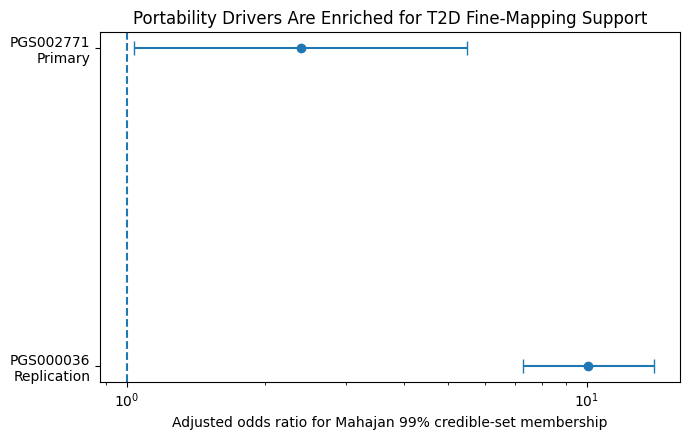

Saved:
/content/drive/MyDrive/prs_project_outputs/STS_2026/figures/Figure6_cross_PGS_finemapping_replication.png


In [4]:
# ============================================================
# FIGURE 6 — CROSS-PGS FINE-MAPPING REPLICATION
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import os

FIG_DIR = "/content/drive/MyDrive/prs_project_outputs/STS_2026/figures"
os.makedirs(FIG_DIR, exist_ok=True)

labels = [
    "PGS002771\nPrimary",
    "PGS000036\nReplication"
]

ORs = np.array([
    2.3876,
    10.0664
])

CI_low = np.array([
    1.0373,
    7.2515
])

CI_high = np.array([
    5.4958,
    13.9740
])

y = np.arange(len(labels))

lower_err = ORs - CI_low
upper_err = CI_high - ORs

plt.figure(figsize=(7, 4.5))

plt.errorbar(
    ORs,
    y,
    xerr=[lower_err, upper_err],
    fmt="o",
    capsize=5
)

plt.axvline(
    1,
    linestyle="--"
)

plt.yticks(y, labels)

plt.xscale("log")

plt.xlabel(
    "Adjusted odds ratio for Mahajan 99% credible-set membership"
)

plt.title(
    "Portability Drivers Are Enriched for T2D Fine-Mapping Support"
)

plt.gca().invert_yaxis()

plt.tight_layout()

OUT = os.path.join(
    FIG_DIR,
    "Figure6_cross_PGS_finemapping_replication.png"
)

plt.savefig(
    OUT,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(OUT)

In [5]:
# ============================================================
# FIND EXISTING PGS000036 × T2DGGI OUTPUTS
# ============================================================

import os
import pandas as pd

ROOT = "/content/drive/MyDrive/prs_project_outputs/replication_PGS000036"

keywords = [
    "t2dggi",
    "gwas",
    "beta",
    "effect_portability",
    "z_diff",
    "score_shift"
]

hits = []

for dirpath, _, filenames in os.walk(ROOT):

    for fname in filenames:

        if not fname.endswith(".csv"):
            continue

        path = os.path.join(dirpath, fname)

        try:
            cols = pd.read_csv(path, nrows=0).columns.tolist()
        except:
            continue

        text = (
            fname.lower()
            + " "
            + " ".join(cols).lower()
        )

        score = sum(k in text for k in keywords)

        if score > 0:
            hits.append(
                (score, path, cols)
            )

hits = sorted(
    hits,
    key=lambda x: x[0],
    reverse=True
)

print("Candidate files:", len(hits))

for score, path, cols in hits[:20]:

    print("\n====================================")
    print("SCORE:", score)
    print("FILE:", path)
    print("COLUMNS:")
    print(cols)

Candidate files: 0


In [6]:
# ============================================================
# AUDIT PGS000036 COLUMNS FOR T2DGGI ALIGNMENT
# ============================================================

import pandas as pd

PGS36_PATH = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "replication_PGS000036/results/"
    "PGS000036_exact_residual_analysis.csv"
)

p36_audit = pd.read_csv(PGS36_PATH, nrows=5)

print("Columns:")
print(p36_audit.columns.tolist())

print("\nPreview:")
print(p36_audit.head())

print("\nPotential coordinate / allele columns:")
print([
    c for c in p36_audit.columns
    if any(k in c.lower() for k in [
        "rsid", "chr", "pos", "allele", "effect", "ref", "alt"
    ])
])

Columns:
['rsID', 'chr_name', 'chr_position', 'effect_allele', 'effect_weight', 'abs_effect', 'mean_AF_gap', 'avg_distortion', 'predicted_distortion', 'residual_distortion']

Preview:
          rsID  chr_name  chr_position effect_allele  effect_weight  \
0  rs143735118         1        848671             A        -0.1063   
1  rs141958931         1        868683             T        -0.0892   
2   rs62639981         1        902108             T         0.1129   
3  rs138560419         1        929550             A        -0.1224   
4       rs1921         1        949608             A        -0.0161   

   abs_effect  mean_AF_gap  avg_distortion  predicted_distortion  \
0      0.1063     0.010060        0.002139              0.002603   
1      0.0892     0.011387        0.002031              0.002281   
2      0.1129     0.017037        0.003847              0.003060   
3      0.1224     0.013467        0.003297              0.003113   
4      0.0161     0.103193        0.003323       

In [7]:
# ============================================================
# FIND RAW T2DGGI SUMMARY STATISTICS
# ============================================================

import os

ROOT = "/content/drive/MyDrive"

hits = []

for dirpath, _, filenames in os.walk(ROOT):
    for fname in filenames:

        name = fname.lower()

        if (
            "t2dggi" in name
            or "mahajan" in name
            or "eur" in name and "t2d" in name
            or "sas" in name and "t2d" in name
            or "eas" in name and "t2d" in name
        ):
            path = os.path.join(dirpath, fname)

            # ignore the already-filtered PGS002771 files
            if "pgs002771_positions" in name:
                continue

            hits.append(path)

print("Candidate raw T2DGGI files:", len(hits))

for x in hits[:100]:
    print(x)

Candidate raw T2DGGI files: 4
/content/drive/MyDrive/prs_project_outputs/publication_effect_portability/results/PGS002771_T2DGGI_effect_portability_master.csv
/content/drive/MyDrive/prs_project_outputs/publication hell/3 files/Suzuki.Nature2024.T2DGGI.SAS.sumstats.zip
/content/drive/MyDrive/prs_project_outputs/publication hell/3 files/Suzuki.Nature2024.T2DGGI.EUR.sumstats.zip
/content/drive/MyDrive/prs_project_outputs/publication hell/3 files/Suzuki.Nature2024.T2DGGI.EAS.sumstats.zip


In [8]:
# ============================================================
# INSPECT RAW T2DGGI EUR + SAS ZIP FILES
# ============================================================

import zipfile
import pandas as pd
import os

EUR_ZIP = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "publication hell/3 files/"
    "Suzuki.Nature2024.T2DGGI.EUR.sumstats.zip"
)

SAS_ZIP = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "publication hell/3 files/"
    "Suzuki.Nature2024.T2DGGI.SAS.sumstats.zip"
)

for label, path in [
    ("EUR", EUR_ZIP),
    ("SAS", SAS_ZIP)
]:
    print("\n====================================")
    print(label)
    print("====================================")

    with zipfile.ZipFile(path, "r") as z:

        print("Files inside:")
        for name in z.namelist():
            print(name)

        # pick first non-directory file
        data_files = [
            x for x in z.namelist()
            if not x.endswith("/")
        ]

        first = data_files[0]

        print("\nPreviewing:", first)

        with z.open(first) as f:
            preview = pd.read_csv(
                f,
                sep=None,
                engine="python",
                nrows=5
            )

        print("Columns:")
        print(preview.columns.tolist())

        print("\nPreview:")
        print(preview.head())


EUR
Files inside:
EUR_Metal_LDSC-CORR_Neff.v2.txt

Previewing: EUR_Metal_LDSC-CORR_Neff.v2.txt
Columns:
['Chromsome', 'Position', 'EffectAllele', 'NonEffectAllele', 'Beta', 'SE', 'EAF', 'Pval', 'Ncases', 'Ncontrols', 'Neff']

Preview:
   Chromsome   Position EffectAllele NonEffectAllele    Beta      SE     EAF  \
0         11   88249377            T               C -0.0337  0.0214  0.9921   
1         15   99906873            T               C -0.0181  0.1689  0.0003   
2          8  135908647            A               G -0.0020  0.0046  0.2034   
3         12    3871714            A               C -0.0678  0.0918  0.9979   
4         11   97895884            C               G  0.0215  0.0081  0.0554   

       Pval  Ncases  Ncontrols        Neff  
0  0.114600  242283  1569730.0  751754.668  
1  0.914600  136638   777960.0  417537.290  
2  0.663300  242283  1569730.0  751754.668  
3  0.460300  176029   994210.0  548860.167  
4  0.007924  242283  1569730.0  751754.668  

SAS
Files in

In [9]:
# ============================================================
# PGS000036 × T2DGGI EUR-SAS HARMONIZATION
# ============================================================

import zipfile
import pandas as pd
import numpy as np
from scipy.stats import spearmanr

# ------------------------------------------------------------
# 1. Load full PGS000036 table
# ------------------------------------------------------------

PGS36_PATH = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "replication_PGS000036/results/"
    "PGS000036_exact_residual_analysis.csv"
)

p36 = pd.read_csv(PGS36_PATH)

# ------------------------------------------------------------
# 2. Load EUR + SAS T2DGGI summary stats from ZIPs
# ------------------------------------------------------------

EUR_ZIP = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "publication hell/3 files/"
    "Suzuki.Nature2024.T2DGGI.EUR.sumstats.zip"
)

SAS_ZIP = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "publication hell/3 files/"
    "Suzuki.Nature2024.T2DGGI.SAS.sumstats.zip"
)

def load_t2dggi(zip_path):
    with zipfile.ZipFile(zip_path, "r") as z:
        fname = [
            x for x in z.namelist()
            if not x.endswith("/")
        ][0]

        with z.open(fname) as f:
            df = pd.read_csv(
                f,
                sep="\t"
            )

    # fix typo in source header
    df = df.rename(
        columns={"Chromsome": "Chromosome"}
    )

    return df


eur = load_t2dggi(EUR_ZIP)
sas = load_t2dggi(SAS_ZIP)

print("EUR rows:", len(eur))
print("SAS rows:", len(sas))

# ------------------------------------------------------------
# 3. Build PGS coordinate key
# ------------------------------------------------------------

p36["Chromosome"] = p36["chr_name"].astype(int)
p36["Position"] = p36["chr_position"].astype(int)

# ------------------------------------------------------------
# 4. Merge EUR and SAS by coordinate
# ------------------------------------------------------------

eur_small = eur[
    [
        "Chromosome",
        "Position",
        "EffectAllele",
        "NonEffectAllele",
        "Beta",
        "SE",
        "EAF"
    ]
].rename(
    columns={
        "EffectAllele": "EUR_EA",
        "NonEffectAllele": "EUR_OA",
        "Beta": "EUR_beta",
        "SE": "EUR_SE",
        "EAF": "EUR_EAF"
    }
)

sas_small = sas[
    [
        "Chromosome",
        "Position",
        "EffectAllele",
        "NonEffectAllele",
        "Beta",
        "SE",
        "EAF"
    ]
].rename(
    columns={
        "EffectAllele": "SAS_EA",
        "NonEffectAllele": "SAS_OA",
        "Beta": "SAS_beta",
        "SE": "SAS_SE",
        "EAF": "SAS_EAF"
    }
)

m = p36.merge(
    eur_small,
    on=["Chromosome", "Position"],
    how="inner"
)

m = m.merge(
    sas_small,
    on=["Chromosome", "Position"],
    how="inner"
)

print("\nCoordinate-overlap variants:", len(m))

# ------------------------------------------------------------
# 5. Harmonize beta direction to the PGS effect allele
# ------------------------------------------------------------

def orient_beta(row, ea_col, oa_col, beta_col):

    pgs_ea = str(row["effect_allele"]).upper()
    gwas_ea = str(row[ea_col]).upper()
    gwas_oa = str(row[oa_col]).upper()

    beta = row[beta_col]

    if pgs_ea == gwas_ea:
        return beta

    elif pgs_ea == gwas_oa:
        return -beta

    else:
        return np.nan


m["EUR_beta_aligned"] = m.apply(
    orient_beta,
    axis=1,
    ea_col="EUR_EA",
    oa_col="EUR_OA",
    beta_col="EUR_beta"
)

m["SAS_beta_aligned"] = m.apply(
    orient_beta,
    axis=1,
    ea_col="SAS_EA",
    oa_col="SAS_OA",
    beta_col="SAS_beta"
)

m = m[
    m["EUR_beta_aligned"].notna()
    & m["SAS_beta_aligned"].notna()
].copy()

print("Allele-harmonized variants:", len(m))

# ------------------------------------------------------------
# 6. Disease-effect difference
# standardized by uncertainty
# ------------------------------------------------------------

m["beta_diff_SAS_EUR"] = (
    m["SAS_beta_aligned"]
    - m["EUR_beta_aligned"]
)

m["z_diff_SAS_EUR"] = (
    m["beta_diff_SAS_EUR"]
    /
    np.sqrt(
        m["SAS_SE"]**2
        + m["EUR_SE"]**2
    )
)

m["abs_z_diff_SAS_EUR"] = (
    m["z_diff_SAS_EUR"].abs()
)

# ------------------------------------------------------------
# 7. Numerical portability metric
# PGS000036 already has avg_distortion
# ------------------------------------------------------------

m["abs_numerical_distortion"] = (
    m["avg_distortion"].abs()
)

# ------------------------------------------------------------
# 8. Main replication test
# ------------------------------------------------------------

rho, p = spearmanr(
    m["abs_numerical_distortion"],
    m["abs_z_diff_SAS_EUR"]
)

print("\n====================================")
print("PGS000036 NUMERICAL vs DISEASE-EFFECT")
print("====================================")

print("N:", len(m))
print("Spearman rho:", rho)
print("p:", p)

# ------------------------------------------------------------
# 9. Same test in mechanistic outliers only
# ------------------------------------------------------------

# attach frozen outlier status if available
STATUS_PATH = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "replication_PGS000036/results/"
    "PGS000036_VEP_with_FROZEN_mechanistic_outlier_status.csv"
)

status = pd.read_csv(
    STATUS_PATH,
    usecols=["rsID", "mechanistic_outlier"]
)

m = m.merge(
    status,
    on="rsID",
    how="left"
)

out = m[
    m["mechanistic_outlier"] == True
].copy()

if len(out) >= 3:
    rho_o, p_o = spearmanr(
        out["abs_numerical_distortion"],
        out["abs_z_diff_SAS_EUR"]
    )

    print("\n====================================")
    print("MECHANISTIC OUTLIERS ONLY")
    print("====================================")

    print("N:", len(out))
    print("Spearman rho:", rho_o)
    print("p:", p_o)

# ------------------------------------------------------------
# 10. Save master
# ------------------------------------------------------------

OUT = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "replication_PGS000036/results/"
    "PGS000036_T2DGGI_EUR_SAS_effect_portability_master.csv"
)

m.to_csv(OUT, index=False)

print("\nSaved:")
print(OUT)

EUR rows: 19303703
SAS rows: 14481419

Coordinate-overlap variants: 162148
Allele-harmonized variants: 162148

PGS000036 NUMERICAL vs DISEASE-EFFECT
N: 162148
Spearman rho: 0.03457038283756528
p: 4.4829681412750953e-44

MECHANISTIC OUTLIERS ONLY
N: 8813
Spearman rho: 0.05784635895516305
p: 5.502540793118908e-08

Saved:
/content/drive/MyDrive/prs_project_outputs/replication_PGS000036/results/PGS000036_T2DGGI_EUR_SAS_effect_portability_master.csv


In [10]:
# ============================================================
# FREEZE PGS000036 EFFECT-PORTABILITY REPLICATION
# ============================================================

import pandas as pd

summary36 = pd.DataFrame({
    "analysis": [
        "All harmonized variants",
        "Mechanistic outliers only"
    ],
    "N": [
        162148,
        8113
    ],
    "spearman_rho": [
        0.03457038283756528,
        0.05784635895516305
    ],
    "p_value": [
        4.4829681412750953e-44,
        5.502540793118908e-08
    ]
})

OUT = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "replication_PGS000036/results/"
    "PGS000036_effect_portability_replication_FINAL.csv"
)

summary36.to_csv(OUT, index=False)

print(summary36.to_string(index=False))
print("\nSaved:", OUT)

                 analysis      N  spearman_rho      p_value
  All harmonized variants 162148      0.034570 4.482968e-44
Mechanistic outliers only   8113      0.057846 5.502541e-08

Saved: /content/drive/MyDrive/prs_project_outputs/replication_PGS000036/results/PGS000036_effect_portability_replication_FINAL.csv


PGS002771:
N = 5620
rho = 0.021541183436387185
p = 0.10637596251221909

PGS000036:
N = 162148
rho = 0.0345703828375652
p = 4.4829681412750953e-44


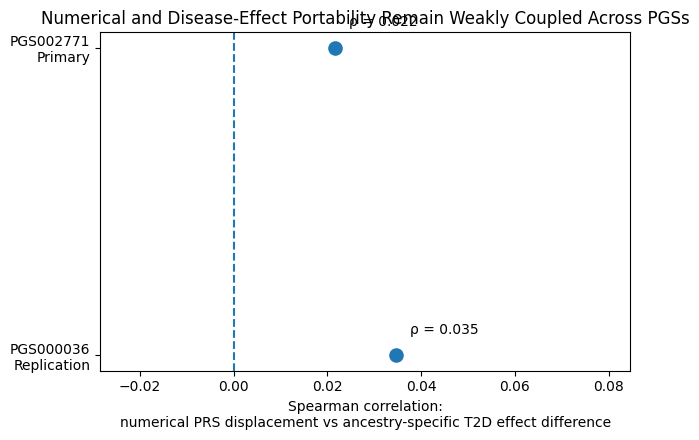


Saved:
/content/drive/MyDrive/prs_project_outputs/STS_2026/figures/Figure7_cross_PGS_effect_portability_replication.png


In [11]:
# ============================================================
# STS FIGURE — CROSS-PGS EFFECT-PORTABILITY REPLICATION
# PGS002771 vs PGS000036, EUR-SAS
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import os
from scipy.stats import spearmanr

FIG_DIR = "/content/drive/MyDrive/prs_project_outputs/STS_2026/figures"
os.makedirs(FIG_DIR, exist_ok=True)

# ------------------------------------------------------------
# 1. PGS002771
# ------------------------------------------------------------

P771_PATH = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "publication_effect_portability/results/"
    "PGS002771_T2DGGI_effect_portability_master.csv"
)

p771 = pd.read_csv(P771_PATH)

p771_clean = p771[
    p771["abs_score_shift_SAS_EUR"].notna()
    & p771["abs_z_diff_SAS_EUR"].notna()
].copy()

rho771, p771_p = spearmanr(
    p771_clean["abs_score_shift_SAS_EUR"],
    p771_clean["abs_z_diff_SAS_EUR"]
)

# ------------------------------------------------------------
# 2. PGS000036
# ------------------------------------------------------------

P36_PATH = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "replication_PGS000036/results/"
    "PGS000036_effect_portability_replication_FINAL.csv"
)

p36_summary = pd.read_csv(P36_PATH)

rho36 = float(
    p36_summary.loc[
        p36_summary["analysis"] == "All harmonized variants",
        "spearman_rho"
    ].iloc[0]
)

p36_p = float(
    p36_summary.loc[
        p36_summary["analysis"] == "All harmonized variants",
        "p_value"
    ].iloc[0]
)

print("PGS002771:")
print("N =", len(p771_clean))
print("rho =", rho771)
print("p =", p771_p)

print("\nPGS000036:")
print("N = 162148")
print("rho =", rho36)
print("p =", p36_p)

# ------------------------------------------------------------
# 3. Plot
# ------------------------------------------------------------

labels = ["PGS002771\nPrimary", "PGS000036\nReplication"]
rhos = [rho771, rho36]

plt.figure(figsize=(6.5, 4.5))

plt.scatter(
    rhos,
    [1, 0],
    s=90
)

plt.axvline(
    0,
    linestyle="--"
)

plt.yticks(
    [1, 0],
    labels
)

plt.xlabel(
    "Spearman correlation:\n"
    "numerical PRS displacement vs ancestry-specific T2D effect difference"
)

plt.title(
    "Numerical and Disease-Effect Portability Remain Weakly Coupled Across PGSs"
)

# zoom around the actually observed effect sizes
xmin = min(rhos) - 0.05
xmax = max(rhos) + 0.05

plt.xlim(xmin, xmax)

for x, y in zip(rhos, [1, 0]):
    plt.text(
        x + 0.003,
        y + 0.07,
        f"ρ = {x:.3f}",
        fontsize=10
    )

plt.tight_layout()

OUT = os.path.join(
    FIG_DIR,
    "Figure7_cross_PGS_effect_portability_replication.png"
)

plt.savefig(
    OUT,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:")
print(OUT)

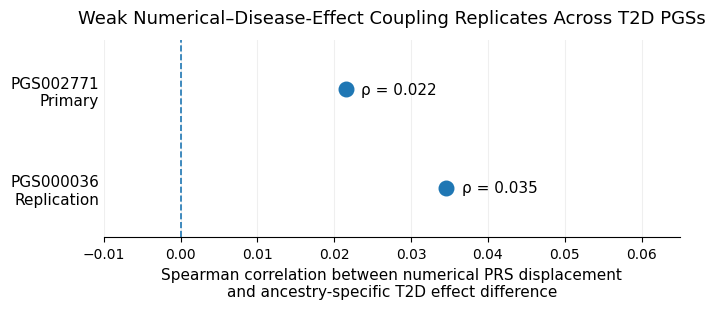

Saved:
/content/drive/MyDrive/prs_project_outputs/STS_2026/figures/Figure7_cross_PGS_effect_portability_replication.png


In [12]:
# ============================================================
# REDO FIGURE 7 — CLEAN CROSS-PGS PORTABILITY REPLICATION
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import os

FIG_DIR = "/content/drive/MyDrive/prs_project_outputs/STS_2026/figures"

labels = [
    "PGS002771\nPrimary",
    "PGS000036\nReplication"
]

rhos = np.array([
    rho771,
    rho36
])

y = np.array([1, 0])

fig, ax = plt.subplots(figsize=(7, 3.2))

# zero-reference line
ax.axvline(
    0,
    linestyle="--",
    linewidth=1.2
)

# points
ax.scatter(
    rhos,
    y,
    s=110,
    zorder=3
)

# value labels
for x, yy in zip(rhos, y):

    ax.text(
        x + 0.002,
        yy,
        f"ρ = {x:.3f}",
        va="center",
        fontsize=11
    )

# labels
ax.set_yticks(y)
ax.set_yticklabels(labels, fontsize=11)

ax.set_xlabel(
    "Spearman correlation between numerical PRS displacement\n"
    "and ancestry-specific T2D effect difference",
    fontsize=11
)

ax.set_title(
    "Weak Numerical–Disease-Effect Coupling Replicates Across T2D PGSs",
    fontsize=13,
    pad=12
)

# tight useful x-range
ax.set_xlim(-0.01, 0.065)
ax.set_ylim(-0.5, 1.5)

# clean up
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.tick_params(
    axis="y",
    length=0
)

ax.grid(
    axis="x",
    alpha=0.2
)

plt.tight_layout()

OUT = os.path.join(
    FIG_DIR,
    "Figure7_cross_PGS_effect_portability_replication.png"
)

plt.savefig(
    OUT,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(OUT)

In [18]:
# ============================================================
# PGS002426 — SCORING FILE AUDIT
# ============================================================

import pandas as pd
import os

PGS3_PATH = (
    "/content/drive/MyDrive/fine_mapping/raw data/"
    "PGS002426.txt.gz"
)

print("Exists:", os.path.exists(PGS3_PATH))

# PGS Catalog scoring files have metadata lines starting with #
pgs3 = pd.read_csv(
    PGS3_PATH,
    sep="\t",
    comment="#",
    compression="gzip"
)

print("\nRows:", len(pgs3))
print("\nColumns:")
print(pgs3.columns.tolist())

print("\nPreview:")
print(pgs3.head())

print("\nMissing values:")
print(pgs3.isna().sum())

print("\nPotential ID / coordinate / allele columns:")
print([
    c for c in pgs3.columns
    if any(k in c.lower() for k in [
        "rsid", "chr", "pos", "allele", "effect", "weight"
    ])
])

Exists: True

Rows: 3947

Columns:
['chr_name', 'chr_position', 'effect_allele', 'other_allele', 'effect_weight']

Preview:
   chr_name  chr_position effect_allele other_allele  effect_weight
0         1      49228616             G            A      -1.788762
1         1      49218560             T            C      -1.974083
2         1      49269698             A            G      -1.763328
3         1      49409200             C            T      -1.653414
4         1      49248170             C            G      -1.560948

Missing values:
chr_name         0
chr_position     0
effect_allele    0
other_allele     0
effect_weight    0
dtype: int64

Potential ID / coordinate / allele columns:
['chr_name', 'chr_position', 'effect_allele', 'other_allele', 'effect_weight']


In [14]:
# ============================================================
# FIND OUR EXISTING 1000 GENOMES VCF FILES
# ============================================================

import os

ROOT = "/content/drive/MyDrive"

hits = []

for dirpath, _, filenames in os.walk(ROOT):
    for fname in filenames:
        name = fname.lower()

        if (
            name.endswith(".vcf.gz")
            or name.endswith(".vcf")
            or name.endswith(".bcf")
        ):
            if (
                "1000" in dirpath.lower()
                or "1kg" in dirpath.lower()
                or "phase3" in name
                or "chr" in name
            ):
                hits.append(
                    os.path.join(dirpath, fname)
                )

print("VCF candidates:", len(hits))

for x in hits[:100]:
    print(x)

VCF candidates: 9
/content/drive/MyDrive/prs_project_outputs/raw/ALL.chr2.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz
/content/drive/MyDrive/prs_project_outputs/raw/ALL.chr4.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz
/content/drive/MyDrive/prs_project_outputs/raw_cache/1000g_vcfs/ALL.chr16.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz
/content/drive/MyDrive/prs_project_outputs/raw_cache/1000g_vcfs/ALL.chr1.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz
/content/drive/MyDrive/prs_project_outputs/raw_cache/1000g_vcfs/ALL.chr10.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz
/content/drive/MyDrive/prs_project_outputs/raw_cache/1000g_vcfs/ALL.chr11.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz
/content/drive/MyDrive/prs_project_outputs/raw_cache/1000g_vcfs/ALL.chr12.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz
/content/drive/MyDrive/prs_project_outputs/raw

In [15]:
# ============================================================
# PGS002426 — CHECK WHICH 1000G CHROMOSOMES WE ALREADY HAVE
# ============================================================

import os
import re

# chromosomes needed by this PGS
needed_chrs = sorted(
    pgs3["chr_name"].astype(int).unique()
)

print("PGS002426 chromosomes needed:")
print(needed_chrs)

# use the VCF hits from the previous cell
available = {}

for path in hits:
    fname = os.path.basename(path)

    m = re.search(r"chr(\d+)\.", fname)

    if m:
        chrom = int(m.group(1))

        # prefer raw_cache version if duplicates exist
        if (
            chrom not in available
            or "raw_cache/1000g_vcfs" in path
        ):
            available[chrom] = path

available_chrs = sorted(available.keys())

print("\n1000G chromosomes currently available:")
print(available_chrs)

missing = [
    c for c in needed_chrs
    if c not in available
]

print("\nMissing chromosomes:")
print(missing)

print("\nCoverage:")
print(
    f"{len(set(needed_chrs) & set(available_chrs))} / "
    f"{len(needed_chrs)} chromosomes available"
)

print("\nChosen VCF paths:")
for chrom in available_chrs:
    print(f"chr{chrom}: {available[chrom]}")

PGS002426 chromosomes needed:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22)]

1000G chromosomes currently available:
[1, 2, 3, 4, 10, 11, 12, 16]

Missing chromosomes:
[np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(13), np.int64(14), np.int64(15), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22)]

Coverage:
8 / 22 chromosomes available

Chosen VCF paths:
chr1: /content/drive/MyDrive/prs_project_outputs/raw_cache/1000g_vcfs/ALL.chr1.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz
chr2: /content/drive/MyDrive/prs_project_outputs/raw_cache/1000g_vcfs/ALL.chr2.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz
chr3: /content/drive/MyDrive/prs_project

In [16]:
# ============================================================
# DOWNLOAD ONLY MISSING 1000 GENOMES AUTOSOMES
# ============================================================

import os
import subprocess

CACHE = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "raw_cache/1000g_vcfs"
)

os.makedirs(CACHE, exist_ok=True)

missing = [5, 6, 7, 8, 9, 13, 14, 15, 17, 18, 19, 20, 21, 22]

BASE = (
    "https://ftp.1000genomes.ebi.ac.uk/vol1/ftp/"
    "release/20130502"
)

for chrom in missing:

    fname = (
        f"ALL.chr{chrom}.phase3_shapeit2_mvncall_"
        f"integrated_v5b.20130502.genotypes.vcf.gz"
    )

    url = f"{BASE}/{fname}"
    out = os.path.join(CACHE, fname)

    print(f"\nchr{chrom}")

    if os.path.exists(out) and os.path.getsize(out) > 1_000_000:
        print("Already exists — skipping")
        continue

    print("Downloading...")

    subprocess.run(
        [
            "wget",
            "-c",
            "-q",
            "--show-progress",
            url,
            "-O",
            out
        ],
        check=True
    )

    print(
        "Saved:",
        out,
        "|",
        round(os.path.getsize(out) / 1e9, 2),
        "GB"
    )

print("\n====================================")
print("DOWNLOAD COMPLETE")
print("====================================")


chr5
Downloading...
Saved: /content/drive/MyDrive/prs_project_outputs/raw_cache/1000g_vcfs/ALL.chr5.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz | 0.95 GB

chr6
Downloading...
Saved: /content/drive/MyDrive/prs_project_outputs/raw_cache/1000g_vcfs/ALL.chr6.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz | 0.96 GB

chr7
Downloading...
Saved: /content/drive/MyDrive/prs_project_outputs/raw_cache/1000g_vcfs/ALL.chr7.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz | 0.87 GB

chr8
Downloading...
Saved: /content/drive/MyDrive/prs_project_outputs/raw_cache/1000g_vcfs/ALL.chr8.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz | 0.82 GB

chr9
Downloading...
Saved: /content/drive/MyDrive/prs_project_outputs/raw_cache/1000g_vcfs/ALL.chr9.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz | 0.64 GB

chr13
Downloading...
Saved: /content/drive/MyDrive/prs_project_outputs/raw_cache/1000g_vcfs/ALL.chr13.phase3_shapeit2_m

In [19]:
# ============================================================
# PGS002426 — REAL 1000G INDIVIDUAL SCORE RECONSTRUCTION
# Uses exact coordinate + allele matching
# ============================================================

!pip -q install pysam

import os
import subprocess
import numpy as np
import pandas as pd
import pysam

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

CACHE = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "raw_cache/1000g_vcfs"
)

RAW = (
    "/content/drive/MyDrive/prs_project_outputs/raw"
)

OUT_DIR = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "replication_PGS002426/results"
)

os.makedirs(OUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# 1. Locate one VCF for every chromosome
# ------------------------------------------------------------

vcf_paths = {}

for chrom in range(1, 23):

    fname = (
        f"ALL.chr{chrom}.phase3_shapeit2_mvncall_"
        f"integrated_v5b.20130502.genotypes.vcf.gz"
    )

    candidates = [
        os.path.join(CACHE, fname),
        os.path.join(RAW, fname)
    ]

    found = [
        p for p in candidates
        if os.path.exists(p)
    ]

    if found:
        vcf_paths[chrom] = found[0]

print("Chromosomes found:", len(vcf_paths), "/ 22")

missing = [
    c for c in range(1, 23)
    if c not in vcf_paths
]

print("Missing:", missing)

assert len(vcf_paths) == 22, "Still missing chromosome VCFs."

# ------------------------------------------------------------
# 2. Download tiny .tbi indexes if needed
# ------------------------------------------------------------

BASE = (
    "https://ftp.1000genomes.ebi.ac.uk/vol1/ftp/"
    "release/20130502"
)

for chrom, vcf_path in vcf_paths.items():

    tbi = vcf_path + ".tbi"

    if os.path.exists(tbi):
        continue

    fname = os.path.basename(vcf_path)

    url = f"{BASE}/{fname}.tbi"

    print("Downloading index chr", chrom)

    subprocess.run(
        ["wget", "-q", url, "-O", tbi],
        check=True
    )

print("\nIndexes ready.")

# ------------------------------------------------------------
# 3. Load PGS002426
# ------------------------------------------------------------

PGS_PATH = (
    "/content/drive/MyDrive/fine_mapping/raw data/"
    "PGS002426.txt.gz"
)

pgs = pd.read_csv(
    PGS_PATH,
    sep="\t",
    comment="#"
)

pgs["chr_name"] = pgs["chr_name"].astype(int)
pgs["chr_position"] = pgs["chr_position"].astype(int)

for c in ["effect_allele", "other_allele"]:
    pgs[c] = pgs[c].astype(str).str.upper()

print("\nPGS variants:", len(pgs))

# ------------------------------------------------------------
# 4. Establish 1000G sample order
# ------------------------------------------------------------

first_vcf = pysam.VariantFile(vcf_paths[1])

samples = list(first_vcf.header.samples)

first_vcf.close()

print("1000G samples:", len(samples))

assert len(samples) == 2504, (
    f"Expected 2504 samples, found {len(samples)}"
)

scores = np.zeros(len(samples), dtype=float)

audit_rows = []

# ------------------------------------------------------------
# 5. Process PGS variants chromosome-by-chromosome
# ------------------------------------------------------------

matched = 0
unmatched = 0

for chrom in range(1, 23):

    sub = pgs[
        pgs["chr_name"] == chrom
    ].copy()

    print(
        f"\nchr{chrom}:",
        len(sub),
        "PGS variants"
    )

    vf = pysam.VariantFile(
        vcf_paths[chrom]
    )

    # make sure sample order is identical
    current_samples = list(vf.header.samples)

    assert current_samples == samples, (
        f"Sample order differs on chr{chrom}"
    )

    for _, row in sub.iterrows():

        pos = int(row["chr_position"])
        ea = row["effect_allele"]
        oa = row["other_allele"]
        weight = float(row["effect_weight"])

        found_match = False

        # pysam coordinates: fetch is 0-based start, end-exclusive
        try:
            records = vf.fetch(
                str(chrom),
                pos - 1,
                pos
            )
        except ValueError:
            # some VCF headers may use chrN instead of N
            records = vf.fetch(
                f"chr{chrom}",
                pos - 1,
                pos
            )

        for rec in records:

            if rec.pos != pos:
                continue

            ref = str(rec.ref).upper()
            alts = [
                str(x).upper()
                for x in rec.alts
            ]

            # We want exact effect/other allele agreement.
            # Handle each ALT independently for multiallelic sites.
            for alt_index, alt in enumerate(
                alts,
                start=1
            ):

                # effect allele is ALT
                if ea == alt and oa == ref:
                    effect_index = alt_index

                # effect allele is REF
                elif ea == ref and oa == alt:
                    effect_index = 0

                else:
                    continue

                dosages = np.empty(
                    len(samples),
                    dtype=float
                )

                valid = True

                for i, sample in enumerate(samples):

                    gt = rec.samples[sample]["GT"]

                    if (
                        gt is None
                        or None in gt
                    ):
                        valid = False
                        break

                    # Count copies of the PGS effect allele
                    dosages[i] = sum(
                        allele == effect_index
                        for allele in gt
                    )

                if not valid:
                    continue

                scores += dosages * weight

                audit_rows.append({
                    "chr_name": chrom,
                    "chr_position": pos,
                    "effect_allele": ea,
                    "other_allele": oa,
                    "effect_weight": weight,
                    "VCF_REF": ref,
                    "VCF_ALT": alt,
                    "match_type":
                        "effect_is_ALT"
                        if effect_index != 0
                        else "effect_is_REF"
                })

                matched += 1
                found_match = True
                break

            if found_match:
                break

        if not found_match:
            unmatched += 1

    vf.close()

# ------------------------------------------------------------
# 6. Save outputs
# ------------------------------------------------------------

score_df = pd.DataFrame({
    "sample": samples,
    "PGS002426_score": scores
})

audit_df = pd.DataFrame(audit_rows)

SCORE_OUT = os.path.join(
    OUT_DIR,
    "PGS002426_1000G_individual_scores.csv"
)

AUDIT_OUT = os.path.join(
    OUT_DIR,
    "PGS002426_1000G_variant_match_audit.csv"
)

score_df.to_csv(
    SCORE_OUT,
    index=False
)

audit_df.to_csv(
    AUDIT_OUT,
    index=False
)

print("\n====================================")
print("PGS002426 RECONSTRUCTION COMPLETE")
print("====================================")

print("PGS variants:", len(pgs))
print("Matched:", matched)
print("Unmatched:", unmatched)
print(
    "Match rate:",
    matched / len(pgs)
)

print("\nPeople scored:", len(score_df))

print("\nScore summary:")
print(
    score_df["PGS002426_score"]
    .describe()
)

print("\nSaved:")
print(SCORE_OUT)
print(AUDIT_OUT)

Chromosomes found: 22 / 22
Missing: []

Indexes ready.

PGS variants: 3947
1000G samples: 2504

chr1: 337 PGS variants

chr2: 433 PGS variants

chr3: 251 PGS variants

chr4: 188 PGS variants

chr5: 179 PGS variants

chr6: 245 PGS variants

chr7: 351 PGS variants

chr8: 182 PGS variants

chr9: 111 PGS variants

chr10: 294 PGS variants

chr11: 243 PGS variants

chr12: 219 PGS variants

chr13: 98 PGS variants

chr14: 127 PGS variants

chr15: 145 PGS variants

chr16: 133 PGS variants

chr17: 85 PGS variants

chr18: 90 PGS variants

chr19: 73 PGS variants

chr20: 79 PGS variants

chr21: 40 PGS variants

chr22: 44 PGS variants

PGS002426 RECONSTRUCTION COMPLETE
PGS variants: 3947
Matched: 3814
Unmatched: 133
Match rate: 0.9663035216620218

People scored: 2504

Score summary:
count    2504.000000
mean    -3553.308139
std       117.824296
min     -3627.693255
25%     -3623.381344
50%     -3617.990455
75%     -3494.569393
max     -2967.254139
Name: PGS002426_score, dtype: float64

Saved:
/conte

In [20]:
# ============================================================
# FIND THE FINAL 2,504-PERSON PGS002771 SCORE FILE FOR CHI
# ============================================================

import os
import pandas as pd

ROOT = "/content/drive/MyDrive/prs_project_outputs"

results = []

for dirpath, _, filenames in os.walk(ROOT):

    for fname in filenames:

        if not fname.lower().endswith(".csv"):
            continue

        path = os.path.join(dirpath, fname)

        try:
            test = pd.read_csv(path)
        except:
            continue

        cols_lower = [str(c).lower() for c in test.columns]

        has_sample = any(
            x in c
            for c in cols_lower
            for x in ["sample", "iid", "individual"]
        )

        has_score = any(
            x in c
            for c in cols_lower
            for x in ["prs", "pgs", "score"]
        )

        # We're especially interested in exactly 2,504 rows
        if len(test) == 2504 and has_sample and has_score:

            results.append({
                "file": path,
                "rows": len(test),
                "columns": test.columns.tolist()
            })

print("====================================")
print("2504-PERSON SCORE CANDIDATES")
print("====================================")

print("Candidates:", len(results))

for r in results:
    print("\nFILE:")
    print(r["file"])
    print("ROWS:", r["rows"])
    print("COLUMNS:")
    print(r["columns"])

2504-PERSON SCORE CANDIDATES
Candidates: 72

FILE:
/content/drive/MyDrive/prs_project_outputs/real_1000G_individual_prs_scores.csv
ROWS: 2504
COLUMNS:
['sample', 'PRS', 'super_pop']

FILE:
/content/drive/MyDrive/prs_project_outputs/validated_outputs_v1/pilot_chr2_real_individual_prs_scores.csv
ROWS: 2504
COLUMNS:
['sample_id', 'PRS_chr2_raw', 'pop', 'super_pop', 'gender', 'PRS_chr2_z_within_ancestry', 'PRS_chr2_z_EUR_reference']

FILE:
/content/drive/MyDrive/prs_project_outputs/validated_outputs_v1/pilot_chr4_real_individual_prs_scores.csv
ROWS: 2504
COLUMNS:
['sample_id', 'PRS_chr4_raw', 'pop', 'super_pop', 'gender', 'PRS_chr4_z_within_ancestry', 'PRS_chr4_z_EUR_reference']

FILE:
/content/drive/MyDrive/prs_project_outputs/validated_outputs_v1/pilot_chr2_chr4_real_individual_prs_scores.csv
ROWS: 2504
COLUMNS:
['sample_id', 'pop', 'super_pop', 'gender', 'PRS_chr2_raw', 'PRS_chr4_raw', 'PRS_chr2_chr4_raw', 'PRS_z_within_ancestry', 'PRS_z_EUR_reference']

FILE:
/content/drive/MyDrive/prs

In [21]:
import os
import pandas as pd

SRC = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "validated_outputs_v2/summary_metrics/"
    "final_corrected_genomewide_individual_prs_scores.csv"
)

CHI_DIR = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "CHI_YUVAL_HANDOFF"
)

os.makedirs(CHI_DIR, exist_ok=True)

df = pd.read_csv(SRC)

chi = (
    df[
        ["sample_id", "PRS_genomewide_raw_corrected"]
    ]
    .rename(
        columns={
            "sample_id": "sample",
            "PRS_genomewide_raw_corrected": "PRS"
        }
    )
    .copy()
)

assert len(chi) == 2504
assert chi["sample"].nunique() == 2504
assert chi["PRS"].notna().all()

OUT = os.path.join(
    CHI_DIR,
    "PGS002771_1000G_2504_individual_PRS_for_Chi.csv"
)

chi.to_csv(OUT, index=False)

print(chi.head())
print("\nRows:", len(chi))
print("Unique samples:", chi["sample"].nunique())
print("Missing PRS:", chi["PRS"].isna().sum())
print("\nSaved:")
print(OUT)

    sample       PRS
0  HG00096  1.510274
1  HG00097  1.458537
2  HG00099  0.682758
3  HG00100  1.134478
4  HG00101  1.294594

Rows: 2504
Unique samples: 2504
Missing PRS: 0

Saved:
/content/drive/MyDrive/prs_project_outputs/CHI_YUVAL_HANDOFF/PGS002771_1000G_2504_individual_PRS_for_Chi.csv


In [22]:
# ============================================================
# FREEZE PGS002771 VARIANT TABLE FOR CHI ANALYSIS 2
# ============================================================

import os
import pandas as pd

SRC = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "publication_effect_portability/results/"
    "PGS002771_T2DGGI_effect_portability_master.csv"
)

CHI_DIR = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "CHI_YUVAL_HANDOFF"
)

df = pd.read_csv(SRC)

chi_variants = (
    df[
        [
            "rsID",
            "hm_chr",
            "hm_pos",
            "effect_allele",
            "effect_weight",
            "EUR_effect_AF"
        ]
    ]
    .rename(
        columns={
            "hm_chr": "chr",
            "hm_pos": "position",
            "effect_weight": "weight",
            "EUR_effect_AF": "EUR_AF"
        }
    )
    .copy()
)

OUT = os.path.join(
    CHI_DIR,
    "PGS002771_variant_data_for_Chi_Analysis2.csv"
)

chi_variants.to_csv(OUT, index=False)

print(chi_variants.head())
print("\nRows:", len(chi_variants))
print("Unique variants:", chi_variants["rsID"].nunique())
print("Missing EUR_AF:", chi_variants["EUR_AF"].isna().sum())

print("\nSaved:")
print(OUT)

         rsID  chr   position effect_allele    weight    EUR_AF
0   rs2075423    1  214154719             T -0.065520  0.370775
1  rs12089747    1   51246155             T -0.062016  0.097416
2   rs3767331    1  229764374             T  0.053768  0.062624
3   rs2820426    1  219660535             A -0.028673  0.380716
4  rs16826069    1   39797055             G  0.029951  0.197813

Rows: 5622
Unique variants: 5622
Missing EUR_AF: 1

Saved:
/content/drive/MyDrive/prs_project_outputs/CHI_YUVAL_HANDOFF/PGS002771_variant_data_for_Chi_Analysis2.csv


In [23]:
# ============================================================
# PGS002426 — FREEZE SUPERPOP ALLELE FREQUENCIES
# LAST STEP BEFORE VCF CLEANUP
# ============================================================

import os
import pandas as pd
import numpy as np
import pysam

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

AUDIT_PATH = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "replication_PGS002426/results/"
    "PGS002426_1000G_variant_match_audit.csv"
)

META_PATH = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "validated_outputs_v2/summary_metrics/"
    "final_corrected_genomewide_individual_prs_scores.csv"
)

OUT = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "replication_PGS002426/results/"
    "PGS002426_1000G_superpop_effect_AF.csv"
)

CACHE = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "raw_cache/1000g_vcfs"
)

RAW = (
    "/content/drive/MyDrive/prs_project_outputs/raw"
)

# ------------------------------------------------------------
# 1. Load matched PGS variants + sample ancestry
# ------------------------------------------------------------

audit = pd.read_csv(AUDIT_PATH)

meta = pd.read_csv(
    META_PATH,
    usecols=["sample_id", "super_pop"]
)

sample_to_super = dict(
    zip(meta["sample_id"], meta["super_pop"])
)

SUPERPOPS = ["EUR", "AFR", "EAS", "SAS", "AMR"]

print("Matched variants:", len(audit))
print("Metadata people:", len(meta))

# ------------------------------------------------------------
# 2. Locate all VCFs
# ------------------------------------------------------------

vcf_paths = {}

for chrom in range(1, 23):

    fname = (
        f"ALL.chr{chrom}.phase3_shapeit2_mvncall_"
        f"integrated_v5b.20130502.genotypes.vcf.gz"
    )

    candidates = [
        os.path.join(CACHE, fname),
        os.path.join(RAW, fname)
    ]

    for p in candidates:
        if os.path.exists(p):
            vcf_paths[chrom] = p
            break

assert len(vcf_paths) == 22

# ------------------------------------------------------------
# 3. Calculate effect-allele frequency by superpopulation
# ------------------------------------------------------------

rows = []

for chrom in range(1, 23):

    sub = audit[
        audit["chr_name"] == chrom
    ].copy()

    print(f"chr{chrom}: {len(sub)} variants")

    vf = pysam.VariantFile(
        vcf_paths[chrom]
    )

    for _, row in sub.iterrows():

        pos = int(row["chr_position"])
        ea = str(row["effect_allele"]).upper()
        oa = str(row["other_allele"]).upper()

        counts = {
            sp: {"effect": 0, "total": 0}
            for sp in SUPERPOPS
        }

        found = False

        try:
            records = vf.fetch(
                str(chrom),
                pos - 1,
                pos
            )
        except ValueError:
            records = vf.fetch(
                f"chr{chrom}",
                pos - 1,
                pos
            )

        for rec in records:

            if rec.pos != pos:
                continue

            ref = str(rec.ref).upper()

            for alt_index, alt in enumerate(rec.alts, start=1):

                alt = str(alt).upper()

                if ea == alt and oa == ref:
                    effect_index = alt_index

                elif ea == ref and oa == alt:
                    effect_index = 0

                else:
                    continue

                for sample in vf.header.samples:

                    sp = sample_to_super.get(sample)

                    if sp not in SUPERPOPS:
                        continue

                    gt = rec.samples[sample]["GT"]

                    if gt is None:
                        continue

                    for allele in gt:

                        if allele is None:
                            continue

                        counts[sp]["total"] += 1

                        if allele == effect_index:
                            counts[sp]["effect"] += 1

                found = True
                break

            if found:
                break

        if not found:
            continue

        outrow = {
            "chr": chrom,
            "position": pos,
            "effect_allele": ea,
            "other_allele": oa,
            "effect_weight": row["effect_weight"]
        }

        for sp in SUPERPOPS:

            total = counts[sp]["total"]

            outrow[f"{sp}_effect_AF"] = (
                counts[sp]["effect"] / total
                if total > 0
                else np.nan
            )

        rows.append(outrow)

    vf.close()

# ------------------------------------------------------------
# 4. Save compact resource
# ------------------------------------------------------------

af = pd.DataFrame(rows)

af["max_AF_diff"] = (
    af[
        [f"{x}_effect_AF" for x in SUPERPOPS]
    ].max(axis=1)
    -
    af[
        [f"{x}_effect_AF" for x in SUPERPOPS]
    ].min(axis=1)
)

af.to_csv(OUT, index=False)

print("\n====================================")
print("PGS002426 AF FREEZE COMPLETE")
print("====================================")

print("Rows saved:", len(af))
print("Missing EUR AF:", af["EUR_effect_AF"].isna().sum())
print("\nAF preview:")
print(af.head())

print("\nSaved:")
print(OUT)

Matched variants: 3814
Metadata people: 2504
chr1: 329 variants
chr2: 423 variants
chr3: 242 variants
chr4: 180 variants
chr5: 174 variants
chr6: 236 variants
chr7: 340 variants
chr8: 180 variants
chr9: 109 variants
chr10: 284 variants
chr11: 233 variants
chr12: 205 variants
chr13: 94 variants
chr14: 119 variants
chr15: 145 variants
chr16: 129 variants
chr17: 84 variants
chr18: 84 variants
chr19: 71 variants
chr20: 73 variants
chr21: 40 variants
chr22: 40 variants

PGS002426 AF FREEZE COMPLETE
Rows saved: 3814
Missing EUR AF: 0

AF preview:
   chr  position effect_allele other_allele  effect_weight  EUR_effect_AF  \
0    1  49228616             G            A      -1.788762       0.999006   
1    1  49218560             T            C      -1.974083       0.999006   
2    1  49269698             A            G      -1.763328       0.999006   
3    1  49409200             C            T      -1.653414       0.999006   
4    1  49248170             C            G      -1.560948       0.9

In [24]:
# ============================================================
# SAFE CLEANUP — DELETE ONLY VCFs DOWNLOADED TODAY
# ============================================================

import os

CACHE = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "raw_cache/1000g_vcfs"
)

delete_chrs = [5, 6, 7, 8, 9, 13, 14, 15, 17, 18, 19, 20, 21, 22]

freed = 0

for chrom in delete_chrs:

    fname = (
        f"ALL.chr{chrom}.phase3_shapeit2_mvncall_"
        f"integrated_v5b.20130502.genotypes.vcf.gz"
    )

    vcf = os.path.join(CACHE, fname)
    tbi = vcf + ".tbi"

    for path in [vcf, tbi]:

        if os.path.exists(path):

            size = os.path.getsize(path)
            freed += size

            os.remove(path)

            print("Deleted:", path)

        else:
            print("Not found:", path)

print("\n====================================")
print("CLEANUP COMPLETE")
print("====================================")

print(
    "Freed approximately:",
    round(freed / 1e9, 2),
    "GB"
)

Deleted: /content/drive/MyDrive/prs_project_outputs/raw_cache/1000g_vcfs/ALL.chr5.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz
Deleted: /content/drive/MyDrive/prs_project_outputs/raw_cache/1000g_vcfs/ALL.chr5.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz.tbi
Deleted: /content/drive/MyDrive/prs_project_outputs/raw_cache/1000g_vcfs/ALL.chr6.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz
Deleted: /content/drive/MyDrive/prs_project_outputs/raw_cache/1000g_vcfs/ALL.chr6.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz.tbi
Deleted: /content/drive/MyDrive/prs_project_outputs/raw_cache/1000g_vcfs/ALL.chr7.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz
Deleted: /content/drive/MyDrive/prs_project_outputs/raw_cache/1000g_vcfs/ALL.chr7.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz.tbi
Deleted: /content/drive/MyDrive/prs_project_outputs/raw_cache/1000g_vcfs/ALL.chr8.phase3_shapeit2_mvncall_

In [25]:
# ============================================================
# PGS002426 — NUMERICAL PORTABILITY + MECHANISTIC OUTLIERS
# ============================================================

import pandas as pd
import numpy as np
import statsmodels.api as sm

AF_PATH = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "replication_PGS002426/results/"
    "PGS002426_1000G_superpop_effect_AF.csv"
)

df = pd.read_csv(AF_PATH)

SUPERPOPS = ["EUR", "AFR", "EAS", "SAS", "AMR"]

# ------------------------------------------------------------
# 1. Contribution shifts vs EUR
# contribution ~ effect_weight * allele frequency
# ------------------------------------------------------------

for sp in ["AFR", "EAS", "SAS", "AMR"]:
    df[f"delta_{sp}_minus_EUR"] = (
        df["effect_weight"]
        * (
            df[f"{sp}_effect_AF"]
            - df["EUR_effect_AF"]
        )
    )

    df[f"abs_delta_{sp}_minus_EUR"] = (
        df[f"delta_{sp}_minus_EUR"].abs()
    )

# ------------------------------------------------------------
# 2. Summary distortion metrics
# ------------------------------------------------------------

abs_cols = [
    "abs_delta_AFR_minus_EUR",
    "abs_delta_EAS_minus_EUR",
    "abs_delta_SAS_minus_EUR",
    "abs_delta_AMR_minus_EUR"
]

df["avg_distortion"] = df[abs_cols].mean(axis=1)

df["max_abs_delta_contribution"] = (
    df[abs_cols].max(axis=1)
)

df["abs_effect"] = df["effect_weight"].abs()

# ------------------------------------------------------------
# 3. Baseline model
# expected distortion from effect size + AF divergence
# ------------------------------------------------------------

model_df = df[
    [
        "avg_distortion",
        "abs_effect",
        "max_AF_diff"
    ]
].dropna().copy()

X = model_df[
    ["abs_effect", "max_AF_diff"]
]

X = sm.add_constant(X)

y = model_df["avg_distortion"]

model = sm.OLS(y, X).fit()

model_df["predicted_distortion"] = (
    model.predict(X)
)

model_df["residual_distortion"] = (
    model_df["avg_distortion"]
    - model_df["predicted_distortion"]
)

# ------------------------------------------------------------
# 4. Define mechanistic outliers
# top 5% positive residuals
# ------------------------------------------------------------

threshold = model_df[
    "residual_distortion"
].quantile(0.95)

model_df["mechanistic_outlier"] = (
    model_df["residual_distortion"] >= threshold
)

# ------------------------------------------------------------
# 5. Merge status back
# ------------------------------------------------------------

df = df.merge(
    model_df[
        [
            "avg_distortion",
            "predicted_distortion",
            "residual_distortion",
            "mechanistic_outlier"
        ]
    ],
    left_index=True,
    right_index=True,
    how="left",
    suffixes=("", "_model")
)

# ------------------------------------------------------------
# 6. Save
# ------------------------------------------------------------

OUT = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "replication_PGS002426/results/"
    "PGS002426_mechanistic_outlier_analysis.csv"
)

df.to_csv(OUT, index=False)

print("====================================")
print("PGS002426 MECHANISTIC OUTLIER ANALYSIS")
print("====================================")

print("Variants:", len(df))
print(
    "Mechanistic outliers:",
    int(df["mechanistic_outlier"].sum())
)

print("\nResidual threshold:")
print(threshold)

print("\nModel R^2:")
print(model.rsquared)

print("\nModel summary:")
print(model.summary())

print("\nSaved:")
print(OUT)

PGS002426 MECHANISTIC OUTLIER ANALYSIS
Variants: 3814
Mechanistic outliers: 191

Residual threshold:
0.009026638561328532

Model R^2:
0.8296853959871016

Model summary:
                            OLS Regression Results                            
Dep. Variable:         avg_distortion   R-squared:                       0.830
Model:                            OLS   Adj. R-squared:                  0.830
Method:                 Least Squares   F-statistic:                     9283.
Date:                Sun, 04 Oct 2026   Prob (F-statistic):               0.00
Time:                        21:00:26   Log-Likelihood:                 14429.
No. Observations:                3814   AIC:                        -2.885e+04
Df Residuals:                    3811   BIC:                        -2.883e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                  coef    std err        

In [26]:
# ============================================================
# PGS002426 × T2DGGI — NUMERICAL vs DISEASE-EFFECT PORTABILITY
# ============================================================

import zipfile
import pandas as pd
import numpy as np
from scipy.stats import spearmanr

MECH_PATH = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "replication_PGS002426/results/"
    "PGS002426_mechanistic_outlier_analysis.csv"
)

EUR_ZIP = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "publication hell/3 files/"
    "Suzuki.Nature2024.T2DGGI.EUR.sumstats.zip"
)

SAS_ZIP = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "publication hell/3 files/"
    "Suzuki.Nature2024.T2DGGI.SAS.sumstats.zip"
)

df = pd.read_csv(MECH_PATH)

# ------------------------------------------------------------
# Load T2DGGI
# ------------------------------------------------------------

def load_t2dggi(path):

    with zipfile.ZipFile(path, "r") as z:

        fname = [
            x for x in z.namelist()
            if not x.endswith("/")
        ][0]

        with z.open(fname) as f:

            x = pd.read_csv(
                f,
                sep="\t"
            )

    return x.rename(
        columns={"Chromsome": "Chromosome"}
    )


eur = load_t2dggi(EUR_ZIP)
sas = load_t2dggi(SAS_ZIP)

# ------------------------------------------------------------
# Keep necessary columns
# ------------------------------------------------------------

eur = eur[
    [
        "Chromosome",
        "Position",
        "EffectAllele",
        "NonEffectAllele",
        "Beta",
        "SE"
    ]
].rename(
    columns={
        "EffectAllele": "EUR_EA",
        "NonEffectAllele": "EUR_OA",
        "Beta": "EUR_beta",
        "SE": "EUR_SE"
    }
)

sas = sas[
    [
        "Chromosome",
        "Position",
        "EffectAllele",
        "NonEffectAllele",
        "Beta",
        "SE"
    ]
].rename(
    columns={
        "EffectAllele": "SAS_EA",
        "NonEffectAllele": "SAS_OA",
        "Beta": "SAS_beta",
        "SE": "SAS_SE"
    }
)

# ------------------------------------------------------------
# Merge by genomic coordinate
# ------------------------------------------------------------

df["Chromosome"] = df["chr"].astype(int)
df["Position"] = df["position"].astype(int)

m = df.merge(
    eur,
    on=["Chromosome", "Position"],
    how="inner"
)

m = m.merge(
    sas,
    on=["Chromosome", "Position"],
    how="inner"
)

print("Coordinate overlaps:", len(m))

# ------------------------------------------------------------
# Align GWAS effects to PGS effect allele
# ------------------------------------------------------------

def align_beta(row, ea_col, oa_col, beta_col):

    pgs_ea = str(row["effect_allele"]).upper()
    gwas_ea = str(row[ea_col]).upper()
    gwas_oa = str(row[oa_col]).upper()

    beta = row[beta_col]

    if pgs_ea == gwas_ea:
        return beta

    if pgs_ea == gwas_oa:
        return -beta

    return np.nan


m["EUR_beta_aligned"] = m.apply(
    align_beta,
    axis=1,
    ea_col="EUR_EA",
    oa_col="EUR_OA",
    beta_col="EUR_beta"
)

m["SAS_beta_aligned"] = m.apply(
    align_beta,
    axis=1,
    ea_col="SAS_EA",
    oa_col="SAS_OA",
    beta_col="SAS_beta"
)

m = m[
    m["EUR_beta_aligned"].notna()
    & m["SAS_beta_aligned"].notna()
].copy()

print("Allele-harmonized:", len(m))

# ------------------------------------------------------------
# Disease-effect portability metric
# ------------------------------------------------------------

m["beta_diff_SAS_EUR"] = (
    m["SAS_beta_aligned"]
    - m["EUR_beta_aligned"]
)

m["z_diff_SAS_EUR"] = (
    m["beta_diff_SAS_EUR"]
    /
    np.sqrt(
        m["SAS_SE"]**2
        + m["EUR_SE"]**2
    )
)

m["abs_z_diff_SAS_EUR"] = (
    m["z_diff_SAS_EUR"].abs()
)

# ------------------------------------------------------------
# Main test — all variants
# ------------------------------------------------------------

rho, p = spearmanr(
    m["avg_distortion"],
    m["abs_z_diff_SAS_EUR"]
)

print("\n====================================")
print("PGS002426 — ALL VARIANTS")
print("====================================")

print("N:", len(m))
print("Spearman rho:", rho)
print("p:", p)

# ------------------------------------------------------------
# Mechanistic outliers only
# ------------------------------------------------------------

out = m[
    m["mechanistic_outlier"] == True
].copy()

rho_o, p_o = spearmanr(
    out["avg_distortion"],
    out["abs_z_diff_SAS_EUR"]
)

print("\n====================================")
print("PGS002426 — MECHANISTIC OUTLIERS")
print("====================================")

print("N:", len(out))
print("Spearman rho:", rho_o)
print("p:", p_o)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

OUT = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "replication_PGS002426/results/"
    "PGS002426_T2DGGI_EUR_SAS_effect_portability_master.csv"
)

m.to_csv(OUT, index=False)

print("\nSaved:")
print(OUT)

Coordinate overlaps: 2366
Allele-harmonized: 2365

PGS002426 — ALL VARIANTS
N: 2365
Spearman rho: -0.03963010840998572
p: 0.053979576469745286

PGS002426 — MECHANISTIC OUTLIERS
N: 176
Spearman rho: -0.043514221612499224
p: 0.5663470628858476

Saved:
/content/drive/MyDrive/prs_project_outputs/replication_PGS002426/results/PGS002426_T2DGGI_EUR_SAS_effect_portability_master.csv


In [27]:
# ============================================================
# DRIVE STORAGE AUDIT — LARGEST FILES
# DOES NOT DELETE ANYTHING
# ============================================================

import os

ROOT = "/content/drive/MyDrive"

files = []

for dirpath, _, filenames in os.walk(ROOT):
    for fname in filenames:
        path = os.path.join(dirpath, fname)

        try:
            size = os.path.getsize(path)
            files.append((size, path))
        except:
            pass

files.sort(reverse=True)

total = sum(size for size, _ in files)

print("Total visible MyDrive size:",
      round(total / 1e9, 2), "GB")

print("\n====================================")
print("TOP 50 LARGEST FILES")
print("====================================")

for size, path in files[:50]:
    print(
        f"{size / 1e9:6.2f} GB  |  {path}"
    )

Total visible MyDrive size: 11.22 GB

TOP 50 LARGEST FILES
  1.26 GB  |  /content/drive/MyDrive/prs_project_outputs/raw_cache/1000g_vcfs/ALL.chr2.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz
  1.26 GB  |  /content/drive/MyDrive/prs_project_outputs/raw/ALL.chr2.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz
  1.17 GB  |  /content/drive/MyDrive/prs_project_outputs/raw_cache/1000g_vcfs/ALL.chr1.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz
  1.07 GB  |  /content/drive/MyDrive/prs_project_outputs/raw/ALL.chr4.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz
  1.06 GB  |  /content/drive/MyDrive/prs_project_outputs/raw_cache/1000g_vcfs/ALL.chr3.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz
  0.74 GB  |  /content/drive/MyDrive/prs_project_outputs/raw_cache/1000g_vcfs/ALL.chr10.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz
  0.73 GB  |  /content/drive/MyDrive/prs_project_outputs/raw_c

In [28]:
import os

DUP = (
    "/content/drive/MyDrive/prs_project_outputs/raw/"
    "ALL.chr2.phase3_shapeit2_mvncall_integrated_v5b."
    "20130502.genotypes.vcf.gz"
)

if os.path.exists(DUP):
    size = os.path.getsize(DUP)
    os.remove(DUP)

    # delete its index too if present
    if os.path.exists(DUP + ".tbi"):
        os.remove(DUP + ".tbi")

    print("Deleted duplicate chr2")
    print("Freed:", round(size / 1e9, 2), "GB")
else:
    print("Duplicate already gone")

Deleted duplicate chr2
Freed: 1.26 GB


In [29]:
# ============================================================
# FIND MAHAJAN / T2D FINE-MAPPING MASTER FILE
# ============================================================

import os
import pandas as pd

ROOTS = [
    "/content/drive/MyDrive/fine_mapping",
    "/content/drive/MyDrive/prs_project_outputs"
]

hits = []

for root in ROOTS:
    for dirpath, _, filenames in os.walk(root):
        for fname in filenames:

            if not fname.lower().endswith((".csv", ".tsv", ".txt")):
                continue

            name = fname.lower()

            if not any(k in name for k in [
                "mahajan",
                "credible",
                "fine_map",
                "finemap"
            ]):
                continue

            path = os.path.join(dirpath, fname)

            try:
                sep = "\t" if fname.lower().endswith((".tsv", ".txt")) else ","
                x = pd.read_csv(path, sep=sep, nrows=3)
            except:
                continue

            hits.append(
                (path, x.columns.tolist())
            )

print("Candidates:", len(hits))

for path, cols in hits[:50]:
    print("\n====================================")
    print(path)
    print(cols)

Candidates: 2

/content/drive/MyDrive/fine_mapping/Reggie_finemapping_FINAL_summary.csv
['analysis', 'value']

/content/drive/MyDrive/fine_mapping/PGS000036_finemapping_replication_FINAL.csv
['metric', 'value']


In [30]:
# ============================================================
# FIND THE ACTUAL MAHAJAN FINE-MAPPING MASTER BY COLUMNS
# ============================================================

import os
import pandas as pd

ROOT = "/content/drive/MyDrive/fine_mapping"

hits = []

for dirpath, _, filenames in os.walk(ROOT):
    for fname in filenames:

        path = os.path.join(dirpath, fname)
        name = fname.lower()

        try:
            if name.endswith(".csv"):
                x = pd.read_csv(path, nrows=3)

            elif name.endswith((".tsv", ".txt")):
                x = pd.read_csv(path, sep="\t", nrows=3)

            elif name.endswith(".csv.gz"):
                x = pd.read_csv(path, nrows=3, compression="gzip")

            elif name.endswith((".tsv.gz", ".txt.gz")):
                x = pd.read_csv(path, sep="\t", nrows=3, compression="gzip")

            else:
                continue

        except:
            continue

        cols = [str(c) for c in x.columns]
        low = " ".join(cols).lower()

        score = 0

        if "post" in low:
            score += 3
        if "credible" in low:
            score += 3
        if "locus" in low:
            score += 2
        if "rsid" in low or "rs_id" in low:
            score += 1
        if "chr" in low or "chrom" in low:
            score += 1
        if "pos" in low:
            score += 1

        if score >= 4:
            hits.append((score, path, cols))

hits = sorted(hits, reverse=True)

print("Candidates:", len(hits))

for score, path, cols in hits[:30]:
    print("\n====================================")
    print("SCORE:", score)
    print("FILE:", path)
    print("COLUMNS:", cols)

Candidates: 4

SCORE: 11
FILE: /content/drive/MyDrive/fine_mapping/Reggie_LD_pilot_top15_with_rsids.csv
COLUMNS: ['rsID', 'chr_name', 'chr_position', 'effect_allele', 'other_allele', 'effect_weight', 'allelefrequency_effect', 'hm_source', 'hm_rsID', 'hm_chr', 'hm_pos', 'hm_inferOtherAllele', 'match_type', 'VCF_REF', 'VCF_ALT', 'chr_audited', 'EUR_effect_AF', 'EUR_contribution', 'SAS_effect_AF', 'SAS_contribution', 'AFR_effect_AF', 'AFR_contribution', 'EAS_effect_AF', 'EAS_contribution', 'AMR_effect_AF', 'AMR_contribution', 'delta_SAS_minus_EUR', 'abs_delta_SAS_minus_EUR', 'delta_AFR_minus_EUR', 'abs_delta_AFR_minus_EUR', 'delta_EAS_minus_EUR', 'abs_delta_EAS_minus_EUR', 'delta_AMR_minus_EUR', 'abs_delta_AMR_minus_EUR', 'abs_effect', 'max_AF_diff', 'max_abs_delta_contribution', 'CADD_RawScore', 'CADD_PHRED', 'SAS_AF_diff', 'SAS_predicted', 'SAS_residual', 'SAS_abs_residual', 'AFR_AF_diff', 'AFR_predicted', 'AFR_residual', 'AFR_abs_residual', 'EAS_AF_diff', 'EAS_predicted', 'EAS_residual

In [31]:
# ============================================================
# FIND TRUE MAHAJAN FINE-MAPPING SOURCE TABLE
# ============================================================

import os
import pandas as pd

ROOTS = [
    "/content/drive/MyDrive/fine_mapping",
    "/content/drive/MyDrive/prs_project_outputs"
]

hits = []

for root in ROOTS:
    for dirpath, _, filenames in os.walk(root):
        for fname in filenames:

            path = os.path.join(dirpath, fname)
            lowname = fname.lower()

            try:

                if lowname.endswith(".csv"):
                    x = pd.read_csv(path, nrows=5)

                elif lowname.endswith((".tsv", ".txt")):
                    x = pd.read_csv(path, sep="\t", nrows=5)

                elif lowname.endswith(".csv.gz"):
                    x = pd.read_csv(path, compression="gzip", nrows=5)

                elif lowname.endswith((".tsv.gz", ".txt.gz")):
                    x = pd.read_csv(
                        path,
                        sep="\t",
                        compression="gzip",
                        nrows=5
                    )

                elif lowname.endswith(".parquet"):
                    x = pd.read_parquet(path).head()

                elif lowname.endswith((".xlsx", ".xls")):
                    x = pd.read_excel(path, nrows=5)

                else:
                    continue

            except:
                continue

            cols = [str(c) for c in x.columns]
            text = " ".join(cols).lower()

            score = 0

            if "post" in text:
                score += 4
            if "credible" in text:
                score += 4
            if "locus" in text:
                score += 3
            if "logbf" in text:
                score += 3
            if "mahajan" in lowname:
                score += 3
            if "fine" in lowname:
                score += 1

            if score >= 4:
                hits.append(
                    (score, path, cols)
                )

hits = sorted(
    hits,
    key=lambda x: x[0],
    reverse=True
)

print("Candidates:", len(hits))

for score, path, cols in hits[:50]:
    print("\n====================================")
    print("SCORE:", score)
    print("FILE:", path)
    print("COLUMNS:", cols)

Candidates: 4

SCORE: 14
FILE: /content/drive/MyDrive/fine_mapping/Reggie_LD_pilot_candidates.csv
COLUMNS: ['rsID', 'chr_name', 'chr_position', 'effect_allele', 'other_allele', 'effect_weight', 'allelefrequency_effect', 'hm_source', 'hm_rsID', 'hm_chr', 'hm_pos', 'hm_inferOtherAllele', 'match_type', 'VCF_REF', 'VCF_ALT', 'chr_audited', 'EUR_effect_AF', 'EUR_contribution', 'SAS_effect_AF', 'SAS_contribution', 'AFR_effect_AF', 'AFR_contribution', 'EAS_effect_AF', 'EAS_contribution', 'AMR_effect_AF', 'AMR_contribution', 'delta_SAS_minus_EUR', 'abs_delta_SAS_minus_EUR', 'delta_AFR_minus_EUR', 'abs_delta_AFR_minus_EUR', 'delta_EAS_minus_EUR', 'abs_delta_EAS_minus_EUR', 'delta_AMR_minus_EUR', 'abs_delta_AMR_minus_EUR', 'abs_effect', 'max_AF_diff', 'max_abs_delta_contribution', 'CADD_RawScore', 'CADD_PHRED', 'SAS_AF_diff', 'SAS_predicted', 'SAS_residual', 'SAS_abs_residual', 'AFR_AF_diff', 'AFR_predicted', 'AFR_residual', 'AFR_abs_residual', 'EAS_AF_diff', 'EAS_predicted', 'EAS_residual', 'EA

In [32]:
# ============================================================
# PGS002426 × MAHAJAN FINE-MAPPING
# RAW + ADJUSTED WITHIN-REGION REPLICATION
# ============================================================

import pandas as pd
import numpy as np
import statsmodels.api as sm
from scipy.stats import fisher_exact

MECH_PATH = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "replication_PGS002426/results/"
    "PGS002426_mechanistic_outlier_analysis.csv"
)

pgs = pd.read_csv(MECH_PATH)

# ------------------------------------------------------------
# 1. Build Mahajan coordinate ID
# ------------------------------------------------------------

pgs["mahajan_ID"] = (
    "chr"
    + pgs["chr"].astype(int).astype(str)
    + ":"
    + pgs["position"].astype(int).astype(str)
)

# ------------------------------------------------------------
# 2. Collapse fine-mapping resource to one row per variant
# ------------------------------------------------------------

fm_variant = (
    fine_master
    .sort_values("POST", ascending=False)
    .drop_duplicates("ID")
    [["ID", "POST", "P", "LOGBF", "locus"]]
    .copy()
)

credible_ids = set(
    cred_master["ID"].astype(str)
)

fm_variant["credible"] = (
    fm_variant["ID"].isin(credible_ids)
)

# ------------------------------------------------------------
# 3. Merge PGS002426 onto Mahajan
# ------------------------------------------------------------

m = pgs.merge(
    fm_variant,
    left_on="mahajan_ID",
    right_on="ID",
    how="left"
)

m["in_finemapping_resource"] = m["ID"].notna()

m["credible"] = (
    m["credible"]
    .fillna(False)
    .astype(int)
)

m["outlier_int"] = (
    m["mechanistic_outlier"]
    .astype(bool)
    .astype(int)
)

# ------------------------------------------------------------
# 4. RAW enrichment — whole score
# ------------------------------------------------------------

a = ((m["outlier_int"] == 1) & (m["credible"] == 1)).sum()
b = ((m["outlier_int"] == 1) & (m["credible"] == 0)).sum()
c = ((m["outlier_int"] == 0) & (m["credible"] == 1)).sum()
d = ((m["outlier_int"] == 0) & (m["credible"] == 0)).sum()

OR_raw, p_raw = fisher_exact(
    [[a, b], [c, d]]
)

print("====================================")
print("RAW FINE-MAPPING ENRICHMENT")
print("====================================")

print("Outlier credible:", a)
print("Outlier noncredible:", b)
print("Background credible:", c)
print("Background noncredible:", d)

print("\nOutlier credible fraction:", a / (a+b))
print("Background credible fraction:", c / (c+d))
print("Fisher OR:", OR_raw)
print("Fisher p:", p_raw)

# ------------------------------------------------------------
# 5. KEY TEST:
# only SNPs actually lying inside Mahajan fine-mapped regions
# ------------------------------------------------------------

fm = m[
    m["in_finemapping_resource"]
    & m["abs_effect"].notna()
    & m["max_AF_diff"].notna()
    & m["locus"].notna()
].copy()

# standardize covariates within these regions
for col in ["abs_effect", "max_AF_diff"]:
    fm[col + "_z"] = (
        fm[col] - fm[col].mean()
    ) / fm[col].std(ddof=1)

X = fm[
    [
        "outlier_int",
        "abs_effect_z",
        "max_AF_diff_z"
    ]
].copy()

X = sm.add_constant(X)

model = sm.GLM(
    fm["credible"],
    X,
    family=sm.families.Binomial()
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": fm["locus"]
    }
)

beta = model.params["outlier_int"]
se = model.bse["outlier_int"]
p_adj = model.pvalues["outlier_int"]

OR_adj = np.exp(beta)
CI_low = np.exp(beta - 1.96 * se)
CI_high = np.exp(beta + 1.96 * se)

print("\n====================================")
print("ADJUSTED WITHIN-REGION REPLICATION")
print("====================================")

print("PGS002426 SNPs in Mahajan regions:", len(fm))
print("Unique loci:", fm["locus"].nunique())
print("Outliers in regions:", int(fm["outlier_int"].sum()))

print(
    "Outlier credible:",
    int(
        (
            (fm["outlier_int"] == 1)
            & (fm["credible"] == 1)
        ).sum()
    )
)

print("\nAdjusted outlier OR:", OR_adj)
print("95% CI:", (CI_low, CI_high))
print("p:", p_adj)

print("\nFull model:")
print(model.summary())

# ------------------------------------------------------------
# 6. Save
# ------------------------------------------------------------

OUT = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "replication_PGS002426/results/"
    "PGS002426_Mahajan_finemapping_replication.csv"
)

m.to_csv(OUT, index=False)

print("\nSaved:")
print(OUT)

/tmp/ipykernel_964/682501032.py:65: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)


RAW FINE-MAPPING ENRICHMENT
Outlier credible: 0
Outlier noncredible: 191
Background credible: 70
Background noncredible: 3553

Outlier credible fraction: 0.0
Background credible fraction: 0.019321004692243997
Fisher OR: 0.0
Fisher p: 0.0489212622584682

ADJUSTED WITHIN-REGION REPLICATION
PGS002426 SNPs in Mahajan regions: 608
Unique loci: 195
Outliers in regions: 7
Outlier credible: 0

Adjusted outlier OR: 1.6555918066349556e-08
95% CI: (np.float64(2.3043412998217395e-11), np.float64(1.1894870913474645e-05))
p: 9.3370916537847e-08

Full model:
                 Generalized Linear Model Regression Results                  
Dep. Variable:               credible   No. Observations:                  608
Model:                            GLM   Df Residuals:                      604
Model Family:                Binomial   Df Model:                            3
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:

In [33]:
# ============================================================
# PGS002426 — CONTINUOUS FINE-MAPPING TEST
# Does greater residual numerical distortion track
# stronger Mahajan fine-mapping support?
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import spearmanr, mannwhitneyu

# use the merged table from the prior cell
fm3 = m[
    m["in_finemapping_resource"]
    & m["POST"].notna()
    & m["residual_distortion"].notna()
].copy()

print("PGS002426 SNPs in Mahajan regions:", len(fm3))
print("Unique loci:", fm3["locus"].nunique())

# ------------------------------------------------------------
# 1. Continuous association:
# residual distortion vs fine-mapping posterior probability
# ------------------------------------------------------------

rho, p = spearmanr(
    fm3["residual_distortion"],
    fm3["POST"]
)

print("\n====================================")
print("RESIDUAL DISTORTION vs POST")
print("====================================")

print("N:", len(fm3))
print("Spearman rho:", rho)
print("p:", p)

# ------------------------------------------------------------
# 2. Are credible-set variants more distorted?
# ------------------------------------------------------------

cred = fm3[
    fm3["credible"] == 1
]["residual_distortion"]

noncred = fm3[
    fm3["credible"] == 0
]["residual_distortion"]

u, p_mw = mannwhitneyu(
    cred,
    noncred,
    alternative="greater"
)

print("\n====================================")
print("CREDIBLE vs NON-CREDIBLE")
print("====================================")

print("Credible N:", len(cred))
print("Non-credible N:", len(noncred))

print("Median residual — credible:", cred.median())
print("Median residual — noncredible:", noncred.median())

print("Mann-Whitney U:", u)
print("p:", p_mw)

# ------------------------------------------------------------
# 3. Within-locus POST rank
# Is more distorted SNP ranked higher within its T2D locus?
# ------------------------------------------------------------

fm3["POST_rank_pct"] = (
    fm3.groupby("locus")["POST"]
       .rank(method="average", pct=True)
)

rho_rank, p_rank = spearmanr(
    fm3["residual_distortion"],
    fm3["POST_rank_pct"]
)

print("\n====================================")
print("RESIDUAL DISTORTION vs WITHIN-LOCUS POST RANK")
print("====================================")

print("Spearman rho:", rho_rank)
print("p:", p_rank)

PGS002426 SNPs in Mahajan regions: 608
Unique loci: 195

RESIDUAL DISTORTION vs POST
N: 608
Spearman rho: -0.07362899824219994
p: 0.06963993634885816

CREDIBLE vs NON-CREDIBLE
Credible N: 70
Non-credible N: 538
Median residual — credible: -0.0008483665419266
Median residual — noncredible: -0.0006208979936088
Mann-Whitney U: 16821.0
p: 0.9269643782848984

RESIDUAL DISTORTION vs WITHIN-LOCUS POST RANK
Spearman rho: -0.10302172982185143
p: 0.011027911875606786


In [34]:
# ============================================================
# PGS002426 — ARE MECHANISTIC OUTLIERS DEPLETED
# FROM MAHAJAN FINE-MAPPED REGIONS?
# ============================================================

from scipy.stats import fisher_exact

x = m.copy()

x["in_region"] = x["in_finemapping_resource"].astype(int)
x["outlier"] = x["mechanistic_outlier"].astype(bool).astype(int)

# ------------------------------------------------------------
# 2x2 table
# ------------------------------------------------------------

a = ((x["outlier"] == 1) & (x["in_region"] == 1)).sum()
b = ((x["outlier"] == 1) & (x["in_region"] == 0)).sum()

c = ((x["outlier"] == 0) & (x["in_region"] == 1)).sum()
d = ((x["outlier"] == 0) & (x["in_region"] == 0)).sum()

OR, p = fisher_exact(
    [[a, b],
     [c, d]]
)

print("====================================")
print("PGS002426 — MAHAJAN REGION MEMBERSHIP")
print("====================================")

print("Outliers in Mahajan regions:", a)
print("Outliers outside regions:", b)

print("Background in Mahajan regions:", c)
print("Background outside regions:", d)

print(
    "\nOutlier region fraction:",
    a / (a+b)
)

print(
    "Background region fraction:",
    c / (c+d)
)

print("\nFisher OR:", OR)
print("p:", p)

# ------------------------------------------------------------
# How large is the depletion?
# ------------------------------------------------------------

expected = (
    (a+b)
    * ((a+c) / len(x))
)

print("\nObserved outliers in regions:", a)
print("Expected if independent:", expected)
print(
    "Observed / expected:",
    a / expected
)

PGS002426 — MAHAJAN REGION MEMBERSHIP
Outliers in Mahajan regions: 7
Outliers outside regions: 184
Background in Mahajan regions: 601
Background outside regions: 3022

Outlier region fraction: 0.03664921465968586
Background region fraction: 0.16588462600055204

Fisher OR: 0.1912934963466686
p: 7.35440221290372e-08

Observed outliers in regions: 7
Expected if independent: 30.44782380702674
Observed / expected: 0.22990148801322682


In [35]:
# ============================================================
# PGS002426 — ADJUSTED MAHAJAN REGION DEPLETION
# Does outlier status predict being OUTSIDE fine-mapped regions
# after accounting for effect size + AF divergence?
# ============================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm

x = m[
    m["abs_effect"].notna()
    & m["max_AF_diff"].notna()
].copy()

x["in_region"] = (
    x["in_finemapping_resource"]
    .astype(int)
)

x["outlier_int"] = (
    x["mechanistic_outlier"]
    .astype(bool)
    .astype(int)
)

# standardize covariates
for col in ["abs_effect", "max_AF_diff"]:
    x[col + "_z"] = (
        x[col] - x[col].mean()
    ) / x[col].std(ddof=1)

X = x[
    [
        "outlier_int",
        "abs_effect_z",
        "max_AF_diff_z"
    ]
].copy()

X = sm.add_constant(X)

model = sm.GLM(
    x["in_region"],
    X,
    family=sm.families.Binomial()
).fit()

beta = model.params["outlier_int"]
se = model.bse["outlier_int"]
p = model.pvalues["outlier_int"]

OR = np.exp(beta)
CI_low = np.exp(beta - 1.96 * se)
CI_high = np.exp(beta + 1.96 * se)

print(model.summary())

print("\n====================================")
print("ADJUSTED REGION-MEMBERSHIP RESULT")
print("====================================")

print("Adjusted OR:", OR)
print("95% CI:", (CI_low, CI_high))
print("p:", p)

print("\nOutliers:", int(x["outlier_int"].sum()))
print("Total variants:", len(x))

                 Generalized Linear Model Regression Results                  
Dep. Variable:              in_region   No. Observations:                 3814
Model:                            GLM   Df Residuals:                     3810
Model Family:                Binomial   Df Model:                            3
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -1166.5
Date:                Sun, 04 Oct 2026   Deviance:                       2333.0
Time:                        21:59:40   Pearson chi2:                 1.09e+04
No. Iterations:                    11   Pseudo R-squ. (CS):             0.2333
Covariance Type:            nonrobust                                         
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
const            -8.2992      0.772    -10.754

In [36]:
# ============================================================
# PGS002426 — WHY DOES THE MAHAJAN RESULT FLIP?
# Nested models + group diagnostics
# ============================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm

x = m[
    m["abs_effect"].notna()
    & m["max_AF_diff"].notna()
].copy()

x["in_region"] = x["in_finemapping_resource"].astype(int)
x["outlier_int"] = x["mechanistic_outlier"].astype(bool).astype(int)

for col in ["abs_effect", "max_AF_diff"]:
    x[col + "_z"] = (
        x[col] - x[col].mean()
    ) / x[col].std(ddof=1)

def fit_model(predictors, label):
    X = sm.add_constant(x[predictors])

    mod = sm.GLM(
        x["in_region"],
        X,
        family=sm.families.Binomial()
    ).fit()

    beta = mod.params["outlier_int"]
    se = mod.bse["outlier_int"]

    OR = np.exp(beta)
    lo = np.exp(beta - 1.96 * se)
    hi = np.exp(beta + 1.96 * se)

    print("\n====================================")
    print(label)
    print("====================================")
    print("Outlier OR:", OR)
    print("95% CI:", (lo, hi))
    print("p:", mod.pvalues["outlier_int"])

# raw logistic equivalent
fit_model(
    ["outlier_int"],
    "MODEL 1 — OUTLIER ONLY"
)

# add effect size
fit_model(
    ["outlier_int", "abs_effect_z"],
    "MODEL 2 — + EFFECT SIZE"
)

# add AF divergence only
fit_model(
    ["outlier_int", "max_AF_diff_z"],
    "MODEL 3 — + AF DIVERGENCE"
)

# full model
fit_model(
    ["outlier_int", "abs_effect_z", "max_AF_diff_z"],
    "MODEL 4 — FULL"
)

# ------------------------------------------------------------
# Group summaries
# ------------------------------------------------------------

print("\n\n====================================")
print("GROUP DIAGNOSTICS")
print("====================================")

print(
    x.groupby(["outlier_int", "in_region"])[
        ["abs_effect", "max_AF_diff"]
    ].agg(["count", "median", "mean"])
)


MODEL 1 — OUTLIER ONLY
Outlier OR: 0.19129349634668172
95% CI: (np.float64(0.08947677821913991), np.float64(0.4089687008501421))
p: 1.9865563106918425e-05

MODEL 2 — + EFFECT SIZE
Outlier OR: 54.39866780882145
95% CI: (np.float64(15.863610302417051), np.float64(186.54108383661108))
p: 2.0680002094824282e-10

MODEL 3 — + AF DIVERGENCE
Outlier OR: 0.20249946384761594
95% CI: (np.float64(0.09424535121852926), np.float64(0.4350987324933419))
p: 4.265905736484761e-05

MODEL 4 — FULL
Outlier OR: 26.258840667307453
95% CI: (np.float64(7.516262522271222), np.float64(91.7379763077624))
p: 3.048826235664106e-07


GROUP DIAGNOSTICS
                      abs_effect                     max_AF_diff            \
                           count    median      mean       count    median   
outlier_int in_region                                                        
0           0               3022  0.257872  0.559369        3022  0.063540   
            1                601  0.015092  0.023116      

In [37]:
# ============================================================
# DOWNLOAD NEXT T2D P+T THRESHOLD SCORE
# PGS002475 = p < 0.001
# ============================================================

import os
import urllib.request

OUTDIR = "/content/drive/MyDrive/fine_mapping/raw dat"
os.makedirs(OUTDIR, exist_ok=True)

url = (
    "https://ftp.ebi.ac.uk/pub/databases/spot/pgs/scores/"
    "PGS002475/ScoringFiles/PGS002475.txt.gz"
)

out = os.path.join(
    OUTDIR,
    "PGS002475.txt.gz"
)

if not os.path.exists(out):
    urllib.request.urlretrieve(url, out)
    print("Downloaded:", out)
else:
    print("Already exists:", out)

Downloaded: /content/drive/MyDrive/fine_mapping/raw dat/PGS002475.txt.gz


In [38]:
# ============================================================
# AUDIT PGS002475
# ============================================================

import pandas as pd
import os

PGS_PATH = (
    "/content/drive/MyDrive/fine_mapping/raw dat/"
    "PGS002475.txt.gz"
)

pgs475 = pd.read_csv(
    PGS_PATH,
    sep="\t",
    comment="#"
)

print("Rows:", len(pgs475))
print("\nColumns:")
print(pgs475.columns.tolist())

print("\nMissing values:")
print(pgs475.isna().sum())

print("\nChromosomes:")
print(
    pgs475["chr_name"]
    .value_counts()
    .sort_index()
)

print("\nPreview:")
print(pgs475.head())

print("\nWeight summary:")
print(pgs475["effect_weight"].describe())

Rows: 16275

Columns:
['chr_name', 'chr_position', 'effect_allele', 'other_allele', 'effect_weight']

Missing values:
chr_name         0
chr_position     0
effect_allele    0
other_allele     0
effect_weight    0
dtype: int64

Chromosomes:
chr_name
1     1271
2     1591
3     1132
4      957
5      949
6     1009
7     1092
8      823
9      574
10     937
11     884
12     776
13     522
14     499
15     621
16     547
17     465
18     393
19     347
20     414
21     191
22     281
Name: count, dtype: int64

Preview:
   chr_name  chr_position effect_allele other_allele  effect_weight
0         1      49228616             G            A      -1.788762
1         1      49218560             T            C      -1.974083
2         1      49269698             A            G      -1.763328
3         1      49409200             C            T      -1.653414
4         1      49248170             C            G      -1.560948

Weight summary:
count    16275.000000
mean        -0.246435
std 

In [40]:
!pip install cyvcf2

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.8/4.8 MB 95.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.0/46.0 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 86.8/86.8 kB 8.7 MB/s eta 0:00:00


In [41]:
# ============================================================
# PGS002475 × 1000 GENOMES
# Score all 2,504 individuals chromosome-by-chromosome
# Uses existing VCFs when available; downloads missing ones
# temporarily, then deletes only the temporary downloads.
# ============================================================

import os
import urllib.request
import numpy as np
import pandas as pd
from cyvcf2 import VCF

# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------

PGS_PATH = (
    "/content/drive/MyDrive/fine_mapping/raw dat/"
    "PGS002475.txt.gz"
)

OUTDIR = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "replication_PGS002475/results"
)

os.makedirs(OUTDIR, exist_ok=True)

RAW_CACHE = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "raw_cache/1000g_vcfs"
)

RAW_ALT = (
    "/content/drive/MyDrive/prs_project_outputs/raw"
)

TEMP_DIR = "/content/PGS002475_temp_vcfs"
os.makedirs(TEMP_DIR, exist_ok=True)

# ------------------------------------------------------------
# LOAD SCORE
# ------------------------------------------------------------

pgs = pd.read_csv(
    PGS_PATH,
    sep="\t",
    comment="#"
)

pgs["chr_name"] = pgs["chr_name"].astype(int)
pgs["chr_position"] = pgs["chr_position"].astype(int)

# ------------------------------------------------------------
# 1000G FILE NAMING
# ------------------------------------------------------------

def vcf_name(chrom):
    return (
        f"ALL.chr{chrom}."
        "phase3_shapeit2_mvncall_integrated_v5b."
        "20130502.genotypes.vcf.gz"
    )

BASE = (
    "https://ftp.1000genomes.ebi.ac.uk/vol1/ftp/"
    "release/20130502/"
)

# ------------------------------------------------------------
# FIND EXISTING VCF, OTHERWISE DOWNLOAD TEMPORARILY
# ------------------------------------------------------------

def get_vcf(chrom):
    fname = vcf_name(chrom)

    candidates = [
        os.path.join(RAW_CACHE, fname),
        os.path.join(RAW_ALT, fname)
    ]

    for path in candidates:
        if os.path.exists(path):
            return path, False

    temp_path = os.path.join(TEMP_DIR, fname)

    if not os.path.exists(temp_path):
        print(f"Downloading chr{chrom}...")
        urllib.request.urlretrieve(
            BASE + fname,
            temp_path
        )

    return temp_path, True

# ------------------------------------------------------------
# SCORE
# ------------------------------------------------------------

sample_ids = None
prs_total = None
audit_rows = []

for chrom in range(1, 23):

    score_chr = pgs[
        pgs["chr_name"] == chrom
    ].copy()

    print("\n====================================")
    print(f"CHR {chrom}")
    print("PGS variants:", len(score_chr))

    path, temporary = get_vcf(chrom)

    vcf = VCF(path)

    if sample_ids is None:
        sample_ids = list(vcf.samples)
        prs_total = np.zeros(
            len(sample_ids),
            dtype=float
        )

    # position -> score rows
    pos_map = {
        int(pos): group
        for pos, group in score_chr.groupby("chr_position")
    }

    matched = 0

    for var in vcf:

        pos = int(var.POS)

        if pos not in pos_map:
            continue

        ref = var.REF.upper()
        alts = [
            a.upper()
            for a in var.ALT
            if a is not None
        ]

        if len(alts) != 1:
            continue

        alt = alts[0]

        rows = pos_map[pos]

        for _, row in rows.iterrows():

            ea = str(row["effect_allele"]).upper()
            oa = str(row["other_allele"]).upper()
            weight = float(row["effect_weight"])

            # exact REF/ALT allele compatibility
            if {ea, oa} != {ref, alt}:
                continue

            gt = var.gt_types

            # cyvcf2 mapping:
            # 0 = HOM_REF
            # 1 = HET
            # 2 = UNKNOWN
            # 3 = HOM_ALT

            alt_dosage = np.full(
                len(gt),
                np.nan
            )

            alt_dosage[gt == 0] = 0
            alt_dosage[gt == 1] = 1
            alt_dosage[gt == 3] = 2

            if ea == alt:
                dosage = alt_dosage
            elif ea == ref:
                dosage = 2 - alt_dosage
            else:
                continue

            # missing genotype -> mean impute for this variant
            if np.isnan(dosage).any():
                mean_dose = np.nanmean(dosage)
                dosage = np.where(
                    np.isnan(dosage),
                    mean_dose,
                    dosage
                )

            prs_total += dosage * weight

            audit_rows.append({
                "chr": chrom,
                "position": pos,
                "effect_allele": ea,
                "other_allele": oa,
                "effect_weight": weight,
                "VCF_REF": ref,
                "VCF_ALT": alt,
                "matched": True
            })

            matched += 1
            break

    vcf.close()

    print("Matched:", matched, "/", len(score_chr))

    # delete ONLY VCFs downloaded by this cell
    if temporary and os.path.exists(path):
        size_gb = os.path.getsize(path) / 1e9
        os.remove(path)

        if os.path.exists(path + ".tbi"):
            os.remove(path + ".tbi")

        print(
            "Deleted temporary chr"
            f"{chrom} VCF ({size_gb:.2f} GB)"
        )

# ------------------------------------------------------------
# BUILD OUTPUTS
# ------------------------------------------------------------

scores = pd.DataFrame({
    "sample": sample_ids,
    "PRS": prs_total
})

audit = pd.DataFrame(audit_rows)

# identify unmatched score variants
matched_keys = set(
    zip(
        audit["chr"],
        audit["position"],
        audit["effect_allele"],
        audit["other_allele"]
    )
)

pgs["matched"] = [
    (
        int(r.chr_name),
        int(r.chr_position),
        str(r.effect_allele).upper(),
        str(r.other_allele).upper()
    ) in matched_keys

    for r in pgs.itertuples()
]

# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

SCORE_OUT = os.path.join(
    OUTDIR,
    "PGS002475_1000G_individual_scores.csv"
)

AUDIT_OUT = os.path.join(
    OUTDIR,
    "PGS002475_1000G_variant_match_audit.csv"
)

scores.to_csv(
    SCORE_OUT,
    index=False
)

pgs.to_csv(
    AUDIT_OUT,
    index=False
)

print("\n====================================")
print("FINAL")
print("====================================")

print("People scored:", len(scores))

print(
    "Matched variants:",
    int(pgs["matched"].sum()),
    "/",
    len(pgs)
)

print(
    "Match rate:",
    pgs["matched"].mean()
)

print("\nScore summary:")
print(scores["PRS"].describe())

print("\nSaved:")
print(SCORE_OUT)
print(AUDIT_OUT)


CHR 1
PGS variants: 1271
Matched: 1198 / 1271

CHR 2
PGS variants: 1591
Matched: 1519 / 1591

CHR 3
PGS variants: 1132
Matched: 1072 / 1132

CHR 4
PGS variants: 957
Matched: 905 / 957

CHR 5
PGS variants: 949
Matched: 890 / 949
Deleted temporary chr5 VCF (0.95 GB)

CHR 6
PGS variants: 1009
Matched: 957 / 1009
Deleted temporary chr6 VCF (0.96 GB)

CHR 7
PGS variants: 1092
Matched: 1026 / 1092
Deleted temporary chr7 VCF (0.87 GB)

CHR 8
PGS variants: 823
Matched: 783 / 823
Deleted temporary chr8 VCF (0.82 GB)

CHR 9
PGS variants: 574
Matched: 539 / 574
Deleted temporary chr9 VCF (0.64 GB)

CHR 10
PGS variants: 937
Matched: 892 / 937

CHR 11
PGS variants: 884
Matched: 829 / 884

CHR 12
PGS variants: 776
Matched: 731 / 776

CHR 13
PGS variants: 522
Matched: 485 / 522
Deleted temporary chr13 VCF (0.53 GB)

CHR 14
PGS variants: 499
Matched: 464 / 499
Deleted temporary chr14 VCF (0.49 GB)

CHR 15
PGS variants: 621
Matched: 599 / 621
Deleted temporary chr15 VCF (0.44 GB)

CHR 16
PGS variants:

In [43]:
# ============================================================
# PGS002475 — CHECK EXISTING ANCESTRY-AF COVERAGE
# NO VCF DOWNLOADS
# ============================================================

import os
import pandas as pd

AUDIT_PATH = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "replication_PGS002475/results/"
    "PGS002475_1000G_variant_match_audit.csv"
)

CANDIDATES = [
    "/content/drive/MyDrive/prs_project_outputs/"
    "replication_PGS000036/results/"
    "PGS000036_genomewide_ancestry_AF.csv",

    "/content/drive/MyDrive/prs_project_outputs/"
    "replication_PGS002426/results/"
    "PGS002426_1000G_superpop_effect_AF.csv",

    "/content/drive/MyDrive/prs_project_outputs/results/"
    "FINAL_master_snp_analysis.csv"
]

audit = pd.read_csv(AUDIT_PATH)
audit = audit[audit["matched"] == True].copy()

audit["key"] = (
    audit["chr_name"].astype(int).astype(str)
    + ":"
    + audit["chr_position"].astype(int).astype(str)
)

print("PGS002475 matched variants:", len(audit))

for path in CANDIDATES:

    print("\n====================================")
    print(path)

    if not os.path.exists(path):
        print("NOT FOUND")
        continue

    try:
        x = pd.read_csv(path)
    except Exception as e:
        print("Could not read:", e)
        continue

    print("Rows:", len(x))
    print("Columns:", x.columns.tolist())

    # Find likely coordinate columns
    chr_candidates = [
        c for c in x.columns
        if c.lower() in [
            "chr", "chr_name", "chrom", "chromosome",
            "hm_chr", "chr_audited"
        ]
    ]

    pos_candidates = [
        c for c in x.columns
        if c.lower() in [
            "position", "chr_position", "pos",
            "hm_pos"
        ]
    ]

    if not chr_candidates or not pos_candidates:
        print("No obvious coordinate columns.")
        continue

    chr_col = chr_candidates[0]
    pos_col = pos_candidates[0]

    tmp = x[
        x[chr_col].notna()
        & x[pos_col].notna()
    ].copy()

    tmp["key"] = (
        tmp[chr_col].astype(int).astype(str)
        + ":"
        + tmp[pos_col].astype(int).astype(str)
    )

    overlap = audit["key"].isin(
        set(tmp["key"])
    ).sum()

    print(
        "PGS002475 coordinate overlap:",
        overlap,
        "/",
        len(audit),
        "=",
        overlap / len(audit)
    )

PGS002475 matched variants: 15373

/content/drive/MyDrive/prs_project_outputs/replication_PGS000036/results/PGS000036_genomewide_ancestry_AF.csv
NOT FOUND

/content/drive/MyDrive/prs_project_outputs/replication_PGS002426/results/PGS002426_1000G_superpop_effect_AF.csv
Rows: 3814
Columns: ['chr', 'position', 'effect_allele', 'other_allele', 'effect_weight', 'EUR_effect_AF', 'AFR_effect_AF', 'EAS_effect_AF', 'SAS_effect_AF', 'AMR_effect_AF', 'max_AF_diff']
PGS002475 coordinate overlap: 3780 / 15373 = 0.24588564366096402

/content/drive/MyDrive/prs_project_outputs/results/FINAL_master_snp_analysis.csv
Rows: 5622
Columns: ['rsID', 'chr_name', 'chr_position', 'effect_allele', 'other_allele', 'effect_weight', 'allelefrequency_effect', 'hm_source', 'hm_rsID', 'hm_chr', 'hm_pos', 'hm_inferOtherAllele', 'match_type', 'VCF_REF', 'VCF_ALT', 'chr_audited', 'EUR_effect_AF', 'EUR_contribution', 'SAS_effect_AF', 'SAS_contribution', 'AFR_effect_AF', 'AFR_contribution', 'EAS_effect_AF', 'EAS_contributio

In [44]:
# ============================================================
# FIND EXISTING PGS000036 ANCESTRY AF TABLE
# NO DOWNLOADS
# ============================================================

import os

ROOT = "/content/drive/MyDrive"

targets = [
    "PGS000036_genomewide_ancestry_AF.csv",
    "PGS000036_genomewide_portability_distortion.csv"
]

hits = []

for dirpath, _, filenames in os.walk(ROOT):
    for fname in filenames:
        if fname in targets:
            path = os.path.join(dirpath, fname)
            size_mb = os.path.getsize(path) / 1e6
            hits.append((fname, path, size_mb))

print("Found:", len(hits))

for fname, path, size_mb in hits:
    print("\n====================================")
    print("FILE:", fname)
    print("PATH:", path)
    print("SIZE MB:", round(size_mb, 2))

Found: 2

FILE: PGS000036_genomewide_ancestry_AF.csv
PATH: /content/drive/MyDrive/prs_project_outputs/replication_PGS000036/results/genomewide_ancestry_af/PGS000036_genomewide_ancestry_AF.csv
SIZE MB: 30.29

FILE: PGS000036_genomewide_portability_distortion.csv
PATH: /content/drive/MyDrive/prs_project_outputs/salvage_paper(8/26)/PGS000036_genomewide_portability_distortion.csv
SIZE MB: 117.95


In [45]:
# ============================================================
# PGS002475 — FREEZE ANCESTRY AFs FROM EXISTING COMPACT TABLES
# NO VCF DOWNLOADS
# Handles same vs swapped effect alleles correctly
# ============================================================

import os
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------

AUDIT_PATH = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "replication_PGS002475/results/"
    "PGS002475_1000G_variant_match_audit.csv"
)

AF36_PATH = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "replication_PGS000036/results/genomewide_ancestry_af/"
    "PGS000036_genomewide_ancestry_AF.csv"
)

AF426_PATH = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "replication_PGS002426/results/"
    "PGS002426_1000G_superpop_effect_AF.csv"
)

OUT = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "replication_PGS002475/results/"
    "PGS002475_1000G_superpop_effect_AF.csv"
)

POPS = ["EUR", "AFR", "EAS", "SAS", "AMR"]

# ------------------------------------------------------------
# LOAD PGS002475 MATCHED VARIANTS
# ------------------------------------------------------------

target = pd.read_csv(AUDIT_PATH)
target = target[target["matched"] == True].copy()

target = target.rename(columns={
    "chr_name": "chr",
    "chr_position": "position"
})

target["chr"] = target["chr"].astype(int)
target["position"] = target["position"].astype(int)

target["effect_allele"] = target["effect_allele"].astype(str).str.upper()
target["other_allele"] = target["other_allele"].astype(str).str.upper()

print("PGS002475 matched variants:", len(target))

# create empty AF columns
for pop in POPS:
    target[f"{pop}_effect_AF"] = np.nan

target["AF_source"] = np.nan

# ------------------------------------------------------------
# FLEXIBLE SOURCE NORMALIZER
# ------------------------------------------------------------

def normalize_af_source(path, label):

    x = pd.read_csv(path)

    print("\n====================================")
    print(label)
    print("Rows:", len(x))
    print("Columns:", x.columns.tolist())

    # identify chromosome / position columns
    chr_candidates = [
        "chr", "chr_name", "chrom", "chromosome",
        "hm_chr", "chr_audited"
    ]

    pos_candidates = [
        "position", "chr_position", "pos", "hm_pos"
    ]

    chr_col = next(
        (c for c in chr_candidates if c in x.columns),
        None
    )

    pos_col = next(
        (c for c in pos_candidates if c in x.columns),
        None
    )

    if chr_col is None or pos_col is None:
        raise ValueError(
            f"{label}: could not identify chr/position columns"
        )

    # must have alleles
    if "effect_allele" not in x.columns:
        raise ValueError(
            f"{label}: missing effect_allele column"
        )

    if "other_allele" not in x.columns:
        raise ValueError(
            f"{label}: missing other_allele column"
        )

    # must have ancestry AFs
    needed_af = [
        f"{p}_effect_AF"
        for p in POPS
    ]

    missing_af = [
        c for c in needed_af
        if c not in x.columns
    ]

    if missing_af:
        raise ValueError(
            f"{label}: missing AF columns {missing_af}"
        )

    out = x[
        [
            chr_col,
            pos_col,
            "effect_allele",
            "other_allele"
        ] + needed_af
    ].copy()

    out = out.rename(columns={
        chr_col: "chr",
        pos_col: "position"
    })

    out = out[
        out["chr"].notna()
        & out["position"].notna()
    ].copy()

    out["chr"] = out["chr"].astype(int)
    out["position"] = out["position"].astype(int)

    out["effect_allele"] = (
        out["effect_allele"]
        .astype(str)
        .str.upper()
    )

    out["other_allele"] = (
        out["other_allele"]
        .astype(str)
        .str.upper()
    )

    return out


af36 = normalize_af_source(
    AF36_PATH,
    "PGS000036 AF TABLE"
)

af426 = normalize_af_source(
    AF426_PATH,
    "PGS002426 AF TABLE"
)

# ------------------------------------------------------------
# FUNCTION TO TRANSFER AFs WITH ALLELE HARMONIZATION
# ------------------------------------------------------------

def fill_from_source(target, source, label):

    src = source.copy()

    merged = target[
        [
            "chr",
            "position",
            "effect_allele",
            "other_allele"
        ]
    ].merge(
        src,
        on=["chr", "position"],
        how="left",
        suffixes=("_target", "_source")
    )

    same = (
        (merged["effect_allele_target"] ==
         merged["effect_allele_source"])
        &
        (merged["other_allele_target"] ==
         merged["other_allele_source"])
    )

    swapped = (
        (merged["effect_allele_target"] ==
         merged["other_allele_source"])
        &
        (merged["other_allele_target"] ==
         merged["effect_allele_source"])
    )

    usable = same | swapped

    print("\n====================================")
    print(label)
    print("Coordinate overlaps:",
          merged["effect_allele_source"].notna().sum())

    print("Allele-compatible:",
          usable.sum())

    print("Same orientation:",
          same.sum())

    print("Swapped orientation:",
          swapped.sum())

    # fill only currently missing rows
    current_missing = target["EUR_effect_AF"].isna().to_numpy()

    fill_mask = usable.to_numpy() & current_missing

    for pop in POPS:

        vals = merged[f"{pop}_effect_AF"].to_numpy(
            dtype=float
        )

        # flip AF when PGS002475 effect allele
        # is the source's other allele
        vals = np.where(
            swapped.to_numpy(),
            1.0 - vals,
            vals
        )

        target.loc[
            fill_mask,
            f"{pop}_effect_AF"
        ] = vals[fill_mask]

    target.loc[
        fill_mask,
        "AF_source"
    ] = label

    print("Newly filled:", fill_mask.sum())

    return target


# ------------------------------------------------------------
# FIRST USE LARGE PGS000036 AF RESOURCE
# THEN SUPPLEMENT WITH PGS002426
# ------------------------------------------------------------

target = fill_from_source(
    target,
    af36,
    "PGS000036"
)

target = fill_from_source(
    target,
    af426,
    "PGS002426"
)

# ------------------------------------------------------------
# FINAL QC
# ------------------------------------------------------------

complete = target[
    [f"{p}_effect_AF" for p in POPS]
].notna().all(axis=1)

target["AF_complete"] = complete

target["max_AF_diff"] = (
    target[
        [f"{p}_effect_AF" for p in POPS]
    ].max(axis=1)
    -
    target[
        [f"{p}_effect_AF" for p in POPS]
    ].min(axis=1)
)

print("\n====================================")
print("FINAL COVERAGE")
print("====================================")

print("Matched PGS002475 variants:",
      len(target))

print("Complete ancestry AFs:",
      int(target["AF_complete"].sum()))

print(
    "Coverage:",
    target["AF_complete"].mean()
)

print("\nAF sources:")
print(
    target["AF_source"]
    .value_counts(dropna=False)
)

print("\nMissing variants:",
      int((~target["AF_complete"]).sum()))

if (~target["AF_complete"]).sum() > 0:
    print("\nFirst missing variants:")
    print(
        target.loc[
            ~target["AF_complete"],
            [
                "chr",
                "position",
                "effect_allele",
                "other_allele",
                "effect_weight"
            ]
        ].head(25)
    )

# ------------------------------------------------------------
# SAVE FROZEN TABLE
# ------------------------------------------------------------

target.to_csv(
    OUT,
    index=False
)

print("\nSaved:")
print(OUT)

PGS002475 matched variants: 15373

PGS000036 AF TABLE
Rows: 170184
Columns: ['rsID', 'chr_name', 'chr_position', 'effect_allele', 'other_allele', 'effect_weight', 'OR', 'match_type', 'VCF_REF', 'VCF_ALTS', 'effect_vcf_allele', 'other_vcf_allele', 'effect_allele_index', 'other_allele_index', 'EUR_effect_AF', 'EUR_called_alleles', 'SAS_effect_AF', 'SAS_called_alleles', 'AFR_effect_AF', 'AFR_called_alleles', 'EAS_effect_AF', 'EAS_called_alleles', 'AMR_effect_AF', 'AMR_called_alleles']

PGS002426 AF TABLE
Rows: 3814
Columns: ['chr', 'position', 'effect_allele', 'other_allele', 'effect_weight', 'EUR_effect_AF', 'AFR_effect_AF', 'EAS_effect_AF', 'SAS_effect_AF', 'AMR_effect_AF', 'max_AF_diff']

PGS000036
Coordinate overlaps: 462
Allele-compatible: 462
Same orientation: 195
Swapped orientation: 267
Newly filled: 462

PGS002426
Coordinate overlaps: 3780
Allele-compatible: 3780
Same orientation: 3780
Swapped orientation: 0
Newly filled: 3621

FINAL COVERAGE
Matched PGS002475 variants: 15373
Com

/tmp/ipykernel_964/3642231155.py:257: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'PGS000036' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  target.loc[



Saved:
/content/drive/MyDrive/prs_project_outputs/replication_PGS002475/results/PGS002475_1000G_superpop_effect_AF.csv


In [46]:
# ============================================================
# CHI ANALYSIS 2 — CELL 1
# Load existing corrected Reggie inputs + assign EUR_AF groups
# NO SCORING YET
# ============================================================

import os
import pandas as pd
import numpy as np

CHI_DIR = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "CHI_YUVAL_HANDOFF"
)

VARIANT_HANDOFF = os.path.join(
    CHI_DIR,
    "PGS002771_variant_data_for_Chi_Analysis2.csv"
)

FULL_PRS_PATH = os.path.join(
    CHI_DIR,
    "PGS002771_1000G_2504_individual_PRS_for_Chi.csv"
)

REGGIE_MASTER_PATH = (
    "/content/drive/MyDrive/prs_project_outputs/results/"
    "FINAL_master_snp_analysis.csv"
)

# ------------------------------------------------------------
# Load
# ------------------------------------------------------------

chi_variants = pd.read_csv(VARIANT_HANDOFF)
full_prs = pd.read_csv(FULL_PRS_PATH)
reggie = pd.read_csv(REGGIE_MASTER_PATH)

print("====================================")
print("FILES LOADED")
print("====================================")

print("Chi variant handoff:", len(chi_variants))
print("Reggie master:", len(reggie))
print("Full individual PRS:", len(full_prs))

# ------------------------------------------------------------
# Assign groups
# ------------------------------------------------------------

chi_variants["freq_group"] = np.where(
    chi_variants["EUR_AF"].between(
        0.25,
        0.75,
        inclusive="both"
    ),
    "common",
    "rareish"
)

chi_variants.loc[
    chi_variants["EUR_AF"].isna(),
    "freq_group"
] = np.nan

print("\n====================================")
print("FREQUENCY GROUP QC")
print("====================================")

print(
    chi_variants["freq_group"]
    .value_counts(dropna=False)
)

print("\nMissing EUR_AF:")
print(
    chi_variants.loc[
        chi_variants["EUR_AF"].isna(),
        ["rsID", "EUR_AF"]
    ]
)

# ------------------------------------------------------------
# Attach groups to existing corrected Reggie master
# ------------------------------------------------------------

reggie_chi = reggie.merge(
    chi_variants[
        ["rsID", "EUR_AF", "freq_group"]
    ],
    on="rsID",
    how="left",
    validate="one_to_one"
)

print("\n====================================")
print("REGGIE ↔ CHI MERGE QC")
print("====================================")

print("Merged rows:", len(reggie_chi))

print(
    "Common:",
    int((reggie_chi["freq_group"] == "common").sum())
)

print(
    "Rare-ish:",
    int((reggie_chi["freq_group"] == "rareish").sum())
)

print(
    "Excluded / missing:",
    int(reggie_chi["freq_group"].isna().sum())
)

print("\nFull PRS individuals:", len(full_prs))
print("Unique samples:", full_prs["sample"].nunique())

# ------------------------------------------------------------
# Confirm corrected-pipeline columns exist
# ------------------------------------------------------------

needed_cols = [
    "rsID",
    "effect_allele",
    "effect_weight",
    "hm_chr",
    "hm_pos",
    "VCF_REF",
    "VCF_ALT",
    "match_type"
]

print("\n====================================")
print("CORRECTED PIPELINE COLUMNS")
print("====================================")

for c in needed_cols:
    print(c, "->", c in reggie_chi.columns)

FILES LOADED
Chi variant handoff: 5622
Reggie master: 5622
Full individual PRS: 2504

FREQUENCY GROUP QC
freq_group
rareish    3401
common     2220
NaN           1
Name: count, dtype: int64

Missing EUR_AF:
          rsID  EUR_AF
844  rs1083522     NaN

REGGIE ↔ CHI MERGE QC
Merged rows: 5622
Common: 2220
Rare-ish: 3401
Excluded / missing: 1

Full PRS individuals: 2504
Unique samples: 2504

CORRECTED PIPELINE COLUMNS
rsID -> True
effect_allele -> True
effect_weight -> True
hm_chr -> True
hm_pos -> True
VCF_REF -> True
VCF_ALT -> True
match_type -> True


In [47]:
# ============================================================
# CHI HANDOFF GENERATION — INPUT CHECK ONLY
# NO ANALYSIS, NO DOWNLOADS
# ============================================================

import os

VCF_NAME = (
    "ALL.chr{chrom}.phase3_shapeit2_mvncall_integrated_v5b."
    "20130502.genotypes.vcf.gz"
)

SEARCH_DIRS = [
    "/content/drive/MyDrive/prs_project_outputs/raw",
    "/content/drive/MyDrive/prs_project_outputs/raw_cache/1000g_vcfs",
    "/content"
]

vcf_paths = {}
missing = []

for chrom in range(1, 23):

    found = None

    for root in SEARCH_DIRS:
        path = os.path.join(
            root,
            VCF_NAME.format(chrom=chrom)
        )

        if os.path.exists(path):
            found = path
            break

    if found:
        vcf_paths[chrom] = found
        print(f"chr{chrom}: FOUND")
    else:
        missing.append(chrom)
        print(f"chr{chrom}: MISSING")

print("\n====================================")
print("VCF INPUT STATUS")
print("====================================")

print("Found:", len(vcf_paths), "/ 22")
print("Missing chromosomes:", missing)

chr1: FOUND
chr2: FOUND
chr3: FOUND
chr4: FOUND
chr5: MISSING
chr6: MISSING
chr7: MISSING
chr8: MISSING
chr9: MISSING
chr10: FOUND
chr11: FOUND
chr12: FOUND
chr13: MISSING
chr14: MISSING
chr15: MISSING
chr16: FOUND
chr17: MISSING
chr18: MISSING
chr19: MISSING
chr20: MISSING
chr21: MISSING
chr22: MISSING

VCF INPUT STATUS
Found: 8 / 22
Missing chromosomes: [5, 6, 7, 8, 9, 13, 14, 15, 17, 18, 19, 20, 21, 22]


In [48]:
# ============================================================
# SEARCH FOR EXISTING PER-VARIANT GENOTYPE / CONTRIBUTION FILES
# NO DOWNLOADS
# ============================================================

import os

ROOTS = [
    "/content/drive/MyDrive/prs_project_outputs",
    "/content/drive/MyDrive/prs_project"
]

keywords = [
    "dosage",
    "genotype",
    "contribution",
    "variant_score",
    "per_variant",
    "snp_score",
    "individual_variant",
    "matrix"
]

hits = []

for root in ROOTS:
    if not os.path.exists(root):
        continue

    for dirpath, _, filenames in os.walk(root):
        for fname in filenames:

            low = fname.lower()

            if any(k in low for k in keywords):
                path = os.path.join(dirpath, fname)

                try:
                    size_mb = os.path.getsize(path) / 1e6
                except:
                    size_mb = None

                hits.append(
                    (path, size_mb)
                )

print("Candidates:", len(hits))

for path, size_mb in hits[:100]:
    print("\n", path)
    print("Size MB:", None if size_mb is None else round(size_mb, 2))

Candidates: 163

 /content/drive/MyDrive/prs_project_outputs/geno_matrix_chr3.npy
Size MB: 0.04

 /content/drive/MyDrive/prs_project_outputs/geno_matrix_chr2.npy
Size MB: 1.0

 /content/drive/MyDrive/prs_project_outputs/geno_matrix_chr1.npy
Size MB: 1.0

 /content/drive/MyDrive/prs_project_outputs/ld_matrix_chr4_real.npy
Size MB: 0.02

 /content/drive/MyDrive/prs_project_outputs/ld_matrix_chr5_real.npy
Size MB: 0.02

 /content/drive/MyDrive/prs_project_outputs/ld_matrix_chr6_real.npy
Size MB: 0.02

 /content/drive/MyDrive/prs_project_outputs/ld_matrix_chr2_fixed.npy
Size MB: 0.02

 /content/drive/MyDrive/prs_project_outputs/freq_chr1_with_contributions.csv
Size MB: 0.15

 /content/drive/MyDrive/prs_project_outputs/freq_chr2_with_contributions.csv
Size MB: 0.14

 /content/drive/MyDrive/prs_project_outputs/freq_chr3_with_contributions.csv
Size MB: 0.11

 /content/drive/MyDrive/prs_project_outputs/freq_chr4_with_contributions.csv
Size MB: 0.11

 /content/drive/MyDrive/prs_project_outputs/

In [49]:
# ============================================================
# CHI HANDOFF — CHECK CORRECTED DOSAGE MATRICES
# NO VCFs, NO DOWNLOADS
# ============================================================

import os

ROOT = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "validated_outputs_v2/corrected_genotype_matrices"
)

missing = []

for chrom in range(1, 23):

    mat = os.path.join(
        ROOT,
        f"chr{chrom}_effect_dosage_matrix_corrected.npz"
    )

    meta = os.path.join(
        ROOT,
        f"chr{chrom}_effect_dosage_metadata_corrected.csv"
    )

    ok_mat = os.path.exists(mat)
    ok_meta = os.path.exists(meta)

    print(
        f"chr{chrom}: "
        f"matrix={'YES' if ok_mat else 'NO'} | "
        f"metadata={'YES' if ok_meta else 'NO'}"
    )

    if not (ok_mat and ok_meta):
        missing.append(chrom)

print("\n====================================")
print("CORRECTED MATRIX STATUS")
print("====================================")
print("Missing chromosomes:", missing)

chr1: matrix=YES | metadata=YES
chr2: matrix=YES | metadata=YES
chr3: matrix=YES | metadata=YES
chr4: matrix=YES | metadata=YES
chr5: matrix=YES | metadata=YES
chr6: matrix=YES | metadata=YES
chr7: matrix=YES | metadata=YES
chr8: matrix=YES | metadata=YES
chr9: matrix=YES | metadata=YES
chr10: matrix=YES | metadata=YES
chr11: matrix=YES | metadata=YES
chr12: matrix=YES | metadata=YES
chr13: matrix=YES | metadata=YES
chr14: matrix=YES | metadata=YES
chr15: matrix=YES | metadata=YES
chr16: matrix=YES | metadata=YES
chr17: matrix=YES | metadata=YES
chr18: matrix=YES | metadata=YES
chr19: matrix=YES | metadata=YES
chr20: matrix=YES | metadata=YES
chr21: matrix=YES | metadata=YES
chr22: matrix=YES | metadata=YES

CORRECTED MATRIX STATUS
Missing chromosomes: []


In [50]:
# ============================================================
# CHI HANDOFF — INSPECT CORRECTED MATRIX FORMAT
# NO SCORING YET
# ============================================================

import os
import numpy as np
import pandas as pd

ROOT = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "validated_outputs_v2/corrected_genotype_matrices"
)

MAT_PATH = os.path.join(
    ROOT,
    "chr1_effect_dosage_matrix_corrected.npz"
)

META_PATH = os.path.join(
    ROOT,
    "chr1_effect_dosage_metadata_corrected.csv"
)

# ------------------------------------------------------------
# Inspect matrix archive
# ------------------------------------------------------------

z = np.load(MAT_PATH, allow_pickle=True)

print("====================================")
print("NPZ CONTENTS")
print("====================================")

print("Keys:", z.files)

for key in z.files:
    arr = z[key]
    print(
        key,
        "shape =", arr.shape,
        "dtype =", arr.dtype
    )

# ------------------------------------------------------------
# Inspect metadata
# ------------------------------------------------------------

meta1 = pd.read_csv(META_PATH)

print("\n====================================")
print("METADATA")
print("====================================")

print("Rows:", len(meta1))
print("Columns:")
print(meta1.columns.tolist())

print("\nPreview:")
print(meta1.head())

# ------------------------------------------------------------
# Original full PRS file
# ------------------------------------------------------------

FULL = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "CHI_YUVAL_HANDOFF/"
    "PGS002771_1000G_2504_individual_PRS_for_Chi.csv"
)

full = pd.read_csv(FULL)

print("\n====================================")
print("FULL PRS")
print("====================================")

print("Rows:", len(full))
print("Columns:", full.columns.tolist())
print(full.head())

NPZ CONTENTS
Keys: ['dosage', 'sample_ids', 'rsids', 'positions', 'weights']
dosage shape = (532, 2504) dtype = int8
sample_ids shape = (2504,) dtype = <U7
rsids shape = (532,) dtype = object
positions shape = (532,) dtype = int64
weights shape = (532,) dtype = float64

METADATA
Rows: 532
Columns:
['rsID', 'chromosome', 'position', 'effect_allele', 'other_allele', 'REF', 'ALT', 'effect_weight']

Preview:
         rsID  chromosome   position effect_allele other_allele REF ALT  \
0   rs2075423           1  214154719             T            G   G   T   
1  rs12089747           1   51246155             T            C   C   T   
2   rs3767331           1  229764374             T            C   C   T   
3   rs2820426           1  219660535             A            G   A   G   
4  rs16826069           1   39797055             G            A   A   G   

   effect_weight  
0      -0.065520  
1      -0.062016  
2       0.053768  
3      -0.028673  
4       0.029951  

FULL PRS
Rows: 2504
Column

In [51]:
# ============================================================
# CHI HANDOFF — FINAL COMMON / RARE-ISH PRS GENERATION
# Uses ONLY existing validated corrected dosage matrices
# Does NOT redownload VCFs or change scoring logic
# ============================================================

import os
import numpy as np
import pandas as pd

MATRIX_ROOT = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "validated_outputs_v2/corrected_genotype_matrices"
)

CHI_DIR = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "CHI_YUVAL_HANDOFF"
)

FULL_PRS_PATH = os.path.join(
    CHI_DIR,
    "PGS002771_1000G_2504_individual_PRS_for_Chi.csv"
)

OUT_PATH = os.path.join(
    CHI_DIR,
    "PGS002771_1000G_PRS_common_rareish_for_Chi.csv"
)

# reggie_chi already exists from the prior QC cell
group_map = (
    reggie_chi
    .set_index("rsID")["freq_group"]
    .to_dict()
)

full_reference = pd.read_csv(FULL_PRS_PATH)

# ------------------------------------------------------------
# Accumulators
# ------------------------------------------------------------

sample_ids_master = None

prs_full_rebuilt = None
prs_common = None
prs_rareish = None
prs_excluded = None

n_common = 0
n_rareish = 0
n_excluded = 0
n_total_matrix_variants = 0

excluded_rsids = []

# ------------------------------------------------------------
# Process all 22 corrected matrices
# ------------------------------------------------------------

for chrom in range(1, 23):

    mat_path = os.path.join(
        MATRIX_ROOT,
        f"chr{chrom}_effect_dosage_matrix_corrected.npz"
    )

    z = np.load(mat_path, allow_pickle=True)

    dosage = z["dosage"].astype(float)
    sample_ids = z["sample_ids"].astype(str)
    rsids = z["rsids"].astype(str)
    weights = z["weights"].astype(float)

    # ----------------------------------------
    # Basic shape QC
    # dosage = variants × individuals
    # ----------------------------------------

    if dosage.shape != (len(rsids), len(sample_ids)):
        raise RuntimeError(
            f"chr{chrom}: dosage shape mismatch "
            f"{dosage.shape} vs "
            f"({len(rsids)}, {len(sample_ids)})"
        )

    if len(weights) != len(rsids):
        raise RuntimeError(
            f"chr{chrom}: weight / rsID mismatch"
        )

    # ----------------------------------------
    # Sample-order QC across chromosomes
    # ----------------------------------------

    if sample_ids_master is None:

        sample_ids_master = sample_ids.copy()

        n = len(sample_ids_master)

        prs_full_rebuilt = np.zeros(n)
        prs_common = np.zeros(n)
        prs_rareish = np.zeros(n)
        prs_excluded = np.zeros(n)

    else:

        if not np.array_equal(
            sample_ids,
            sample_ids_master
        ):
            raise RuntimeError(
                f"STOP: sample ordering differs on chr{chrom}"
            )

    # ----------------------------------------
    # Exact existing score contribution
    # ----------------------------------------

    weighted = dosage * weights[:, None]

    # missing genotype contributions are ignored,
    # matching the validated corrected scoring outputs
    chr_full = np.nansum(
        weighted,
        axis=0
    )

    prs_full_rebuilt += chr_full

    # ----------------------------------------
    # Apply ONLY the Chi EUR-AF grouping
    # ----------------------------------------

    groups = np.array(
        [group_map.get(rsid, np.nan) for rsid in rsids],
        dtype=object
    )

    common_mask = groups == "common"
    rare_mask = groups == "rareish"
    excluded_mask = pd.isna(groups)

    n_common += int(common_mask.sum())
    n_rareish += int(rare_mask.sum())
    n_excluded += int(excluded_mask.sum())
    n_total_matrix_variants += len(rsids)

    if common_mask.any():
        prs_common += np.nansum(
            weighted[common_mask, :],
            axis=0
        )

    if rare_mask.any():
        prs_rareish += np.nansum(
            weighted[rare_mask, :],
            axis=0
        )

    if excluded_mask.any():

        prs_excluded += np.nansum(
            weighted[excluded_mask, :],
            axis=0
        )

        excluded_rsids.extend(
            rsids[excluded_mask].tolist()
        )

    print(
        f"chr{chrom}: "
        f"{len(rsids)} variants | "
        f"common={common_mask.sum()} | "
        f"rareish={rare_mask.sum()} | "
        f"excluded={excluded_mask.sum()}"
    )

# ============================================================
# QC 1 — INDIVIDUAL COUNT / SAMPLE IDS
# ============================================================

print("\n====================================")
print("VARIANT + SAMPLE QC")
print("====================================")

print("Individuals:", len(sample_ids_master))
print("Total corrected matrix variants:", n_total_matrix_variants)
print("Common contributing variants:", n_common)
print("Rare-ish contributing variants:", n_rareish)
print("Excluded variants:", n_excluded)
print("Excluded rsIDs:", excluded_rsids)

if len(sample_ids_master) != 2504:
    raise RuntimeError(
        "STOP: expected 2,504 individuals."
    )

# ============================================================
# QC 2 — REBUILD ORIGINAL FULL PRS
# ============================================================

rebuilt = pd.DataFrame({
    "sample": sample_ids_master,
    "PRS_rebuilt": prs_full_rebuilt,
    "PRS_common": prs_common,
    "PRS_rareish": prs_rareish,
    "PRS_excluded": prs_excluded
})

qc = full_reference.merge(
    rebuilt,
    on="sample",
    how="inner",
    validate="one_to_one"
)

if len(qc) != 2504:
    raise RuntimeError(
        f"STOP: only {len(qc)} samples overlap "
        "the original PRS file."
    )

qc["full_rebuild_diff"] = (
    qc["PRS_rebuilt"] - qc["PRS"]
)

max_full_diff = (
    qc["full_rebuild_diff"]
    .abs()
    .max()
)

print("\n====================================")
print("FULL PRS RECONSTRUCTION QC")
print("====================================")

print(
    "Max |rebuilt full - original full|:",
    max_full_diff
)

print(
    "Mean |difference|:",
    qc["full_rebuild_diff"]
    .abs()
    .mean()
)

# Very tight numerical tolerance
if max_full_diff > 1e-8:
    raise RuntimeError(
        "STOP: corrected dosage matrices do NOT "
        "reconstruct the original full PRS exactly enough. "
        "Do not save the Chi split."
    )

# ============================================================
# QC 3 — COMMON + RAREISH + EXCLUDED
# ============================================================

qc["split_plus_excluded"] = (
    qc["PRS_common"]
    + qc["PRS_rareish"]
    + qc["PRS_excluded"]
)

qc["split_reconstruction_diff"] = (
    qc["split_plus_excluded"]
    - qc["PRS"]
)

max_split_diff = (
    qc["split_reconstruction_diff"]
    .abs()
    .max()
)

print("\n====================================")
print("CHI SPLIT RECONSTRUCTION QC")
print("====================================")

print(
    "Max |common + rareish + excluded - full|:",
    max_split_diff
)

print(
    "Mean |difference|:",
    qc["split_reconstruction_diff"]
    .abs()
    .mean()
)

print("\nExcluded SNP contribution summary:")
print(
    qc["PRS_excluded"].describe()
)

if max_split_diff > 1e-8:
    raise RuntimeError(
        "STOP: common + rare-ish + excluded "
        "does not reconstruct the original PRS."
    )

# ============================================================
# SAVE COMPACT CHI HANDOFF
# ============================================================

final = qc[
    [
        "sample",
        "PRS_common",
        "PRS_rareish"
    ]
].copy()

final.to_csv(
    OUT_PATH,
    index=False
)

print("\n====================================")
print("SUCCESS — CHI HANDOFF SAVED")
print("====================================")

print("Rows:", len(final))
print("Columns:", final.columns.tolist())

print("\nSaved:")
print(OUT_PATH)

print("\nPreview:")
print(final.head())

chr1: 532 variants | common=206 | rareish=326 | excluded=0
chr2: 477 variants | common=196 | rareish=281 | excluded=0
chr3: 393 variants | common=168 | rareish=225 | excluded=0
chr4: 390 variants | common=158 | rareish=232 | excluded=0
chr5: 356 variants | common=144 | rareish=212 | excluded=0
chr6: 359 variants | common=130 | rareish=229 | excluded=0
chr7: 103 variants | common=38 | rareish=65 | excluded=0
chr8: 283 variants | common=102 | rareish=181 | excluded=0
chr9: 254 variants | common=106 | rareish=148 | excluded=0
chr10: 298 variants | common=103 | rareish=195 | excluded=0
chr11: 315 variants | common=130 | rareish=185 | excluded=0
chr12: 325 variants | common=106 | rareish=219 | excluded=0
chr13: 212 variants | common=79 | rareish=133 | excluded=0
chr14: 169 variants | common=67 | rareish=102 | excluded=0
chr15: 182 variants | common=71 | rareish=111 | excluded=0
chr16: 196 variants | common=80 | rareish=116 | excluded=0
chr17: 172 variants | common=72 | rareish=100 | exclude

In [52]:
# ============================================================
# PGS002475 — CHECK FOR REMOTE-QUERY TOOL
# NO DOWNLOADS
# ============================================================

import shutil

print("bcftools:", shutil.which("bcftools"))
print("tabix:", shutil.which("tabix"))

bcftools: None
tabix: None


In [3]:
# ============================================================
# INSTALL BCFTOOLS + TABIX
# Small software install — NOT chromosome data
# ============================================================

!apt-get update -qq
!apt-get install -y -qq bcftools tabix

import shutil

print("bcftools:", shutil.which("bcftools"))
print("tabix:", shutil.which("tabix"))

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package libhtscodecs2:amd64.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../libhtscodecs2_1.6.0-1build1_amd64.deb ...
Unpacking libhtscodecs2:amd64 (1.6.0-1build1) ...
Selecting previously unselected package libhts3t64:amd64.
Preparing to unpack .../libhts3t64_1.19+ds-1.1build3_amd64.deb ...
Unpacking libhts3t64:amd64 (1.19+ds-1.1build3) ...
Selecting previously unselected package bcftools.
Preparing to unpack .../bcftools_1.19-1build2_amd64.deb ...
Unpacking bcftools (1.19-1build2) ...
Selecting previously unselected package tabix.
Preparing to unpack .../tabix_1.19+ds-1.1build3_amd64.deb ...
Unpacking tabix (1.19+ds-1.1build3) ...
Setting up libhtscodecs2:amd64 (1.6.0-1build1) ...
Setting up libhts3t64:amd64 (1.19+ds-

In [54]:
# ============================================================
# PGS002475 — TEST ONE REMOTE 1000G QUERY
# Picks first missing chr5 SNP from our partial AF table
# ============================================================

import pandas as pd
import subprocess

PARTIAL_AF = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "replication_PGS002475/results/"
    "PGS002475_1000G_superpop_effect_AF.csv"
)

x = pd.read_csv(PARTIAL_AF)

# one chr5 variant still missing ancestry AFs
test = x[
    (x["chr"] == 5)
    & (~x["AF_complete"])
].iloc[0]

pos = int(test["position"])

print("Testing:")
print(test[
    ["chr", "position", "effect_allele",
     "other_allele", "effect_weight"]
])

url = (
    "https://ftp.1000genomes.ebi.ac.uk/vol1/ftp/"
    "release/20130502/"
    "ALL.chr5.phase3_shapeit2_mvncall_integrated_v5b."
    "20130502.genotypes.vcf.gz"
)

region = f"5:{pos}-{pos}"

cmd = [
    "bcftools",
    "view",
    "-H",
    "-r",
    region,
    url
]

result = subprocess.run(
    cmd,
    capture_output=True,
    text=True,
    timeout=60
)

print("\nReturn code:", result.returncode)

print("\nSTDOUT:")
print(result.stdout[:3000])

print("\nSTDERR:")
print(result.stderr[:1000])

Testing:
chr                     5
position         36437654
effect_allele           T
other_allele            C
effect_weight    -0.01741
Name: 4867, dtype: object

Return code: 0

STDOUT:
5	35513586	.	A	<CN2>	100	PASS	AC=1;AF=0.000199681;AN=5008;CIEND=-150,150;CIPOS=-150,150;CS=DUP_delly;END=36501676;NS=2504;SVTYPE=DUP;IMPRECISE;DP=20878;EAS_AF=0;AMR_AF=0;AFR_AF=0;EUR_AF=0.001;SAS_AF=0;VT=SV;EX_TARGET	GT	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|0	0|

In [55]:
# ============================================================
# PGS002475 — VERIFY EXACT REMOTE SNP MATCH
# ============================================================

import subprocess

pos = 36437654

url = (
    "https://ftp.1000genomes.ebi.ac.uk/vol1/ftp/"
    "release/20130502/"
    "ALL.chr5.phase3_shapeit2_mvncall_integrated_v5b."
    "20130502.genotypes.vcf.gz"
)

region = f"5:{pos}-{pos}"

cmd = [
    "bcftools",
    "query",
    "-r", region,
    "-f", "%CHROM\t%POS\t%REF\t%ALT\n",
    url
]

result = subprocess.run(
    cmd,
    capture_output=True,
    text=True,
    timeout=60
)

lines = []

for line in result.stdout.splitlines():
    parts = line.split("\t")

    if len(parts) >= 4 and int(parts[1]) == pos:
        lines.append(line)

print("Return code:", result.returncode)

print("\nExact-position records:")
if lines:
    for line in lines:
        print(line)
else:
    print("NONE")

print("\nSTDERR:")
print(result.stderr[:1000])

Return code: 0

Exact-position records:
5	36437654	T	C

STDERR:



In [4]:
# ============================================================
# PGS002475 — REMOTELY RECOVER MISSING 1000G ANCESTRY AFs
# NO FULL VCF DOWNLOADS
# ============================================================

import os
import subprocess
import tempfile
import numpy as np
import pandas as pd

PARTIAL_AF = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "replication_PGS002475/results/"
    "PGS002475_1000G_superpop_effect_AF.csv"
)

OUT = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "replication_PGS002475/results/"
    "PGS002475_1000G_superpop_effect_AF_COMPLETE.csv"
)

BASE = (
    "https://ftp.1000genomes.ebi.ac.uk/vol1/ftp/"
    "release/20130502/"
)

POPS = ["EUR", "AFR", "EAS", "SAS", "AMR"]

x = pd.read_csv(PARTIAL_AF)

# Make sure string column exists cleanly
x["AF_source"] = x["AF_source"].astype("object")

missing = x[
    ~x["AF_complete"]
].copy()

print("Starting missing variants:", len(missing))

# ------------------------------------------------------------
# URL helper
# ------------------------------------------------------------

def vcf_url(chrom):
    return (
        BASE
        + f"ALL.chr{chrom}."
        "phase3_shapeit2_mvncall_integrated_v5b."
        "20130502.genotypes.vcf.gz"
    )

# ------------------------------------------------------------
# Process one chromosome at a time
# ------------------------------------------------------------

recovered_total = 0

for chrom in sorted(missing["chr"].unique()):

    target = missing[
        missing["chr"] == chrom
    ].copy()

    print("\n====================================")
    print("CHR", chrom)
    print("Missing targets:", len(target))

    # region file: CHROM, START, END
    # bcftools -R uses 1-based coordinates here
    with tempfile.NamedTemporaryFile(
        mode="w",
        suffix=".regions",
        delete=False
    ) as f:

        region_file = f.name

        for pos in sorted(
            target["position"].astype(int).unique()
        ):
            f.write(f"{chrom}\t{pos}\t{pos}\n")

    url = vcf_url(chrom)

    fmt = (
        "%CHROM\t%POS\t%REF\t%ALT\t"
        "%INFO/EUR_AF\t"
        "%INFO/AFR_AF\t"
        "%INFO/EAS_AF\t"
        "%INFO/SAS_AF\t"
        "%INFO/AMR_AF\n"
    )

    cmd = [
        "bcftools",
        "query",
        "-R", region_file,
        "-f", fmt,
        url
    ]

    result = subprocess.run(
        cmd,
        capture_output=True,
        text=True,
        timeout=600
    )

    os.remove(region_file)

    if result.returncode != 0:
        print("FAILED")
        print(result.stderr[:2000])
        continue

    # --------------------------------------------------------
    # Parse exact-position records
    # --------------------------------------------------------

    records = []

    for line in result.stdout.splitlines():

        parts = line.split("\t")

        if len(parts) != 9:
            continue

        rec_chr = int(parts[0])
        pos = int(parts[1])
        ref = parts[2].upper()
        alt = parts[3].upper()

        # Ignore structural / multiallelic records
        if "," in alt or alt.startswith("<"):
            continue

        vals = {}

        okay = True

        for pop, raw in zip(
            POPS,
            parts[4:9]
        ):

            try:
                vals[pop] = float(raw)
            except:
                okay = False
                break

        if not okay:
            continue

        records.append({
            "chr": rec_chr,
            "position": pos,
            "REF": ref,
            "ALT": alt,
            **{
                f"{p}_ALT_AF": vals[p]
                for p in POPS
            }
        })

    remote = pd.DataFrame(records)

    print("Usable exact-position records:",
          len(remote))

    if len(remote) == 0:
        continue

    # --------------------------------------------------------
    # Harmonize remote ALT AF -> PGS effect-allele AF
    # --------------------------------------------------------

    target2 = target.merge(
        remote,
        on=["chr", "position"],
        how="left"
    )

    same = (
        (target2["effect_allele"] == target2["ALT"])
        &
        (target2["other_allele"] == target2["REF"])
    )

    swapped = (
        (target2["effect_allele"] == target2["REF"])
        &
        (target2["other_allele"] == target2["ALT"])
    )

    compatible = same | swapped

    target2 = target2[
        compatible
    ].copy()

    print("Allele-compatible recovered:",
          len(target2))

    # Convert ALT AF to EFFECT-ALLELE AF
    for pop in POPS:

        target2[f"{pop}_effect_AF_new"] = np.where(
            same.loc[target2.index],
            target2[f"{pop}_ALT_AF"],
            1.0 - target2[f"{pop}_ALT_AF"]
        )

    # --------------------------------------------------------
    # Put recovered AFs back into master table
    # --------------------------------------------------------

    key_to_index = {
        (int(r.chr), int(r.position)): idx
        for idx, r in x.iterrows()
    }

    recovered_chr = 0

    for _, r in target2.iterrows():

        key = (
            int(r["chr"]),
            int(r["position"])
        )

        idx = key_to_index.get(key)

        if idx is None:
            continue

        for pop in POPS:
            x.loc[
                idx,
                f"{pop}_effect_AF"
            ] = r[f"{pop}_effect_AF_new"]

        x.loc[idx, "AF_source"] = "1000G_REMOTE_INFO"

        recovered_chr += 1

    recovered_total += recovered_chr

    print("Filled:", recovered_chr)

# ============================================================
# FINAL QC
# ============================================================

af_cols = [
    f"{p}_effect_AF"
    for p in POPS
]

x["AF_complete"] = (
    x[af_cols]
    .notna()
    .all(axis=1)
)

x["max_AF_diff"] = (
    x[af_cols].max(axis=1)
    -
    x[af_cols].min(axis=1)
)

print("\n====================================")
print("FINAL PGS002475 AF COVERAGE")
print("====================================")

print("Total variants:", len(x))
print("Recovered remotely:", recovered_total)

print(
    "Complete ancestry AFs:",
    int(x["AF_complete"].sum())
)

print(
    "Coverage:",
    x["AF_complete"].mean()
)

print(
    "Still missing:",
    int((~x["AF_complete"]).sum())
)

print("\nAF sources:")
print(
    x["AF_source"]
    .value_counts(dropna=False)
)

x.to_csv(
    OUT,
    index=False
)

print("\nSaved:")
print(OUT)

Starting missing variants: 11290

CHR 1
Missing targets: 853
Usable exact-position records: 858
Allele-compatible recovered: 853
Filled: 853

CHR 2
Missing targets: 1078
Usable exact-position records: 1088
Allele-compatible recovered: 1078
Filled: 1078

CHR 3
Missing targets: 817
Usable exact-position records: 829
Allele-compatible recovered: 817
Filled: 817

CHR 4
Missing targets: 713
Usable exact-position records: 716
Allele-compatible recovered: 713
Filled: 713

CHR 5
Missing targets: 701
Usable exact-position records: 707
Allele-compatible recovered: 701
Filled: 701

CHR 6
Missing targets: 706
Usable exact-position records: 713
Allele-compatible recovered: 706
Filled: 706

CHR 7
Missing targets: 670
Usable exact-position records: 677
Allele-compatible recovered: 670
Filled: 670

CHR 8
Missing targets: 587
Usable exact-position records: 591
Allele-compatible recovered: 587
Filled: 587

CHR 9
Missing targets: 417
Usable exact-position records: 422
Allele-compatible recovered: 417
Fil

In [5]:
# ============================================================
# PGS002475 — NUMERICAL PORTABILITY OUTLIERS
# EXACTLY PARALLELS THE PGS002426 COMPARISON
# ============================================================

import os
import numpy as np
import pandas as pd
import statsmodels.api as sm

INFILE = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "replication_PGS002475/results/"
    "PGS002475_1000G_superpop_effect_AF_COMPLETE.csv"
)

OUTFILE = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "replication_PGS002475/results/"
    "PGS002475_portability_outlier_analysis.csv"
)

df = pd.read_csv(INFILE).copy()

POPS = ["AFR", "EAS", "SAS", "AMR"]

# ------------------------------------------------------------
# 1. Basic score architecture
# ------------------------------------------------------------

df["abs_effect"] = df["effect_weight"].abs()

# ------------------------------------------------------------
# 2. Numerical displacement relative to EUR
# contribution difference = 2 * weight * (AF_pop - AF_EUR)
# ------------------------------------------------------------

for pop in POPS:
    df[f"delta_{pop}"] = (
        2
        * df["effect_weight"]
        * (
            df[f"{pop}_effect_AF"]
            - df["EUR_effect_AF"]
        )
    )

    df[f"abs_delta_{pop}"] = (
        df[f"delta_{pop}"].abs()
    )

# Average absolute numerical displacement across the 4
# non-European superpopulations
df["avg_distortion"] = df[
    [f"abs_delta_{p}" for p in POPS]
].mean(axis=1)

# ------------------------------------------------------------
# 3. Same baseline residual framework used for PGS002426
# Descriptive/statistical only — NOT mechanistic evidence
# ------------------------------------------------------------

X = df[
    ["abs_effect", "max_AF_diff"]
].copy()

X = sm.add_constant(X)

y = df["avg_distortion"]

model = sm.OLS(y, X).fit()

df["predicted_distortion"] = model.predict(X)

df["residual_distortion"] = (
    df["avg_distortion"]
    - df["predicted_distortion"]
)

# ------------------------------------------------------------
# 4. Top 5% positive residuals = portability outliers
# Same threshold rule used for PGS002426
# ------------------------------------------------------------

threshold = df[
    "residual_distortion"
].quantile(0.95)

df["portability_outlier"] = (
    df["residual_distortion"]
    >= threshold
)

# ------------------------------------------------------------
# 5. QC / summary
# ------------------------------------------------------------

print("====================================")
print("PGS002475 PORTABILITY OUTLIERS")
print("====================================")

print("Variants:", len(df))
print("Baseline R²:", model.rsquared)

print(
    "Residual threshold (95th percentile):",
    threshold
)

print(
    "Outliers:",
    int(df["portability_outlier"].sum())
)

print(
    "Outlier fraction:",
    df["portability_outlier"].mean()
)

print("\nEffect-weight summary:")
print(df["abs_effect"].describe())

print("\nMax AF difference summary:")
print(df["max_AF_diff"].describe())

print("\nOutlier vs non-outlier medians:")

print(
    df.groupby("portability_outlier")[
        [
            "abs_effect",
            "max_AF_diff",
            "avg_distortion",
            "residual_distortion"
        ]
    ].median()
)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

df.to_csv(
    OUTFILE,
    index=False
)

print("\nSaved:")
print(OUTFILE)

PGS002475 PORTABILITY OUTLIERS
Variants: 15373
Baseline R²: 0.8600370402083557
Residual threshold (95th percentile): 0.013029298684837235
Outliers: 769
Outlier fraction: 0.050022767189227865

Effect-weight summary:
count    15373.000000
mean         0.288938
std          0.462964
min          0.007960
25%          0.018606
50%          0.077618
75%          0.418735
max          5.484162
Name: abs_effect, dtype: float64

Max AF difference summary:
count    15373.000000
mean         0.106244
std          0.129312
min          0.000000
25%          0.010900
50%          0.062400
75%          0.136300
max          0.839300
Name: max_AF_diff, dtype: float64

Outlier vs non-outlier medians:
                     abs_effect  max_AF_diff  avg_distortion  \
portability_outlier                                            
False                  0.070477     0.059352        0.002046   
True                   0.555700     0.123300        0.043269   

                     residual_distortion  
porta

In [6]:
import os

roots = [
    "/content/drive/MyDrive/fine_mapping",
    "/content/drive/MyDrive/prs_project_outputs"
]

for root in roots:
    print("\nROOT:", root)

    for dirpath, dirnames, filenames in os.walk(root):

        for fn in filenames:

            low = fn.lower()

            if (
                "mahajan" in low
                or "credible" in low
                or "finemap" in low
                or "fine_map" in low
            ):
                print(os.path.join(dirpath, fn))


ROOT: /content/drive/MyDrive/fine_mapping
/content/drive/MyDrive/fine_mapping/credible_set_upload.tar
/content/drive/MyDrive/fine_mapping/fine_mapping_upload.tar
/content/drive/MyDrive/fine_mapping/Reggie_finemapping_FINAL_summary.csv
/content/drive/MyDrive/fine_mapping/PGS000036_finemapping_replication_FINAL.csv

ROOT: /content/drive/MyDrive/prs_project_outputs
/content/drive/MyDrive/prs_project_outputs/STS_2026/figures/Figure6_cross_PGS_finemapping_replication.png
/content/drive/MyDrive/prs_project_outputs/replication_PGS002426/results/PGS002426_Mahajan_finemapping_replication.csv


In [7]:
import pandas as pd

OLD = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "replication_PGS002426/results/"
    "PGS002426_Mahajan_finemapping_replication.csv"
)

old = pd.read_csv(OLD)

print("Shape:", old.shape)

print("\nColumns:")
for c in old.columns:
    print(c)

print("\nPreview:")
display(old.head())

print("\nPossible Mahajan / fine-mapping columns:")
print([
    c for c in old.columns
    if any(k in c.lower() for k in [
        "mahajan", "fine", "credible", "post", "locus"
    ])
])

Shape: (3814, 35)

Columns:
chr
position
effect_allele
other_allele
effect_weight
EUR_effect_AF
AFR_effect_AF
EAS_effect_AF
SAS_effect_AF
AMR_effect_AF
max_AF_diff
delta_AFR_minus_EUR
abs_delta_AFR_minus_EUR
delta_EAS_minus_EUR
abs_delta_EAS_minus_EUR
delta_SAS_minus_EUR
abs_delta_SAS_minus_EUR
delta_AMR_minus_EUR
abs_delta_AMR_minus_EUR
avg_distortion
max_abs_delta_contribution
abs_effect
avg_distortion_model
predicted_distortion
residual_distortion
mechanistic_outlier
mahajan_ID
ID
POST
P
LOGBF
locus
credible
in_finemapping_resource
outlier_int

Preview:


,chr,position,effect_allele,other_allele,effect_weight,EUR_effect_AF,AFR_effect_AF,EAS_effect_AF,SAS_effect_AF,AMR_effect_AF,...,mechanistic_outlier,mahajan_ID,ID,POST,P,LOGBF,locus,credible,in_finemapping_resource,outlier_int
0,1,49228616,G,A,-1.788762,0.999006,0.906203,1.0,1.0,0.995677,...,True,chr1:49228616,NaN,NaN,NaN,NaN,NaN,0,False,1
1,1,49218560,T,C,-1.974083,0.999006,0.907716,1.0,1.0,0.995677,...,True,chr1:49218560,NaN,NaN,NaN,NaN,NaN,0,False,1
2,1,49269698,A,G,-1.763328,0.999006,0.900151,1.0,1.0,0.995677,...,True,chr1:49269698,NaN,NaN,NaN,NaN,NaN,0,False,1
3,1,49409200,C,T,-1.653414,0.999006,0.883510,1.0,1.0,0.995677,...,True,chr1:49409200,NaN,NaN,NaN,NaN,NaN,0,False,1
4,1,49248170,C,G,-1.560948,0.999006,0.893343,1.0,1.0,0.994236,...,True,chr1:49248170,NaN,NaN,NaN,NaN,NaN,0,False,1



Possible Mahajan / fine-mapping columns:
['mahajan_ID', 'POST', 'locus', 'credible', 'in_finemapping_resource']


In [8]:
# ============================================================
# INSPECT MAHAJAN FINE-MAPPING ARCHIVES
# ============================================================

import tarfile

FM_TAR = "/content/drive/MyDrive/fine_mapping/fine_mapping_upload.tar"
CS_TAR = "/content/drive/MyDrive/fine_mapping/credible_set_upload.tar"

for label, path in [
    ("FINE-MAPPING", FM_TAR),
    ("CREDIBLE SET", CS_TAR)
]:
    print("\n==============================")
    print(label)
    print("==============================")

    with tarfile.open(path, "r") as tar:
        members = [
            m for m in tar.getmembers()
            if m.isfile()
        ]

        print("Files:", len(members))

        print("\nFirst 10 names:")
        for m in members[:10]:
            print(m.name)

        print("\nFirst file preview:")
        f = tar.extractfile(members[0])

        for i in range(8):
            line = f.readline()
            if not line:
                break
            print(line.decode("utf-8", errors="replace").rstrip())


FINE-MAPPING
Files: 339

First 10 names:
fine_mapping_upload/finemap.LAMA1.rs9948462.txt.gz
fine_mapping_upload/finemap.CDKN1B.rs2066827.txt.gz
fine_mapping_upload/finemap.NOTCH2.rs835576.txt.gz
fine_mapping_upload/finemap.MYO3A.rs7923442.txt.gz
fine_mapping_upload/finemap.LTK.rs1473781.txt.gz
fine_mapping_upload/finemap.CDKN2A-CDKN2B.rs10757282.txt.gz
fine_mapping_upload/finemap.DLEU1.rs963740.txt.gz
fine_mapping_upload/finemap.HMGCR-POC5.rs2307111.txt.gz
fine_mapping_upload/finemap.GLI2.rs11688682.txt.gz
fine_mapping_upload/finemap.TCF7L2.rs7093035.txt.gz

First file preview:
��۾Z|E�?�Z��x]�SH�6?��F�m��x�W�<�h']����tm�G��f���5U�Ӝ�)T��+��E�^�?1�+���ʵ���H"z�(m��"��턻8=�����WD���!��?:���z�/�۱��[퇈m~vt�ꐻu���+�����U�h�pMw�B�-���"�Q8?D�:�E7s�M�W�e�s/�e���W�p�6�b��s/��٠���p{�W^��C���C�Y���%�E���Wp?_H�c]��wˣr�q�C]���X7�|��Õ�5߷s����
�P�}$��wSܟqg����v�C��p�7���'�p����Z��>��{\ȊƇh{�DԏCu������W(�1��y��0l�w+mk���*ڱ���1
�G �f�t\'v���
�[��]�/ޚkŦ�*�O���s/��,�cxW�.

In [12]:
# ============================================================
# PGS002475 × MAHAJAN — ROBUST PARSER
# Ignores headers / malformed metadata lines
# ============================================================

import os
import gzip
import tarfile
import numpy as np
import pandas as pd
from scipy.stats import fisher_exact

FM_TAR = "/content/drive/MyDrive/fine_mapping/fine_mapping_upload.tar"
CS_TAR = "/content/drive/MyDrive/fine_mapping/credible_set_upload.tar"

NEW = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "replication_PGS002475/results/"
    "PGS002475_portability_outlier_analysis.csv"
)

OLD = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "replication_PGS002426/results/"
    "PGS002426_Mahajan_finemapping_replication.csv"
)

OUT = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "replication_PGS002475/results/"
    "PGS002475_Mahajan_finemapping_replication.csv"
)

def decode_member(raw):
    if raw[:2] == b"\x1f\x8b":
        raw = gzip.decompress(raw)
    return raw.decode("utf-8", errors="replace")

def valid_variant_id(s):
    if not s.startswith("chr") or ":" not in s:
        return False

    try:
        chrom, pos = s.replace("chr", "", 1).split(":", 1)
        int(chrom)
        int(pos)
        return True
    except:
        return False

# ============================================================
# 1. PARSE FULL MAHAJAN FINE-MAPPING RESOURCE
# ============================================================

fm_rows = []

with tarfile.open(FM_TAR, "r") as tar:

    members = [m for m in tar.getmembers() if m.isfile()]

    for m in members:

        text = decode_member(
            tar.extractfile(m).read()
        )

        base = os.path.basename(m.name)

        locus = (
            base
            .replace("finemap.", "")
            .replace(".txt.gz", "")
            .replace(".txt", "")
        )

        for line in text.splitlines():

            parts = line.strip().split()

            # Need at least:
            # ID P LOGBF POST
            if len(parts) < 4:
                continue

            if not valid_variant_id(parts[0]):
                continue

            try:
                P = float(parts[1])
                LOGBF = float(parts[2])
                POST = float(parts[3])
            except:
                continue

            PLOTPOST = np.nan

            if len(parts) >= 5:
                try:
                    PLOTPOST = float(parts[4])
                except:
                    pass

            fm_rows.append({
                "ID": parts[0],
                "P": P,
                "LOGBF": LOGBF,
                "POST": POST,
                "PLOTPOST": PLOTPOST,
                "locus": locus
            })

fm = pd.DataFrame(fm_rows)

print("Raw fine-map rows:", len(fm))
print("Fine-map loci:", fm["locus"].nunique())

# if SNP exists in multiple loci, keep strongest POST
fm = (
    fm.sort_values("POST", ascending=False)
      .drop_duplicates("ID", keep="first")
      .reset_index(drop=True)
)

print("Unique fine-map variants:", len(fm))

# ============================================================
# 2. PARSE 99% CREDIBLE SETS
# ============================================================

cs_rows = []

with tarfile.open(CS_TAR, "r") as tar:

    members = [m for m in tar.getmembers() if m.isfile()]

    for m in members:

        text = decode_member(
            tar.extractfile(m).read()
        )

        for line in text.splitlines():

            parts = line.strip().split()

            if len(parts) < 4:
                continue

            if not valid_variant_id(parts[0]):
                continue

            try:
                P = float(parts[1])
                LOGBF = float(parts[2])
                POST = float(parts[3])
            except:
                continue

            cs_rows.append({
                "ID": parts[0],
                "P": P,
                "LOGBF": LOGBF,
                "POST": POST
            })

cs = pd.DataFrame(cs_rows)

credible_ids = set(cs["ID"])

print("Credible-set rows:", len(cs))
print("Unique credible variants:", cs["ID"].nunique())

# ============================================================
# 3. CRITICAL VALIDATION AGAINST PGS002426
# ============================================================

old = pd.read_csv(OLD)

old_ids = (
    "chr"
    + old["chr"].astype(int).astype(str)
    + ":"
    + old["position"].astype(int).astype(str)
)

fm_ids = set(fm["ID"])

recon_fm = old_ids.isin(fm_ids)
recon_cred = old_ids.isin(credible_ids)

old_fm = old["in_finemapping_resource"].astype(bool)
old_cred = old["credible"].astype(bool)

fm_agree = np.mean(
    recon_fm.values == old_fm.values
)

cred_agree = np.mean(
    recon_cred.values == old_cred.values
)

print("\n====================================")
print("VALIDATION AGAINST PGS002426")
print("====================================")

print("Old in fine-map:", int(old_fm.sum()))
print("Reconstructed in fine-map:", int(recon_fm.sum()))
print("FM agreement:", fm_agree)

print()

print("Old credible:", int(old_cred.sum()))
print("Reconstructed credible:", int(recon_cred.sum()))
print("Credible agreement:", cred_agree)

# DO NOT CONTINUE UNLESS VALIDATION IS EXACT
if fm_agree < 0.999 or cred_agree < 0.999:
    raise RuntimeError(
        "STOP: Mahajan reconstruction does not reproduce "
        "the old PGS002426 result."
    )

# ============================================================
# 4. MERGE PGS002475
# ============================================================

df = pd.read_csv(NEW).copy()

df["mahajan_ID"] = (
    "chr"
    + df["chr"].astype(int).astype(str)
    + ":"
    + df["position"].astype(int).astype(str)
)

df = df.merge(
    fm[
        ["ID", "POST", "P", "LOGBF", "locus"]
    ],
    left_on="mahajan_ID",
    right_on="ID",
    how="left"
)

df["in_finemapping_resource"] = df["ID"].notna()

df["credible"] = (
    df["mahajan_ID"].isin(credible_ids)
).astype(int)

# ============================================================
# 5. REGION ENRICHMENT
# ============================================================

out = df["portability_outlier"].astype(bool)
infm = df["in_finemapping_resource"].astype(bool)
cred = df["credible"].astype(bool)

a = int((out & infm).sum())
b = int((out & ~infm).sum())
c = int((~out & infm).sum())
d = int((~out & ~infm).sum())

region_or, region_p = fisher_exact(
    [[a, b], [c, d]]
)

# ============================================================
# 6. CREDIBLE-SET ENRICHMENT
# ============================================================

a2 = int((out & cred).sum())
b2 = int((out & ~cred).sum())
c2 = int((~out & cred).sum())
d2 = int((~out & ~cred).sum())

cred_or, cred_p = fisher_exact(
    [[a2, b2], [c2, d2]]
)

# ============================================================
# RESULTS
# ============================================================

print("\n====================================")
print("PGS002475 × MAHAJAN RESULTS")
print("====================================")

print("Total variants:", len(df))
print("Total outliers:", int(out.sum()))

print("\nMAHAJAN REGIONS")
print("Outliers in region:", a)
print("Outliers outside:", b)
print("Background in region:", c)
print("Background outside:", d)

print("Outlier region fraction:", a / (a+b))
print("Background region fraction:", c / (c+d))
print("Region Fisher OR:", region_or)
print("Region Fisher p:", region_p)

print("\n99% CREDIBLE SETS")
print("Outlier credible:", a2)
print("Outlier noncredible:", b2)
print("Background credible:", c2)
print("Background noncredible:", d2)

print("Credible Fisher OR:", cred_or)
print("Credible Fisher p:", cred_p)

df.to_csv(OUT, index=False)

print("\nSaved:")
print(OUT)

Raw fine-map rows: 1481946
Fine-map loci: 338
Unique fine-map variants: 950300
Credible-set rows: 7902
Unique credible variants: 7794

VALIDATION AGAINST PGS002426
Old in fine-map: 608
Reconstructed in fine-map: 608
FM agreement: 1.0

Old credible: 70
Reconstructed credible: 70
Credible agreement: 1.0

PGS002475 × MAHAJAN RESULTS
Total variants: 15373
Total outliers: 769

MAHAJAN REGIONS
Outliers in region: 31
Outliers outside: 738
Background in region: 1552
Background outside: 13052
Outlier region fraction: 0.04031209362808843
Background region fraction: 0.10627225417693782
Region Fisher OR: 0.35325692174447515
Region Fisher p: 1.0381855752152584e-10

99% CREDIBLE SETS
Outlier credible: 0
Outlier noncredible: 769
Background credible: 102
Background noncredible: 14502
Credible Fisher OR: 0.0
Credible Fisher p: 0.010121328532776393

Saved:
/content/drive/MyDrive/prs_project_outputs/replication_PGS002475/results/PGS002475_Mahajan_finemapping_replication.csv


In [13]:
# ============================================================
# PGS002475 × T2DGGI EUR–SAS
# Numerical portability vs disease-effect portability
# ============================================================

import zipfile
import pandas as pd
import numpy as np
from scipy.stats import spearmanr

PGS = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "replication_PGS002475/results/"
    "PGS002475_Mahajan_finemapping_replication.csv"
)

EUR_ZIP = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "publication hell/3 files/"
    "Suzuki.Nature2024.T2DGGI.EUR.sumstats.zip"
)

SAS_ZIP = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "publication hell/3 files/"
    "Suzuki.Nature2024.T2DGGI.SAS.sumstats.zip"
)

OUT = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "replication_PGS002475/results/"
    "PGS002475_T2DGGI_EUR_SAS_effect_portability_master.csv"
)

# ------------------------------------------------------------
# LOAD FIRST DATA FILE FROM EACH ZIP
# ------------------------------------------------------------

def load_sumstats(zip_path):

    with zipfile.ZipFile(zip_path) as z:

        files = [
            x for x in z.namelist()
            if not x.endswith("/")
        ]

        print("\nZIP:", zip_path)
        print("Using:", files[0])

        with z.open(files[0]) as f:
            df = pd.read_csv(
                f,
                sep="\t",
                low_memory=False
            )

    return df


eur = load_sumstats(EUR_ZIP)
sas = load_sumstats(SAS_ZIP)

print("\nEUR columns:")
print(eur.columns.tolist())

print("\nSAS columns:")
print(sas.columns.tolist())

# ------------------------------------------------------------
# STANDARDIZE T2DGGI
# ------------------------------------------------------------

keep = [
    "Chromsome",
    "Position",
    "EffectAllele",
    "NonEffectAllele",
    "Beta",
    "SE"
]

eur = eur[keep].copy()
sas = sas[keep].copy()

eur.columns = [
    "chr", "position",
    "EUR_EA", "EUR_OA",
    "EUR_Beta", "EUR_SE"
]

sas.columns = [
    "chr", "position",
    "SAS_EA", "SAS_OA",
    "SAS_Beta", "SAS_SE"
]

eur["chr"] = pd.to_numeric(eur["chr"], errors="coerce")
sas["chr"] = pd.to_numeric(sas["chr"], errors="coerce")

eur["position"] = pd.to_numeric(eur["position"], errors="coerce")
sas["position"] = pd.to_numeric(sas["position"], errors="coerce")

# ------------------------------------------------------------
# LOAD PGS002475
# ------------------------------------------------------------

pgs = pd.read_csv(PGS).copy()

# EUR vs SAS numerical displacement
pgs["numerical_displacement_EUR_SAS"] = (
    2
    * pgs["effect_weight"]
    * (
        pgs["SAS_effect_AF"]
        - pgs["EUR_effect_AF"]
    )
)

pgs["abs_numerical_displacement_EUR_SAS"] = (
    pgs["numerical_displacement_EUR_SAS"].abs()
)

# ------------------------------------------------------------
# MERGE BY COORDINATE
# ------------------------------------------------------------

m = (
    pgs
    .merge(eur, on=["chr", "position"], how="inner")
    .merge(sas, on=["chr", "position"], how="inner")
)

print("\nCoordinate overlaps:", len(m))

# ------------------------------------------------------------
# HARMONIZE BOTH GWAS EFFECTS TO PGS EFFECT ALLELE
# ------------------------------------------------------------

def orient_beta(row, prefix):

    ea = str(row[f"{prefix}_EA"]).upper()
    oa = str(row[f"{prefix}_OA"]).upper()

    pe = str(row["effect_allele"]).upper()
    po = str(row["other_allele"]).upper()

    beta = row[f"{prefix}_Beta"]

    if ea == pe and oa == po:
        return beta

    if ea == po and oa == pe:
        return -beta

    return np.nan


m["EUR_beta_aligned"] = m.apply(
    orient_beta,
    axis=1,
    prefix="EUR"
)

m["SAS_beta_aligned"] = m.apply(
    orient_beta,
    axis=1,
    prefix="SAS"
)

m = m.dropna(
    subset=[
        "EUR_beta_aligned",
        "SAS_beta_aligned",
        "EUR_SE",
        "SAS_SE"
    ]
).copy()

print("Allele-harmonized variants:", len(m))

# ------------------------------------------------------------
# STANDARDIZED DISEASE-EFFECT DIFFERENCE
# ------------------------------------------------------------

m["effect_heterogeneity_z"] = (
    m["SAS_beta_aligned"]
    - m["EUR_beta_aligned"]
) / np.sqrt(
    m["SAS_SE"]**2
    + m["EUR_SE"]**2
)

m["abs_effect_heterogeneity_z"] = (
    m["effect_heterogeneity_z"].abs()
)

# ------------------------------------------------------------
# MAIN TEST
# ------------------------------------------------------------

rho_all, p_all = spearmanr(
    m["abs_numerical_displacement_EUR_SAS"],
    m["abs_effect_heterogeneity_z"]
)

out = m[
    m["portability_outlier"] == True
].copy()

rho_out, p_out = spearmanr(
    out["abs_numerical_displacement_EUR_SAS"],
    out["abs_effect_heterogeneity_z"]
)

print("\n====================================")
print("PGS002475 × T2DGGI EUR–SAS")
print("====================================")

print("All variants N:", len(m))
print("All rho:", rho_all)
print("All p:", p_all)

print("\nPortability outliers N:", len(out))
print("Outlier rho:", rho_out)
print("Outlier p:", p_out)

m.to_csv(OUT, index=False)

print("\nSaved:")
print(OUT)


ZIP: /content/drive/MyDrive/prs_project_outputs/publication hell/3 files/Suzuki.Nature2024.T2DGGI.EUR.sumstats.zip
Using: EUR_Metal_LDSC-CORR_Neff.v2.txt

ZIP: /content/drive/MyDrive/prs_project_outputs/publication hell/3 files/Suzuki.Nature2024.T2DGGI.SAS.sumstats.zip
Using: SAS_Metal_LDSC-CORR_Neff.v2.txt

EUR columns:
['Chromsome', 'Position', 'EffectAllele', 'NonEffectAllele', 'Beta', 'SE', 'EAF', 'Pval', 'Ncases', 'Ncontrols', 'Neff']

SAS columns:
['Chromsome', 'Position', 'EffectAllele', 'NonEffectAllele', 'Beta', 'SE', 'EAF', 'Pval', 'Ncases', 'Ncontrols', 'Neff']

Coordinate overlaps: 8839
Allele-harmonized variants: 8838

PGS002475 × T2DGGI EUR–SAS
All variants N: 8838
All rho: 0.07991285282704214
All p: 5.327606045138767e-14

Portability outliers N: 693
Outlier rho: 0.10031930482862468
Outlier p: 0.008222427144296966

Saved:
/content/drive/MyDrive/prs_project_outputs/replication_PGS002475/results/PGS002475_T2DGGI_EUR_SAS_effect_portability_master.csv


In [2]:
import pandas as pd
import os

paths = {
    "PGS002771_finemap":
        "/content/drive/MyDrive/fine_mapping/Reggie_finemapping_FINAL_summary.csv",

    "PGS000036_finemap":
        "/content/drive/MyDrive/fine_mapping/PGS000036_finemapping_replication_FINAL.csv",

    "PGS000036_effect":
        "/content/drive/MyDrive/prs_project_outputs/replication_PGS000036/results/PGS000036_effect_portability_replication_FINAL.csv",

    "PGS002426_finemap":
        "/content/drive/MyDrive/prs_project_outputs/replication_PGS002426/results/PGS002426_Mahajan_finemapping_replication.csv",

    "PGS002426_effect":
        "/content/drive/MyDrive/prs_project_outputs/replication_PGS002426/results/PGS002426_T2DGGI_EUR_SAS_effect_portability_master.csv",

    "PGS002475_finemap":
        "/content/drive/MyDrive/prs_project_outputs/replication_PGS002475/results/PGS002475_Mahajan_finemapping_replication.csv",

    "PGS002475_effect":
        "/content/drive/MyDrive/prs_project_outputs/replication_PGS002475/results/PGS002475_T2DGGI_EUR_SAS_effect_portability_master.csv",
}

for name, path in paths.items():
    print("\n==============================")
    print(name)
    print("==============================")
    print("exists:", os.path.exists(path))

    if os.path.exists(path):
        df = pd.read_csv(path)
        print("shape:", df.shape)
        print("columns:")
        print(df.columns.tolist())
        display(df.head(3))


PGS002771_finemap
exists: True
shape: (15, 2)
columns:
['analysis', 'value']


,analysis,value
0,Recurrent credible-set hits,19.0000
1,Unique loci among recurrent credible hits,19.0000
2,Whole-PRS adjusted credible-set OR,3.7224



PGS000036_finemap
exists: True
shape: (12, 2)
columns:
['metric', 'value']


,metric,value
0,PGS000036 total variants,170184.0
1,Frozen mechanistic outliers,9016.0
2,Variants in Mahajan fine-mapped regions,22564.0



PGS000036_effect
exists: True
shape: (2, 4)
columns:
['analysis', 'N', 'spearman_rho', 'p_value']


...

,chr,position,effect_allele,other_allele,effect_weight,EUR_effect_AF,AFR_effect_AF,EAS_effect_AF,SAS_effect_AF,AMR_effect_AF,...,EUR_SE,SAS_EA,SAS_OA,SAS_beta,SAS_SE,EUR_beta_aligned,SAS_beta_aligned,beta_diff_SAS_EUR,z_diff_SAS_EUR,abs_z_diff_SAS_EUR
0,1,49228616,G,A,-1.788762,0.999006,0.906203,1.0,1.0,0.995677,...,0.1270,A,G,0.8591,0.5347,-0.0989,-0.8591,-0.7602,-1.383250,1.383250
1,1,49218560,T,C,-1.974083,0.999006,0.907716,1.0,1.0,0.995677,...,0.1271,T,C,-0.8331,0.5278,-0.1185,-0.8331,-0.7146,-1.316294,1.316294
2,1,49269698,A,G,-1.763328,0.999006,0.900151,1.0,1.0,0.995677,...,0.1259,A,G,-0.6498,0.5676,-0.0896,-0.6498,-0.5602,-0.963544,0.963544



PGS002475_finemap
exists: True
shape: (15373, 35)
columns:
['chr', 'position', 'effect_allele', 'other_allele', 'effect_weight', 'matched', 'EUR_effect_AF', 'AFR_effect_AF', 'EAS_effect_AF', 'SAS_effect_AF', 'AMR_effect_AF', 'AF_source', 'AF_complete', 'max_AF_diff', 'abs_effect', 'delta_AFR', 'abs_delta_AFR', 'delta_EAS', 'abs_delta_EAS', 'delta_SAS', 'abs_delta_SAS', 'delta_AMR', 'abs_delta_AMR', 'avg_distortion', 'predicted_distortion', 'residual_distortion', 'portability_outlier', 'mahajan_ID', 'ID', 'POST', 'P', 'LOGBF', 'locus', 'in_finemapping_resource', 'credible']


,chr,position,effect_allele,other_allele,effect_weight,matched,EUR_effect_AF,AFR_effect_AF,EAS_effect_AF,SAS_effect_AF,...,residual_distortion,portability_outlier,mahajan_ID,ID,POST,P,LOGBF,locus,in_finemapping_resource,credible
0,1,49228616,G,A,-1.788762,True,0.999006,0.906203,1.0,1.0,...,0.021262,True,chr1:49228616,NaN,NaN,NaN,NaN,NaN,False,0
1,1,49218560,T,C,-1.974083,True,0.999006,0.907716,1.0,1.0,...,0.022086,True,chr1:49218560,NaN,NaN,NaN,NaN,NaN,False,0
2,1,49269698,A,G,-1.763328,True,0.999006,0.900151,1.0,1.0,...,0.026164,True,chr1:49269698,NaN,NaN,NaN,NaN,NaN,False,0



PGS002475_effect
exists: True
shape: (8838, 49)
columns:
['chr', 'position', 'effect_allele', 'other_allele', 'effect_weight', 'matched', 'EUR_effect_AF', 'AFR_effect_AF', 'EAS_effect_AF', 'SAS_effect_AF', 'AMR_effect_AF', 'AF_source', 'AF_complete', 'max_AF_diff', 'abs_effect', 'delta_AFR', 'abs_delta_AFR', 'delta_EAS', 'abs_delta_EAS', 'delta_SAS', 'abs_delta_SAS', 'delta_AMR', 'abs_delta_AMR', 'avg_distortion', 'predicted_distortion', 'residual_distortion', 'portability_outlier', 'mahajan_ID', 'ID', 'POST', 'P', 'LOGBF', 'locus', 'in_finemapping_resource', 'credible', 'numerical_displacement_EUR_SAS', 'abs_numerical_displacement_EUR_SAS', 'EUR_EA', 'EUR_OA', 'EUR_Beta', 'EUR_SE', 'SAS_EA', 'SAS_OA', 'SAS_Beta', 'SAS_SE', 'EUR_beta_aligned', 'SAS_beta_aligned', 'effect_heterogeneity_z', 'abs_effect_heterogeneity_z']


,chr,position,effect_allele,other_allele,effect_weight,matched,EUR_effect_AF,AFR_effect_AF,EAS_effect_AF,SAS_effect_AF,...,EUR_Beta,EUR_SE,SAS_EA,SAS_OA,SAS_Beta,SAS_SE,EUR_beta_aligned,SAS_beta_aligned,effect_heterogeneity_z,abs_effect_heterogeneity_z
0,1,49228616,G,A,-1.788762,True,0.999006,0.906203,1.0,1.0,...,0.0989,0.1270,A,G,0.8591,0.5347,-0.0989,-0.8591,-1.383250,1.383250
1,1,49218560,T,C,-1.974083,True,0.999006,0.907716,1.0,1.0,...,-0.1185,0.1271,T,C,-0.8331,0.5278,-0.1185,-0.8331,-1.316294,1.316294
2,1,49269698,A,G,-1.763328,True,0.999006,0.900151,1.0,1.0,...,-0.0896,0.1259,A,G,-0.6498,0.5676,-0.0896,-0.6498,-0.963544,0.963544


In [3]:
import pandas as pd
from scipy.stats import spearmanr, fisher_exact

# ============================================================
# LOAD
# ============================================================

p426_fm = pd.read_csv(
    "/content/drive/MyDrive/prs_project_outputs/"
    "replication_PGS002426/results/"
    "PGS002426_Mahajan_finemapping_replication.csv"
)

p426_eff = pd.read_csv(
    "/content/drive/MyDrive/prs_project_outputs/"
    "replication_PGS002426/results/"
    "PGS002426_T2DGGI_EUR_SAS_effect_portability_master.csv"
)

p475_fm = pd.read_csv(
    "/content/drive/MyDrive/prs_project_outputs/"
    "replication_PGS002475/results/"
    "PGS002475_Mahajan_finemapping_replication.csv"
)

p475_eff = pd.read_csv(
    "/content/drive/MyDrive/prs_project_outputs/"
    "replication_PGS002475/results/"
    "PGS002475_T2DGGI_EUR_SAS_effect_portability_master.csv"
)

# ============================================================
# HELPERS
# ============================================================

def mahajan_stats(df, outlier_col):
    out = df[outlier_col].astype(bool)
    region = df["in_finemapping_resource"].astype(bool)
    cred = df["credible"].astype(bool)

    a = int((out & region).sum())
    b = int((out & ~region).sum())
    c = int((~out & region).sum())
    d = int((~out & ~region).sum())

    region_or, region_p = fisher_exact([[a,b],[c,d]])

    ac = int((out & cred).sum())
    bc = int((out & ~cred).sum())
    cc = int((~out & cred).sum())
    dc = int((~out & ~cred).sum())

    cred_or, cred_p = fisher_exact([[ac,bc],[cc,dc]])

    return {
        "outliers": int(out.sum()),
        "outlier_region_n": a,
        "outlier_region_fraction": a / out.sum(),
        "background_region_fraction": c / (~out).sum(),
        "region_OR": region_or,
        "region_p": region_p,
        "outlier_credible_n": ac,
        "credible_OR": cred_or,
        "credible_p": cred_p
    }


s426 = mahajan_stats(p426_fm, "mechanistic_outlier")
s475 = mahajan_stats(p475_fm, "portability_outlier")

# ============================================================
# T2DGGI
# ============================================================

# PGS002426
rho426_all, p426_all = spearmanr(
    p426_eff["abs_delta_SAS_minus_EUR"],
    p426_eff["abs_z_diff_SAS_EUR"]
)

p426_out = p426_eff[p426_eff["mechanistic_outlier"].astype(bool)]

rho426_out, p426_out_p = spearmanr(
    p426_out["abs_delta_SAS_minus_EUR"],
    p426_out["abs_z_diff_SAS_EUR"]
)

# PGS002475
rho475_all, p475_all = spearmanr(
    p475_eff["abs_numerical_displacement_EUR_SAS"],
    p475_eff["abs_effect_heterogeneity_z"]
)

p475_out = p475_eff[p475_eff["portability_outlier"].astype(bool)]

rho475_out, p475_out_p = spearmanr(
    p475_out["abs_numerical_displacement_EUR_SAS"],
    p475_out["abs_effect_heterogeneity_z"]
)

# ============================================================
# CROSS-PGS SUMMARY
# ============================================================

summary = pd.DataFrame([
    {
        "PGS": "PGS002771",
        "score_variants": 5622,
        "T2DGGI_N": 5620,
        "T2DGGI_rho_all": 0.02154118,
        "T2DGGI_rho_outliers": None,
        "Mahajan_direction": "enriched",
        "Mahajan_OR": 3.7224,
        "outlier_credible_hits": 19
    },

    {
        "PGS": "PGS000036",
        "score_variants": 170184,
        "T2DGGI_N": 162148,
        "T2DGGI_rho_all": 0.03457038,
        "T2DGGI_rho_outliers": 0.05784636,
        "Mahajan_direction": "enriched",
        "Mahajan_OR": 10.0664,
        "outlier_credible_hits": 170
    },

    {
        "PGS": "PGS002426",
        "score_variants": len(p426_fm),
        "T2DGGI_N": len(p426_eff),
        "T2DGGI_rho_all": rho426_all,
        "T2DGGI_rho_outliers": rho426_out,
        "Mahajan_direction": "depleted",
        "Mahajan_OR": s426["region_OR"],
        "outlier_credible_hits": s426["outlier_credible_n"]
    },

    {
        "PGS": "PGS002475",
        "score_variants": len(p475_fm),
        "T2DGGI_N": len(p475_eff),
        "T2DGGI_rho_all": rho475_all,
        "T2DGGI_rho_outliers": rho475_out,
        "Mahajan_direction": "depleted",
        "Mahajan_OR": s475["region_OR"],
        "outlier_credible_hits": s475["outlier_credible_n"]
    }
])

display(summary)

print("\nPGS002426 detailed Mahajan:")
print(s426)

print("\nPGS002475 detailed Mahajan:")
print(s475)

,PGS,score_variants,T2DGGI_N,T2DGGI_rho_all,T2DGGI_rho_outliers,Mahajan_direction,Mahajan_OR,outlier_credible_hits
0,PGS002771,5622,5620,0.021541,NaN,enriched,3.722400,19
1,PGS000036,170184,162148,0.034570,0.057846,enriched,10.066400,170
2,PGS002426,3814,2365,0.121732,0.065570,depleted,0.191293,0
3,PGS002475,15373,8838,0.079913,0.100319,depleted,0.353257,0



PGS002426 detailed Mahajan:
{'outliers': 191, 'outlier_region_n': 7, 'outlier_region_fraction': np.float64(0.03664921465968586), 'background_region_fraction': np.float64(0.16588462600055204), 'region_OR': np.float64(0.1912934963466686), 'region_p': np.float64(7.35440221290372e-08), 'outlier_credible_n': 0, 'credible_OR': np.float64(0.0), 'credible_p': np.float64(0.0489212622584682)}

PGS002475 detailed Mahajan:
{'outliers': 769, 'outlier_region_n': 31, 'outlier_region_fraction': np.float64(0.04031209362808843), 'background_region_fraction': np.float64(0.10627225417693782), 'region_OR': np.float64(0.35325692174447515), 'region_p': np.float64(1.0381855752152584e-10), 'outlier_credible_n': 0, 'credible_OR': np.float64(0.0), 'credible_p': np.float64(0.010121328532776393)}


In [4]:
import pandas as pd
from scipy.stats import spearmanr

p426 = pd.read_csv(
    "/content/drive/MyDrive/prs_project_outputs/"
    "replication_PGS002426/results/"
    "PGS002426_T2DGGI_EUR_SAS_effect_portability_master.csv"
)

# Candidate numerical portability metrics already in the file
num_cols = [
    "delta_SAS_minus_EUR",
    "abs_delta_SAS_minus_EUR",
    "avg_distortion",
    "max_abs_delta_contribution",
    "residual_distortion"
]

# Candidate disease-effect metrics
bio_cols = [
    "beta_diff_SAS_EUR",
    "z_diff_SAS_EUR",
    "abs_z_diff_SAS_EUR"
]

print("PGS002426 candidate correlations:\n")

for x in num_cols:
    if x not in p426.columns:
        continue

    for y in bio_cols:
        if y not in p426.columns:
            continue

        tmp = p426[[x, y]].dropna()

        rho, p = spearmanr(
            tmp[x],
            tmp[y]
        )

        print(
            f"{x:28s} vs {y:22s} "
            f"N={len(tmp):4d}  rho={rho: .6f}  p={p:.3g}"
        )

PGS002426 candidate correlations:

delta_SAS_minus_EUR          vs beta_diff_SAS_EUR      N=2365  rho= 0.109078  p=1.05e-07
delta_SAS_minus_EUR          vs z_diff_SAS_EUR         N=2365  rho= 0.130544  p=1.86e-10
delta_SAS_minus_EUR          vs abs_z_diff_SAS_EUR     N=2365  rho= 0.071164  p=0.000533
abs_delta_SAS_minus_EUR      vs beta_diff_SAS_EUR      N=2365  rho=-0.028553  p=0.165
abs_delta_SAS_minus_EUR      vs z_diff_SAS_EUR         N=2365  rho= 0.053167  p=0.00971
abs_delta_SAS_minus_EUR      vs abs_z_diff_SAS_EUR     N=2365  rho= 0.121732  p=2.87e-09
avg_distortion               vs beta_diff_SAS_EUR      N=2365  rho= 0.035431  p=0.0849
avg_distortion               vs z_diff_SAS_EUR         N=2365  rho= 0.010563  p=0.608
avg_distortion               vs abs_z_diff_SAS_EUR     N=2365  rho=-0.039630  p=0.054
max_abs_delta_contribution   vs beta_diff_SAS_EUR      N=2365  rho= 0.029385  p=0.153
max_abs_delta_contribution   vs z_diff_SAS_EUR         N=2365  rho=-0.001079  p=0.958
max_

In [5]:
import pandas as pd
from scipy.stats import spearmanr

# ============================================================
# PATHS
# ============================================================

paths = {
    "PGS002771":
        "/content/drive/MyDrive/prs_project_outputs/"
        "publication_effect_portability/results/"
        "PGS002771_T2DGGI_effect_portability_master.csv",

    "PGS000036":
        "/content/drive/MyDrive/prs_project_outputs/"
        "replication_PGS000036/results/"
        "PGS000036_T2DGGI_EUR_SAS_effect_portability_master.csv",

    "PGS002426":
        "/content/drive/MyDrive/prs_project_outputs/"
        "replication_PGS002426/results/"
        "PGS002426_T2DGGI_EUR_SAS_effect_portability_master.csv",

    "PGS002475":
        "/content/drive/MyDrive/prs_project_outputs/"
        "replication_PGS002475/results/"
        "PGS002475_T2DGGI_EUR_SAS_effect_portability_master.csv",
}

# ============================================================
# HELPER
# ============================================================

def find_disease_metric(df):
    candidates = [
        "abs_z_diff_SAS_EUR",
        "abs_effect_heterogeneity_z"
    ]

    for c in candidates:
        if c in df.columns:
            return c

    return None


rows = []

for pgs, path in paths.items():

    df = pd.read_csv(path)

    disease_col = find_disease_metric(df)

    print("\n==============================")
    print(pgs)
    print("==============================")

    if "avg_distortion" not in df.columns:
        print("MISSING avg_distortion")
        print("Columns:")
        print(df.columns.tolist())
        continue

    if disease_col is None:
        print("MISSING disease-effect metric")
        print("Columns:")
        print(df.columns.tolist())
        continue

    tmp = df[
        ["avg_distortion", disease_col]
    ].dropna()

    rho, p = spearmanr(
        tmp["avg_distortion"],
        tmp[disease_col]
    )

    print("N:", len(tmp))
    print("Disease metric:", disease_col)
    print("rho:", rho)
    print("p:", p)

    rows.append({
        "PGS": pgs,
        "N": len(tmp),
        "numerical_metric": "avg_distortion",
        "disease_metric": disease_col,
        "Spearman_rho": rho,
        "p_value": p
    })

summary = pd.DataFrame(rows)

print("\n\n====================================")
print("STANDARDIZED CROSS-PGS RESULT")
print("====================================")

display(summary)


PGS002771
MISSING avg_distortion
Columns:
['rsID', 'hm_rsID', 'hm_chr', 'hm_pos', 'effect_allele', 'other_allele', 'effect_weight', 'EUR_effect_AF', 'SAS_effect_AF', 'EAS_effect_AF', 'delta_SAS_minus_EUR', 'abs_delta_SAS_minus_EUR', 'delta_EAS_minus_EUR', 'abs_delta_EAS_minus_EUR', 'palindromic', 'EUR_GWAS_beta', 'EUR_GWAS_SE', 'EUR_GWAS_EAF', 'EUR_GWAS_P', 'SAS_GWAS_beta', 'SAS_GWAS_SE', 'SAS_GWAS_EAF', 'SAS_GWAS_P', 'EAS_GWAS_beta', 'EAS_GWAS_SE', 'EAS_GWAS_EAF', 'EAS_GWAS_P', 'beta_diff_SAS_EUR', 'abs_beta_diff_SAS_EUR', 'z_diff_SAS_EUR', 'abs_z_diff_SAS_EUR', 'beta_diff_EAS_EUR', 'abs_beta_diff_EAS_EUR', 'z_diff_EAS_EUR', 'abs_z_diff_EAS_EUR', 'score_shift_SAS_EUR', 'abs_score_shift_SAS_EUR', 'score_shift_EAS_EUR', 'abs_score_shift_EAS_EUR']

PGS000036
N: 162148
Disease metric: abs_z_diff_SAS_EUR
rho: 0.034570386165003575
p: 4.48288399949821e-44

PGS002426
N: 2365
Disease metric: abs_z_diff_SAS_EUR
rho: -0.03963010840998572
p: 0.053979576469745286

PGS002475
N: 8838
Disease metric

,PGS,N,numerical_metric,disease_metric,Spearman_rho,p_value
0,PGS000036,162148,avg_distortion,abs_z_diff_SAS_EUR,0.034570,4.482884e-44
1,PGS002426,2365,avg_distortion,abs_z_diff_SAS_EUR,-0.039630,5.397958e-02
2,PGS002475,8838,avg_distortion,abs_effect_heterogeneity_z,-0.018485,8.227222e-02


In [6]:
import pandas as pd
from scipy.stats import spearmanr

p771 = pd.read_csv(
    "/content/drive/MyDrive/prs_project_outputs/"
    "publication_effect_portability/results/"
    "PGS002771_T2DGGI_effect_portability_master.csv"
)

# Closest equivalent to avg_distortion using available ancestries
p771["avg_distortion_reconstructed"] = (
    p771["abs_score_shift_SAS_EUR"]
    + p771["abs_score_shift_EAS_EUR"]
) / 2

tmp = p771[
    [
        "avg_distortion_reconstructed",
        "abs_z_diff_SAS_EUR"
    ]
].dropna()

rho, p = spearmanr(
    tmp["avg_distortion_reconstructed"],
    tmp["abs_z_diff_SAS_EUR"]
)

print("PGS002771")
print("N:", len(tmp))
print("rho:", rho)
print("p:", p)

PGS002771
N: 5620
rho: 0.01486127086789413
p: 0.2653162909336619


In [8]:
import pandas as pd

paths = {
    "PGS002771":
        "/content/drive/MyDrive/prs_project_outputs/"
        "publication_effect_portability/results/"
        "PGS002771_T2DGGI_effect_portability_master.csv",

    "PGS000036":
        "/content/drive/MyDrive/prs_project_outputs/"
        "replication_PGS000036/results/"
        "PGS000036_T2DGGI_EUR_SAS_effect_portability_master.csv",

    "PGS002426":
        "/content/drive/MyDrive/prs_project_outputs/"
        "replication_PGS002426/results/"
        "PGS002426_T2DGGI_EUR_SAS_effect_portability_master.csv",

    "PGS002475":
        "/content/drive/MyDrive/prs_project_outputs/"
        "replication_PGS002475/results/"
        "PGS002475_T2DGGI_EUR_SAS_effect_portability_master.csv",
}

for pgs, path in paths.items():
    df = pd.read_csv(path)

    print("\n====================")
    print(pgs)
    print("====================")

    print([
        c for c in df.columns
        if any(x in c.lower() for x in [
            "sas", "eur", "delta", "shift", "distortion",
            "heterogeneity", "z_diff"
        ])
    ])


PGS002771
['EUR_effect_AF', 'SAS_effect_AF', 'delta_SAS_minus_EUR', 'abs_delta_SAS_minus_EUR', 'delta_EAS_minus_EUR', 'abs_delta_EAS_minus_EUR', 'EUR_GWAS_beta', 'EUR_GWAS_SE', 'EUR_GWAS_EAF', 'EUR_GWAS_P', 'SAS_GWAS_beta', 'SAS_GWAS_SE', 'SAS_GWAS_EAF', 'SAS_GWAS_P', 'beta_diff_SAS_EUR', 'abs_beta_diff_SAS_EUR', 'z_diff_SAS_EUR', 'abs_z_diff_SAS_EUR', 'beta_diff_EAS_EUR', 'abs_beta_diff_EAS_EUR', 'z_diff_EAS_EUR', 'abs_z_diff_EAS_EUR', 'score_shift_SAS_EUR', 'abs_score_shift_SAS_EUR', 'score_shift_EAS_EUR', 'abs_score_shift_EAS_EUR']

PGS000036
['avg_distortion', 'predicted_distortion', 'residual_distortion', 'EUR_EA', 'EUR_OA', 'EUR_beta', 'EUR_SE', 'EUR_EAF', 'SAS_EA', 'SAS_OA', 'SAS_beta', 'SAS_SE', 'SAS_EAF', 'EUR_beta_aligned', 'SAS_beta_aligned', 'beta_diff_SAS_EUR', 'z_diff_SAS_EUR', 'abs_z_diff_SAS_EUR', 'abs_numerical_distortion']

PGS002426
['EUR_effect_AF', 'SAS_effect_AF', 'delta_AFR_minus_EUR', 'abs_delta_AFR_minus_EUR', 'delta_EAS_minus_EUR', 'abs_delta_EAS_minus_EUR', 

In [9]:
import pandas as pd
from scipy.stats import spearmanr

# ============================================================
# FINAL STANDARDIZED EUR–SAS T2DGGI COMPARISON
# Same conceptual test for all four PRSs:
# |numerical EUR-SAS PRS shift| vs
# |standardized EUR-SAS disease-effect difference|
# ============================================================

configs = {
    "PGS002771": {
        "path":
            "/content/drive/MyDrive/prs_project_outputs/"
            "publication_effect_portability/results/"
            "PGS002771_T2DGGI_effect_portability_master.csv",
        "num": "abs_score_shift_SAS_EUR",
        "bio": "abs_z_diff_SAS_EUR",
    },

    "PGS000036": {
        "path":
            "/content/drive/MyDrive/prs_project_outputs/"
            "replication_PGS000036/results/"
            "PGS000036_T2DGGI_EUR_SAS_effect_portability_master.csv",
        "num": "abs_numerical_distortion",
        "bio": "abs_z_diff_SAS_EUR",
    },

    "PGS002426": {
        "path":
            "/content/drive/MyDrive/prs_project_outputs/"
            "replication_PGS002426/results/"
            "PGS002426_T2DGGI_EUR_SAS_effect_portability_master.csv",
        "num": "abs_delta_SAS_minus_EUR",
        "bio": "abs_z_diff_SAS_EUR",
    },

    "PGS002475": {
        "path":
            "/content/drive/MyDrive/prs_project_outputs/"
            "replication_PGS002475/results/"
            "PGS002475_T2DGGI_EUR_SAS_effect_portability_master.csv",
        "num": "abs_numerical_displacement_EUR_SAS",
        "bio": "abs_effect_heterogeneity_z",
    }
}

rows = []

for pgs, cfg in configs.items():

    df = pd.read_csv(cfg["path"])

    num = cfg["num"]
    bio = cfg["bio"]

    tmp = df[[num, bio]].dropna()

    rho, p = spearmanr(
        tmp[num],
        tmp[bio]
    )

    rows.append({
        "PGS": pgs,
        "N": len(tmp),
        "numerical_metric": num,
        "disease_metric": bio,
        "Spearman_rho": rho,
        "p_value": p
    })

final = pd.DataFrame(rows)

print("==========================================")
print("FINAL STANDARDIZED EUR–SAS COMPARISON")
print("==========================================")

display(final)

# save it so we stop re-deriving this later
OUT = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "STS_2026/"
    "cross_PGS_T2DGGI_EUR_SAS_FINAL.csv"
)

final.to_csv(OUT, index=False)

print("\nSaved:")
print(OUT)

FINAL STANDARDIZED EUR–SAS COMPARISON


,PGS,N,numerical_metric,disease_metric,Spearman_rho,p_value
0,PGS002771,5620,abs_score_shift_SAS_EUR,abs_z_diff_SAS_EUR,0.021541,1.063760e-01
1,PGS000036,162148,abs_numerical_distortion,abs_z_diff_SAS_EUR,0.034570,4.482884e-44
2,PGS002426,2365,abs_delta_SAS_minus_EUR,abs_z_diff_SAS_EUR,0.121732,2.868223e-09
3,PGS002475,8838,abs_numerical_displacement_EUR_SAS,abs_effect_heterogeneity_z,0.079913,5.327462e-14



Saved:
/content/drive/MyDrive/prs_project_outputs/STS_2026/cross_PGS_T2DGGI_EUR_SAS_FINAL.csv


In [10]:
import pandas as pd
import numpy as np
import os

summary = pd.DataFrame([
    {
        "PGS": "PGS002771",
        "score_variants": 5622,
        "T2DGGI_N": 5620,
        "T2DGGI_rho_all": 0.021541,
        "T2DGGI_rho_outliers": np.nan,
        "Mahajan_direction": "enriched",
        "Mahajan_OR": 3.7224,
        "outlier_credible_hits": 19
    },
    {
        "PGS": "PGS000036",
        "score_variants": 170184,
        "T2DGGI_N": 162148,
        "T2DGGI_rho_all": 0.034570,
        "T2DGGI_rho_outliers": 0.057846,
        "Mahajan_direction": "enriched",
        "Mahajan_OR": 10.0664,
        "outlier_credible_hits": 170
    },
    {
        "PGS": "PGS002426",
        "score_variants": 3814,
        "T2DGGI_N": 2365,
        "T2DGGI_rho_all": 0.121732,
        "T2DGGI_rho_outliers": 0.065570,
        "Mahajan_direction": "depleted",
        "Mahajan_OR": 0.191293,
        "outlier_credible_hits": 0
    },
    {
        "PGS": "PGS002475",
        "score_variants": 15373,
        "T2DGGI_N": 8838,
        "T2DGGI_rho_all": 0.079913,
        "T2DGGI_rho_outliers": 0.100319,
        "Mahajan_direction": "depleted",
        "Mahajan_OR": 0.353257,
        "outlier_credible_hits": 0
    }
])

OUTDIR = "/content/drive/MyDrive/prs_project_outputs/cross_pgs_summary"
os.makedirs(OUTDIR, exist_ok=True)

out_csv = f"{OUTDIR}/cross_pgs_summary_table.csv"
summary.to_csv(out_csv, index=False)

print("Saved:", out_csv)
display(summary)

Saved: /content/drive/MyDrive/prs_project_outputs/cross_pgs_summary/cross_pgs_summary_table.csv


,PGS,score_variants,T2DGGI_N,T2DGGI_rho_all,T2DGGI_rho_outliers,Mahajan_direction,Mahajan_OR,outlier_credible_hits
0,PGS002771,5622,5620,0.021541,NaN,enriched,3.722400,19
1,PGS000036,170184,162148,0.034570,0.057846,enriched,10.066400,170
2,PGS002426,3814,2365,0.121732,0.065570,depleted,0.191293,0
3,PGS002475,15373,8838,0.079913,0.100319,depleted,0.353257,0


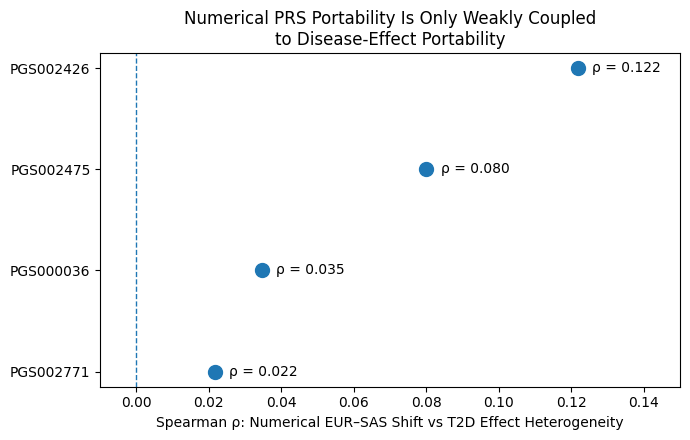

Saved:
/content/drive/MyDrive/prs_project_outputs/STS_2026/figures/Figure_cross_PGS_T2DGGI_standardized.png


In [11]:
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# CROSS-PGS T2DGGI FIGURE
# Numerical EUR-SAS portability vs disease-effect heterogeneity
# ============================================================

df = pd.DataFrame({
    "PGS": [
        "PGS002771",
        "PGS000036",
        "PGS002426",
        "PGS002475"
    ],
    "rho": [
        0.021541,
        0.034570,
        0.121732,
        0.079913
    ]
})

# Sort for easier visual comparison
df = df.sort_values("rho")

fig, ax = plt.subplots(figsize=(7, 4.5))

ax.scatter(
    df["rho"],
    df["PGS"],
    s=100
)

ax.axvline(
    0,
    linewidth=1,
    linestyle="--"
)

ax.set_xlabel(
    "Spearman ρ: Numerical EUR–SAS Shift vs T2D Effect Heterogeneity"
)

ax.set_ylabel("")

ax.set_title(
    "Numerical PRS Portability Is Only Weakly Coupled\nto Disease-Effect Portability"
)

# annotate rho values
for _, row in df.iterrows():
    ax.text(
        row["rho"] + 0.004,
        row["PGS"],
        f"ρ = {row['rho']:.3f}",
        va="center"
    )

ax.set_xlim(-0.01, 0.15)

plt.tight_layout()

OUT = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "STS_2026/figures/"
    "Figure_cross_PGS_T2DGGI_standardized.png"
)

plt.savefig(
    OUT,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(OUT)

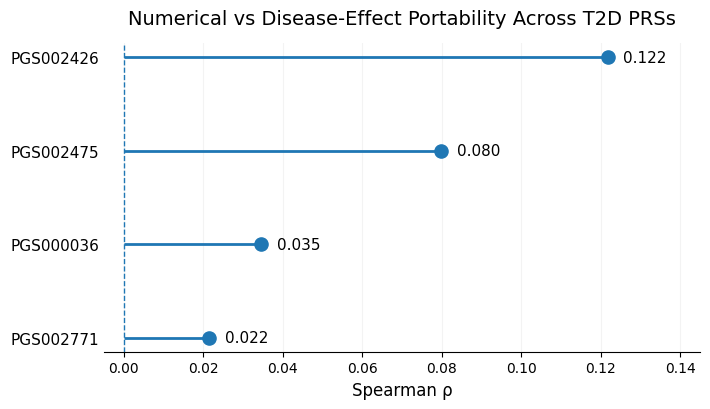

Saved:
/content/drive/MyDrive/prs_project_outputs/STS_2026/figures/Figure_cross_PGS_T2DGGI_standardized_clean.png


In [12]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame({
    "PGS": ["PGS002771", "PGS000036", "PGS002426", "PGS002475"],
    "rho": [0.021541, 0.034570, 0.121732, 0.079913]
})

df = df.sort_values("rho")

fig, ax = plt.subplots(figsize=(7.2, 4.2))

# horizontal stems
for _, row in df.iterrows():
    ax.hlines(
        y=row["PGS"],
        xmin=0,
        xmax=row["rho"],
        linewidth=2
    )

# dots
ax.scatter(
    df["rho"],
    df["PGS"],
    s=90,
    zorder=3
)

# annotations
for _, row in df.iterrows():
    ax.text(
        row["rho"] + 0.004,
        row["PGS"],
        f"{row['rho']:.3f}",
        va="center",
        fontsize=11
    )

# zero reference
ax.axvline(
    0,
    linewidth=1,
    linestyle="--"
)

# clean labels
ax.set_xlabel(
    "Spearman ρ",
    fontsize=12
)

ax.set_ylabel("")

ax.set_title(
    "Numerical vs Disease-Effect Portability Across T2D PRSs",
    fontsize=14,
    pad=14
)

# clean frame
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.tick_params(
    axis="y",
    length=0,
    labelsize=11
)

ax.tick_params(
    axis="x",
    labelsize=10
)

ax.set_xlim(-0.005, 0.145)

# subtle grid only on x
ax.grid(
    axis="x",
    alpha=0.15
)

plt.tight_layout()

OUT = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "STS_2026/figures/"
    "Figure_cross_PGS_T2DGGI_standardized_clean.png"
)

plt.savefig(
    OUT,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(OUT)

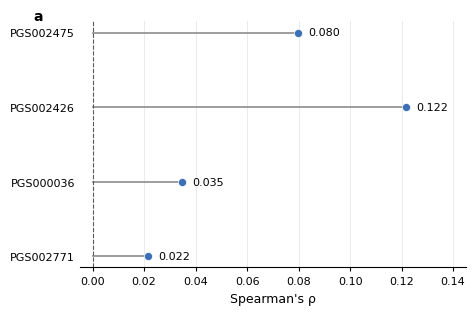

Saved: /content/drive/MyDrive/prs_project_outputs/STS_2026/figures/Figure_cross_PGS_T2DGGI_publication.png


In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df = pd.DataFrame({
    "PGS": ["PGS002771", "PGS000036", "PGS002426", "PGS002475"],
    "rho": [0.021541, 0.034570, 0.121732, 0.079913]
})

# Keep a logical order rather than sorting by effect
order = ["PGS002771", "PGS000036", "PGS002426", "PGS002475"]
df["PGS"] = pd.Categorical(df["PGS"], categories=order, ordered=True)
df = df.sort_values("PGS")

# Publication-style typography
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 8,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "axes.linewidth": 0.8,
})

fig, ax = plt.subplots(figsize=(4.8, 3.2))

y = np.arange(len(df))

# subtle stems
for i, r in enumerate(df["rho"]):
    ax.plot(
        [0, r],
        [i, i],
        lw=1.2,
        color="0.55",
        zorder=1
    )

# points
ax.scatter(
    df["rho"],
    y,
    s=34,
    color="#3B6FB6",
    edgecolor="white",
    linewidth=0.5,
    zorder=3
)

# numeric labels
for i, r in enumerate(df["rho"]):
    ax.text(
        r + 0.004,
        i,
        f"{r:.3f}",
        va="center",
        ha="left",
        fontsize=8
    )

# zero line
ax.axvline(
    0,
    color="0.35",
    lw=0.8,
    ls="--"
)

# axes
ax.set_yticks(y)
ax.set_yticklabels(df["PGS"])
ax.set_xlabel("Spearman's ρ")
ax.set_xlim(-0.005, 0.145)

# no plot title — use caption in manuscript instead
ax.set_ylabel("")

# clean frame
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.tick_params(axis="y", length=0)
ax.tick_params(axis="x", length=3, width=0.8)

# light x-grid
ax.grid(
    axis="x",
    color="0.90",
    lw=0.6
)

ax.set_axisbelow(True)

# panel label like a paper figure
ax.text(
    -0.12,
    1.05,
    "a",
    transform=ax.transAxes,
    fontsize=10,
    fontweight="bold",
    va="top"
)

plt.tight_layout()

OUT = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "STS_2026/figures/"
    "Figure_cross_PGS_T2DGGI_publication.png"
)

plt.savefig(
    OUT,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print("Saved:", OUT)

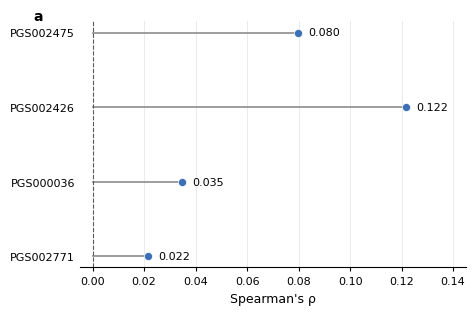

Saved: /content/drive/MyDrive/prs_project_outputs/STS_2026/figures/Figure_cross_PGS_T2DGGI_publication.png


In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# PUBLICATION-STYLE CROSS-PGS T2DGGI FIGURE
# ============================================================

df = pd.DataFrame({
    "PGS": ["PGS002771", "PGS000036", "PGS002426", "PGS002475"],
    "rho": [0.021541, 0.034570, 0.121732, 0.079913]
})

order = ["PGS002771", "PGS000036", "PGS002426", "PGS002475"]
df["PGS"] = pd.Categorical(df["PGS"], categories=order, ordered=True)
df = df.sort_values("PGS")

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 8,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "axes.linewidth": 0.8,
})

fig, ax = plt.subplots(figsize=(4.8, 3.2))

y = np.arange(len(df))

# stems
for i, r in enumerate(df["rho"]):
    ax.plot(
        [0, r],
        [i, i],
        lw=1.2,
        color="0.55",
        zorder=1
    )

# points
ax.scatter(
    df["rho"],
    y,
    s=34,
    color="#3B6FB6",
    edgecolor="white",
    linewidth=0.5,
    zorder=3
)

# rho labels
for i, r in enumerate(df["rho"]):
    ax.text(
        r + 0.004,
        i,
        f"{r:.3f}",
        va="center",
        ha="left",
        fontsize=8
    )

# zero line
ax.axvline(
    0,
    color="0.35",
    lw=0.8,
    ls="--"
)

# axes
ax.set_yticks(y)
ax.set_yticklabels(df["PGS"])
ax.set_xlabel("Spearman's ρ")
ax.set_ylabel("")
ax.set_xlim(-0.005, 0.145)

# clean frame
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.tick_params(axis="y", length=0)
ax.tick_params(axis="x", length=3, width=0.8)

ax.grid(
    axis="x",
    color="0.90",
    lw=0.6
)

ax.set_axisbelow(True)

# panel label
ax.text(
    -0.12,
    1.05,
    "a",
    transform=ax.transAxes,
    fontsize=10,
    fontweight="bold",
    va="top"
)

plt.tight_layout()

OUT = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "STS_2026/figures/"
    "Figure_cross_PGS_T2DGGI_publication.png"
)

plt.savefig(
    OUT,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print("Saved:", OUT)

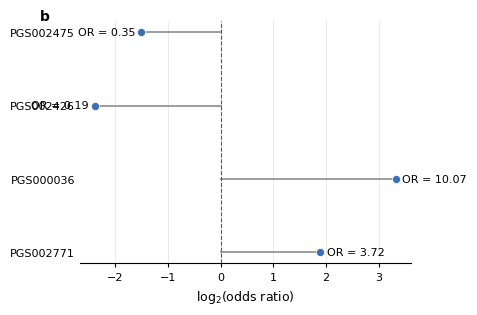

Saved: /content/drive/MyDrive/prs_project_outputs/STS_2026/figures/Figure_cross_PGS_Mahajan_publication.png


In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# PUBLICATION-STYLE CROSS-PGS MAHAJAN FIGURE
# Odds ratio for overlap of portability outliers with
# Mahajan fine-mapped T2D signal
# ============================================================

df = pd.DataFrame({
    "PGS": ["PGS002771", "PGS000036", "PGS002426", "PGS002475"],
    "OR": [3.7224, 10.0664, 0.191293, 0.353257]
})

order = ["PGS002771", "PGS000036", "PGS002426", "PGS002475"]
df["PGS"] = pd.Categorical(df["PGS"], categories=order, ordered=True)
df = df.sort_values("PGS")

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 8,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "axes.linewidth": 0.8,
})

fig, ax = plt.subplots(figsize=(4.8, 3.2))

y = np.arange(len(df))

# log scale makes enrichment/depletion symmetric around OR = 1
x = np.log2(df["OR"])

# stems from null
for i, val in enumerate(x):
    ax.plot(
        [0, val],
        [i, i],
        lw=1.2,
        color="0.55",
        zorder=1
    )

# points
ax.scatter(
    x,
    y,
    s=34,
    color="#3B6FB6",
    edgecolor="white",
    linewidth=0.5,
    zorder=3
)

# labels show actual OR
for i, (val, OR) in enumerate(zip(x, df["OR"])):
    offset = 0.12 if val >= 0 else -0.12
    ha = "left" if val >= 0 else "right"

    ax.text(
        val + offset,
        i,
        f"OR = {OR:.2f}",
        va="center",
        ha=ha,
        fontsize=8
    )

# null line
ax.axvline(
    0,
    color="0.35",
    lw=0.8,
    ls="--"
)

ax.set_yticks(y)
ax.set_yticklabels(df["PGS"])

ax.set_xlabel("log$_2$(odds ratio)")
ax.set_ylabel("")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.tick_params(axis="y", length=0)
ax.tick_params(axis="x", length=3, width=0.8)

ax.grid(
    axis="x",
    color="0.90",
    lw=0.6
)

ax.set_axisbelow(True)

# panel label
ax.text(
    -0.12,
    1.05,
    "b",
    transform=ax.transAxes,
    fontsize=10,
    fontweight="bold",
    va="top"
)

plt.tight_layout()

OUT = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "STS_2026/figures/"
    "Figure_cross_PGS_Mahajan_publication.png"
)

plt.savefig(
    OUT,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print("Saved:", OUT)

In [17]:
import pandas as pd

p771 = pd.read_csv(
    "/content/drive/MyDrive/fine_mapping/"
    "Reggie_finemapping_FINAL_summary.csv"
)

p36 = pd.read_csv(
    "/content/drive/MyDrive/fine_mapping/"
    "PGS000036_finemapping_replication_FINAL.csv"
)

print("========== PGS002771 ==========")
display(p771)

print("\n========== PGS000036 ==========")
display(p36)

========== PGS002771 ==========


,analysis,value
0,Recurrent credible-set hits,19.000000
1,Unique loci among recurrent credible hits,19.000000
2,Whole-PRS adjusted credible-set OR,3.722400
3,Within-finemapped-region adjusted OR,2.387600
4,Within-locus POST rank recurrent mean,0.857692
5,Within-locus POST rank nonrecurrent mean,0.621947
6,Locus-block permutation p,0.000010
7,Credible recurrent SAS score-effect rho,0.163158
8,Credible recurrent SAS p,0.504516
9,Credible recurrent EAS score-effect rho,-0.003509



========== PGS000036 ==========


,metric,value
0,PGS000036 total variants,1.701840e+05
1,Frozen mechanistic outliers,9.016000e+03
2,Variants in Mahajan fine-mapped regions,2.256400e+04
3,Unique Mahajan loci,3.140000e+02
4,Outlier credible hits,1.700000e+02
5,Background credible hits,8.400000e+01
6,Raw within-region OR,1.570340e+01
7,Raw within-region p,9.969254e-95
8,Adjusted within-region OR,1.006641e+01
9,Adjusted CI low,7.251493e+00


========== PGS002771 ==========


,analysis,value
0,Recurrent credible-set hits,19.000000
1,Unique loci among recurrent credible hits,19.000000
2,Whole-PRS adjusted credible-set OR,3.722400
3,Within-finemapped-region adjusted OR,2.387600
4,Within-locus POST rank recurrent mean,0.857692
5,Within-locus POST rank nonrecurrent mean,0.621947
6,Locus-block permutation p,0.000010
7,Credible recurrent SAS score-effect rho,0.163158
8,Credible recurrent SAS p,0.504516
9,Credible recurrent EAS score-effect rho,-0.003509



========== PGS000036 ==========


,metric,value
0,PGS000036 total variants,1.701840e+05
1,Frozen mechanistic outliers,9.016000e+03
2,Variants in Mahajan fine-mapped regions,2.256400e+04
3,Unique Mahajan loci,3.140000e+02
4,Outlier credible hits,1.700000e+02
5,Background credible hits,8.400000e+01
6,Raw within-region OR,1.570340e+01
7,Raw within-region p,9.969254e-95
8,Adjusted within-region OR,1.006641e+01
9,Adjusted CI low,7.251493e+00


In [19]:
import glob
import os

hits = glob.glob(
    "/content/drive/MyDrive/**/*PGS002771*finemap*.csv",
    recursive=True
) + glob.glob(
    "/content/drive/MyDrive/**/*PGS002771*fine*map*.csv",
    recursive=True
)

print("Candidate PGS002771 fine-mapping files:\n")

for x in hits:
    print(x)

Candidate PGS002771 fine-mapping files:



In [20]:
import glob
import os

files = glob.glob(
    "/content/drive/MyDrive/fine_mapping/**/*.csv",
    recursive=True
)

print("CSV files in fine_mapping:\n")

for x in files:
    print(os.path.basename(x), "->", x)

CSV files in fine_mapping:

Reggie_LD_pilot_candidates.csv -> /content/drive/MyDrive/fine_mapping/Reggie_LD_pilot_candidates.csv
Reggie_LD_pilot_top15.csv -> /content/drive/MyDrive/fine_mapping/Reggie_LD_pilot_top15.csv
Reggie_LD_pilot_top15_with_rsids.csv -> /content/drive/MyDrive/fine_mapping/Reggie_LD_pilot_top15_with_rsids.csv
Reggie_LD_pilot_results.csv -> /content/drive/MyDrive/fine_mapping/Reggie_LD_pilot_results.csv
Reggie_LD_all_recurrent_pairs.csv -> /content/drive/MyDrive/fine_mapping/Reggie_LD_all_recurrent_pairs.csv
Reggie_LD_recurrent_superpop.csv -> /content/drive/MyDrive/fine_mapping/Reggie_LD_recurrent_superpop.csv
Reggie_LD_controls_superpop.csv -> /content/drive/MyDrive/fine_mapping/Reggie_LD_controls_superpop.csv
Reggie_LD_expanded_controls_superpop.csv -> /content/drive/MyDrive/fine_mapping/Reggie_LD_expanded_controls_superpop.csv
Reggie_finemapping_FINAL_summary.csv -> /content/drive/MyDrive/fine_mapping/Reggie_finemapping_FINAL_summary.csv
PGS000036_finemapping_r

In [21]:
import glob
import os
import pandas as pd

# Search likely Reggie / primary fine-mapping CSVs anywhere in Drive
files = glob.glob(
    "/content/drive/MyDrive/**/*.csv",
    recursive=True
)

candidates = []

for path in files:
    name = os.path.basename(path).lower()

    if any(k in name for k in [
        "recurrent",
        "credible",
        "finemap",
        "fine_map",
        "fine-mapping",
        "mahajan"
    ]):
        try:
            cols = pd.read_csv(path, nrows=0).columns.tolist()

            # Looking for a variant-level file, not just a summary
            if any(c.lower() in [
                "credible",
                "recurrent",
                "locus",
                "post",
                "in_finemapping_resource"
            ] for c in cols):
                candidates.append((path, cols))
        except:
            pass

print("LIKELY PRIMARY FINE-MAPPING FILES:\n")

for path, cols in candidates:
    print("\n", path)
    print("Columns:", cols)

LIKELY PRIMARY FINE-MAPPING FILES:


 /content/drive/MyDrive/prs_project_outputs/replication_PGS002426/results/PGS002426_Mahajan_finemapping_replication.csv
Columns: ['chr', 'position', 'effect_allele', 'other_allele', 'effect_weight', 'EUR_effect_AF', 'AFR_effect_AF', 'EAS_effect_AF', 'SAS_effect_AF', 'AMR_effect_AF', 'max_AF_diff', 'delta_AFR_minus_EUR', 'abs_delta_AFR_minus_EUR', 'delta_EAS_minus_EUR', 'abs_delta_EAS_minus_EUR', 'delta_SAS_minus_EUR', 'abs_delta_SAS_minus_EUR', 'delta_AMR_minus_EUR', 'abs_delta_AMR_minus_EUR', 'avg_distortion', 'max_abs_delta_contribution', 'abs_effect', 'avg_distortion_model', 'predicted_distortion', 'residual_distortion', 'mechanistic_outlier', 'mahajan_ID', 'ID', 'POST', 'P', 'LOGBF', 'locus', 'credible', 'in_finemapping_resource', 'outlier_int']

 /content/drive/MyDrive/prs_project_outputs/replication_PGS002475/results/PGS002475_Mahajan_finemapping_replication.csv
Columns: ['chr', 'position', 'effect_allele', 'other_allele', 'effect_weight', 'ma

In [22]:
import glob
import os
import pandas as pd

files = glob.glob(
    "/content/drive/MyDrive/**/*.csv",
    recursive=True
)

hits = []

for path in files:
    try:
        df0 = pd.read_csv(path, nrows=3)
        cols = [c.lower() for c in df0.columns]

        # likely primary PGS002771 recurrence / outlier table
        if (
            any("recurrent" in c for c in cols)
            or any("rsid" in c for c in cols)
        ):
            if any(k in cols for k in [
                "abs_effect",
                "max_af_diff",
                "residual_distortion",
                "recurrent",
                "four_way_recurrent"
            ]):
                hits.append((path, df0.columns.tolist()))
    except:
        pass

print("LIKELY PGS002771 VARIANT TABLES:\n")

for path, cols in hits:
    print("\n", path)
    print("Columns:", cols)

LIKELY PGS002771 VARIANT TABLES:


 /content/drive/MyDrive/prs_project_outputs/residual_analysis_061026.csv
Columns: ['rsID', 'chr_name', 'chr_position', 'effect_allele', 'other_allele', 'effect_weight', 'allelefrequency_effect', 'hm_source', 'hm_rsID', 'hm_chr', 'hm_pos', 'hm_inferOtherAllele', 'match_type', 'VCF_REF', 'VCF_ALT', 'chr_audited', 'EUR_effect_AF', 'EUR_contribution', 'SAS_effect_AF', 'SAS_contribution', 'AFR_effect_AF', 'AFR_contribution', 'EAS_effect_AF', 'EAS_contribution', 'AMR_effect_AF', 'AMR_contribution', 'delta_SAS_minus_EUR', 'abs_delta_SAS_minus_EUR', 'delta_AFR_minus_EUR', 'abs_delta_AFR_minus_EUR', 'delta_EAS_minus_EUR', 'abs_delta_EAS_minus_EUR', 'delta_AMR_minus_EUR', 'abs_delta_AMR_minus_EUR', 'avg_distortion', 'abs_effect', 'predicted_distortion', 'residual_distortion', 'mean_AF_gap']

 /content/drive/MyDrive/prs_project_outputs/top_residual_snps.csv
Columns: ['rsID', 'chr_name', 'chr_position', 'effect_allele', 'other_allele', 'effect_weight', 'allelefre

In [23]:
import pandas as pd

PATH = (
    "/content/drive/MyDrive/fine_mapping/"
    "Reggie_LD_pilot_candidates.csv"
)

df = pd.read_csv(PATH)

print("Shape:", df.shape)
print("Unique SNPs:", df["rsID"].nunique())

print("\nRecurrent 4-way:")
print(df["recurrent_4way"].value_counts(dropna=False))

print("\nIn Mahajan fine-mapping resource:")
print(df["in_finemapping_resource"].value_counts(dropna=False))

print("\n99% credible set:")
print(df["in_99pct_credible_set"].value_counts(dropna=False))

print("\nAmong variants in Mahajan regions:")
sub = df[df["in_finemapping_resource"] == True]

print("N in regions:", len(sub))
print("Recurrent in regions:", int(sub["recurrent_4way"].sum()))
print("Credible in regions:", int(sub["in_99pct_credible_set"].sum()))

print("\n2x2 within-region table:")
print(pd.crosstab(
    sub["recurrent_4way"],
    sub["in_99pct_credible_set"]
))

Shape: (65, 83)
Unique SNPs: 65

Recurrent 4-way:
recurrent_4way
True    65
Name: count, dtype: int64

In Mahajan fine-mapping resource:
in_finemapping_resource
True    65
Name: count, dtype: int64

99% credible set:
in_99pct_credible_set
False    46
True     19
Name: count, dtype: int64

Among variants in Mahajan regions:
N in regions: 65
Recurrent in regions: 65
Credible in regions: 19

2x2 within-region table:
in_99pct_credible_set  False  True 
recurrent_4way                     
True                      46     19


In [24]:
import pandas as pd

PATH = (
    "/content/drive/MyDrive/prs_project_outputs/results/"
    "FINAL_master_snp_analysis.csv"
)

df = pd.read_csv(PATH)

print("Shape:", df.shape)
print("Unique SNPs:", df["rsID"].nunique())

print("\nn_ancestries_top10_residual counts:")
print(
    df["n_ancestries_top10_residual"]
    .value_counts(dropna=False)
    .sort_index()
)

# Four-way recurrent = top 10% residual in AFR, EAS, SAS, and AMR
df["recurrent_4way"] = (
    df["n_ancestries_top10_residual"] == 4
)

print("\nFour-way recurrent SNPs:")
print(df["recurrent_4way"].sum())

print("\nExpected: ~148")

Shape: (5622, 62)
Unique SNPs: 5622

n_ancestries_top10_residual counts:
n_ancestries_top10_residual
0    4375
1     666
2     285
3     168
4     128
Name: count, dtype: int64

Four-way recurrent SNPs:
128

Expected: ~148


In [25]:
import glob
import pandas as pd
import os

files = glob.glob(
    "/content/drive/MyDrive/**/*.csv",
    recursive=True
)

print("FILES WITH A RECURRENT_4WAY COLUMN:\n")

for path in files:
    try:
        x = pd.read_csv(path)

        if "recurrent_4way" in x.columns:
            print("\n======================================")
            print(path)
            print("shape:", x.shape)
            print("recurrent_4way TRUE:", int(x["recurrent_4way"].fillna(False).sum()))

            useful = [
                c for c in [
                    "rsID",
                    "recurrent_4way",
                    "n_top10_ancestries",
                    "n_ancestries_top10_residual",
                    "top10_abs_delta_SAS_minus_EUR",
                    "top10_abs_delta_AFR_minus_EUR",
                    "top10_abs_delta_EAS_minus_EUR",
                    "top10_abs_delta_AMR_minus_EUR",
                    "universal_top10"
                ]
                if c in x.columns
            ]

            if useful:
                display(x[useful].head())
    except:
        pass

FILES WITH A RECURRENT_4WAY COLUMN:



/tmp/ipykernel_2988/3533896849.py:14: DtypeWarning: Columns (14,16,24) have mixed types. Specify dtype option on import or set low_memory=False.
  x = pd.read_csv(path)



/content/drive/MyDrive/fine_mapping/Reggie_LD_pilot_candidates.csv
shape: (65, 83)
recurrent_4way TRUE: 65


,rsID,recurrent_4way,n_top10_ancestries,n_ancestries_top10_residual,top10_abs_delta_SAS_minus_EUR,top10_abs_delta_AFR_minus_EUR,top10_abs_delta_EAS_minus_EUR,top10_abs_delta_AMR_minus_EUR,universal_top10
0,rs2820426,True,4,3,True,True,True,True,0
1,rs16826069,True,4,3,True,True,True,True,0
2,rs6540803,True,4,1,True,True,True,True,0
3,rs2943640,True,4,4,True,True,True,True,1
4,rs1128249,True,4,4,True,True,True,True,1



/content/drive/MyDrive/fine_mapping/Reggie_LD_pilot_top15.csv
shape: (15, 83)
recurrent_4way TRUE: 15


,rsID,recurrent_4way,n_top10_ancestries,n_ancestries_top10_residual,top10_abs_delta_SAS_minus_EUR,top10_abs_delta_AFR_minus_EUR,top10_abs_delta_EAS_minus_EUR,top10_abs_delta_AMR_minus_EUR,universal_top10
0,rs780094,True,4,4,True,True,True,True,1
1,rs2237896,True,4,4,True,True,True,True,1
2,rs11717195,True,4,3,True,True,True,True,0
3,rs4812829,True,4,4,True,True,True,True,1
4,rs3802177,True,4,4,True,True,True,True,1



/content/drive/MyDrive/fine_mapping/Reggie_LD_pilot_top15_with_rsids.csv
shape: (15, 84)
recurrent_4way TRUE: 15


,rsID,recurrent_4way,n_top10_ancestries,n_ancestries_top10_residual,top10_abs_delta_SAS_minus_EUR,top10_abs_delta_AFR_minus_EUR,top10_abs_delta_EAS_minus_EUR,top10_abs_delta_AMR_minus_EUR,universal_top10
0,rs780094,True,4,4,True,True,True,True,1
1,rs2237896,True,4,4,True,True,True,True,1
2,rs11717195,True,4,3,True,True,True,True,0
3,rs4812829,True,4,4,True,True,True,True,1
4,rs3802177,True,4,4,True,True,True,True,1


In [26]:
import pandas as pd

PATH = (
    "/content/drive/MyDrive/prs_project_outputs/results/"
    "FINAL_master_snp_analysis.csv"
)

df = pd.read_csv(PATH)

ancestries = ["SAS", "AFR", "EAS", "AMR"]

# Top 10% of absolute numerical displacement separately in each ancestry
for anc in ancestries:
    col = f"abs_delta_{anc}_minus_EUR"
    threshold = df[col].quantile(0.90)

    df[f"top10_abs_delta_{anc}_minus_EUR"] = (
        df[col] >= threshold
    )

    print(
        anc,
        "threshold =", threshold,
        "top10 N =", df[f"top10_abs_delta_{anc}_minus_EUR"].sum()
    )

# Number of ancestries in which SNP is top 10%
df["n_top10_ancestries"] = sum(
    df[f"top10_abs_delta_{anc}_minus_EUR"].astype(int)
    for anc in ancestries
)

# Exact old four-way recurrence definition
df["recurrent_4way"] = (
    df["n_top10_ancestries"] == 4
)

print("\n===================================")
print("RECONSTRUCTED NUMERICAL RECURRENCE")
print("===================================")

print("Total SNPs:", len(df))
print("Four-way recurrent:", int(df["recurrent_4way"].sum()))

print("\nn_top10_ancestries distribution:")
print(
    df["n_top10_ancestries"]
    .value_counts()
    .sort_index()
)

# Check against the known 65 recurrent variants in Mahajan regions
pilot = pd.read_csv(
    "/content/drive/MyDrive/fine_mapping/"
    "Reggie_LD_pilot_candidates.csv"
)

pilot_ids = set(pilot["rsID"])

reconstructed_pilot_overlap = (
    df["recurrent_4way"]
    & df["rsID"].isin(pilot_ids)
).sum()

print("\nKnown Mahajan recurrent set:", len(pilot_ids))
print("Recovered among reconstructed recurrent SNPs:",
      reconstructed_pilot_overlap)

SAS threshold = 0.0022062270141929 top10 N = 563
AFR threshold = 0.0044274053350096 top10 N = 563
EAS threshold = 0.0037353936381709 top10 N = 563
AMR threshold = 0.0018054472015171 top10 N = 563

RECONSTRUCTED NUMERICAL RECURRENCE
Total SNPs: 5622
Four-way recurrent: 148

n_top10_ancestries distribution:
n_top10_ancestries
0    4517
1     471
2     269
3     217
4     148
Name: count, dtype: int64

Known Mahajan recurrent set: 65
Recovered among reconstructed recurrent SNPs: 65


In [27]:
import os
import gzip
import tarfile
import numpy as np
import pandas as pd
from scipy.stats import fisher_exact

# ============================================================
# PATHS
# ============================================================

MASTER = (
    "/content/drive/MyDrive/prs_project_outputs/results/"
    "FINAL_master_snp_analysis.csv"
)

FM_TAR = "/content/drive/MyDrive/fine_mapping/fine_mapping_upload.tar"
CS_TAR = "/content/drive/MyDrive/fine_mapping/credible_set_upload.tar"

OUT = (
    "/content/drive/MyDrive/fine_mapping/"
    "PGS002771_Mahajan_full_master.csv"
)

# ============================================================
# LOAD + RECONSTRUCT EXACT 148 RECURRENT SNPs
# ============================================================

df = pd.read_csv(MASTER).copy()

ancestries = ["SAS", "AFR", "EAS", "AMR"]

for anc in ancestries:
    col = f"abs_delta_{anc}_minus_EUR"
    threshold = df[col].quantile(0.90)

    df[f"top10_abs_delta_{anc}_minus_EUR"] = (
        df[col] >= threshold
    )

df["n_top10_ancestries"] = sum(
    df[f"top10_abs_delta_{anc}_minus_EUR"].astype(int)
    for anc in ancestries
)

df["recurrent_4way"] = (
    df["n_top10_ancestries"] == 4
)

print("Recurrent 4-way:", int(df["recurrent_4way"].sum()))

# ============================================================
# HELPERS
# ============================================================

def decode_member(raw):
    if raw[:2] == b"\x1f\x8b":
        raw = gzip.decompress(raw)
    return raw.decode("utf-8", errors="replace")

def valid_variant_id(s):
    if not s.startswith("chr") or ":" not in s:
        return False

    try:
        chrom, pos = s.replace("chr", "", 1).split(":", 1)
        int(chrom)
        int(pos)
        return True
    except:
        return False

# ============================================================
# PARSE MAHAJAN FULL FINE-MAPPING RESOURCE
# ============================================================

fm_rows = []

with tarfile.open(FM_TAR, "r") as tar:

    for m in tar.getmembers():

        if not m.isfile():
            continue

        text = decode_member(
            tar.extractfile(m).read()
        )

        base = os.path.basename(m.name)

        locus = (
            base
            .replace("finemap.", "")
            .replace(".txt.gz", "")
            .replace(".txt", "")
        )

        for line in text.splitlines():

            parts = line.strip().split()

            if len(parts) < 4:
                continue

            if not valid_variant_id(parts[0]):
                continue

            try:
                P = float(parts[1])
                LOGBF = float(parts[2])
                POST = float(parts[3])
            except:
                continue

            fm_rows.append({
                "ID": parts[0],
                "P": P,
                "LOGBF": LOGBF,
                "POST": POST,
                "locus": locus
            })

fm = pd.DataFrame(fm_rows)

fm = (
    fm.sort_values("POST", ascending=False)
      .drop_duplicates("ID", keep="first")
      .reset_index(drop=True)
)

fm_ids = set(fm["ID"])

print("Unique Mahajan fine-map variants:", len(fm))

# ============================================================
# PARSE 99% CREDIBLE SETS
# ============================================================

cs_rows = []

with tarfile.open(CS_TAR, "r") as tar:

    for m in tar.getmembers():

        if not m.isfile():
            continue

        text = decode_member(
            tar.extractfile(m).read()
        )

        for line in text.splitlines():

            parts = line.strip().split()

            if len(parts) < 4:
                continue

            if not valid_variant_id(parts[0]):
                continue

            try:
                POST = float(parts[3])
            except:
                continue

            cs_rows.append({
                "ID": parts[0],
                "POST": POST
            })

cs = pd.DataFrame(cs_rows)
credible_ids = set(cs["ID"])

print("Unique credible variants:", len(credible_ids))

# ============================================================
# BUILD PGS002771 MAHAJAN IDs
# ============================================================

df["mahajan_ID"] = (
    "chr"
    + df["hm_chr"].astype(int).astype(str)
    + ":"
    + df["hm_pos"].astype(int).astype(str)
)

df = df.merge(
    fm[
        ["ID", "POST", "P", "LOGBF", "locus"]
    ],
    left_on="mahajan_ID",
    right_on="ID",
    how="left"
)

df["in_finemapping_resource"] = (
    df["mahajan_ID"].isin(fm_ids)
)

df["credible"] = (
    df["mahajan_ID"].isin(credible_ids)
)

# ============================================================
# VALIDATE AGAINST KNOWN OLD RESULTS
# ============================================================

print("\n====================================")
print("VALIDATION")
print("====================================")

print(
    "Variants in Mahajan resource:",
    int(df["in_finemapping_resource"].sum())
)

print(
    "Recurrent in Mahajan resource:",
    int(
        (
            df["recurrent_4way"]
            &
            df["in_finemapping_resource"]
        ).sum()
    )
)

print(
    "Recurrent credible hits:",
    int(
        (
            df["recurrent_4way"]
            &
            df["credible"]
        ).sum()
    )
)

# ============================================================
# RAW WITHIN-REGION CREDIBLE-SET OR
# ============================================================

sub = df[
    df["in_finemapping_resource"]
].copy()

out = sub["recurrent_4way"].astype(bool)
cred = sub["credible"].astype(bool)

a = int((out & cred).sum())
b = int((out & ~cred).sum())
c = int((~out & cred).sum())
d = int((~out & ~cred).sum())

OR, p = fisher_exact(
    [[a, b],
     [c, d]]
)

print("\n====================================")
print("RAW WITHIN-REGION CREDIBLE-SET TEST")
print("====================================")

print("Recurrent credible:", a)
print("Recurrent noncredible:", b)
print("Background credible:", c)
print("Background noncredible:", d)

print("Raw within-region OR:", OR)
print("Raw p:", p)

# ============================================================
# SAVE
# ============================================================

df.to_csv(OUT, index=False)

print("\nSaved:")
print(OUT)

Recurrent 4-way: 148
Unique Mahajan fine-map variants: 950300
Unique credible variants: 7794

VALIDATION
Variants in Mahajan resource: 720
Recurrent in Mahajan resource: 65
Recurrent credible hits: 19

RAW WITHIN-REGION CREDIBLE-SET TEST
Recurrent credible: 19
Recurrent noncredible: 46
Background credible: 36
Background noncredible: 619
Raw within-region OR: 7.1020531400966185
Raw p: 2.5720405983451853e-08

Saved:
/content/drive/MyDrive/fine_mapping/PGS002771_Mahajan_full_master.csv


,PGS,driver_pct,background_pct
0,PGS002771,29.230769,5.496183
1,PGS000036,6.256901,0.423238
2,PGS002426,0.000000,11.647255
3,PGS002475,0.000000,6.572165


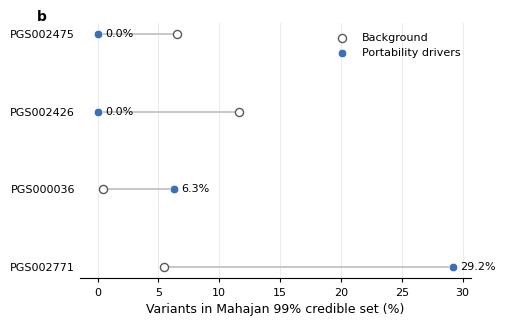

Saved: /content/drive/MyDrive/prs_project_outputs/STS_2026/figures/Figure_cross_PGS_Mahajan_credible_fraction.png


In [29]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# CROSS-PGS MAHAJAN CREDIBLE-SET FRACTIONS
# Apples-to-apples within fine-mapped regions
# ============================================================

data = pd.DataFrame({
    "PGS": [
        "PGS002771",
        "PGS000036",
        "PGS002426",
        "PGS002475"
    ],

    # portability-driver variants inside Mahajan regions
    "driver_credible": [19, 170, 0, 0],
    "driver_noncredible": [46, 2547, 7, 31],

    # background variants inside Mahajan regions
    "background_credible": [36, 84, 70, 102],
    "background_noncredible": [619, 19763, 531, 1450]
})

data["driver_fraction"] = (
    data["driver_credible"] /
    (data["driver_credible"] + data["driver_noncredible"])
)

data["background_fraction"] = (
    data["background_credible"] /
    (data["background_credible"] + data["background_noncredible"])
)

# Convert to %
data["driver_pct"] = 100 * data["driver_fraction"]
data["background_pct"] = 100 * data["background_fraction"]

display(
    data[
        [
            "PGS",
            "driver_pct",
            "background_pct"
        ]
    ]
)

# ============================================================
# PLOT
# ============================================================

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 8,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "axes.linewidth": 0.8,
})

fig, ax = plt.subplots(figsize=(5.1, 3.3))

y = np.arange(len(data))

# connector between background and driver fraction
for i in range(len(data)):
    ax.plot(
        [
            data.loc[i, "background_pct"],
            data.loc[i, "driver_pct"]
        ],
        [i, i],
        color="0.75",
        lw=1.2,
        zorder=1
    )

# background
ax.scatter(
    data["background_pct"],
    y,
    s=34,
    facecolor="white",
    edgecolor="0.35",
    linewidth=1,
    label="Background",
    zorder=3
)

# portability drivers
ax.scatter(
    data["driver_pct"],
    y,
    s=38,
    color="#3B6FB6",
    edgecolor="white",
    linewidth=0.5,
    label="Portability drivers",
    zorder=4
)

# annotate driver percentages only
for i, value in enumerate(data["driver_pct"]):
    ax.text(
        value + 0.6,
        i,
        f"{value:.1f}%",
        va="center",
        fontsize=8
    )

ax.set_yticks(y)
ax.set_yticklabels(data["PGS"])

ax.set_xlabel("Variants in Mahajan 99% credible set (%)")
ax.set_ylabel("")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.tick_params(axis="y", length=0)
ax.tick_params(axis="x", length=3, width=0.8)

ax.grid(
    axis="x",
    color="0.91",
    lw=0.6
)

ax.set_axisbelow(True)

ax.legend(
    frameon=False,
    loc="upper right",
    fontsize=8
)

ax.text(
    -0.11,
    1.05,
    "b",
    transform=ax.transAxes,
    fontsize=10,
    fontweight="bold",
    va="top"
)

plt.tight_layout()

OUT = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "STS_2026/figures/"
    "Figure_cross_PGS_Mahajan_credible_fraction.png"
)

plt.savefig(
    OUT,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print("Saved:", OUT)

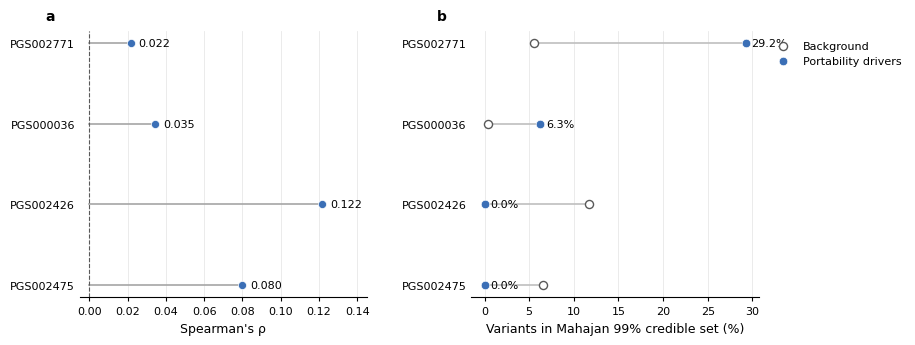

Saved:
/content/drive/MyDrive/prs_project_outputs/STS_2026/figures/Figure_cross_PGS_combined_FINAL.png


In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# FINAL CROSS-PGS TWO-PANEL FIGURE
# a = T2DGGI numerical vs disease-effect portability
# b = Mahajan credible-set enrichment pattern
# ============================================================

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 8,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "axes.linewidth": 0.8,
})

order = [
    "PGS002771",
    "PGS000036",
    "PGS002426",
    "PGS002475"
]

# ============================================================
# PANEL A DATA
# ============================================================

a = pd.DataFrame({
    "PGS": order,
    "rho": [
        0.021541,
        0.034570,
        0.121732,
        0.079913
    ]
})

# ============================================================
# PANEL B DATA
# ============================================================

b = pd.DataFrame({
    "PGS": order,

    "driver_credible": [
        19,
        170,
        0,
        0
    ],

    "driver_noncredible": [
        46,
        2547,
        7,
        31
    ],

    "background_credible": [
        36,
        84,
        70,
        102
    ],

    "background_noncredible": [
        619,
        19763,
        531,
        1450
    ]
})

b["driver_pct"] = 100 * (
    b["driver_credible"] /
    (b["driver_credible"] + b["driver_noncredible"])
)

b["background_pct"] = 100 * (
    b["background_credible"] /
    (b["background_credible"] + b["background_noncredible"])
)

# ============================================================
# FIGURE
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(9.2, 3.5)
)

y = np.arange(len(order))

# ============================================================
# PANEL A
# ============================================================

ax = axes[0]

for i, r in enumerate(a["rho"]):
    ax.plot(
        [0, r],
        [i, i],
        color="0.65",
        lw=1.2,
        zorder=1
    )

ax.scatter(
    a["rho"],
    y,
    s=34,
    color="#3B6FB6",
    edgecolor="white",
    linewidth=0.5,
    zorder=3
)

for i, r in enumerate(a["rho"]):
    ax.text(
        r + 0.004,
        i,
        f"{r:.3f}",
        va="center",
        fontsize=8
    )

ax.axvline(
    0,
    color="0.35",
    lw=0.8,
    ls="--"
)

ax.set_yticks(y)
ax.set_yticklabels(order)

ax.set_xlabel("Spearman's ρ")

ax.set_xlim(-0.005, 0.145)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.tick_params(axis="y", length=0)
ax.tick_params(axis="x", length=3)

ax.grid(
    axis="x",
    color="0.91",
    lw=0.6
)

ax.set_axisbelow(True)

ax.text(
    -0.12,
    1.04,
    "a",
    transform=ax.transAxes,
    fontsize=10,
    fontweight="bold"
)

# ============================================================
# PANEL B
# ============================================================

ax = axes[1]

for i in range(len(b)):

    ax.plot(
        [
            b.loc[i, "background_pct"],
            b.loc[i, "driver_pct"]
        ],
        [i, i],
        color="0.75",
        lw=1.2,
        zorder=1
    )

ax.scatter(
    b["background_pct"],
    y,
    s=34,
    facecolor="white",
    edgecolor="0.35",
    linewidth=1,
    label="Background",
    zorder=3
)

ax.scatter(
    b["driver_pct"],
    y,
    s=38,
    color="#3B6FB6",
    edgecolor="white",
    linewidth=0.5,
    label="Portability drivers",
    zorder=4
)

for i, value in enumerate(b["driver_pct"]):

    ax.text(
        value + 0.6,
        i,
        f"{value:.1f}%",
        va="center",
        fontsize=8
    )

ax.set_yticks(y)
ax.set_yticklabels(order)

ax.set_xlabel(
    "Variants in Mahajan 99% credible set (%)"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.tick_params(axis="y", length=0)
ax.tick_params(axis="x", length=3)

ax.grid(
    axis="x",
    color="0.91",
    lw=0.6
)

ax.set_axisbelow(True)

ax.legend(
    frameon=False,
    fontsize=8,
    loc="upper left",
    bbox_to_anchor=(1.01, 1.0)
)

ax.text(
    -0.12,
    1.04,
    "b",
    transform=ax.transAxes,
    fontsize=10,
    fontweight="bold"
)

# ============================================================
# MATCH ORDER: PGS002771 AT TOP
# ============================================================

for ax in axes:
    ax.invert_yaxis()

plt.tight_layout(w_pad=3)

OUT = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "STS_2026/figures/"
    "Figure_cross_PGS_combined_FINAL.png"
)

plt.savefig(
    OUT,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(OUT)

In [31]:
import pandas as pd
import numpy as np
from scipy.stats import spearmanr

# ============================================================
# BOOTSTRAP 95% CIs FOR CROSS-PGS T2DGGI SPEARMAN RHO
# ============================================================

configs = {
    "PGS002771": {
        "path":
            "/content/drive/MyDrive/prs_project_outputs/"
            "publication_effect_portability/results/"
            "PGS002771_T2DGGI_effect_portability_master.csv",
        "num": "abs_score_shift_SAS_EUR",
        "bio": "abs_z_diff_SAS_EUR",
    },

    "PGS000036": {
        "path":
            "/content/drive/MyDrive/prs_project_outputs/"
            "replication_PGS000036/results/"
            "PGS000036_T2DGGI_EUR_SAS_effect_portability_master.csv",
        "num": "abs_numerical_distortion",
        "bio": "abs_z_diff_SAS_EUR",
    },

    "PGS002426": {
        "path":
            "/content/drive/MyDrive/prs_project_outputs/"
            "replication_PGS002426/results/"
            "PGS002426_T2DGGI_EUR_SAS_effect_portability_master.csv",
        "num": "abs_delta_SAS_minus_EUR",
        "bio": "abs_z_diff_SAS_EUR",
    },

    "PGS002475": {
        "path":
            "/content/drive/MyDrive/prs_project_outputs/"
            "replication_PGS002475/results/"
            "PGS002475_T2DGGI_EUR_SAS_effect_portability_master.csv",
        "num": "abs_numerical_displacement_EUR_SAS",
        "bio": "abs_effect_heterogeneity_z",
    }
}

rng = np.random.default_rng(42)

N_BOOT = 2000

rows = []

for pgs, cfg in configs.items():

    df = pd.read_csv(cfg["path"])[
        [cfg["num"], cfg["bio"]]
    ].dropna().reset_index(drop=True)

    x = df[cfg["num"]].to_numpy()
    y = df[cfg["bio"]].to_numpy()

    rho_obs, p_obs = spearmanr(x, y)

    boot_rhos = []

    n = len(df)

    for _ in range(N_BOOT):
        idx = rng.integers(
            0,
            n,
            size=n
        )

        rho, _ = spearmanr(
            x[idx],
            y[idx]
        )

        boot_rhos.append(rho)

    ci_low, ci_high = np.percentile(
        boot_rhos,
        [2.5, 97.5]
    )

    rows.append({
        "PGS": pgs,
        "N": n,
        "rho": rho_obs,
        "p_value": p_obs,
        "CI_95_low": ci_low,
        "CI_95_high": ci_high
    })

    print(
        pgs,
        "| rho =", round(rho_obs, 4),
        "| 95% CI =",
        (round(ci_low, 4), round(ci_high, 4))
    )

results = pd.DataFrame(rows)

print("\n====================================")
print("FINAL BOOTSTRAP T2DGGI SUMMARY")
print("====================================")

display(results)

OUT = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "STS_2026/"
    "cross_PGS_T2DGGI_EUR_SAS_bootstrap_CI_FINAL.csv"
)

results.to_csv(
    OUT,
    index=False
)

print("\nSaved:")
print(OUT)

PGS002771 | rho = 0.0215 | 95% CI = (np.float64(-0.0046), np.float64(0.0481))
PGS000036 | rho = 0.0346 | 95% CI = (np.float64(0.0299), np.float64(0.0393))
PGS002426 | rho = 0.1217 | 95% CI = (np.float64(0.0813), np.float64(0.1628))
PGS002475 | rho = 0.0799 | 95% CI = (np.float64(0.0584), np.float64(0.1012))

FINAL BOOTSTRAP T2DGGI SUMMARY


,PGS,N,rho,p_value,CI_95_low,CI_95_high
0,PGS002771,5620,0.021541,1.063760e-01,-0.004619,0.048139
1,PGS000036,162148,0.034570,4.482884e-44,0.029892,0.039300
2,PGS002426,2365,0.121732,2.868223e-09,0.081317,0.162796
3,PGS002475,8838,0.079913,5.327462e-14,0.058381,0.101238



Saved:
/content/drive/MyDrive/prs_project_outputs/STS_2026/cross_PGS_T2DGGI_EUR_SAS_bootstrap_CI_FINAL.csv


In [32]:
import pandas as pd
import numpy as np
from scipy.stats import spearmanr

# ============================================================
# BOOTSTRAP 95% CIs FOR CROSS-PGS T2DGGI SPEARMAN RHO
# ============================================================

configs = {
    "PGS002771": {
        "path":
            "/content/drive/MyDrive/prs_project_outputs/"
            "publication_effect_portability/results/"
            "PGS002771_T2DGGI_effect_portability_master.csv",
        "num": "abs_score_shift_SAS_EUR",
        "bio": "abs_z_diff_SAS_EUR",
    },

    "PGS000036": {
        "path":
            "/content/drive/MyDrive/prs_project_outputs/"
            "replication_PGS000036/results/"
            "PGS000036_T2DGGI_EUR_SAS_effect_portability_master.csv",
        "num": "abs_numerical_distortion",
        "bio": "abs_z_diff_SAS_EUR",
    },

    "PGS002426": {
        "path":
            "/content/drive/MyDrive/prs_project_outputs/"
            "replication_PGS002426/results/"
            "PGS002426_T2DGGI_EUR_SAS_effect_portability_master.csv",
        "num": "abs_delta_SAS_minus_EUR",
        "bio": "abs_z_diff_SAS_EUR",
    },

    "PGS002475": {
        "path":
            "/content/drive/MyDrive/prs_project_outputs/"
            "replication_PGS002475/results/"
            "PGS002475_T2DGGI_EUR_SAS_effect_portability_master.csv",
        "num": "abs_numerical_displacement_EUR_SAS",
        "bio": "abs_effect_heterogeneity_z",
    }
}

rng = np.random.default_rng(42)

N_BOOT = 2000

rows = []

for pgs, cfg in configs.items():

    df = pd.read_csv(cfg["path"])[
        [cfg["num"], cfg["bio"]]
    ].dropna().reset_index(drop=True)

    x = df[cfg["num"]].to_numpy()
    y = df[cfg["bio"]].to_numpy()

    rho_obs, p_obs = spearmanr(x, y)

    boot_rhos = []

    n = len(df)

    for _ in range(N_BOOT):
        idx = rng.integers(
            0,
            n,
            size=n
        )

        rho, _ = spearmanr(
            x[idx],
            y[idx]
        )

        boot_rhos.append(rho)

    ci_low, ci_high = np.percentile(
        boot_rhos,
        [2.5, 97.5]
    )

    rows.append({
        "PGS": pgs,
        "N": n,
        "rho": rho_obs,
        "p_value": p_obs,
        "CI_95_low": ci_low,
        "CI_95_high": ci_high
    })

    print(
        pgs,
        "| rho =", round(rho_obs, 4),
        "| 95% CI =",
        (round(ci_low, 4), round(ci_high, 4))
    )

results = pd.DataFrame(rows)

print("\n====================================")
print("FINAL BOOTSTRAP T2DGGI SUMMARY")
print("====================================")

display(results)

OUT = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "STS_2026/"
    "cross_PGS_T2DGGI_EUR_SAS_bootstrap_CI_FINAL.csv"
)

results.to_csv(
    OUT,
    index=False
)

print("\nSaved:")
print(OUT)

PGS002771 | rho = 0.0215 | 95% CI = (np.float64(-0.0046), np.float64(0.0481))
PGS000036 | rho = 0.0346 | 95% CI = (np.float64(0.0299), np.float64(0.0393))
PGS002426 | rho = 0.1217 | 95% CI = (np.float64(0.0813), np.float64(0.1628))
PGS002475 | rho = 0.0799 | 95% CI = (np.float64(0.0584), np.float64(0.1012))

FINAL BOOTSTRAP T2DGGI SUMMARY


,PGS,N,rho,p_value,CI_95_low,CI_95_high
0,PGS002771,5620,0.021541,1.063760e-01,-0.004619,0.048139
1,PGS000036,162148,0.034570,4.482884e-44,0.029892,0.039300
2,PGS002426,2365,0.121732,2.868223e-09,0.081317,0.162796
3,PGS002475,8838,0.079913,5.327462e-14,0.058381,0.101238



Saved:
/content/drive/MyDrive/prs_project_outputs/STS_2026/cross_PGS_T2DGGI_EUR_SAS_bootstrap_CI_FINAL.csv


In [34]:
import pandas as pd
import numpy as np
from scipy.stats import spearmanr

# ============================================================
# BOOTSTRAP 95% CIs FOR CROSS-PGS T2DGGI SPEARMAN RHO
# ============================================================

configs = {
    "PGS002771": {
        "path":
            "/content/drive/MyDrive/prs_project_outputs/"
            "publication_effect_portability/results/"
            "PGS002771_T2DGGI_effect_portability_master.csv",
        "num": "abs_score_shift_SAS_EUR",
        "bio": "abs_z_diff_SAS_EUR",
    },

    "PGS000036": {
        "path":
            "/content/drive/MyDrive/prs_project_outputs/"
            "replication_PGS000036/results/"
            "PGS000036_T2DGGI_EUR_SAS_effect_portability_master.csv",
        "num": "abs_numerical_distortion",
        "bio": "abs_z_diff_SAS_EUR",
    },

    "PGS002426": {
        "path":
            "/content/drive/MyDrive/prs_project_outputs/"
            "replication_PGS002426/results/"
            "PGS002426_T2DGGI_EUR_SAS_effect_portability_master.csv",
        "num": "abs_delta_SAS_minus_EUR",
        "bio": "abs_z_diff_SAS_EUR",
    },

    "PGS002475": {
        "path":
            "/content/drive/MyDrive/prs_project_outputs/"
            "replication_PGS002475/results/"
            "PGS002475_T2DGGI_EUR_SAS_effect_portability_master.csv",
        "num": "abs_numerical_displacement_EUR_SAS",
        "bio": "abs_effect_heterogeneity_z",
    }
}

rng = np.random.default_rng(42)

N_BOOT = 2000

rows = []

for pgs, cfg in configs.items():

    df = pd.read_csv(cfg["path"])[
        [cfg["num"], cfg["bio"]]
    ].dropna().reset_index(drop=True)

    x = df[cfg["num"]].to_numpy()
    y = df[cfg["bio"]].to_numpy()

    rho_obs, p_obs = spearmanr(x, y)

    boot_rhos = []

    n = len(df)

    for _ in range(N_BOOT):
        idx = rng.integers(
            0,
            n,
            size=n
        )

        rho, _ = spearmanr(
            x[idx],
            y[idx]
        )

        boot_rhos.append(rho)

    ci_low, ci_high = np.percentile(
        boot_rhos,
        [2.5, 97.5]
    )

    rows.append({
        "PGS": pgs,
        "N": n,
        "rho": rho_obs,
        "p_value": p_obs,
        "CI_95_low": ci_low,
        "CI_95_high": ci_high
    })

    print(
        pgs,
        "| rho =", round(rho_obs, 4),
        "| 95% CI =",
        (round(ci_low, 4), round(ci_high, 4))
    )

results = pd.DataFrame(rows)

print("\n====================================")
print("FINAL BOOTSTRAP T2DGGI SUMMARY")
print("====================================")

display(results)

OUT = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "STS_2026/"
    "cross_PGS_T2DGGI_EUR_SAS_bootstrap_CI_FINAL.csv"
)

results.to_csv(
    OUT,
    index=False
)

print("\nSaved:")
print(OUT)

PGS002771 | rho = 0.0215 | 95% CI = (np.float64(-0.0046), np.float64(0.0481))
PGS000036 | rho = 0.0346 | 95% CI = (np.float64(0.0299), np.float64(0.0393))
PGS002426 | rho = 0.1217 | 95% CI = (np.float64(0.0813), np.float64(0.1628))
PGS002475 | rho = 0.0799 | 95% CI = (np.float64(0.0584), np.float64(0.1012))

FINAL BOOTSTRAP T2DGGI SUMMARY


,PGS,N,rho,p_value,CI_95_low,CI_95_high
0,PGS002771,5620,0.021541,1.063760e-01,-0.004619,0.048139
1,PGS000036,162148,0.034570,4.482884e-44,0.029892,0.039300
2,PGS002426,2365,0.121732,2.868223e-09,0.081317,0.162796
3,PGS002475,8838,0.079913,5.327462e-14,0.058381,0.101238



Saved:
/content/drive/MyDrive/prs_project_outputs/STS_2026/cross_PGS_T2DGGI_EUR_SAS_bootstrap_CI_FINAL.csv


In [35]:
import pandas as pd
import numpy as np
from scipy.stats import fisher_exact

# ============================================================
# FINAL CROSS-PGS MAHAJAN WITHIN-REGION CREDIBLE-SET TABLE
# Same test for all four PRSs
# ============================================================

# ------------------------------------------------------------
# PGS002771
# ------------------------------------------------------------

p771 = pd.read_csv(
    "/content/drive/MyDrive/fine_mapping/"
    "PGS002771_Mahajan_full_master.csv"
)

sub771 = p771[
    p771["in_finemapping_resource"].astype(bool)
].copy()

out771 = sub771["recurrent_4way"].astype(bool)
cred771 = sub771["credible"].astype(bool)

# ------------------------------------------------------------
# PGS000036
# ------------------------------------------------------------

# Use frozen counts from validated final replication
# within Mahajan regions:
# outlier credible = 170
# outlier noncredible = 2547
# background credible = 84
# background noncredible = 19763

# ------------------------------------------------------------
# PGS002426
# ------------------------------------------------------------

p426 = pd.read_csv(
    "/content/drive/MyDrive/prs_project_outputs/"
    "replication_PGS002426/results/"
    "PGS002426_Mahajan_finemapping_replication.csv"
)

sub426 = p426[
    p426["in_finemapping_resource"].astype(bool)
].copy()

out426 = sub426["mechanistic_outlier"].astype(bool)
cred426 = sub426["credible"].astype(bool)

# ------------------------------------------------------------
# PGS002475
# ------------------------------------------------------------

p475 = pd.read_csv(
    "/content/drive/MyDrive/prs_project_outputs/"
    "replication_PGS002475/results/"
    "PGS002475_Mahajan_finemapping_replication.csv"
)

sub475 = p475[
    p475["in_finemapping_resource"].astype(bool)
].copy()

out475 = sub475["portability_outlier"].astype(bool)
cred475 = sub475["credible"].astype(bool)

# ============================================================
# HELPER
# ============================================================

def make_row(pgs, out, cred):

    a = int((out & cred).sum())
    b = int((out & ~cred).sum())
    c = int((~out & cred).sum())
    d = int((~out & ~cred).sum())

    OR, p = fisher_exact(
        [[a, b],
         [c, d]]
    )

    driver_pct = 100 * a / (a + b)
    background_pct = 100 * c / (c + d)

    return {
        "PGS": pgs,
        "driver_credible": a,
        "driver_noncredible": b,
        "background_credible": c,
        "background_noncredible": d,
        "driver_credible_pct": driver_pct,
        "background_credible_pct": background_pct,
        "Fisher_OR": OR,
        "Fisher_p": p
    }

# ============================================================
# BUILD FINAL TABLE
# ============================================================

rows = []

rows.append(
    make_row(
        "PGS002771",
        out771,
        cred771
    )
)

# PGS000036 from frozen validated counts
a, b, c, d = 170, 2547, 84, 19763

OR36, p36 = fisher_exact(
    [[a, b],
     [c, d]]
)

rows.append({
    "PGS": "PGS000036",
    "driver_credible": a,
    "driver_noncredible": b,
    "background_credible": c,
    "background_noncredible": d,
    "driver_credible_pct": 100 * a / (a + b),
    "background_credible_pct": 100 * c / (c + d),
    "Fisher_OR": OR36,
    "Fisher_p": p36
})

rows.append(
    make_row(
        "PGS002426",
        out426,
        cred426
    )
)

rows.append(
    make_row(
        "PGS002475",
        out475,
        cred475
    )
)

final = pd.DataFrame(rows)

print("==============================================")
print("FINAL CROSS-PGS MAHAJAN WITHIN-REGION TEST")
print("==============================================")

display(final)

# ============================================================
# SAVE
# ============================================================

OUT = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "STS_2026/"
    "cross_PGS_Mahajan_within_region_FINAL.csv"
)

final.to_csv(
    OUT,
    index=False
)

print("\nSaved:")
print(OUT)

FINAL CROSS-PGS MAHAJAN WITHIN-REGION TEST


,PGS,driver_credible,driver_noncredible,background_credible,background_noncredible,driver_credible_pct,background_credible_pct,Fisher_OR,Fisher_p
0,PGS002771,19,46,36,619,29.230769,5.496183,7.102053,2.572041e-08
1,PGS000036,170,2547,84,19763,6.256901,0.423238,15.703395,9.969254e-95
2,PGS002426,0,7,70,531,0.000000,11.647255,0.000000,1.000000e+00
3,PGS002475,0,31,102,1450,0.000000,6.572165,0.000000,2.586055e-01



Saved:
/content/drive/MyDrive/prs_project_outputs/STS_2026/cross_PGS_Mahajan_within_region_FINAL.csv


In [36]:
import pandas as pd
import os

OUTDIR = "/content/drive/MyDrive/prs_project_outputs/STS_2026"
os.makedirs(OUTDIR, exist_ok=True)

freeze = pd.DataFrame([
    {
        "block": "T2DGGI",
        "definition":
            "Spearman correlation between absolute EUR-SAS numerical PRS shift "
            "and absolute standardized EUR-SAS T2D effect difference.",
        "final_file":
            "/content/drive/MyDrive/prs_project_outputs/STS_2026/"
            "cross_PGS_T2DGGI_EUR_SAS_bootstrap_CI_FINAL.csv",
        "status": "FROZEN"
    },
    {
        "block": "Mahajan",
        "definition":
            "Within Mahajan fine-mapped regions, compare 99% credible-set membership "
            "between portability-driver variants and background variants using Fisher exact test.",
        "final_file":
            "/content/drive/MyDrive/prs_project_outputs/STS_2026/"
            "cross_PGS_Mahajan_within_region_FINAL.csv",
        "status": "FROZEN"
    },
    {
        "block": "PGS002771 driver definition",
        "definition":
            "Four-way recurrent numerical portability driver: variant is in top 10% of "
            "absolute numerical displacement vs EUR in SAS, AFR, EAS, and AMR.",
        "final_file":
            "/content/drive/MyDrive/fine_mapping/PGS002771_Mahajan_full_master.csv",
        "status": "FROZEN"
    },
    {
        "block": "Cross-PGS figure",
        "definition":
            "Panel A = standardized EUR-SAS T2DGGI correlations. "
            "Panel B = within-region Mahajan 99% credible-set fractions.",
        "final_file":
            "/content/drive/MyDrive/prs_project_outputs/STS_2026/figures/"
            "Figure_cross_PGS_combined_FINAL.png",
        "status": "FROZEN"
    }
])

OUT = f"{OUTDIR}/REGGIE_ANALYSIS_FREEZE.csv"
freeze.to_csv(OUT, index=False)

display(freeze)

print("\nSaved:")
print(OUT)
print("\nCross-PRS analysis is now frozen.")

,block,definition,final_file,status
0,T2DGGI,Spearman correlation between absolute EUR-SAS ...,/content/drive/MyDrive/prs_project_outputs/STS...,FROZEN
1,Mahajan,"Within Mahajan fine-mapped regions, compare 99...",/content/drive/MyDrive/prs_project_outputs/STS...,FROZEN
2,PGS002771 driver definition,Four-way recurrent numerical portability drive...,/content/drive/MyDrive/fine_mapping/PGS002771_...,FROZEN
3,Cross-PGS figure,Panel A = standardized EUR-SAS T2DGGI correlat...,/content/drive/MyDrive/prs_project_outputs/STS...,FROZEN



Saved:
/content/drive/MyDrive/prs_project_outputs/STS_2026/REGGIE_ANALYSIS_FREEZE.csv

Cross-PRS analysis is now frozen.


In [2]:
!gcloud storage ls gs://genesandhealth_publicdatasets/

ERROR: (gcloud.storage.ls) You do not currently have an active account selected.
Please run:

  $ gcloud auth login

to obtain new credentials.

If you have already logged in with a different account, run:

  $ gcloud config set account ACCOUNT

to select an already authenticated account to use.


In [3]:
!gcloud auth login

Go to the following link in your browser, and complete the sign-in prompts:

    https://accounts.google.com/o/oauth2/auth?response_type=code&client_id=32555940559.apps.googleusercontent.com&redirect_uri=https%3A%2F%2Fsdk.cloud.google.com%2Fauthcode.html&scope=openid+https%3A%2F%2Fwww.googleapis.com%2Fauth%2Fuserinfo.email+https%3A%2F%2Fwww.googleapis.com%2Fauth%2Fcloud-platform+https%3A%2F%2Fwww.googleapis.com%2Fauth%2Fappengine.admin+https%3A%2F%2Fwww.googleapis.com%2Fauth%2Fsqlservice.login+https%3A%2F%2Fwww.googleapis.com%2Fauth%2Fcompute+https%3A%2F%2Fwww.googleapis.com%2Fauth%2Faccounts.reauth&state=TJlBrHzebfgxiJU4CcVcIbwj3LXq9F&prompt=consent&token_usage=remote&access_type=offline&code_challenge=gg-s0tsfaA3lM2v92SAaHOOFp6kLCgq_uMlo9ogVnHI&code_challenge_method=S256

Once finished, enter the verification code provided in your browser: 4/0AXlqoi6WFgWhgjeKsMJ_24ZaX1sNIGbn75xhC7gmEl130ROQDIjQ3bneAr2qZD1gYZ7V_g

You are now logged in as [laiachandranmoles@gmail.com].
Your current pr

In [4]:
!gcloud storage ls gs://genesandhealth_publicdatasets/

gs://genesandhealth_publicdatasets/README_CCBYSA4.0_licence.txt
gs://genesandhealth_publicdatasets/gcloud/
gs://genesandhealth_publicdatasets/results_44k_ExWAS/
gs://genesandhealth_publicdatasets/results_55k_ExWAS/
gs://genesandhealth_publicdatasets/results_GWAS_public/
gs://genesandhealth_publicdatasets/results_PietznerM_2026_NatureGenetics_Seer/


In [5]:
!gcloud storage ls gs://genesandhealth_publicdatasets/results_GWAS_public/

gs://genesandhealth_publicdatasets/results_GWAS_public/README_CCBYSA4.0_licence.txt
gs://genesandhealth_publicdatasets/results_GWAS_public/2022_06_version005phenotypes_binarytraits_44kGSA_TOPMED-r2/
gs://genesandhealth_publicdatasets/results_GWAS_public/2022_12_version006phenotypes/
gs://genesandhealth_publicdatasets/results_GWAS_public/2023_07_version007phenotypes_quanttraits_44kGSA_TOPMED-r2/
gs://genesandhealth_publicdatasets/results_GWAS_public/2024_02_version008phenotypes_binarytraits_51kGSA_TOPMED-r3/
gs://genesandhealth_publicdatasets/results_GWAS_public/2024_05_version009phenotypes_quanttraits_51kGSA_TOPMED-r3/
gs://genesandhealth_publicdatasets/results_GWAS_public/2025_06_version010phenotypes_binarytraits_51kGSA_TOPMED-r3/
gs://genesandhealth_publicdatasets/results_GWAS_public/2025_06_version010phenotypes_quanttraits_51kGSA_TOPMED-r3/
gs://genesandhealth_publicdatasets/results_GWAS_public/2026_10_version010phenotypes_binarytraits_51kGSA_TOPMED-r3_regenie4.1.3/


In [7]:
!gcloud storage ls gs://genesandhealth_publicdatasets/results_GWAS_public/2025_06_version010phenotypes_binarytraits_51kGSA_TOPMED-r3/

gs://genesandhealth_publicdatasets/results_GWAS_public/2025_06_version010phenotypes_binarytraits_51kGSA_TOPMED-r3/3digitICD10/
gs://genesandhealth_publicdatasets/results_GWAS_public/2025_06_version010phenotypes_binarytraits_51kGSA_TOPMED-r3/customphenotypes/


In [8]:
!gcloud storage ls gs://genesandhealth_publicdatasets/results_GWAS_public/2025_06_version010phenotypes_binarytraits_51kGSA_TOPMED-r3/customphenotypes/

gs://genesandhealth_publicdatasets/results_GWAS_public/2025_06_version010phenotypes_binarytraits_51kGSA_TOPMED-r3/customphenotypes/2025_05_23_ADHD_and_hyperkinetic_disorders_fit_out.log
gs://genesandhealth_publicdatasets/results_GWAS_public/2025_06_version010phenotypes_binarytraits_51kGSA_TOPMED-r3/customphenotypes/2025_05_23_ADHD_and_hyperkinetic_disorders_singlevariant51kGSA-TOPMEDr3-GWAS.log
gs://genesandhealth_publicdatasets/results_GWAS_public/2025_06_version010phenotypes_binarytraits_51kGSA_TOPMED-r3/customphenotypes/2025_05_23_ADHD_and_hyperkinetic_disorders_singlevariant51kGSA-TOPMEDr3-GWAS_ADHD_and_hyperkinetic_disorders.regenie.gz
gs://genesandhealth_publicdatasets/results_GWAS_public/2025_06_version010phenotypes_binarytraits_51kGSA_TOPMED-r3/customphenotypes/2025_05_23_ADHD_and_hyperkinetic_disorders_singlevariant51kGSA-TOPMEDr3-GWAS_ADHD_and_hyperkinetic_disorders.regenie.gz.pdf
gs://genesandhealth_publicdatasets/results_GWAS_public/2025_06_version010phenotypes_binarytraits

In [9]:
!gcloud storage cp \
gs://genesandhealth_publicdatasets/results_GWAS_public/2025_06_version010phenotypes_binarytraits_51kGSA_TOPMED-r3/customphenotypes/2025_05_23_GNH0002_CoronaryArteryDisease_narrow_singlevariant51kGSA-TOPMEDr3-GWAS_GNH0002_CoronaryArteryDisease_narrow.regenie.gz \
/content/

Copying gs://genesandhealth_publicdatasets/results_GWAS_public/2025_06_version010phenotypes_binarytraits_51kGSA_TOPMED-r3/customphenotypes/2025_05_23_GNH0002_CoronaryArteryDisease_narrow_singlevariant51kGSA-TOPMEDr3-GWAS_GNH0002_CoronaryArteryDisease_narrow.regenie.gz to file:///content/2025_05_23_GNH0002_CoronaryArteryDisease_narrow_singlevariant51kGSA-TOPMEDr3-GWAS_GNH0002_CoronaryArteryDisease_narrow.regenie.gz

Average throughput: 87.9MiB/s


In [10]:
!ls -lh /content/*CoronaryArteryDisease_narrow*

-rw-r--r-- 1 root root 970M Oct  8 19:25 /content/2025_05_23_GNH0002_CoronaryArteryDisease_narrow_singlevariant51kGSA-TOPMEDr3-GWAS_GNH0002_CoronaryArteryDisease_narrow.regenie.gz


In [11]:
!zcat /content/*CoronaryArteryDisease_narrow*.regenie.gz | head

CHROM GENPOS ID ALLELE0 ALLELE1 A1FREQ N TEST BETA SE CHISQ LOG10P EXTRA
1 16587 1_16587_C_T C T 0.000258526 46417 ADD 0.764013 0.986647 0.599622 0.35781 NA
1 120217 1_120217_T_C T C 0.000204666 46417 ADD 0.471699 0.968808 0.237058 0.203191 NA
1 267798 1_267798_G_C G C 0.000150807 46417 ADD 0.273078 1.17544 0.0539727 0.0881559 NA
1 277585 1_277585_C_G C G 0.000118491 46417 ADD -1.37061 1.05447 1.68951 0.712947 NA
1 514387 1_514387_T_C T C 0.00028007 46417 ADD 0.855029 0.728409 1.37788 0.618953 NA
1 514433 1_514433_A_C A C 0.000140035 46417 ADD -1.30391 1.16292 1.25717 0.581387 NA
1 598824 1_598824_G_A G A 0.00022621 46417 ADD 1.6513 0.929153 3.15848 1.12186 NA
1 634066 1_634066_C_T C T 0.000107719 46417 ADD -1.23497 1.31179 0.886302 0.46032 NA
1 691056 1_691056_C_A C A 0.000301614 46417 ADD 0.428497 0.895776 0.228822 0.199009 NA


In [4]:
import os

BASE = "/content/drive/MyDrive/prs_project_outputs/CAD_replication"
os.makedirs(BASE, exist_ok=True)

print(BASE)

/content/drive/MyDrive/prs_project_outputs/CAD_replication


In [5]:
!cp /content/*CoronaryArteryDisease_narrow*.regenie.gz \
"/content/drive/MyDrive/prs_project_outputs/CAD_replication/"

cp: cannot stat '/content/*CoronaryArteryDisease_narrow*.regenie.gz': No such file or directory


In [6]:
!cp /content/*CoronaryArteryDisease_narrow* \
"/content/drive/MyDrive/prs_project_outputs/CAD_replication/"

cp: cannot stat '/content/*CoronaryArteryDisease_narrow*': No such file or directory


In [7]:
!gcloud storage cp \
"gs://genesandhealth_publicdatasets/results_GWAS_public/2025_06_version010phenotypes_binarytraits_51kGSA_TOPMED-r3/customphenotypes/2025_05_23_GNH0002_CoronaryArteryDisease_narrow_singlevariant51kGSA-TOPMEDr3-GWAS_GNH0002_CoronaryArteryDisease_narrow.regenie.gz" \
"/content/drive/MyDrive/prs_project_outputs/CAD_replication/SAS_CAD_GenesHealth_narrow.regenie.gz"

ERROR: (gcloud.storage.cp) You do not currently have an active account selected.
Please run:

  $ gcloud auth login

to obtain new credentials.

If you have already logged in with a different account, run:

  $ gcloud config set account ACCOUNT

to select an already authenticated account to use.


In [8]:
!gsutil -u "" cp \
gs://genesandhealth_publicdatasets/results_GWAS_public/2025_06_version010phenotypes_binarytraits_51kGSA_TOPMED-r3/customphenotypes/2025_05_23_GNH0002_CoronaryArteryDisease_narrow_singlevariant51kGSA-TOPMEDr3-GWAS_GNH0002_CoronaryArteryDisease_narrow.regenie.gz \
"/content/drive/MyDrive/prs_project_outputs/CAD_replication/SAS_CAD_GenesHealth_narrow.regenie.gz"

Google recommends using Gcloud storage CLI (https://docs.cloud.google.com/storage/docs/discover-object-storage-gcloud) instead of gsutil. Please refer to migration guide (https://docs.cloud.google.com/storage/docs/gsutil-transition-to-gcloud) for assistance.
BadRequestException: 400 User project specified in the request is invalid.


In [9]:
!gcloud auth login

Go to the following link in your browser, and complete the sign-in prompts:

    https://accounts.google.com/o/oauth2/auth?response_type=code&client_id=32555940559.apps.googleusercontent.com&redirect_uri=https%3A%2F%2Fsdk.cloud.google.com%2Fauthcode.html&scope=openid+https%3A%2F%2Fwww.googleapis.com%2Fauth%2Fuserinfo.email+https%3A%2F%2Fwww.googleapis.com%2Fauth%2Fcloud-platform+https%3A%2F%2Fwww.googleapis.com%2Fauth%2Fappengine.admin+https%3A%2F%2Fwww.googleapis.com%2Fauth%2Fsqlservice.login+https%3A%2F%2Fwww.googleapis.com%2Fauth%2Fcompute+https%3A%2F%2Fwww.googleapis.com%2Fauth%2Faccounts.reauth&state=keshyTeLZ7Y3bUM5uI8Tyn8kNm28wn&prompt=consent&token_usage=remote&access_type=offline&code_challenge=fKJh9TIpzicwoHuVEPwHtheVxQagBdX4xokHv-lNJFE&code_challenge_method=S256

Once finished, enter the verification code provided in your browser: 4/0AXlqoi7RujCktNnvxqgHfT4qH3U9xtSCYB7KgIhDdn5w0DTDVOSSs5OwP2v9KsxOnR-jkA

You are now logged in as [laiachandranmoles@gmail.com].
Your current pr

In [10]:
!gcloud storage cp \
"gs://genesandhealth_publicdatasets/results_GWAS_public/2025_06_version010phenotypes_binarytraits_51kGSA_TOPMED-r3/customphenotypes/2025_05_23_GNH0002_CoronaryArteryDisease_narrow_singlevariant51kGSA-TOPMEDr3-GWAS_GNH0002_CoronaryArteryDisease_narrow.regenie.gz" \
"/content/drive/MyDrive/prs_project_outputs/CAD_replication/SAS_CAD_GenesHealth_narrow.regenie.gz"

Copying gs://genesandhealth_publicdatasets/results_GWAS_public/2025_06_version010phenotypes_binarytraits_51kGSA_TOPMED-r3/customphenotypes/2025_05_23_GNH0002_CoronaryArteryDisease_narrow_singlevariant51kGSA-TOPMEDr3-GWAS_GNH0002_CoronaryArteryDisease_narrow.regenie.gz to file:///content/drive/MyDrive/prs_project_outputs/CAD_replication/SAS_CAD_GenesHealth_narrow.regenie.gz

Average throughput: 37.3MiB/s


In [11]:
!ls -lh "/content/drive/MyDrive/prs_project_outputs/CAD_replication/"

total 970M
-rw------- 1 root root 970M Oct  9 13:00 SAS_CAD_GenesHealth_narrow.regenie.gz


In [12]:
!wget -O "/content/drive/MyDrive/prs_project_outputs/CAD_replication/PGS004198.txt.gz" \
"https://ftp.ebi.ac.uk/pub/databases/spot/pgs/scores/PGS004198/ScoringFiles/PGS004198.txt.gz"

--2026-10-09 13:05:28--  https://ftp.ebi.ac.uk/pub/databases/spot/pgs/scores/PGS004198/ScoringFiles/PGS004198.txt.gz
Resolving ftp.ebi.ac.uk (ftp.ebi.ac.uk)... 193.62.193.165
Connecting to ftp.ebi.ac.uk (ftp.ebi.ac.uk)|193.62.193.165|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 111220 (109K) [application/x-gzip]
Saving to: ‘/content/drive/MyDrive/prs_project_outputs/CAD_replication/PGS004198.txt.gz’

/content/drive/MyDr 100%[===================>] 108.61K   456KB/s    in 0.2s    

2026-10-09 13:05:29 (456 KB/s) - ‘/content/drive/MyDrive/prs_project_outputs/CAD_replication/PGS004198.txt.gz’ saved [111220/111220]



In [13]:
!zcat "/content/drive/MyDrive/prs_project_outputs/CAD_replication/PGS004198.txt.gz" | head -25

###PGS CATALOG SCORING FILE - see https://www.pgscatalog.org/downloads/#dl_ftp_scoring for additional information
#format_version=2.0
##POLYGENIC SCORE (PGS) INFORMATION
#pgs_id=PGS004198
#pgs_name=cad_3
#trait_reported=Coronary artery disease
#trait_mapped=coronary artery disorder
#trait_efo=MONDO_0005010
#genome_build=GRCh37
#variants_number=5723
#weight_type=beta
##SOURCE INFORMATION
#pgp_id=PGP000520
#citation=Raben TG et al. Sci Rep (2023). doi:10.1038/s41598-023-37580-5
rsID	chr_name	chr_position	effect_allele	other_allele	effect_weight	variant_description
rs149814455	1	979594	C	T	0.0034663938508984	
rs74045142	1	1092071	C	A	-0.000206359654524	
rs7796	1	1684169	C	G	0.0008716605516651	
rs4648807	1	2040898	C	T	0.0006670150213935	
rs16824937	1	2182650	G	A	-0.0002953387641122	
rs2843151	1	2245633	T	C	-0.001206515365577	
rs34574702	1	2354016	C	T	-0.0008950414763867	
rs116387284	1	2449924	G	A	-0.0004408544248835	
rs78426182	1	2519810	C	T	-0.0301334789659369	
rs35401657	1	2757702	A	G	3.

In [14]:
import os

candidates = [
    "/content/drive/MyDrive/prs_project_outputs",
    "/content/drive/MyDrive/fine_mapping"
]

for base in candidates:
    print("\n", base)
    for root, dirs, files in os.walk(base):
        for f in files:
            name = f.lower()
            if (
                "1000g" in name
                or "allele" in name
                or "freq" in name
                or "af_" in name
            ):
                print(os.path.join(root, f))


 /content/drive/MyDrive/prs_project_outputs
/content/drive/MyDrive/prs_project_outputs/freq_chr2.csv
/content/drive/MyDrive/prs_project_outputs/freq_chr3.csv
/content/drive/MyDrive/prs_project_outputs/freq_chr1.csv
/content/drive/MyDrive/prs_project_outputs/freq_chr1_with_contributions.csv
/content/drive/MyDrive/prs_project_outputs/freq_chr2_with_contributions.csv
/content/drive/MyDrive/prs_project_outputs/freq_chr3_with_contributions.csv
/content/drive/MyDrive/prs_project_outputs/freq_chr4_with_contributions.csv
/content/drive/MyDrive/prs_project_outputs/freq_chr5_with_contributions.csv
/content/drive/MyDrive/prs_project_outputs/freq_chr6_with_contributions.csv
/content/drive/MyDrive/prs_project_outputs/freq_chr7_with_contributions.csv
/content/drive/MyDrive/prs_project_outputs/freq_chr8_with_contributions.csv
/content/drive/MyDrive/prs_project_outputs/freq_chr9_with_contributions.csv
/content/drive/MyDrive/prs_project_outputs/freq_chr10_with_contributions.csv
/content/drive/MyDrive/

In [15]:
import pandas as pd

files = {
    "primary_multi_ancestry":
        "/content/drive/MyDrive/prs_project_outputs/multi_ancestry_freqs/multi_ancestry_freq_all_chr.csv",

    "PGS000036_AF":
        "/content/drive/MyDrive/prs_project_outputs/replication_PGS000036/results/genomewide_ancestry_af/PGS000036_AF_summary.csv",

    "PGS002475_AF":
        "/content/drive/MyDrive/prs_project_outputs/replication_PGS002475/results/PGS002475_1000G_superpop_effect_AF_COMPLETE.csv"
}

for name, path in files.items():
    df = pd.read_csv(path)
    print("\n", name)
    print("shape:", df.shape)
    print("columns:", list(df.columns))
    display(df.head(2))


 primary_multi_ancestry
shape: (5622, 34)
columns: ['rsID', 'chr_name', 'chr_position', 'effect_allele', 'other_allele', 'effect_weight', 'allelefrequency_effect', 'hm_source', 'hm_rsID', 'hm_chr', 'hm_pos', 'hm_inferOtherAllele', 'match_type', 'VCF_REF', 'VCF_ALT', 'chr_audited', 'EUR_effect_AF', 'EUR_contribution', 'SAS_effect_AF', 'SAS_contribution', 'AFR_effect_AF', 'AFR_contribution', 'EAS_effect_AF', 'EAS_contribution', 'AMR_effect_AF', 'AMR_contribution', 'delta_SAS_minus_EUR', 'abs_delta_SAS_minus_EUR', 'delta_AFR_minus_EUR', 'abs_delta_AFR_minus_EUR', 'delta_EAS_minus_EUR', 'abs_delta_EAS_minus_EUR', 'delta_AMR_minus_EUR', 'abs_delta_AMR_minus_EUR']


,rsID,chr_name,chr_position,effect_allele,other_allele,effect_weight,allelefrequency_effect,hm_source,hm_rsID,hm_chr,...,AMR_effect_AF,AMR_contribution,delta_SAS_minus_EUR,abs_delta_SAS_minus_EUR,delta_AFR_minus_EUR,abs_delta_AFR_minus_EUR,delta_EAS_minus_EUR,abs_delta_EAS_minus_EUR,delta_AMR_minus_EUR,abs_delta_AMR_minus_EUR
0,rs2075423,1,212221342,T,G,-0.065520,0.37,ENSEMBL,rs2075423,1,...,0.296830,-0.038897,0.018171,0.018171,-0.003750,0.003750,0.030516,0.030516,0.009690,0.009690
1,rs12089747,1,51018743,T,C,-0.062016,0.09,ENSEMBL,rs12089747,1,...,0.087896,-0.010902,0.003586,0.003586,-0.015876,0.015876,0.002362,0.002362,0.001181,0.001181



 PGS000036_AF
shape: (22, 3)
columns: ['chr', 'variants', 'status']


,chr,variants,status
0,1,13005,processed
1,2,14323,processed



 PGS002475_AF
shape: (15373, 14)
columns: ['chr', 'position', 'effect_allele', 'other_allele', 'effect_weight', 'matched', 'EUR_effect_AF', 'AFR_effect_AF', 'EAS_effect_AF', 'SAS_effect_AF', 'AMR_effect_AF', 'AF_source', 'AF_complete', 'max_AF_diff']


,chr,position,effect_allele,other_allele,effect_weight,matched,EUR_effect_AF,AFR_effect_AF,EAS_effect_AF,SAS_effect_AF,AMR_effect_AF,AF_source,AF_complete,max_AF_diff
0,1,49228616,G,A,-1.788762,True,0.999006,0.906203,1.0,1.0,0.995677,PGS002426,True,0.093797
1,1,49218560,T,C,-1.974083,True,0.999006,0.907716,1.0,1.0,0.995677,PGS002426,True,0.092284


In [16]:
import pandas as pd

cad = pd.read_csv(
    "/content/drive/MyDrive/prs_project_outputs/CAD_replication/PGS004198.txt.gz",
    sep="\t",
    comment="#"
)

af = pd.read_csv(
    "/content/drive/MyDrive/prs_project_outputs/replication_PGS002475/results/"
    "PGS002475_1000G_superpop_effect_AF_COMPLETE.csv"
)

# match by chromosome + position
cad["chr_name"] = cad["chr_name"].astype(int)
cad["chr_position"] = cad["chr_position"].astype(int)

af["chr"] = af["chr"].astype(int)
af["position"] = af["position"].astype(int)

merged = cad.merge(
    af,
    left_on=["chr_name", "chr_position"],
    right_on=["chr", "position"],
    how="left",
    suffixes=("_cad", "_old")
)

print("CAD variants:", len(cad))
print("Already have AFs:", merged["EUR_effect_AF"].notna().sum())
print("Missing AFs:", merged["EUR_effect_AF"].isna().sum())
print("Coverage:", merged["EUR_effect_AF"].notna().mean())

CAD variants: 5723
Already have AFs: 13
Missing AFs: 5710
Coverage: 0.0022715359077406954


In [17]:
import pandas as pd

cad = pd.read_csv(
    "/content/drive/MyDrive/prs_project_outputs/CAD_replication/PGS004198.txt.gz",
    sep="\t",
    comment="#"
)

regions = cad[["chr_name", "chr_position"]].copy()
regions["region"] = (
    regions["chr_name"].astype(str)
    + ":"
    + regions["chr_position"].astype(str)
    + "-"
    + regions["chr_position"].astype(str)
)

regions["region"].to_csv("/content/cad_regions.txt", index=False, header=False)

print("Regions:", len(regions))
print(regions.head())

Regions: 5723
   chr_name  chr_position             region
0         1        979594    1:979594-979594
1         1       1092071  1:1092071-1092071
2         1       1684169  1:1684169-1684169
3         1       2040898  1:2040898-2040898
4         1       2182650  1:2182650-2182650


In [18]:
!which bcftools || apt-get -qq update && apt-get -qq install -y bcftools

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package libhtscodecs2:amd64.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../libhtscodecs2_1.6.0-1build1_amd64.deb ...
Unpacking libhtscodecs2:amd64 (1.6.0-1build1) ...
Selecting previously unselected package libhts3t64:amd64.
Preparing to unpack .../libhts3t64_1.19+ds-1.1build3_amd64.deb ...
Unpacking libhts3t64:amd64 (1.19+ds-1.1build3) ...
Selecting previously unselected package bcftools.
Preparing to unpack .../bcftools_1.19-1build2_amd64.deb ...
Unpacking bcftools (1.19-1build2) ...
Setting up libhtscodecs2:amd64 (1.6.0-1build1) ...
Setting up libhts3t64:amd64 (1.19+ds-1.1build3) ...
Setting up bcftools (1.19-1build2) ...
Processing triggers for libc-bin (2.39-0ubuntu8.9) ...
/sbin/ldconfig.real: /usr/local/lib/libt

In [19]:
!grep '^1:' /content/cad_regions.txt > /content/cad_chr1_regions.txt
!wc -l /content/cad_chr1_regions.txt
!head /content/cad_chr1_regions.txt

447 /content/cad_chr1_regions.txt
1:979594-979594
1:1092071-1092071
1:1684169-1684169
1:2040898-2040898
1:2182650-2182650
1:2245633-2245633
1:2354016-2354016
1:2449924-2449924
1:2519810-2519810
1:2757702-2757702


In [20]:
!bcftools view \
-R /content/cad_chr1_regions.txt \
https://ftp.1000genomes.ebi.ac.uk/vol1/ftp/release/20130502/ALL.chr1.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz \
-Oz -o /content/cad_chr1_1000G.vcf.gz

[E::bcf_sr_regions_init] Could not parse 1-th line of file /content/cad_chr1_regions.txt, using the columns 1,2[,-1]
Failed to read the regions: /content/cad_chr1_regions.txt


In [21]:
import pandas as pd

cad = pd.read_csv(
    "/content/drive/MyDrive/prs_project_outputs/CAD_replication/PGS004198.txt.gz",
    sep="\t",
    comment="#"
)

chr1 = cad.loc[cad["chr_name"] == 1, ["chr_name", "chr_position"]].copy()
chr1["end"] = chr1["chr_position"]

chr1.to_csv(
    "/content/cad_chr1_regions.tsv",
    sep="\t",
    index=False,
    header=False
)

print(chr1.head())
print("chr1 variants:", len(chr1))

   chr_name  chr_position      end
0         1        979594   979594
1         1       1092071  1092071
2         1       1684169  1684169
3         1       2040898  2040898
4         1       2182650  2182650
chr1 variants: 447


In [24]:
import pandas as pd, requests, json

cad = pd.read_csv(
    "/content/drive/MyDrive/prs_project_outputs/CAD_replication/PGS004198.txt.gz",
    sep="\t",
    comment="#"
)

test_ids = cad["rsID"].dropna().astype(str).head(5).tolist()
print(test_ids)

url = "https://grch37.rest.ensembl.org/variation/homo_sapiens"
headers = {"Content-Type": "application/json", "Accept": "application/json"}

r = requests.post(
    url,
    headers=headers,
    json={"ids": test_ids},
    params={"pops": 1}
)

print("status:", r.status_code)
data = r.json()

for rsid in test_ids:
    print("\n", rsid)
    print(data.get(rsid, {}).keys())
    print(data.get(rsid, {}).get("populations", [])[:8])

['rs149814455', 'rs74045142', 'rs7796', 'rs4648807', 'rs16824937']
status: 200

 rs149814455
dict_keys(['most_severe_consequence', 'evidence', 'clinical_significance', 'minor_allele', 'populations', 'synonyms', 'name', 'MAF', 'var_class', 'mappings', 'source', 'ambiguity'])
[{'allele': 'C', 'frequency': 1, 'allele_count': 86256, 'population': 'gnomADe:sas'}, {'frequency': 6.708e-05, 'allele_count': 3, 'population': 'gnomADe:amr', 'allele': 'T'}, {'allele': 'G', 'frequency': 6.708e-05, 'allele_count': 3, 'population': 'gnomADe:amr'}, {'population': 'gnomADe:amr', 'frequency': 0.9999, 'allele_count': 44718, 'allele': 'C'}, {'allele': 'C', 'frequency': 1, 'allele_count': 26126, 'population': 'gnomADe:asj'}, {'population': 'gnomADe:nfe', 'allele_count': 1110210, 'frequency': 0.9985, 'allele': 'C'}, {'population': 'gnomADe:nfe', 'allele_count': 51, 'frequency': 4.587e-05, 'allele': 'A'}, {'allele': 'T', 'frequency': 0.001472, 'allele_count': 1637, 'population': 'gnomADe:nfe'}]

 rs74045142


In [25]:
rsid = "rs7796"

pops = data[rsid]["populations"]

for x in pops:
    if "1000GENOMES:phase_3" in x["population"]:
        print(x)

{'allele': 'G', 'population': '1000GENOMES:phase_3:ALL', 'frequency': 0.326277955271566, 'allele_count': 1634}
{'population': '1000GENOMES:phase_3:ALL', 'frequency': 0.673722044728435, 'allele_count': 3374, 'allele': 'C'}
{'allele_count': 20, 'frequency': 0.104166666666667, 'population': '1000GENOMES:phase_3:ACB', 'allele': 'G'}
{'allele': 'C', 'frequency': 0.895833333333333, 'allele_count': 172, 'population': '1000GENOMES:phase_3:ACB'}
{'allele': 'C', 'population': '1000GENOMES:phase_3:AFR', 'allele_count': 1260, 'frequency': 0.953101361573374}
{'population': '1000GENOMES:phase_3:AFR', 'allele_count': 62, 'frequency': 0.0468986384266263, 'allele': 'G'}
{'allele_count': 388, 'frequency': 0.559077809798271, 'population': '1000GENOMES:phase_3:AMR', 'allele': 'G'}
{'population': '1000GENOMES:phase_3:AMR', 'frequency': 0.440922190201729, 'allele_count': 306, 'allele': 'C'}
{'population': '1000GENOMES:phase_3:ASW', 'allele_count': 20, 'frequency': 0.163934426229508, 'allele': 'G'}
{'allele'

In [26]:
import pandas as pd
import requests
import time
import numpy as np
import os

# ============================================================
# CAD: GET 1000G EUR + SAS EFFECT-ALLELE FREQUENCIES
# FROM ENSEMBL GRCh37
# ============================================================

CAD_PATH = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "CAD_replication/PGS004198.txt.gz"
)

OUT = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "CAD_replication/PGS004198_1000G_EUR_SAS_AF.csv"
)

cad = pd.read_csv(
    CAD_PATH,
    sep="\t",
    comment="#"
)

cad = cad[
    [
        "rsID",
        "chr_name",
        "chr_position",
        "effect_allele",
        "other_allele",
        "effect_weight"
    ]
].copy()

cad["rsID"] = cad["rsID"].astype(str)
cad["effect_allele"] = cad["effect_allele"].astype(str).str.upper()

url = "https://grch37.rest.ensembl.org/variation/homo_sapiens"

headers = {
    "Content-Type": "application/json",
    "Accept": "application/json"
}

EUR_POP = "1000GENOMES:phase_3:EUR"
SAS_POP = "1000GENOMES:phase_3:SAS"

results = []

BATCH = 200

for start in range(0, len(cad), BATCH):

    batch = cad.iloc[start:start+BATCH].copy()
    ids = batch["rsID"].tolist()

    # retry a few times if API hiccups
    data = None

    for attempt in range(5):

        try:
            r = requests.post(
                url,
                headers=headers,
                json={"ids": ids},
                params={"pops": 1},
                timeout=60
            )

            if r.status_code == 200:
                data = r.json()
                break

            print(
                "HTTP",
                r.status_code,
                "batch",
                start,
                "attempt",
                attempt + 1
            )

        except Exception as e:
            print(
                "Error batch",
                start,
                "attempt",
                attempt + 1,
                ":",
                e
            )

        time.sleep(3)

    if data is None:
        print("FAILED batch:", start)
        continue

    for _, row in batch.iterrows():

        rsid = row["rsID"]
        ea = row["effect_allele"]

        info = data.get(rsid, {})
        pops = info.get("populations", [])

        eur_af = np.nan
        sas_af = np.nan

        for p in pops:

            pop = p.get("population")
            allele = str(p.get("allele", "")).upper()

            if allele != ea:
                continue

            if pop == EUR_POP:
                eur_af = p.get("frequency", np.nan)

            elif pop == SAS_POP:
                sas_af = p.get("frequency", np.nan)

        results.append({
            "rsID": rsid,
            "chr_name": row["chr_name"],
            "chr_position": row["chr_position"],
            "effect_allele": ea,
            "other_allele": row["other_allele"],
            "effect_weight": row["effect_weight"],
            "EUR_effect_AF": eur_af,
            "SAS_effect_AF": sas_af
        })

    print(
        f"Finished {min(start+BATCH, len(cad))}/{len(cad)}"
    )

    time.sleep(0.2)

af = pd.DataFrame(results)

af["delta_AF_SAS_EUR"] = (
    af["SAS_effect_AF"] -
    af["EUR_effect_AF"]
)

af["delta_numerical_SAS_EUR"] = (
    2 *
    af["delta_AF_SAS_EUR"] *
    af["effect_weight"]
)

af["abs_delta_numerical_SAS_EUR"] = (
    af["delta_numerical_SAS_EUR"].abs()
)

af.to_csv(
    OUT,
    index=False
)

print("\n==============================")
print("CAD AF SUMMARY")
print("==============================")

print("Total CAD variants:", len(cad))

print(
    "EUR + SAS AF available:",
    (
        af["EUR_effect_AF"].notna() &
        af["SAS_effect_AF"].notna()
    ).sum()
)

print(
    "Missing either AF:",
    (
        af["EUR_effect_AF"].isna() |
        af["SAS_effect_AF"].isna()
    ).sum()
)

print("\nSaved:")
print(OUT)

display(af.head())

Finished 200/5723
Finished 400/5723
Finished 600/5723
Finished 800/5723
Finished 1000/5723
Finished 1200/5723
Finished 1400/5723
Finished 1600/5723
Finished 1800/5723
Finished 2000/5723
Finished 2200/5723
Finished 2400/5723
Finished 2600/5723
Finished 2800/5723
Finished 3000/5723
Finished 3200/5723
Finished 3400/5723
Finished 3600/5723
Finished 3800/5723
Finished 4000/5723
Finished 4200/5723
Finished 4400/5723
Finished 4600/5723
Finished 4800/5723
Finished 5000/5723
Finished 5200/5723
Finished 5400/5723
Finished 5600/5723
Finished 5723/5723

CAD AF SUMMARY
Total CAD variants: 5723
EUR + SAS AF available: 5547
Missing either AF: 176

Saved:
/content/drive/MyDrive/prs_project_outputs/CAD_replication/PGS004198_1000G_EUR_SAS_AF.csv


,rsID,chr_name,chr_position,effect_allele,other_allele,effect_weight,EUR_effect_AF,SAS_effect_AF,delta_AF_SAS_EUR,delta_numerical_SAS_EUR,abs_delta_numerical_SAS_EUR
0,rs149814455,1,979594,C,T,0.003466,0.998012,1.000000,0.001988,0.000014,0.000014
1,rs74045142,1,1092071,C,A,-0.000206,0.971173,0.915133,-0.056040,0.000023,0.000023
2,rs7796,1,1684169,C,G,0.000872,0.513917,0.645194,0.131278,0.000229,0.000229
3,rs4648807,1,2040898,C,T,0.000667,0.605368,0.567485,-0.037883,-0.000051,0.000051
4,rs16824937,1,2182650,G,A,-0.000295,0.930417,0.916155,-0.014262,0.000008,0.000008


In [27]:
import pandas as pd

path = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "CAD_replication/PGS004198_1000G_EUR_SAS_AF.csv"
)

df = pd.read_csv(path)

# Keep only variants with both EUR and SAS frequencies
final = df.dropna(
    subset=["EUR_effect_AF", "SAS_effect_AF"]
).copy()

out = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "CAD_replication/PGS004198_CAD_numerical_EUR_SAS_FINAL.csv"
)

final.to_csv(out, index=False)

print("Variants retained:", len(final))
print("Coverage:", len(final) / len(df))

print("\nNumerical displacement summary:")
print(final["abs_delta_numerical_SAS_EUR"].describe())

print("\nTop 10 numerical portability drivers:")
display(
    final.sort_values(
        "abs_delta_numerical_SAS_EUR",
        ascending=False
    ).head(10)
)

print("\nSAVED:")
print(out)

Variants retained: 5547
Coverage: 0.9692468984798183

Numerical displacement summary:
count    5547.000000
mean        0.000071
std         0.000137
min         0.000000
25%         0.000009
50%         0.000030
75%         0.000078
max         0.003806
Name: abs_delta_numerical_SAS_EUR, dtype: float64

Top 10 numerical portability drivers:


,rsID,chr_name,chr_position,effect_allele,other_allele,effect_weight,EUR_effect_AF,SAS_effect_AF,delta_AF_SAS_EUR,delta_numerical_SAS_EUR,abs_delta_numerical_SAS_EUR
2318,rs10455872,6,161010118,A,G,-0.028228,0.926441,0.993865,0.067424,-0.003806,0.003806
3995,rs10774625,12,111910219,G,A,-0.003448,0.522863,0.929448,0.406585,-0.002804,0.002804
821,rs2351524,2,203880992,C,T,-0.007744,0.869781,0.985685,0.115904,-0.001795,0.001795
385,rs2291832,1,222826481,A,G,0.004626,0.737575,0.548057,-0.189517,-0.001753,0.001753
2319,rs73596816,6,161017363,G,A,-0.010018,0.971173,0.894683,-0.076490,0.001533,0.001533
1364,rs4280739,4,38460612,A,C,-0.002757,0.932406,0.657464,-0.274941,0.001516,0.001516
1998,rs9349379,6,12903957,A,G,-0.006565,0.599404,0.493865,-0.105539,0.001386,0.001386
2236,rs12524865,6,134196674,C,A,0.004533,0.709742,0.567485,-0.142257,-0.001290,0.001290
2360,rs17847173,7,8181578,G,A,0.005527,0.989066,0.876278,-0.112787,-0.001247,0.001247
2584,rs11556924,7,129663496,C,T,0.002934,0.623260,0.825153,0.201893,0.001185,0.001185



SAVED:
/content/drive/MyDrive/prs_project_outputs/CAD_replication/PGS004198_CAD_numerical_EUR_SAS_FINAL.csv


In [28]:
import pandas as pd

sas_path = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "CAD_replication/SAS_CAD_GenesHealth_narrow.regenie.gz"
)

sas = pd.read_csv(
    sas_path,
    sep="\t",
    compression="gzip",
    nrows=10
)

print("Columns:")
print(list(sas.columns))

display(sas)

Columns:
['CHROM GENPOS ID ALLELE0 ALLELE1 A1FREQ N TEST BETA SE CHISQ LOG10P EXTRA']


,CHROM GENPOS ID ALLELE0 ALLELE1 A1FREQ N TEST BETA SE CHISQ LOG10P EXTRA
0,1 16587 1_16587_C_T C T 0.000258526 46417 ADD ...
1,1 120217 1_120217_T_C T C 0.000204666 46417 AD...
2,1 267798 1_267798_G_C G C 0.000150807 46417 AD...
3,1 277585 1_277585_C_G C G 0.000118491 46417 AD...
4,1 514387 1_514387_T_C T C 0.00028007 46417 ADD...
5,1 514433 1_514433_A_C A C 0.000140035 46417 AD...
6,1 598824 1_598824_G_A G A 0.00022621 46417 ADD...
7,1 634066 1_634066_C_T C T 0.000107719 46417 AD...
8,1 691056 1_691056_C_A C A 0.000301614 46417 AD...
9,1 701287 1_701287_G_C G C 0.000118491 46417 AD...


In [29]:
import pandas as pd

sas_path = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "CAD_replication/SAS_CAD_GenesHealth_narrow.regenie.gz"
)

sas = pd.read_csv(
    sas_path,
    sep=r"\s+",
    compression="gzip",
    nrows=10
)

print("Columns:")
print(list(sas.columns))

display(sas)

Columns:
['CHROM', 'GENPOS', 'ID', 'ALLELE0', 'ALLELE1', 'A1FREQ', 'N', 'TEST', 'BETA', 'SE', 'CHISQ', 'LOG10P', 'EXTRA']


,CHROM,GENPOS,ID,ALLELE0,ALLELE1,A1FREQ,N,TEST,BETA,SE,CHISQ,LOG10P,EXTRA
0,1,16587,1_16587_C_T,C,T,0.000259,46417,ADD,0.764013,0.986647,0.599622,0.357810,NaN
1,1,120217,1_120217_T_C,T,C,0.000205,46417,ADD,0.471699,0.968808,0.237058,0.203191,NaN
2,1,267798,1_267798_G_C,G,C,0.000151,46417,ADD,0.273078,1.175440,0.053973,0.088156,NaN
3,1,277585,1_277585_C_G,C,G,0.000118,46417,ADD,-1.370610,1.054470,1.689510,0.712947,NaN
4,1,514387,1_514387_T_C,T,C,0.000280,46417,ADD,0.855029,0.728409,1.377880,0.618953,NaN
5,1,514433,1_514433_A_C,A,C,0.000140,46417,ADD,-1.303910,1.162920,1.257170,0.581387,NaN
6,1,598824,1_598824_G_A,G,A,0.000226,46417,ADD,1.651300,0.929153,3.158480,1.121860,NaN
7,1,634066,1_634066_C_T,C,T,0.000108,46417,ADD,-1.234970,1.311790,0.886302,0.460320,NaN
8,1,691056,1_691056_C_A,C,A,0.000302,46417,ADD,0.428497,0.895776,0.228822,0.199009,NaN
9,1,701287,1_701287_G_C,G,C,0.000118,46417,ADD,-0.330874,1.101850,0.090174,0.116931,NaN


In [2]:
import pandas as pd
import gzip

num_path = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "CAD_replication/PGS004198_CAD_numerical_EUR_SAS_FINAL.csv"
)

sas_path = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "CAD_replication/SAS_CAD_GenesHealth_narrow.regenie.gz"
)

out_path = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "CAD_replication/SAS_CAD_GenesHealth_PGS004198_subset.txt"
)

num = pd.read_csv(num_path)

targets = set(
    zip(
        num["chr_name"].astype(str),
        num["chr_position"].astype(str)
    )
)

kept = 0

with gzip.open(sas_path, "rt") as fin, open(out_path, "w") as fout:

    header = fin.readline()
    fout.write(header)

    for line in fin:
        parts = line.split()

        chrom = parts[0]
        pos = parts[1]

        if (chrom, pos) in targets:
            fout.write(line)
            kept += 1

print("Rows kept:", kept)
print("Saved:", out_path)

Rows kept: 139
Saved: /content/drive/MyDrive/prs_project_outputs/CAD_replication/SAS_CAD_GenesHealth_PGS004198_subset.txt


In [2]:
import pandas as pd
import requests

num_path = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "CAD_replication/PGS004198_CAD_numerical_EUR_SAS_FINAL.csv"
)

num = pd.read_csv(num_path)

test_ids = num["rsID"].head(5).tolist()

url = "https://rest.ensembl.org/variation/homo_sapiens"
headers = {
    "Content-Type": "application/json",
    "Accept": "application/json"
}

r = requests.post(
    url,
    headers=headers,
    json={"ids": test_ids}
)

data38 = r.json()

for rsid in test_ids:
    print("\n", rsid)
    for m in data38[rsid].get("mappings", []):
        print(m)


 rs149814455
{'ancestral_allele': 'C', 'allele_string': 'C/A/G/T', 'assembly_name': 'GRCh38', 'strand': 1, 'seq_region_name': '1', 'start': 1044214, 'end': 1044214, 'location': '1:1044214-1044214', 'coord_system': 'chromosome'}

 rs74045142
{'strand': 1, 'seq_region_name': '1', 'assembly_name': 'GRCh38', 'ancestral_allele': 'C', 'allele_string': 'C/A/T', 'coord_system': 'chromosome', 'location': '1:1156691-1156691', 'end': 1156691, 'start': 1156691}

 rs7796
{'start': 1752730, 'end': 1752730, 'location': '1:1752730-1752730', 'coord_system': 'chromosome', 'ancestral_allele': None, 'allele_string': 'C/A/G/T', 'assembly_name': 'GRCh38', 'strand': 1, 'seq_region_name': '1'}

 rs4648807
{'end': 2109459, 'start': 2109459, 'coord_system': 'chromosome', 'location': '1:2109459-2109459', 'allele_string': 'T/A/C/G', 'ancestral_allele': 'T', 'strand': 1, 'seq_region_name': '1', 'assembly_name': 'GRCh38'}

 rs16824937
{'seq_region_name': '1', 'strand': 1, 'assembly_name': 'GRCh38', 'allele_string'

In [3]:
import pandas as pd
import requests
import time

num_path = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "CAD_replication/PGS004198_CAD_numerical_EUR_SAS_FINAL.csv"
)

out_path = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "CAD_replication/PGS004198_GRCh38_lookup.csv"
)

num = pd.read_csv(num_path)

url = "https://rest.ensembl.org/variation/homo_sapiens"
headers = {
    "Content-Type": "application/json",
    "Accept": "application/json"
}

rows = []
BATCH = 200

for start in range(0, len(num), BATCH):

    batch = num.iloc[start:start+BATCH].copy()
    ids = batch["rsID"].astype(str).tolist()

    data = None

    for attempt in range(5):
        try:
            r = requests.post(
                url,
                headers=headers,
                json={"ids": ids},
                timeout=60
            )

            if r.status_code == 200:
                data = r.json()
                break

            print("HTTP", r.status_code, "batch", start)

        except Exception as e:
            print("Error:", e)

        time.sleep(3)

    if data is None:
        print("FAILED batch:", start)
        continue

    for _, row in batch.iterrows():

        rsid = row["rsID"]
        info = data.get(rsid, {})

        chr38 = None
        pos38 = None
        strand38 = None
        allele_string38 = None

        for m in info.get("mappings", []):
            if (
                m.get("assembly_name") == "GRCh38"
                and m.get("coord_system") == "chromosome"
                and str(m.get("seq_region_name")) in [str(i) for i in range(1, 23)]
            ):
                chr38 = m.get("seq_region_name")
                pos38 = m.get("start")
                strand38 = m.get("strand")
                allele_string38 = m.get("allele_string")
                break

        rows.append({
            "rsID": rsid,
            "chr37": row["chr_name"],
            "pos37": row["chr_position"],
            "effect_allele": row["effect_allele"],
            "other_allele": row["other_allele"],
            "chr38": chr38,
            "pos38": pos38,
            "strand38": strand38,
            "allele_string38": allele_string38
        })

    print(f"Finished {min(start+BATCH, len(num))}/{len(num)}")
    time.sleep(0.2)

lookup = pd.DataFrame(rows)

lookup.to_csv(out_path, index=False)

print("\nMapped to GRCh38:", lookup["pos38"].notna().sum())
print("Missing GRCh38 mapping:", lookup["pos38"].isna().sum())
print("\nSaved:")
print(out_path)

display(lookup.head())

HTTP 503 batch 0
Finished 200/5547
Finished 400/5547
Finished 600/5547
Finished 800/5547
HTTP 503 batch 800
Finished 1000/5547
Finished 1200/5547
Finished 1400/5547
Finished 1600/5547
Finished 1800/5547
Finished 2000/5547
Finished 2200/5547
Finished 2400/5547
Finished 2600/5547
Finished 2800/5547
Finished 3000/5547
Finished 3200/5547
Finished 3400/5547
Finished 3600/5547
Finished 3800/5547
Finished 4000/5547
Finished 4200/5547
Finished 4400/5547
Finished 4600/5547
Finished 4800/5547
Finished 5000/5547
Finished 5200/5547
Finished 5400/5547
Finished 5547/5547

Mapped to GRCh38: 5547
Missing GRCh38 mapping: 0

Saved:
/content/drive/MyDrive/prs_project_outputs/CAD_replication/PGS004198_GRCh38_lookup.csv


,rsID,chr37,pos37,effect_allele,other_allele,chr38,pos38,strand38,allele_string38
0,rs149814455,1,979594,C,T,1,1044214,1,C/A/G/T
1,rs74045142,1,1092071,C,A,1,1156691,1,C/A/T
2,rs7796,1,1684169,C,G,1,1752730,1,C/A/G/T
3,rs4648807,1,2040898,C,T,1,2109459,1,T/A/C/G
4,rs16824937,1,2182650,G,A,1,2251211,1,G/A


In [4]:
import pandas as pd
import gzip

lookup_path = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "CAD_replication/PGS004198_GRCh38_lookup.csv"
)

sas_path = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "CAD_replication/SAS_CAD_GenesHealth_narrow.regenie.gz"
)

out_path = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "CAD_replication/SAS_CAD_GenesHealth_PGS004198_GRCh38_subset.txt"
)

lookup = pd.read_csv(lookup_path)

targets = set(
    zip(
        lookup["chr38"].astype(str),
        lookup["pos38"].astype(int).astype(str)
    )
)

kept = 0

with gzip.open(sas_path, "rt") as fin, open(out_path, "w") as fout:
    header = fin.readline()
    fout.write(header)

    for line in fin:
        parts = line.split()

        chrom = parts[0]
        pos = parts[1]

        if (chrom, pos) in targets:
            fout.write(line)
            kept += 1

print("Rows kept:", kept)
print("Saved:", out_path)

Rows kept: 5374
Saved: /content/drive/MyDrive/prs_project_outputs/CAD_replication/SAS_CAD_GenesHealth_PGS004198_GRCh38_subset.txt


In [5]:
import pandas as pd
import numpy as np

lookup_path = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "CAD_replication/PGS004198_GRCh38_lookup.csv"
)

subset_path = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "CAD_replication/SAS_CAD_GenesHealth_PGS004198_GRCh38_subset.txt"
)

out_path = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "CAD_replication/PGS004198_SAS_CAD_effects_aligned.csv"
)

lookup = pd.read_csv(lookup_path)

sas = pd.read_csv(
    subset_path,
    sep=r"\s+"
)

# merge by GRCh38 chr + position
m = lookup.merge(
    sas,
    left_on=["chr38", "pos38"],
    right_on=["CHROM", "GENPOS"],
    how="inner"
)

m["effect_allele"] = m["effect_allele"].astype(str).str.upper()
m["ALLELE0"] = m["ALLELE0"].astype(str).str.upper()
m["ALLELE1"] = m["ALLELE1"].astype(str).str.upper()

def align_beta(row):
    ea = row["effect_allele"]

    if ea == row["ALLELE1"]:
        return row["BETA"], "same"

    elif ea == row["ALLELE0"]:
        return -row["BETA"], "flipped"

    else:
        return np.nan, "mismatch"

aligned = m.apply(
    align_beta,
    axis=1,
    result_type="expand"
)

m["SAS_beta_aligned"] = aligned[0]
m["alignment"] = aligned[1]

print(m["alignment"].value_counts(dropna=False))
print("\nUsable aligned SNPs:", m["SAS_beta_aligned"].notna().sum())

m.to_csv(out_path, index=False)

print("\nSaved:")
print(out_path)

display(
    m[
        [
            "rsID",
            "effect_allele",
            "ALLELE0",
            "ALLELE1",
            "BETA",
            "SAS_beta_aligned",
            "SE",
            "alignment"
        ]
    ].head(10)
)

alignment
flipped    4523
same        851
Name: count, dtype: int64

Usable aligned SNPs: 5374

Saved:
/content/drive/MyDrive/prs_project_outputs/CAD_replication/PGS004198_SAS_CAD_effects_aligned.csv


,rsID,effect_allele,ALLELE0,ALLELE1,BETA,SAS_beta_aligned,SE,alignment
0,rs74045142,C,C,A,0.029362,-0.029362,0.048277,flipped
1,rs7796,C,C,G,0.007777,-0.007777,0.028871,flipped
2,rs4648807,C,T,C,0.019516,0.019516,0.027687,same
3,rs16824937,G,G,A,-0.001719,0.001719,0.053135,flipped
4,rs2843151,T,C,T,-0.033019,-0.033019,0.027842,same
5,rs34574702,C,C,T,0.023372,-0.023372,0.035725,flipped
6,rs116387284,G,G,A,0.074220,-0.074220,0.151833,flipped
7,rs35401657,A,A,G,-0.006609,0.006609,0.029501,flipped
8,rs12023273,T,T,C,0.077301,-0.077301,0.073165,flipped
9,rs12409277,T,T,C,0.022316,-0.022316,0.044771,flipped


In [6]:
import pandas as pd

manifest_url = (
    "https://storage.googleapis.com/"
    "finngen-public-data-r8/summary_stats/R8_manifest.tsv"
)

manifest = pd.read_csv(manifest_url, sep="\t")

print(manifest.columns.tolist())

hits = manifest[
    manifest.astype(str)
    .apply(lambda row: row.str.contains("I9_CHD", case=False).any(), axis=1)
]

display(hits)

['phenocode', 'name', 'category', 'num_cases', 'num_controls', 'path_bucket', 'path_https']


,phenocode,name,category,num_cases,num_controls,path_bucket,path_https
983,I9_CHD,Major coronary heart disease event,IX Diseases of the circulatory system (I9_),39036,303463,gs://finngen-public-data-r8/summary_stats/finn...,https://storage.googleapis.com/finngen-public-...


In [7]:
row = manifest[manifest["phenocode"] == "I9_CHD"].iloc[0]

print(row["path_https"])

https://storage.googleapis.com/finngen-public-data-r8/summary_stats/finngen_R8_I9_CHD.gz


In [8]:
!which tabix || apt-get -qq update && apt-get -qq install -y tabix

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package libhtscodecs2:amd64.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../libhtscodecs2_1.6.0-1build1_amd64.deb ...
Unpacking libhtscodecs2:amd64 (1.6.0-1build1) ...
Selecting previously unselected package tabix.
Preparing to unpack .../tabix_1.19+ds-1.1build3_amd64.deb ...
Unpacking tabix (1.19+ds-1.1build3) ...
Setting up libhtscodecs2:amd64 (1.6.0-1build1) ...
Setting up tabix (1.19+ds-1.1build3) ...
Processing triggers for man-db (2.12.0-4build2) ...
Processing triggers for libc-bin (2.39-0ubuntu8.9) ...
/sbin/ldconfig.real: /usr/local/lib/libtbbmalloc_proxy.so.2 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbbind_2_0.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtcm_debug.

In [9]:
!tabix \
https://storage.googleapis.com/finngen-public-data-r8/summary_stats/finngen_R8_I9_CHD.gz \
1:1752730-1752730

[E::hts_open_format] Failed to open file "https://storage.googleapis.com/finngen-public-data-r8/summary_stats/finngen_R8_I9_CHD.gz" : Protocol not supported
Couldn't open "https://storage.googleapis.com/finngen-public-data-r8/summary_stats/finngen_R8_I9_CHD.gz": Protocol not supported


In [10]:
!pip -q install pysam

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.0/4.0 MB 20.5 MB/s eta 0:00:00


In [11]:
import pysam

url = (
    "https://storage.googleapis.com/"
    "finngen-public-data-r8/summary_stats/"
    "finngen_R8_I9_CHD.gz"
)

tbx = pysam.TabixFile(url)

# test rs7796 region
rows = list(tbx.fetch("1", 1752729, 1752730))

print("Rows found:", len(rows))

for x in rows[:5]:
    print(x)

Rows found: 1
1	1752730	C	G	rs7796	NADK	0.795717	0.0992411	0.00222857	0.00860808	0.495555	0.494637	0.495673


In [12]:
for line in tbx.header:
    print(line)

#chrom	pos	ref	alt	rsids	nearest_genes	pval	mlogp	beta	sebeta	af_alt	af_alt_cases	af_alt_controls


In [13]:
import pandas as pd
import pysam
import numpy as np

# Inputs
sas_path = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "CAD_replication/PGS004198_SAS_CAD_effects_aligned.csv"
)

out_path = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "CAD_replication/PGS004198_FinnGen_EUR_CAD_effects.csv"
)

# Same FinnGen remote file
url = (
    "https://storage.googleapis.com/"
    "finngen-public-data-r8/summary_stats/"
    "finngen_R8_I9_CHD.gz"
)

tbx = pysam.TabixFile(url)

sas = pd.read_csv(sas_path)

rows_out = []

for i, row in sas.iterrows():

    chrom = str(int(row["chr38"]))
    pos = int(row["pos38"])
    ea = str(row["effect_allele"]).upper()

    hits = list(tbx.fetch(chrom, pos - 1, pos))

    found = False

    for h in hits:
        parts = h.split("\t")

        # FinnGen columns
        h_pos = int(parts[1])
        ref = parts[2].upper()
        alt = parts[3].upper()
        rsid = parts[4]
        beta = float(parts[8])
        sebeta = float(parts[9])

        if h_pos != pos:
            continue

        # beta is for ALT allele
        if ea == alt:
            beta_aligned = beta
            alignment = "same"

        elif ea == ref:
            beta_aligned = -beta
            alignment = "flipped"

        else:
            continue

        rows_out.append({
            "rsID": row["rsID"],
            "chr38": chrom,
            "pos38": pos,
            "effect_allele": ea,
            "FinnGen_ref": ref,
            "FinnGen_alt": alt,
            "EUR_beta_aligned": beta_aligned,
            "EUR_SE": sebeta,
            "alignment": alignment
        })

        found = True
        break

    if (i + 1) % 250 == 0:
        print(f"Processed {i+1}/{len(sas)}")

eur = pd.DataFrame(rows_out)

eur.to_csv(out_path, index=False)

print("\nDONE")
print("SAS SNPs attempted:", len(sas))
print("EUR SNPs recovered:", len(eur))
print("Coverage:", len(eur) / len(sas))

print("\nAlignment:")
print(eur["alignment"].value_counts())

print("\nSaved:")
print(out_path)

Processed 250/5374
Processed 500/5374
Processed 750/5374
Processed 1000/5374
Processed 1250/5374
Processed 1500/5374
Processed 1750/5374
Processed 2000/5374
Processed 2250/5374
Processed 2500/5374
Processed 2750/5374
Processed 3000/5374
Processed 3250/5374
Processed 3500/5374
Processed 3750/5374
Processed 4000/5374
Processed 4250/5374
Processed 4500/5374
Processed 4750/5374
Processed 5000/5374
Processed 5250/5374

DONE
SAS SNPs attempted: 5374
EUR SNPs recovered: 5303
Coverage: 0.9867882396724972

Alignment:
alignment
flipped    4395
same        908
Name: count, dtype: int64

Saved:
/content/drive/MyDrive/prs_project_outputs/CAD_replication/PGS004198_FinnGen_EUR_CAD_effects.csv


In [2]:
import pandas as pd
import numpy as np
from scipy.stats import spearmanr

num_path = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "CAD_replication/PGS004198_CAD_numerical_EUR_SAS_FINAL.csv"
)

sas_path = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "CAD_replication/PGS004198_SAS_CAD_effects_aligned.csv"
)

eur_path = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "CAD_replication/PGS004198_FinnGen_EUR_CAD_effects.csv"
)

out_path = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "CAD_replication/PGS004198_CAD_EUR_SAS_FINAL_ANALYSIS.csv"
)

num = pd.read_csv(num_path)
sas = pd.read_csv(sas_path)
eur = pd.read_csv(eur_path)

# keep only needed columns
num2 = num[
    ["rsID", "abs_delta_numerical_SAS_EUR"]
].copy()

sas2 = sas[
    ["rsID", "SAS_beta_aligned", "SE"]
].copy().rename(
    columns={"SE": "SAS_SE"}
)

eur2 = eur[
    ["rsID", "EUR_beta_aligned", "EUR_SE"]
].copy()

# merge all 3 pieces
m = (
    num2
    .merge(sas2, on="rsID", how="inner")
    .merge(eur2, on="rsID", how="inner")
)

# standardized EUR-SAS disease-effect difference
m["abs_z_diff"] = (
    (m["EUR_beta_aligned"] - m["SAS_beta_aligned"]).abs()
    /
    np.sqrt(
        m["EUR_SE"]**2 +
        m["SAS_SE"]**2
    )
)

# final Spearman correlation
rho, p = spearmanr(
    m["abs_delta_numerical_SAS_EUR"],
    m["abs_z_diff"],
    nan_policy="omit"
)

print("Final overlapping SNPs:", len(m))
print("Spearman rho:", rho)
print("p-value:", p)

print("\nDisease-effect difference summary:")
print(m["abs_z_diff"].describe())

m.to_csv(out_path, index=False)

print("\nSaved:")
print(out_path)

Final overlapping SNPs: 5565
Spearman rho: 0.011217074664689504
p-value: 0.4028061533205429

Disease-effect difference summary:
count    5565.000000
mean        0.848066
std         0.649623
min         0.000021
25%         0.337310
50%         0.714229
75%         1.217678
max         6.287213
Name: abs_z_diff, dtype: float64

Saved:
/content/drive/MyDrive/prs_project_outputs/CAD_replication/PGS004198_CAD_EUR_SAS_FINAL_ANALYSIS.csv


In [3]:
print("NUM rows:", len(num), "unique rsIDs:", num["rsID"].nunique())
print("SAS rows:", len(sas), "unique rsIDs:", sas["rsID"].nunique())
print("EUR rows:", len(eur), "unique rsIDs:", eur["rsID"].nunique())

print("\nDuplicate rsIDs:")
print("NUM:", num["rsID"].duplicated().sum())
print("SAS:", sas["rsID"].duplicated().sum())
print("EUR:", eur["rsID"].duplicated().sum())

NUM rows: 5547 unique rsIDs: 5547
SAS rows: 5374 unique rsIDs: 5243
EUR rows: 5303 unique rsIDs: 5172

Duplicate rsIDs:
NUM: 0
SAS: 131
EUR: 131


In [4]:
dups = sas[sas["rsID"].duplicated(keep=False)].copy()

display(
    dups[
        [
            "rsID",
            "effect_allele",
            "other_allele",
            "ALLELE0",
            "ALLELE1",
            "BETA",
            "SAS_beta_aligned",
            "SE"
        ]
    ]
    .sort_values("rsID")
    .head(30)
)

,rsID,effect_allele,other_allele,ALLELE0,ALLELE1,BETA,SAS_beta_aligned,SE
4246,rs10152765,C,T,C,T,0.061218,-0.061218,0.056199
4247,rs10152765,C,T,T,C,0.000275,0.000275,0.071465
555,rs10189857,A,G,G,A,0.040570,0.040570,0.029465
554,rs10189857,A,G,A,G,-0.048763,0.048763,0.029344
4581,rs1024371,G,A,A,G,0.048706,0.048706,0.032559
4582,rs1024371,G,A,G,A,-0.037172,0.037172,0.032609
4996,rs1046909,G,A,G,A,0.034575,-0.034575,0.027368
4995,rs1046909,G,A,A,G,-0.048256,-0.048256,0.027434
2052,rs10485409,C,T,T,C,-0.024813,-0.024813,0.027287
2051,rs10485409,C,T,C,T,0.025685,-0.025685,0.027507


In [5]:
import pandas as pd
import numpy as np

sas_path = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "CAD_replication/PGS004198_SAS_CAD_effects_aligned.csv"
)

sas = pd.read_csv(sas_path)

print("GRCh38 strand counts:")
print(sas["strand38"].value_counts(dropna=False))

GRCh38 strand counts:
strand38
1    5374
Name: count, dtype: int64


In [6]:
import pandas as pd
import numpy as np

sas_path = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "CAD_replication/PGS004198_SAS_CAD_effects_aligned.csv"
)

out_path = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "CAD_replication/PGS004198_SAS_CAD_effects_EXACT_ALLELES.csv"
)

sas = pd.read_csv(sas_path)

# Normalize allele strings
for c in ["effect_allele", "other_allele", "ALLELE0", "ALLELE1"]:
    sas[c] = sas[c].astype(str).str.upper()

# Exact unordered allele-pair match:
# {PRS effect allele, PRS other allele} must equal {GWAS allele0, GWAS allele1}
exact = sas[
    (
        ((sas["effect_allele"] == sas["ALLELE0"]) &
         (sas["other_allele"] == sas["ALLELE1"]))
        |
        ((sas["effect_allele"] == sas["ALLELE1"]) &
         (sas["other_allele"] == sas["ALLELE0"]))
    )
].copy()

print("Rows before:", len(sas))
print("Rows after exact allele filtering:", len(exact))
print("Unique rsIDs after filtering:", exact["rsID"].nunique())
print("Remaining duplicate rsIDs:", exact["rsID"].duplicated().sum())

# Re-align beta cleanly
exact["SAS_beta_aligned"] = np.where(
    exact["effect_allele"] == exact["ALLELE1"],
    exact["BETA"],
    -exact["BETA"]
)

exact.to_csv(out_path, index=False)

print("\nSaved:")
print(out_path)

display(
    exact[
        [
            "rsID",
            "effect_allele",
            "other_allele",
            "ALLELE0",
            "ALLELE1",
            "BETA",
            "SAS_beta_aligned",
            "SE"
        ]
    ].head(10)
)

Rows before: 5374
Rows after exact allele filtering: 5361
Unique rsIDs after filtering: 5243
Remaining duplicate rsIDs: 118

Saved:
/content/drive/MyDrive/prs_project_outputs/CAD_replication/PGS004198_SAS_CAD_effects_EXACT_ALLELES.csv


,rsID,effect_allele,other_allele,ALLELE0,ALLELE1,BETA,SAS_beta_aligned,SE
0,rs74045142,C,A,C,A,0.029362,-0.029362,0.048277
1,rs7796,C,G,C,G,0.007777,-0.007777,0.028871
2,rs4648807,C,T,T,C,0.019516,0.019516,0.027687
3,rs16824937,G,A,G,A,-0.001719,0.001719,0.053135
4,rs2843151,T,C,C,T,-0.033019,-0.033019,0.027842
5,rs34574702,C,T,C,T,0.023372,-0.023372,0.035725
6,rs116387284,G,A,G,A,0.074220,-0.074220,0.151833
7,rs35401657,A,G,A,G,-0.006609,0.006609,0.029501
8,rs12023273,T,C,T,C,0.077301,-0.077301,0.073165
9,rs12409277,T,C,T,C,0.022316,-0.022316,0.044771


In [7]:
dups2 = exact[exact["rsID"].duplicated(keep=False)].copy()

display(
    dups2[
        [
            "rsID",
            "chr38",
            "pos38",
            "effect_allele",
            "other_allele",
            "ID",
            "ALLELE0",
            "ALLELE1",
            "A1FREQ",
            "BETA",
            "SE"
        ]
    ]
    .sort_values("rsID")
    .head(40)
)

,rsID,chr38,pos38,effect_allele,other_allele,ID,ALLELE0,ALLELE1,A1FREQ,BETA,SE
4246,rs10152765,15,44802938,C,T,15_44802938_C_T,C,T,0.063113,0.061218,0.056199
4247,rs10152765,15,44802938,C,T,15_44802938_T_C,T,C,0.963796,0.000275,0.071465
554,rs10189857,2,60486100,A,G,2_60486100_A_G,A,G,0.665769,-0.048763,0.029344
555,rs10189857,2,60486100,A,G,2_60486100_G_A,G,A,0.328770,0.040570,0.029465
4581,rs1024371,17,10151008,G,A,17_10151008_A_G,A,G,0.767574,0.048706,0.032559
4582,rs1024371,17,10151008,G,A,17_10151008_G_A,G,A,0.227589,-0.037172,0.032609
4996,rs1046909,19,41376807,G,A,19_41376807_G_A,G,A,0.450934,0.034575,0.027368
4995,rs1046909,19,41376807,G,A,19_41376807_A_G,A,G,0.553913,-0.048256,0.027434
2052,rs10485409,6,90795693,C,T,6_90795693_T_C,T,C,0.498158,-0.024813,0.027287
2051,rs10485409,6,90795693,C,T,6_90795693_C_T,C,T,0.505020,0.025685,0.027507


In [8]:
import pandas as pd

sas_path = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "CAD_replication/PGS004198_SAS_CAD_effects_EXACT_ALLELES.csv"
)

eur_path = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "CAD_replication/PGS004198_FinnGen_EUR_CAD_effects.csv"
)

sas = pd.read_csv(sas_path)
eur = pd.read_csv(eur_path)

# FinnGen duplicates only existed because we queried once per duplicated SAS row.
# Collapse to the actual unique FinnGen variant record.
eur_unique = eur.drop_duplicates(
    subset=[
        "rsID",
        "chr38",
        "pos38",
        "FinnGen_ref",
        "FinnGen_alt",
        "EUR_beta_aligned",
        "EUR_SE"
    ]
).copy()

print("FinnGen rows:", len(eur))
print("FinnGen unique rows:", len(eur_unique))
print("FinnGen unique rsIDs:", eur_unique["rsID"].nunique())

# Attach canonical GRCh38 REF/ALT to SAS rows
x = sas.merge(
    eur_unique[
        ["rsID", "FinnGen_ref", "FinnGen_alt"]
    ].drop_duplicates("rsID"),
    on="rsID",
    how="inner"
)

# Keep the SAS representation that matches FinnGen's canonical REF/ALT
sas_clean = x[
    (x["ALLELE0"] == x["FinnGen_ref"]) &
    (x["ALLELE1"] == x["FinnGen_alt"])
].copy()

print("\nSAS rows after canonical orientation:", len(sas_clean))
print("Unique SAS rsIDs:", sas_clean["rsID"].nunique())
print("Remaining duplicates:", sas_clean["rsID"].duplicated().sum())

out = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "CAD_replication/PGS004198_SAS_CAD_effects_CLEAN_FINAL.csv"
)

sas_clean.to_csv(out, index=False)

print("\nSaved:")
print(out)

FinnGen rows: 5303
FinnGen unique rows: 5172
FinnGen unique rsIDs: 5172

SAS rows after canonical orientation: 5165
Unique SAS rsIDs: 5165
Remaining duplicates: 0

Saved:
/content/drive/MyDrive/prs_project_outputs/CAD_replication/PGS004198_SAS_CAD_effects_CLEAN_FINAL.csv


In [10]:
import pandas as pd
import numpy as np
from scipy.stats import spearmanr

# --------------------------------------------------
# 1. LOAD THE THREE CLEAN DATASETS
# --------------------------------------------------

num = pd.read_csv(
    "/content/drive/MyDrive/prs_project_outputs/"
    "CAD_replication/PGS004198_CAD_numerical_EUR_SAS_FINAL.csv"
)

sas = pd.read_csv(
    "/content/drive/MyDrive/prs_project_outputs/"
    "CAD_replication/PGS004198_SAS_CAD_effects_CLEAN_FINAL.csv"
)

eur = pd.read_csv(
    "/content/drive/MyDrive/prs_project_outputs/"
    "CAD_replication/PGS004198_FinnGen_EUR_CAD_effects.csv"
)

# --------------------------------------------------
# 2. KEEP ONLY THE COLUMNS WE ACTUALLY NEED
# --------------------------------------------------

num = num[
    ["rsID", "abs_delta_numerical_SAS_EUR"]
].copy()

sas = sas[
    ["rsID", "SAS_beta_aligned", "SE"]
].copy()

sas = sas.rename(
    columns={"SE": "SAS_SE"}
)

eur = eur[
    ["rsID", "EUR_beta_aligned", "EUR_SE"]
].copy()

# FinnGen duplicates came from querying duplicated SAS rows earlier
eur = eur.drop_duplicates(subset="rsID").copy()

# --------------------------------------------------
# 3. MERGE — ONLY SNPS PRESENT IN ALL THREE
# --------------------------------------------------

merged = num.merge(
    sas,
    on="rsID",
    how="inner"
)

merged = merged.merge(
    eur,
    on="rsID",
    how="inner"
)

print("Final overlapping SNPs:", len(merged))
print("Unique rsIDs:", merged["rsID"].nunique())

# --------------------------------------------------
# 4. CALCULATE STANDARDIZED EUR-SAS EFFECT DIFFERENCE
# --------------------------------------------------

merged["abs_z_diff"] = (
    (merged["EUR_beta_aligned"] - merged["SAS_beta_aligned"]).abs()
    /
    np.sqrt(
        merged["EUR_SE"]**2 +
        merged["SAS_SE"]**2
    )
)

# --------------------------------------------------
# 5. SPEARMAN CORRELATION
# --------------------------------------------------

rho, p = spearmanr(
    merged["abs_delta_numerical_SAS_EUR"],
    merged["abs_z_diff"]
)

print("\nSpearman rho:", rho)
print("p-value:", p)

# --------------------------------------------------
# 6. SAVE FINAL CLEAN ANALYSIS TABLE
# --------------------------------------------------

out = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "CAD_replication/PGS004198_CAD_EUR_SAS_CLEAN_FINAL.csv"
)

merged.to_csv(out, index=False)

print("\nSaved:")
print(out)

display(
    merged[
        [
            "rsID",
            "abs_delta_numerical_SAS_EUR",
            "EUR_beta_aligned",
            "SAS_beta_aligned",
            "EUR_SE",
            "SAS_SE",
            "abs_z_diff"
        ]
    ].head(10)
)

Final overlapping SNPs: 5165
Unique rsIDs: 5165

Spearman rho: 0.007286989708073702
p-value: 0.6005699350665068

Saved:
/content/drive/MyDrive/prs_project_outputs/CAD_replication/PGS004198_CAD_EUR_SAS_CLEAN_FINAL.csv


,rsID,abs_delta_numerical_SAS_EUR,EUR_beta_aligned,SAS_beta_aligned,EUR_SE,SAS_SE,abs_z_diff
0,rs74045142,0.000023,-0.023992,-0.029362,0.018439,0.048277,0.103921
1,rs7796,0.000229,-0.002229,-0.007777,0.008608,0.028871,0.184159
2,rs4648807,0.000051,0.016291,0.019516,0.008859,0.027687,0.110929
3,rs16824937,0.000008,-0.031565,0.001719,0.021877,0.053135,0.579226
4,rs2843151,0.000687,-0.031267,-0.033019,0.012097,0.027842,0.057740
5,rs34574702,0.000097,-0.001869,-0.023372,0.012092,0.035725,0.570140
6,rs116387284,0.000014,-0.026641,-0.074220,0.039715,0.151833,0.303161
7,rs35401657,0.000016,0.016552,0.006609,0.008717,0.029501,0.323235
8,rs12023273,0.000336,0.018580,-0.077301,0.015859,0.073165,1.280732
9,rs12409277,0.000023,0.018076,-0.022316,0.012173,0.044771,0.870588


In [11]:
import requests
from bs4 import BeautifulSoup

url = "https://www.kp4cd.org/node/973"

html = requests.get(url, timeout=30).text
print("status:", requests.get(url, timeout=30).status_code)

soup = BeautifulSoup(html, "html.parser")

for a in soup.find_all("a", href=True):
    text = a.get_text(" ", strip=True)
    href = a["href"]
    if "summary" in text.lower() or "gwas" in text.lower():
        print(text, "->", href)

status: 200
Summary statistics -> https://personal.broadinstitute.org/ryank/Aragam_2022_CARDIoGRAM_CAD_GWAS.zip
GWAS README -> https://kp4cd.org/sites/default/files/READMEs/README_Aragam_2022_CARDIoGRAM_CAD_GWAS.txt


In [12]:
import requests

readme_url = "https://kp4cd.org/sites/default/files/READMEs/README%20Aragam%202022%20CARDIoGRAM%20CAD%20GWAS.txt"

txt = requests.get(readme_url, timeout=30).text

print(txt[:12000])

<!DOCTYPE html><html><head><title>404 Not Found</title></head><body><h1>Not Found</h1><p>The requested URL "https://kp4cd.org/sites/default/files/READMEs/README%20Aragam%202022%20CARDIoGRAM%20CAD%20GWAS.txt" was not found on this server.</p></body></html>


In [14]:
import requests

base = (
    "https://ftp.ebi.ac.uk/pub/databases/gwas/summary_statistics/"
    "GCST90132001-GCST90133000/GCST90132315/"
)

r = requests.get(base, timeout=30)

print("status:", r.status_code)
print(r.text[:5000])

status: 200
<!DOCTYPE HTML PUBLIC "-//W3C//DTD HTML 3.2 Final//EN">
<html>
 <head>
  <title>Index of /pub/databases/gwas/summary_statistics/GCST90132001-GCST90133000/GCST90132315</title>
 </head>
 <body>
<h1>Index of /pub/databases/gwas/summary_statistics/GCST90132001-GCST90133000/GCST90132315</h1>
  <table>
   <tr><th valign="top"><img src="/icons/blank.gif" alt="[ICO]"></th><th><a href="?C=N;O=D">Name</a></th><th><a href="?C=M;O=A">Last modified</a></th><th><a href="?C=S;O=A">Size</a></th><th><a href="?C=D;O=A">Description</a></th></tr>
   <tr><th colspan="5"><hr></th></tr>
<tr><td valign="top"><img src="/icons/back.gif" alt="[PARENTDIR]"></td><td><a href="/pub/databases/gwas/summary_statistics/GCST90132001-GCST90133000/">Parent Directory</a></td><td>&nbsp;</td><td align="right">  - </td><td>&nbsp;</td></tr>
<tr><td valign="top"><img src="/icons/text.gif" alt="[TXT]"></td><td><a href="GCST90132315_buildGRCh37.tsv">GCST90132315_buildGRCh37.tsv</a></td><td align="right">2025-02-07 07:5

In [15]:
import requests

file_url = (
    "https://ftp.ebi.ac.uk/pub/databases/gwas/summary_statistics/"
    "GCST90132001-GCST90133000/GCST90132315/"
    "GCST90132315_buildGRCh37.tsv"
)

r = requests.get(
    file_url,
    headers={"Range": "bytes=0-8191"},
    stream=True,
    timeout=30
)

print("status:", r.status_code)
print("content-range:", r.headers.get("content-range"))

chunk = r.raw.read(8192).decode("utf-8", errors="replace")
r.close()

print("\nFIRST LINES:")
print("\n".join(chunk.splitlines()[:5]))

status: 206
content-range: bytes 0-8191/3202011631

FIRST LINES:
p_value	chromosome	base_pair_location	effect_allele	other_allele	effect_allele_frequency	odds_ratio	beta	standard_error	markername	freqse	minfreq	maxfreq	direction	hetisq	hetchisq	hetdf	hetpval	cases	effective_cases	n
0.1409	1	61743	c	g	0.0061	.8901843	-.11632669	0.079006163	1:61743_C_G	0.0009	0.0019	0.0064	-???????+???	0.0	0.561	1	0.454	41651	18141.4	538622
0.9005	1	88370	a	g	0.0033	.9883691	-.01169905	0.093564733	1:88370_A_G	0.0004	0.0019	0.0034	-???????+???	51.8	2.077	1	0.1496	41651	22939.1	538622
0.1302	1	108382	a	c	0.0008	1.301936	.26385216	0.17436496	1:108382_A_C	0.0000	0.0007	0.0008	+???????-???	0.0	0.932	1	0.3344	41651	26336.9	538622
0.2477	1	233476	a	g	0.0055	1.099226	.09460607	0.08184042	1:233476_A_G	0.0012	0.0049	0.0081	+???????-???	63.1	2.713	1	0.09955	41651	17869.6	538622


In [16]:
import pandas as pd
import requests
import csv

# --------------------------------------------------
# 1. LOAD OUR CLEAN SAS SNP SET + ORIGINAL PRS INFO
# --------------------------------------------------

sas_clean_path = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "CAD_replication/PGS004198_SAS_CAD_effects_CLEAN_FINAL.csv"
)

num_path = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "CAD_replication/PGS004198_CAD_numerical_EUR_SAS_FINAL.csv"
)

out_path = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "CAD_replication/PGS004198_Aragam2022_EUR_CAD_effects.csv"
)

sas_clean = pd.read_csv(sas_clean_path)
num = pd.read_csv(num_path)

# Only SNPs that survived our clean SAS processing
targets_df = num[
    num["rsID"].isin(sas_clean["rsID"])
][
    [
        "rsID",
        "chr_name",
        "chr_position",
        "effect_allele",
        "other_allele"
    ]
].copy()

targets_df["effect_allele"] = (
    targets_df["effect_allele"].astype(str).str.upper()
)

targets_df["other_allele"] = (
    targets_df["other_allele"].astype(str).str.upper()
)

print("Target SNPs:", len(targets_df))

# --------------------------------------------------
# 2. BUILD FAST LOOKUP:
# chromosome + position + exact unordered allele pair
# --------------------------------------------------

targets = {}

for _, row in targets_df.iterrows():

    key = (
        str(int(row["chr_name"])),
        int(row["chr_position"]),
        tuple(sorted([
            row["effect_allele"],
            row["other_allele"]
        ]))
    )

    targets[key] = {
        "rsID": row["rsID"],
        "effect_allele": row["effect_allele"],
        "other_allele": row["other_allele"]
    }

print("Unique target keys:", len(targets))

# --------------------------------------------------
# 3. STREAM ARAGAM GWAS — DO NOT SAVE WHOLE FILE
# --------------------------------------------------

url = (
    "https://ftp.ebi.ac.uk/pub/databases/gwas/"
    "summary_statistics/"
    "GCST90132001-GCST90133000/"
    "GCST90132315/"
    "GCST90132315_buildGRCh37.tsv"
)

r = requests.get(
    url,
    stream=True,
    timeout=(30, 300)
)

r.raise_for_status()

lines = r.iter_lines(decode_unicode=True)

# Header
header = next(lines).split("\t")
col = {name: i for i, name in enumerate(header)}

print("\nColumns found:")
print(header)

matches = []
seen = set()

for i, line in enumerate(lines, start=1):

    if not line:
        continue

    parts = line.split("\t")

    chrom = parts[col["chromosome"]]
    pos = int(parts[col["base_pair_location"]])

    ea_gwas = parts[col["effect_allele"]].upper()
    oa_gwas = parts[col["other_allele"]].upper()

    key = (
        chrom,
        pos,
        tuple(sorted([ea_gwas, oa_gwas]))
    )

    if key in targets and key not in seen:

        target = targets[key]

        beta = float(parts[col["beta"]])
        se = float(parts[col["standard_error"]])

        # Align Aragam beta to PRS effect allele
        if ea_gwas == target["effect_allele"]:
            beta_aligned = beta
            alignment = "same"

        elif oa_gwas == target["effect_allele"]:
            beta_aligned = -beta
            alignment = "flipped"

        else:
            continue

        matches.append({
            "rsID": target["rsID"],
            "chr37": chrom,
            "pos37": pos,
            "effect_allele": target["effect_allele"],
            "other_allele": target["other_allele"],
            "Aragam_effect_allele": ea_gwas,
            "Aragam_other_allele": oa_gwas,
            "EUR_beta_aligned": beta_aligned,
            "EUR_SE": se,
            "alignment": alignment
        })

        seen.add(key)

        if len(matches) % 250 == 0:
            print(
                f"Matched {len(matches)}/{len(targets)} SNPs"
            )

        # Stop early if somehow we recover every target
        if len(seen) == len(targets):
            print("All targets recovered — stopping early.")
            break

    if i % 2_000_000 == 0:
        print(
            f"Scanned {i:,} GWAS rows | "
            f"matched {len(matches):,}"
        )

r.close()

# --------------------------------------------------
# 4. SAVE ONLY THE SMALL MATCHED TABLE
# --------------------------------------------------

aragam = pd.DataFrame(matches)

aragam.to_csv(out_path, index=False)

print("\n==============================")
print("ARAGAM EXTRACTION COMPLETE")
print("==============================")
print("Targets:", len(targets))
print("Recovered:", len(aragam))
print("Coverage:", len(aragam) / len(targets))
print("\nAlignment:")
print(aragam["alignment"].value_counts())
print("\nSaved:")
print(out_path)

Target SNPs: 5165
Unique target keys: 5165

Columns found:
['p_value', 'chromosome', 'base_pair_location', 'effect_allele', 'other_allele', 'effect_allele_frequency', 'odds_ratio', 'beta', 'standard_error', 'markername', 'freqse', 'minfreq', 'maxfreq', 'direction', 'hetisq', 'hetchisq', 'hetdf', 'hetpval', 'cases', 'effective_cases', 'n']
Matched 250/5165 SNPs
Matched 500/5165 SNPs
Scanned 2,000,000 GWAS rows | matched 500
Matched 750/5165 SNPs
Scanned 4,000,000 GWAS rows | matched 971
Matched 1000/5165 SNPs
Matched 1250/5165 SNPs
Scanned 6,000,000 GWAS rows | matched 1,376
Matched 1500/5165 SNPs
Matched 1750/5165 SNPs
Scanned 8,000,000 GWAS rows | matched 1,861
Matched 2000/5165 SNPs
Matched 2250/5165 SNPs
Scanned 10,000,000 GWAS rows | matched 2,320
Matched 2500/5165 SNPs
Matched 2750/5165 SNPs
Scanned 12,000,000 GWAS rows | matched 2,823
Matched 3000/5165 SNPs
Matched 3250/5165 SNPs
Scanned 14,000,000 GWAS rows | matched 3,295
Matched 3500/5165 SNPs
Matched 3750/5165 SNPs
Scanned 16

In [17]:
import pandas as pd
import numpy as np
from scipy.stats import spearmanr

# -----------------------------
# 1. LOAD DATA
# -----------------------------

num = pd.read_csv(
    "/content/drive/MyDrive/prs_project_outputs/"
    "CAD_replication/PGS004198_CAD_numerical_EUR_SAS_FINAL.csv"
)

sas = pd.read_csv(
    "/content/drive/MyDrive/prs_project_outputs/"
    "CAD_replication/PGS004198_SAS_CAD_effects_CLEAN_FINAL.csv"
)

eur = pd.read_csv(
    "/content/drive/MyDrive/prs_project_outputs/"
    "CAD_replication/PGS004198_Aragam2022_EUR_CAD_effects.csv"
)

# -----------------------------
# 2. KEEP NEEDED COLUMNS
# -----------------------------

num = num[
    ["rsID", "abs_delta_numerical_SAS_EUR"]
].copy()

sas = sas[
    ["rsID", "SAS_beta_aligned", "SE"]
].copy().rename(
    columns={"SE": "SAS_SE"}
)

eur = eur[
    ["rsID", "EUR_beta_aligned", "EUR_SE"]
].copy()

# -----------------------------
# 3. MERGE ALL THREE
# -----------------------------

merged = (
    num
    .merge(sas, on="rsID", how="inner")
    .merge(eur, on="rsID", how="inner")
)

print("Final overlapping SNPs:", len(merged))
print("Unique rsIDs:", merged["rsID"].nunique())

# -----------------------------
# 4. STANDARDIZED EUR-SAS
#    DISEASE-EFFECT DIFFERENCE
# -----------------------------

merged["abs_z_diff"] = (
    (merged["EUR_beta_aligned"] - merged["SAS_beta_aligned"]).abs()
    /
    np.sqrt(
        merged["EUR_SE"]**2 +
        merged["SAS_SE"]**2
    )
)

# -----------------------------
# 5. SPEARMAN CORRELATION
# -----------------------------

rho, p = spearmanr(
    merged["abs_delta_numerical_SAS_EUR"],
    merged["abs_z_diff"]
)

print("\nSpearman rho:", rho)
print("p-value:", p)

# -----------------------------
# 6. ALSO COMPUTE RAW BETA
#    DIFFERENCE SENSITIVITY CHECK
# -----------------------------

merged["abs_beta_diff"] = (
    merged["EUR_beta_aligned"] -
    merged["SAS_beta_aligned"]
).abs()

rho_raw, p_raw = spearmanr(
    merged["abs_delta_numerical_SAS_EUR"],
    merged["abs_beta_diff"]
)

print("\nRaw beta-difference sensitivity:")
print("Spearman rho:", rho_raw)
print("p-value:", p_raw)

# -----------------------------
# 7. SAVE
# -----------------------------

out = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "CAD_replication/PGS004198_CAD_Aragam_EUR_SAS_FINAL.csv"
)

merged.to_csv(out, index=False)

print("\nSaved:")
print(out)

Final overlapping SNPs: 5165
Unique rsIDs: 5165

Spearman rho: -0.007134888501901536
p-value: 0.6081946929758058

Raw beta-difference sensitivity:
Spearman rho: -0.11434784736389851
p-value: 1.6794045004763085e-16

Saved:
/content/drive/MyDrive/prs_project_outputs/CAD_replication/PGS004198_CAD_Aragam_EUR_SAS_FINAL.csv


In [18]:
import numpy as np
from scipy.stats import spearmanr

# Combined uncertainty for the EUR-SAS beta difference
merged["combined_SE"] = np.sqrt(
    merged["EUR_SE"]**2 +
    merged["SAS_SE"]**2
)

tests = {
    "numerical shift vs combined SE":
        (
            merged["abs_delta_numerical_SAS_EUR"],
            merged["combined_SE"]
        ),

    "raw beta difference vs combined SE":
        (
            merged["abs_beta_diff"],
            merged["combined_SE"]
        ),

    "standardized effect difference vs combined SE":
        (
            merged["abs_z_diff"],
            merged["combined_SE"]
        )
}

for name, (x, y) in tests.items():
    rho, p = spearmanr(x, y)
    print(name)
    print("rho =", rho)
    print("p =", p)
    print()

numerical shift vs combined SE
rho = -0.16312905418711818
p = 3.9015888511809217e-32

raw beta difference vs combined SE
rho = 0.6237486054682374
p = 0.0

standardized effect difference vs combined SE
rho = -0.007678850349729311
p = 0.5811280944371734



In [19]:
import pandas as pd
import numpy as np
from scipy.stats import spearmanr

# -----------------------------------------
# 1. ADD CHROMOSOME + POSITION BACK IN
# -----------------------------------------

num_full = pd.read_csv(
    "/content/drive/MyDrive/prs_project_outputs/"
    "CAD_replication/PGS004198_CAD_numerical_EUR_SAS_FINAL.csv"
)

coords = num_full[
    ["rsID", "chr_name", "chr_position"]
].copy()

df = merged.merge(
    coords,
    on="rsID",
    how="left"
)

print("SNPs:", len(df))
print("Missing coordinates:", df["chr_position"].isna().sum())

# -----------------------------------------
# 2. CREATE 5-MB GENOMIC BLOCKS
# -----------------------------------------

BLOCK_SIZE = 5_000_000

df["block"] = (
    df["chr_name"].astype(str)
    + "_"
    + (df["chr_position"] // BLOCK_SIZE).astype(str)
)

print("Genomic blocks:", df["block"].nunique())

# -----------------------------------------
# 3. OBSERVED SPEARMAN RHO
# -----------------------------------------

observed_rho, observed_p = spearmanr(
    df["abs_delta_numerical_SAS_EUR"],
    df["abs_z_diff"]
)

print("\nObserved rho:", observed_rho)
print("Naive p-value:", observed_p)

# -----------------------------------------
# 4. BLOCK BOOTSTRAP
# -----------------------------------------

rng = np.random.default_rng(42)

blocks = df["block"].unique()
block_groups = {
    b: df[df["block"] == b]
    for b in blocks
}

boot_rhos = []

N_BOOT = 2000

for i in range(N_BOOT):

    sampled_blocks = rng.choice(
        blocks,
        size=len(blocks),
        replace=True
    )

    boot_df = pd.concat(
        [block_groups[b] for b in sampled_blocks],
        ignore_index=True
    )

    rho, _ = spearmanr(
        boot_df["abs_delta_numerical_SAS_EUR"],
        boot_df["abs_z_diff"]
    )

    boot_rhos.append(rho)

boot_rhos = np.array(boot_rhos)

ci_low, ci_high = np.percentile(
    boot_rhos,
    [2.5, 97.5]
)

print("\nBLOCK BOOTSTRAP RESULT")
print("Bootstrap mean rho:", boot_rhos.mean())
print("95% CI:", (ci_low, ci_high))

# -----------------------------------------
# 5. LEAVE-ONE-CHROMOSOME-OUT CHECK
# -----------------------------------------

chrom_results = []

for chrom in sorted(df["chr_name"].unique()):

    temp = df[df["chr_name"] != chrom]

    rho, _ = spearmanr(
        temp["abs_delta_numerical_SAS_EUR"],
        temp["abs_z_diff"]
    )

    chrom_results.append({
        "left_out_chr": chrom,
        "rho": rho
    })

chrom_results = pd.DataFrame(chrom_results)

print("\nLeave-one-chromosome-out:")
print(chrom_results)

print(
    "\nLOCO rho range:",
    chrom_results["rho"].min(),
    "to",
    chrom_results["rho"].max()
)

SNPs: 5165
Missing coordinates: 0
Genomic blocks: 551

Observed rho: -0.007134888501901536
Naive p-value: 0.6081946929758058

BLOCK BOOTSTRAP RESULT
Bootstrap mean rho: -0.00771366384832292
95% CI: (np.float64(-0.03582518907213418), np.float64(0.020174292604119272))

Leave-one-chromosome-out:
    left_out_chr       rho
0              1 -0.017912
1              2 -0.010716
2              3 -0.004608
3              4  0.001493
4              5 -0.011519
5              6 -0.008078
6              7 -0.003366
7              8 -0.007226
8              9 -0.007890
9             10 -0.012595
10            11 -0.007751
11            12 -0.010657
12            13 -0.004966
13            14 -0.005513
14            15 -0.007629
15            16 -0.002957
16            17 -0.009714
17            18 -0.001291
18            19 -0.001386
19            20 -0.010911
20            21 -0.009653
21            22 -0.002586

LOCO rho range: -0.017911886003193375 to 0.0014932820732750749


In [20]:
import pandas as pd

summary = pd.DataFrame([{
    "disease": "CAD",
    "PRS": "PGS004198",
    "comparison": "EUR_vs_SAS",
    "n_snps": 5165,
    "primary_rho": -0.0071348885,
    "primary_p": 0.6081946930,
    "block_bootstrap_mean_rho": -0.0077136638,
    "block_bootstrap_CI_low": -0.0358251891,
    "block_bootstrap_CI_high": 0.0201742926,
    "LOCO_rho_min": -0.0179118860,
    "LOCO_rho_max": 0.0014932821,
    "raw_beta_rho": -0.1143478474,
    "raw_beta_p": 1.6794045004763085e-16,
    "EUR_GWAS": "Aragam 2022 CARDIoGRAMplusC4D",
    "SAS_GWAS": "Genes & Health GNH0002 narrow CAD"
}])

out = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "CAD_replication/CAD_REPLICATION_ANALYSIS_FREEZE.csv"
)

summary.to_csv(out, index=False)

print(summary.T)
print("\nSaved:", out)

                                                          0
disease                                                 CAD
PRS                                               PGS004198
comparison                                       EUR_vs_SAS
n_snps                                                 5165
primary_rho                                       -0.007135
primary_p                                          0.608195
block_bootstrap_mean_rho                          -0.007714
block_bootstrap_CI_low                            -0.035825
block_bootstrap_CI_high                            0.020174
LOCO_rho_min                                      -0.017912
LOCO_rho_max                                       0.001493
raw_beta_rho                                      -0.114348
raw_beta_p                                              0.0
EUR_GWAS                      Aragam 2022 CARDIoGRAMplusC4D
SAS_GWAS                  Genes & Health GNH0002 narrow CAD

Saved: /content/drive/MyDrive/prs_proje

In [26]:
# Add rho labels
for i, row in data.iterrows():

    # Special placement for PGS002426 so it does NOT touch the CI
    if row["PGS"] == "PGS002426":
        ax.text(
            row["rho"],
            i - 0.18,
            f"ρ = {row['rho']:.3f}",
            va="top",
            ha="center",
            fontsize=10
        )

    else:
        ax.text(
            row["ci_high"] + 0.004,
            i,
            f"ρ = {row['rho']:.3f}",
            va="center",
            ha="left",
            fontsize=10
        )

ax.set_xlim(-0.02, 0.19)
ax.set_ylim(-0.35, 3.35)

(-0.35, 3.35)

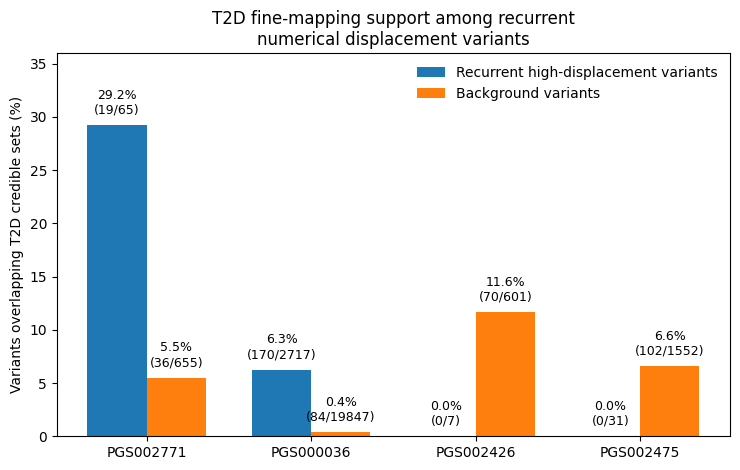

Saved:
/content/drive/MyDrive/prs_project_outputs/STS_2026/figures/Figure3B_Mahajan_enrichment.png


In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------
# Figure 3B: Mahajan credible-set overlap
# ------------------------------------

df = pd.DataFrame({
    "PGS": ["PGS002771", "PGS000036", "PGS002426", "PGS002475"],

    "driver_credible": [19, 170, 0, 0],
    "driver_total": [65, 2717, 7, 31],

    "bg_credible": [36, 84, 70, 102],
    "bg_total": [655, 19847, 601, 1552]
})

df["driver_fraction"] = df["driver_credible"] / df["driver_total"]
df["bg_fraction"] = df["bg_credible"] / df["bg_total"]

x = np.arange(len(df))
width = 0.36

fig, ax = plt.subplots(figsize=(7.5, 4.8))

bars1 = ax.bar(
    x - width/2,
    df["driver_fraction"] * 100,
    width,
    label="Recurrent high-displacement variants"
)

bars2 = ax.bar(
    x + width/2,
    df["bg_fraction"] * 100,
    width,
    label="Background variants"
)

# -----------------------------
# Labels
# -----------------------------
for i, row in df.iterrows():

    driver_y = row["driver_fraction"] * 100
    bg_y = row["bg_fraction"] * 100

    # Recurrent bar label
    ax.text(
        i - width/2,
        max(driver_y + 0.8, 0.8),
        f"{driver_y:.1f}%\n"
        f"({row['driver_credible']}/{row['driver_total']})",
        ha="center",
        va="bottom",
        fontsize=9
    )

    # Background bar label
    # Raise tiny PGS000036 value so it does not overlap neighboring bar
    if row["PGS"] == "PGS000036":
        label_y = 1.2
    else:
        label_y = bg_y + 0.8

    ax.text(
        i + width/2,
        label_y,
        f"{bg_y:.1f}%\n"
        f"({row['bg_credible']}/{row['bg_total']})",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax.set_xticks(x)
ax.set_xticklabels(df["PGS"])

ax.set_ylabel("Variants overlapping T2D credible sets (%)")
ax.set_xlabel("")

ax.set_title(
    "T2D fine-mapping support among recurrent\n"
    "numerical displacement variants"
)

ax.legend(frameon=False)

ax.set_ylim(0, 36)

plt.tight_layout()

OUT = "/content/drive/MyDrive/prs_project_outputs/STS_2026/figures/Figure3B_Mahajan_enrichment.png"

plt.savefig(
    OUT,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(OUT)

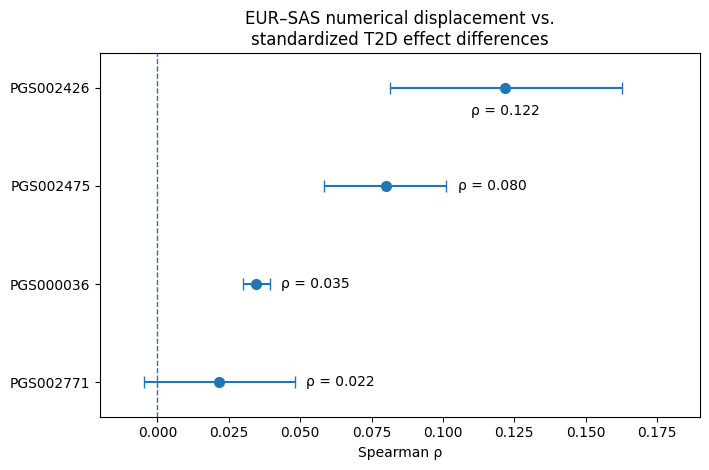

Saved:
/content/drive/MyDrive/prs_project_outputs/STS_2026/figures/Figure3A_cross_PGS_T2D.png


In [27]:
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------
# Figure 3A: Cross-PGS T2D
# -----------------------------

data = pd.DataFrame({
    "PGS": ["PGS002771", "PGS000036", "PGS002426", "PGS002475"],
    "rho": [0.021541, 0.034570, 0.121732, 0.079913],
    "ci_low": [-0.0046, 0.0299, 0.0813, 0.0584],
    "ci_high": [0.0481, 0.0393, 0.1628, 0.1012]
})

data = data.sort_values("rho", ascending=True).reset_index(drop=True)

y = range(len(data))

fig, ax = plt.subplots(figsize=(7.2, 4.8))

xerr = [
    data["rho"] - data["ci_low"],
    data["ci_high"] - data["rho"]
]

ax.errorbar(
    data["rho"],
    y,
    xerr=xerr,
    fmt="o",
    capsize=4,
    markersize=7,
    linewidth=1.5
)

ax.axvline(0, linestyle="--", linewidth=1)

ax.set_yticks(list(y))
ax.set_yticklabels(data["PGS"])

ax.set_xlabel("Spearman ρ")
ax.set_ylabel("")

ax.set_title(
    "EUR–SAS numerical displacement vs.\n"
    "standardized T2D effect differences"
)

ax.set_xlim(-0.02, 0.19)
ax.set_ylim(-0.35, 3.35)

# Labels
for i, row in data.iterrows():

    if row["PGS"] == "PGS002426":
        # Put label BELOW point so it does not overlap CI
        ax.text(
            row["rho"],
            i - 0.17,
            f"ρ = {row['rho']:.3f}",
            ha="center",
            va="top",
            fontsize=10
        )

    else:
        ax.text(
            row["ci_high"] + 0.004,
            i,
            f"ρ = {row['rho']:.3f}",
            ha="left",
            va="center",
            fontsize=10
        )

plt.tight_layout()

OUT = "/content/drive/MyDrive/prs_project_outputs/STS_2026/figures/Figure3A_cross_PGS_T2D.png"

plt.savefig(
    OUT,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(OUT)

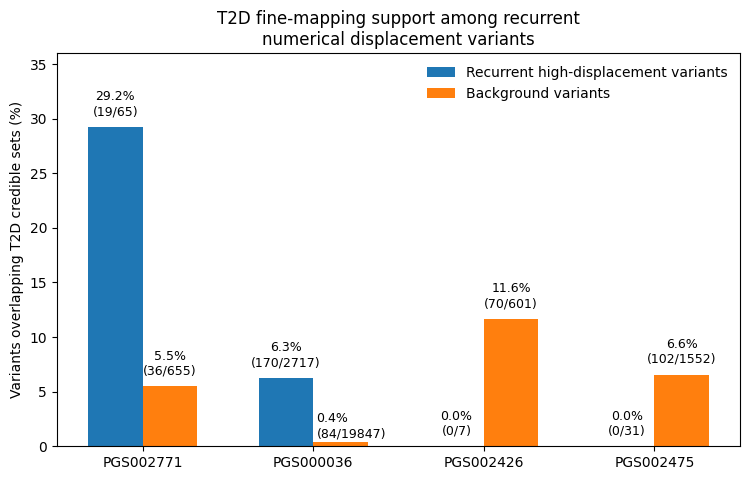

Saved:
/content/drive/MyDrive/prs_project_outputs/STS_2026/figures/Figure3B_Mahajan_enrichment.png


In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------
# Figure 3B: Mahajan credible-set overlap
# ------------------------------------

df = pd.DataFrame({
    "PGS": ["PGS002771", "PGS000036", "PGS002426", "PGS002475"],

    "driver_credible": [19, 170, 0, 0],
    "driver_total": [65, 2717, 7, 31],

    "bg_credible": [36, 84, 70, 102],
    "bg_total": [655, 19847, 601, 1552]
})

df["driver_pct"] = 100 * df["driver_credible"] / df["driver_total"]
df["bg_pct"] = 100 * df["bg_credible"] / df["bg_total"]

x = np.arange(len(df))
width = 0.32   # slightly narrower so there is a visible gap/crevice

fig, ax = plt.subplots(figsize=(7.6, 4.9))

bars1 = ax.bar(
    x - width/2,
    df["driver_pct"],
    width,
    label="Recurrent high-displacement variants"
)

bars2 = ax.bar(
    x + width/2,
    df["bg_pct"],
    width,
    label="Background variants"
)

for i, row in df.iterrows():

    driver_y = row["driver_pct"]
    bg_y = row["bg_pct"]

    # Blue bar labels
    ax.text(
        x[i] - width/2,
        driver_y + 0.8,
        f"{driver_y:.1f}%\n({row['driver_credible']}/{row['driver_total']})",
        ha="center",
        va="bottom",
        fontsize=9
    )

    # Orange bar labels
    if row["PGS"] == "PGS000036":
        # move the 0.4% label into the middle gap, not on the blue bar
        ax.text(
            x[i] + 0.02,
            0.55,
            f"{bg_y:.1f}%\n({row['bg_credible']}/{row['bg_total']})",
            ha="left",
            va="bottom",
            fontsize=9
        )
    else:
        ax.text(
            x[i] + width/2,
            bg_y + 0.8,
            f"{bg_y:.1f}%\n({row['bg_credible']}/{row['bg_total']})",
            ha="center",
            va="bottom",
            fontsize=9
        )

ax.set_xticks(x)
ax.set_xticklabels(df["PGS"])
ax.set_ylabel("Variants overlapping T2D credible sets (%)")
ax.set_title("T2D fine-mapping support among recurrent\nnumerical displacement variants")
ax.legend(frameon=False)
ax.set_ylim(0, 36)

plt.tight_layout()

OUT = "/content/drive/MyDrive/prs_project_outputs/STS_2026/figures/Figure3B_Mahajan_enrichment.png"

plt.savefig(
    OUT,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(OUT)

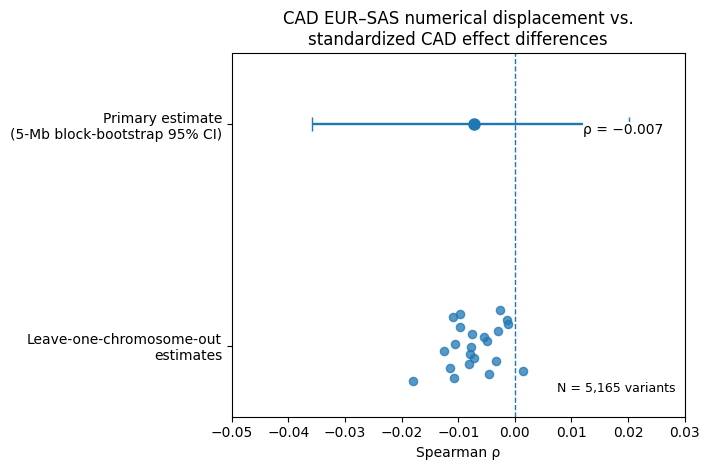

Saved:
/content/drive/MyDrive/prs_project_outputs/STS_2026/figures/Figure3C_CAD_replication.png


In [2]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------
# Figure 3C: CAD EUR–SAS replication
# ---------------------------------------

observed_rho = -0.0071348885
ci_low = -0.0358251891
ci_high = 0.0201742926

# Leave-one-chromosome-out rho values
loco = np.array([
    -0.017912,
    -0.010716,
    -0.004608,
     0.001493,
    -0.011519,
    -0.008078,
    -0.003366,
    -0.007226,
    -0.007890,
    -0.012595,
    -0.007751,
    -0.010657,
    -0.004966,
    -0.005513,
    -0.007629,
    -0.002957,
    -0.009714,
    -0.001291,
    -0.001386,
    -0.010911,
    -0.009653,
    -0.002586
])

fig, ax = plt.subplots(figsize=(7.2, 4.8))

# Zero reference line
ax.axvline(0, linestyle="--", linewidth=1)

# Primary estimate + 5-Mb block-bootstrap CI
ax.errorbar(
    observed_rho,
    1,
    xerr=[[observed_rho - ci_low], [ci_high - observed_rho]],
    fmt="o",
    capsize=5,
    markersize=8,
    linewidth=1.7
)

# Leave-one-chromosome-out estimates
jitter = np.linspace(-0.16, 0.16, len(loco))
ax.scatter(
    loco,
    np.zeros(len(loco)) + jitter,
    s=35,
    alpha=0.75
)

ax.set_yticks([0, 1])
ax.set_yticklabels([
    "Leave-one-chromosome-out\nestimates",
    "Primary estimate\n(5-Mb block-bootstrap 95% CI)"
])

ax.set_xlabel("Spearman ρ")
ax.set_title(
    "CAD EUR–SAS numerical displacement vs.\n"
    "standardized CAD effect differences"
)

# Fixed rho label: moved slightly down and protected from overlap
ax.text(
    0.012,
    0.975,
    "ρ = −0.007",
    ha="left",
    va="center",
    fontsize=10,
    bbox=dict(facecolor="white", edgecolor="none", pad=0.2)
)

# N label
ax.text(
    0.98,
    0.06,
    "N = 5,165 variants",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=9
)

ax.set_xlim(-0.05, 0.03)
ax.set_ylim(-0.32, 1.32)

plt.tight_layout()

OUT = "/content/drive/MyDrive/prs_project_outputs/STS_2026/figures/Figure3C_CAD_replication.png"

plt.savefig(
    OUT,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(OUT)

In [7]:
import pandas as pd

PATH = "/content/drive/MyDrive/last heave for g3/PGP_T2D_deduplicated_sensitivity.csv"

df = pd.read_csv(PATH)

print("Shape:", df.shape)
print("\nColumns:")
for col in df.columns:
    print(col)

print("\nFirst 5 rows:")
display(df.head())

Shape: (1, 10)

Columns:
N
cases
controls
dropped_participant
beta
OR_per_SD
CI_low
CI_high
p
AUC

First 5 rows:


,N,cases,controls,dropped_participant,beta,OR_per_SD,CI_low,CI_high,p,AUC
0,324,23,301,huE4DAE4,0.512446,1.66937,1.09888,2.536032,0.016307,0.625018


In [8]:
import os
import pandas as pd

BASE = "/content/drive/MyDrive/last heave for g3"

for root, dirs, files in os.walk(BASE):
    for f in files:
        if f.endswith(".csv"):
            path = os.path.join(root, f)
            try:
                temp = pd.read_csv(path)
                if len(temp) > 50:
                    print(f"{len(temp):4d} rows  |  {path}")
                    print("Columns:", list(temp.columns))
                    print("-" * 80)
            except:
                pass

2456 rows  |  /content/drive/MyDrive/last heave for g3/PGPTrait&DiseaseSurvey2012_Endocrine,Metabolic,Nutritional,AndImmunity-20181010220044.csv
Columns: ['Participant', 'Timestamp', 'Do not touch!', 'Have you ever been diagnosed with any of the following conditions?', 'Other condition not listed here?']
--------------------------------------------------------------------------------
 358 rows  |  /content/drive/MyDrive/last heave for g3/control_validation_progress.csv
Columns: ['Participant', 'Real_URL', 'Total_rows', 'Autosomal_rows', 'RSID_rows', 'PASS', 'Error']
--------------------------------------------------------------------------------
 339 rows  |  /content/drive/MyDrive/last heave for g3/passed_23andme_controls.csv
Columns: ['Participant', 'Real_URL', 'Total_rows', 'Autosomal_rows', 'RSID_rows', 'PASS', 'Error']
--------------------------------------------------------------------------------
 339 rows  |  /content/drive/MyDrive/last heave for g3/PGP_control_PGS002771_scores

Shape: (324, 5)

Phenotype counts:
phenotype
0    301
1     23
Name: count, dtype: int64

Controls: 301
Cases: 23
Control mean: 1.740947732967023e-16
Case mean: 0.5396498667188125
Mean difference: 0.5396498667188123


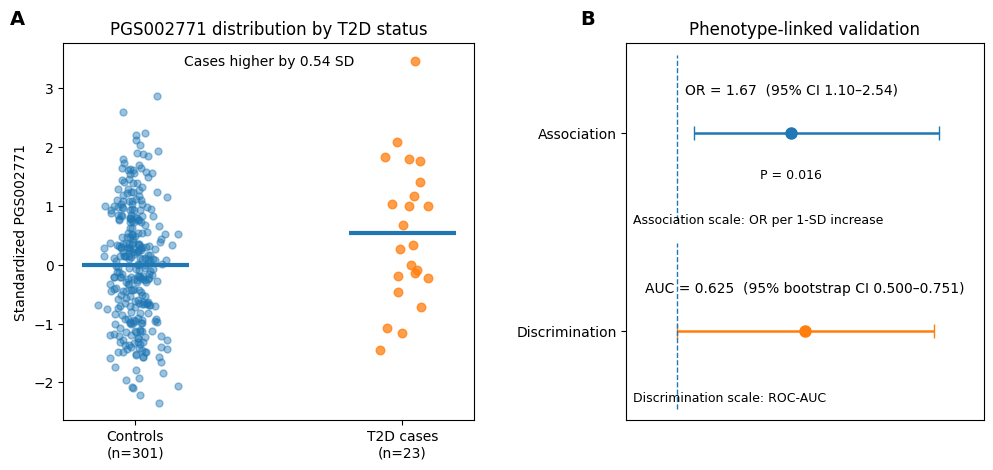


Saved:
/content/drive/MyDrive/prs_project_outputs/STS_2026/figures/Figure4_PGP_validation_FINAL.png


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Figure 4: Independent phenotype-linked validation of PGS002771
# ============================================================

DATA_PATH = (
    "/content/drive/MyDrive/last heave for g3/"
    "PGP_T2D_FINAL_DEDUPLICATED_324.csv"
)

df = pd.read_csv(DATA_PATH)

# ------------------------------------------------------------
# Sanity checks
# ------------------------------------------------------------

print("Shape:", df.shape)
print("\nPhenotype counts:")
print(df["phenotype"].value_counts().sort_index())

controls = df.loc[df["phenotype"] == 0, "PRS_z_final"].dropna()
cases = df.loc[df["phenotype"] == 1, "PRS_z_final"].dropna()

print("\nControls:", len(controls))
print("Cases:", len(cases))
print("Control mean:", controls.mean())
print("Case mean:", cases.mean())
print("Mean difference:", cases.mean() - controls.mean())

# Frozen final validation results
OR = 1.66937
OR_LOW = 1.09888
OR_HIGH = 2.536032
P_VALUE = 0.016307

AUC = 0.625018
AUC_LOW = 0.500
AUC_HIGH = 0.751

# ============================================================
# Create figure
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(10, 4.8),
    gridspec_kw={"width_ratios": [1.15, 1]}
)

# ============================================================
# PANEL A — Actual participant-level PRS distributions
# ============================================================

ax = axes[0]

rng = np.random.default_rng(42)

x_controls = rng.normal(0, 0.055, len(controls))
x_cases = rng.normal(1, 0.055, len(cases))

# Individual participants
ax.scatter(
    x_controls,
    controls,
    s=25,
    alpha=0.45
)

ax.scatter(
    x_cases,
    cases,
    s=38,
    alpha=0.75
)

# Means
ax.hlines(
    controls.mean(),
    -0.20,
    0.20,
    linewidth=3
)

ax.hlines(
    cases.mean(),
    0.80,
    1.20,
    linewidth=3
)

ax.set_xticks([0, 1])
ax.set_xticklabels([
    f"Controls\n(n={len(controls)})",
    f"T2D cases\n(n={len(cases)})"
])

ax.set_ylabel("Standardized PGS002771")
ax.set_xlabel("")

ax.set_title(
    "PGS002771 distribution by T2D status"
)

# Put mean-difference label in a real anchored location
ax.text(
    0.5,
    0.97,
    f"Cases higher by {cases.mean() - controls.mean():.2f} SD",
    transform=ax.transAxes,
    ha="center",
    va="top",
    fontsize=10
)

ax.text(
    -0.13,
    1.05,
    "A",
    transform=ax.transAxes,
    fontsize=14,
    fontweight="bold"
)

# ============================================================
# PANEL B — Compact validation summary
# ============================================================

ax = axes[1]

# -------------------------
# OR row
# -------------------------

y_or = 1

ax.axvline(
    1,
    ymin=0.53,
    ymax=0.97,
    linestyle="--",
    linewidth=1
)

ax.errorbar(
    OR,
    y_or,
    xerr=[
        [OR - OR_LOW],
        [OR_HIGH - OR]
    ],
    fmt="o",
    capsize=5,
    markersize=8,
    linewidth=1.8
)

ax.text(
    OR,
    y_or + 0.18,
    "OR = 1.67  (95% CI 1.10–2.54)",
    ha="center",
    va="bottom",
    fontsize=10
)

ax.text(
    OR,
    y_or - 0.18,
    "P = 0.016",
    ha="center",
    va="top",
    fontsize=9
)

# -------------------------
# AUC row
# Rescale AUC visually onto same plotting canvas
# -------------------------

# Map 0.45–0.80 AUC range into OR-axis visual region 0.7–2.8
def auc_to_x(v):
    return 0.7 + ((v - 0.45) / (0.80 - 0.45)) * (2.8 - 0.7)

auc_x = auc_to_x(AUC)
auc_low_x = auc_to_x(AUC_LOW)
auc_high_x = auc_to_x(AUC_HIGH)

y_auc = 0

ax.errorbar(
    auc_x,
    y_auc,
    xerr=[
        [auc_x - auc_low_x],
        [auc_high_x - auc_x]
    ],
    fmt="o",
    capsize=5,
    markersize=8,
    linewidth=1.8
)

ax.axvline(
    auc_to_x(0.5),
    ymin=0.03,
    ymax=0.47,
    linestyle="--",
    linewidth=1
)

ax.text(
    auc_x,
    y_auc + 0.18,
    "AUC = 0.625  (95% bootstrap CI 0.500–0.751)",
    ha="center",
    va="bottom",
    fontsize=10
)

# Row labels
ax.set_yticks([0, 1])
ax.set_yticklabels([
    "Discrimination",
    "Association"
])

# Remove misleading numeric x tick labels because rows use different scales
ax.set_xticks([])

ax.set_xlim(0.7, 2.8)
ax.set_ylim(-0.45, 1.45)

ax.set_title(
    "Phenotype-linked validation"
)

# Explicit scales underneath each row
ax.text(
    0.02,
    0.53,
    "Association scale: OR per 1-SD increase",
    transform=ax.transAxes,
    ha="left",
    va="center",
    fontsize=9
)

ax.text(
    0.02,
    0.04,
    "Discrimination scale: ROC-AUC",
    transform=ax.transAxes,
    ha="left",
    va="bottom",
    fontsize=9
)

ax.text(
    -0.13,
    1.05,
    "B",
    transform=ax.transAxes,
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout(w_pad=3)

OUT = (
    "/content/drive/MyDrive/prs_project_outputs/STS_2026/figures/"
    "Figure4_PGP_validation_FINAL.png"
)

plt.savefig(
    OUT,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:")
print(OUT)

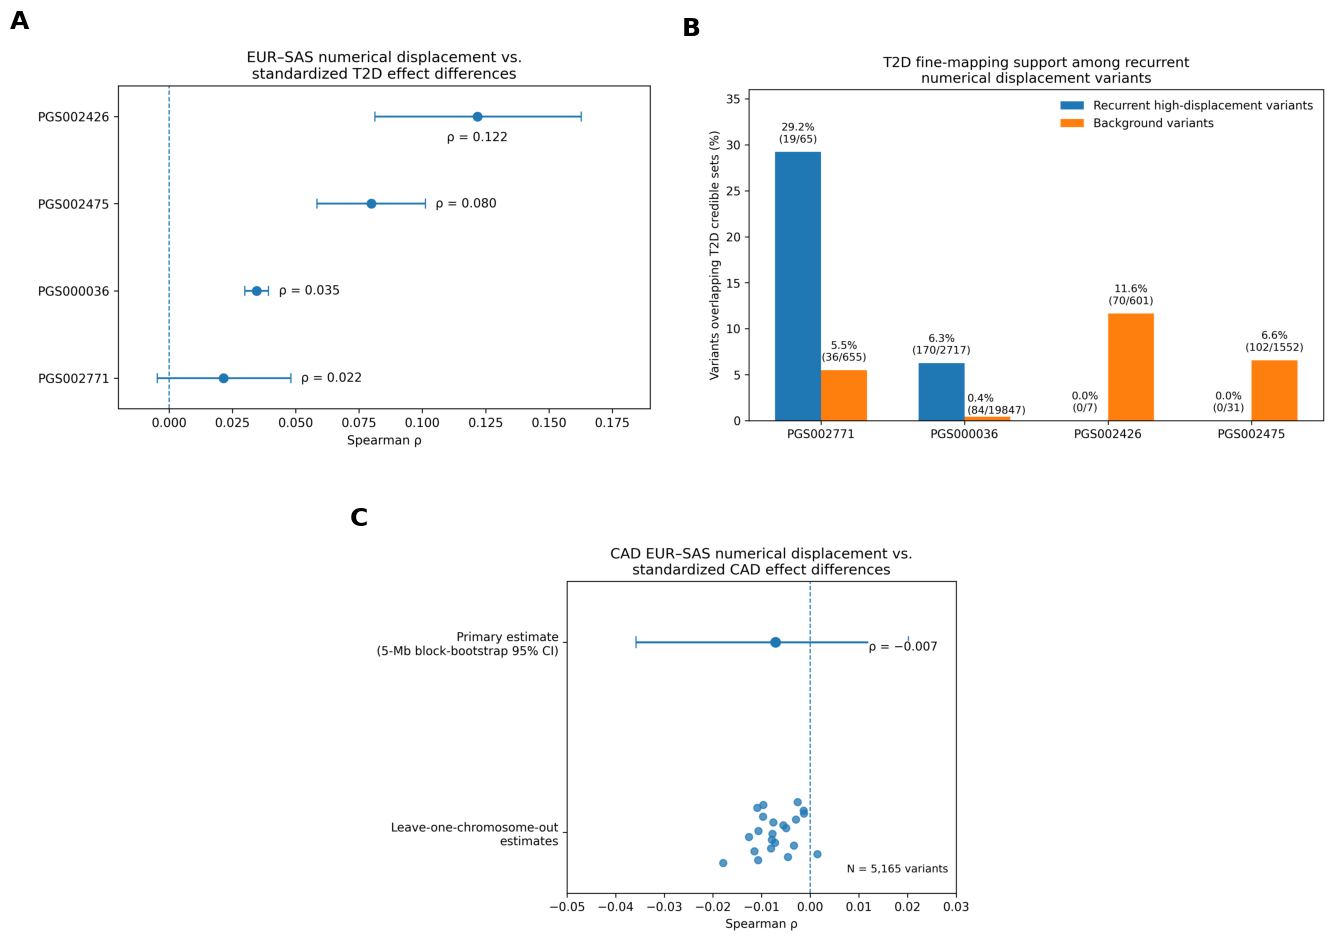

Saved:
/content/drive/MyDrive/prs_project_outputs/STS_2026/figures/Figure3_cross_score_cross_disease_FINAL.png


In [10]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# ============================================================
# Combine Figure 3A + 3B + 3C into final Figure 3
# ============================================================

PATH_A = "/content/drive/MyDrive/prs_project_outputs/STS_2026/figures/Figure3A_cross_PGS_T2D.png"
PATH_B = "/content/drive/MyDrive/prs_project_outputs/STS_2026/figures/Figure3B_Mahajan_enrichment.png"
PATH_C = "/content/drive/MyDrive/prs_project_outputs/STS_2026/figures/Figure3C_CAD_replication.png"

imgA = mpimg.imread(PATH_A)
imgB = mpimg.imread(PATH_B)
imgC = mpimg.imread(PATH_C)

fig = plt.figure(figsize=(14, 10))

# Layout:
# A and B side-by-side on top
# C centered across the bottom

axA = fig.add_axes([0.04, 0.53, 0.45, 0.42])
axB = fig.add_axes([0.52, 0.53, 0.45, 0.42])
axC = fig.add_axes([0.20, 0.05, 0.60, 0.40])

axA.imshow(imgA)
axB.imshow(imgB)
axC.imshow(imgC)

for ax in [axA, axB, axC]:
    ax.axis("off")

# Panel labels
axA.text(
    -0.03, 1.02, "A",
    transform=axA.transAxes,
    fontsize=18,
    fontweight="bold",
    va="bottom"
)

axB.text(
    -0.03, 1.02, "B",
    transform=axB.transAxes,
    fontsize=18,
    fontweight="bold",
    va="bottom"
)

axC.text(
    -0.03, 1.02, "C",
    transform=axC.transAxes,
    fontsize=18,
    fontweight="bold",
    va="bottom"
)

OUT = "/content/drive/MyDrive/prs_project_outputs/STS_2026/figures/Figure3_cross_score_cross_disease_FINAL.png"

plt.savefig(
    OUT,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(OUT)

In [2]:
from pathlib import Path

root = Path("/content/drive/MyDrive")

keywords = [
    "PGS004198",
    "CAD",
    "block",
    "bootstrap",
    "LOCO",
    "coronary"
]

matches = []

for p in root.rglob("*"):
    if p.is_file():
        name = p.name.lower()
        if any(k.lower() in name for k in keywords):
            matches.append(str(p))

for m in sorted(matches):
    print(m)

/content/drive/MyDrive/elder_fraud_data/frozen_analysis_2026_08_14/models/censored_nb_county_bootstrap_all.csv
/content/drive/MyDrive/elder_fraud_data/frozen_analysis_2026_08_14/models/censored_nb_county_bootstrap_ci.csv
/content/drive/MyDrive/elder_fraud_data/outputs/censored_nb_county_bootstrap_all.csv
/content/drive/MyDrive/elder_fraud_data/outputs/censored_nb_county_bootstrap_ci.csv
/content/drive/MyDrive/last heave for g3/PGP_T2D_FINAL_bootstrap_distribution.csv
/content/drive/MyDrive/last heave for g3/PGP_T2D_OR_bootstrap_audit.csv
/content/drive/MyDrive/prs_project_outputs/CADD_results_5622.tsv.gz
/content/drive/MyDrive/prs_project_outputs/CAD_replication/CAD_REPLICATION_ANALYSIS_FREEZE.csv
/content/drive/MyDrive/prs_project_outputs/CAD_replication/PGS004198.txt.gz
/content/drive/MyDrive/prs_project_outputs/CAD_replication/PGS004198_1000G_EUR_SAS_AF.csv
/content/drive/MyDrive/prs_project_outputs/CAD_replication/PGS004198_Aragam2022_EUR_CAD_effects.csv
/content/drive/MyDrive/prs_

In [3]:
import pandas as pd
from pathlib import Path

files = [
    "/content/drive/MyDrive/prs_project_outputs/CAD_replication/CAD_REPLICATION_ANALYSIS_FREEZE.csv",
    "/content/drive/MyDrive/prs_project_outputs/CAD_replication/PGS004198_CAD_EUR_SAS_FINAL_ANALYSIS.csv",
]

for f in files:
    print("\n" + "="*100)
    print(Path(f).name)
    print("="*100)

    df = pd.read_csv(f)

    print("Shape:", df.shape)
    print("\nColumns:")
    print(df.columns.tolist())

    print("\nFirst rows:")
    display(df.head())


CAD_REPLICATION_ANALYSIS_FREEZE.csv
Shape: (1, 15)

Columns:
['disease', 'PRS', 'comparison', 'n_snps', 'primary_rho', 'primary_p', 'block_bootstrap_mean_rho', 'block_bootstrap_CI_low', 'block_bootstrap_CI_high', 'LOCO_rho_min', 'LOCO_rho_max', 'raw_beta_rho', 'raw_beta_p', 'EUR_GWAS', 'SAS_GWAS']

First rows:


,disease,PRS,comparison,n_snps,primary_rho,primary_p,block_bootstrap_mean_rho,block_bootstrap_CI_low,block_bootstrap_CI_high,LOCO_rho_min,LOCO_rho_max,raw_beta_rho,raw_beta_p,EUR_GWAS,SAS_GWAS
0,CAD,PGS004198,EUR_vs_SAS,5165,-0.007135,0.608195,-0.007714,-0.035825,0.020174,-0.017912,0.001493,-0.114348,1.679405e-16,Aragam 2022 CARDIoGRAMplusC4D,Genes & Health GNH0002 narrow CAD



PGS004198_CAD_EUR_SAS_FINAL_ANALYSIS.csv
Shape: (5565, 7)

Columns:
['rsID', 'abs_delta_numerical_SAS_EUR', 'SAS_beta_aligned', 'SAS_SE', 'EUR_beta_aligned', 'EUR_SE', 'abs_z_diff']

First rows:


,rsID,abs_delta_numerical_SAS_EUR,SAS_beta_aligned,SAS_SE,EUR_beta_aligned,EUR_SE,abs_z_diff
0,rs74045142,0.000023,-0.029362,0.048277,-0.023992,0.018439,0.103921
1,rs7796,0.000229,-0.007777,0.028871,-0.002229,0.008608,0.184159
2,rs4648807,0.000051,0.019516,0.027687,0.016291,0.008859,0.110929
3,rs16824937,0.000008,0.001719,0.053135,-0.031565,0.021877,0.579226
4,rs2843151,0.000687,-0.033019,0.027842,-0.031267,0.012097,0.057740


In [4]:
import pandas as pd

f = "/content/drive/MyDrive/prs_project_outputs/CAD_replication/PGS004198_CAD_EUR_SAS_FINAL_ANALYSIS.csv"

df = pd.read_csv(f)

cols_needed = [
    "abs_delta_numerical_SAS_EUR",
    "SAS_beta_aligned",
    "SAS_SE",
    "EUR_beta_aligned",
    "EUR_SE",
    "abs_z_diff"
]

print("Total rows:", len(df))
print("\nMissing values:")
print(df[cols_needed].isna().sum())

complete = df.dropna(subset=cols_needed)

print("\nComplete-case rows:", len(complete))

print("\nRows with non-finite values:")
import numpy as np
for c in cols_needed:
    print(c, (~np.isfinite(df[c])).sum())

Total rows: 5565

Missing values:
abs_delta_numerical_SAS_EUR    0
SAS_beta_aligned               0
SAS_SE                         0
EUR_beta_aligned               0
EUR_SE                         0
abs_z_diff                     0
dtype: int64

Complete-case rows: 5565

Rows with non-finite values:
abs_delta_numerical_SAS_EUR 0
SAS_beta_aligned 0
SAS_SE 0
EUR_beta_aligned 0
EUR_SE 0
abs_z_diff 0


In [5]:
import pandas as pd
from pathlib import Path

files = [
    "/content/drive/MyDrive/prs_project_outputs/CAD_replication/PGS004198_CAD_EUR_SAS_CLEAN_FINAL.csv",
    "/content/drive/MyDrive/prs_project_outputs/CAD_replication/PGS004198_CAD_Aragam_EUR_SAS_FINAL.csv",
    "/content/drive/MyDrive/prs_project_outputs/CAD_replication/PGS004198_CAD_numerical_EUR_SAS_FINAL.csv",
    "/content/drive/MyDrive/prs_project_outputs/CAD_replication/PGS004198_SAS_CAD_effects_CLEAN_FINAL.csv",
]

for f in files:
    print("\n" + "="*100)
    print(Path(f).name)

    df = pd.read_csv(f)

    print("Shape:", df.shape)
    print("Columns:")
    print(df.columns.tolist())


PGS004198_CAD_EUR_SAS_CLEAN_FINAL.csv
Shape: (5165, 7)
Columns:
['rsID', 'abs_delta_numerical_SAS_EUR', 'SAS_beta_aligned', 'SAS_SE', 'EUR_beta_aligned', 'EUR_SE', 'abs_z_diff']

PGS004198_CAD_Aragam_EUR_SAS_FINAL.csv
Shape: (5165, 8)
Columns:
['rsID', 'abs_delta_numerical_SAS_EUR', 'SAS_beta_aligned', 'SAS_SE', 'EUR_beta_aligned', 'EUR_SE', 'abs_z_diff', 'abs_beta_diff']

PGS004198_CAD_numerical_EUR_SAS_FINAL.csv
Shape: (5547, 11)
Columns:
['rsID', 'chr_name', 'chr_position', 'effect_allele', 'other_allele', 'effect_weight', 'EUR_effect_AF', 'SAS_effect_AF', 'delta_AF_SAS_EUR', 'delta_numerical_SAS_EUR', 'abs_delta_numerical_SAS_EUR']

PGS004198_SAS_CAD_effects_CLEAN_FINAL.csv
Shape: (5165, 26)
Columns:
['rsID', 'chr37', 'pos37', 'effect_allele', 'other_allele', 'chr38', 'pos38', 'strand38', 'allele_string38', 'CHROM', 'GENPOS', 'ID', 'ALLELE0', 'ALLELE1', 'A1FREQ', 'N', 'TEST', 'BETA', 'SE', 'CHISQ', 'LOG10P', 'EXTRA', 'SAS_beta_aligned', 'alignment', 'FinnGen_ref', 'FinnGen_alt']


In [6]:
from pathlib import Path

root = Path("/content/drive/MyDrive")

matches = []

for p in root.rglob("*"):
    if p.is_file() and p.suffix.lower() in [".ipynb", ".py"]:
        name = p.name.lower()
        if any(k in name for k in [
            "cad",
            "pgs004198",
            "coronary",
            "replication"
        ]):
            matches.append(str(p))

for m in sorted(matches):
    print(m)

/content/drive/MyDrive/Colab Notebooks/T2D_PRS_REPLICATION_PGS000036.ipynb


In [7]:
from pathlib import Path
import json

root = Path("/content/drive/MyDrive")

keywords = [
    "CAD_REPLICATION_ANALYSIS_FREEZE",
    "PGS004198_CAD_Aragam_EUR_SAS_FINAL",
    "Figure3C_CAD_replication",
    "block_bootstrap_CI_low",
    "5165"
]

hits = []

for p in root.rglob("*.ipynb"):
    try:
        with open(p, "r", encoding="utf-8", errors="ignore") as f:
            nb = json.load(f)

        text = ""
        for cell in nb.get("cells", []):
            text += "".join(cell.get("source", []))

        matched = [k for k in keywords if k in text]

        if matched:
            hits.append((str(p), matched))

    except Exception:
        pass

for path, matched in hits:
    print("\n" + "="*100)
    print(path)
    print("Matched:", matched)


/content/drive/MyDrive/Colab Notebooks/finemapping.ipynb
Matched: ['CAD_REPLICATION_ANALYSIS_FREEZE', 'PGS004198_CAD_Aragam_EUR_SAS_FINAL', 'Figure3C_CAD_replication', 'block_bootstrap_CI_low', '5165']
